# Chapter 03C - How do a reader and writer learn to work together?

[03B](03B-counts-to-recurrent-language-models.ipynb) let one running state continue a word stream.
Now keep **the cat sat on the mat**, but ask for a separate answer:
**mat the on sat cat the**, then `<eos>`.
Reversing words is a deliberately checkable reading/writing drill, not natural English or translation.

You should leave able to follow what the reader produces, what starts the writer, which
previous word the writer receives, and how an answer's error teaches both components.
Only after that will we ask whether the writer should be allowed to reopen source positions.

**Code-only view:** [Python companion](03C-recurrent-encoder-decoder-to-attention.py).
**Notes:** [Handwritten companion](03C-recurrent-encoder-decoder-to-attention-theory.md).

**Two code routes:** stay here for a compact encoder-decoder in four code cells.
Open the [worked-details notebook](03C1-encoder-decoder-worked-details.ipynb) for every diagnostic and the
original attention comparison. No explanation has been removed from this main route.


## The questions we need to answer

An **encoder** does the reading job; a **decoder** does the writing job.
Those names tell you their roles, not which kind of neural layer they must use.
Here both use recurrent machinery you already understand from the memory chapter.

| Question | What we will inspect |
|---|---|
| Why isn't the decoder just another encoder? | Different inputs, responsibilities and learned weight sets |
| What crosses their boundary? | A computed state vector, not a word or copied weights |
| What does teacher forcing actually force? | The next input, not the current guess |
| How does the reader learn without predicting an answer itself? | The writer's error travels back across the handoff |
| Does backward already train the weights? | Compare backward alone with one optimizer step |
| What does attention change? | Which reader states the writer may consult at each step |

All state is rebuilt here. No checkpoint or download is needed.
Here we train one small encoder-decoder on a frozen set of varied cat-family word orders.
The worked-details route first inspects an initialized model, then trains the original two
bounded comparisons. Its initialized probe demonstrates wiring and feedback, not language skill.


## 1. Reading and writing are different jobs

Suppose you must reverse the cat sentence. You cannot write its first answer, `mat`,
until you know how the source ends. So first **read the source**, then **write the answer**.

| Part | What arrives | What it produces |
|---|---|---|
| Shared word table | Word IDs | Trainable word features |
| Encoder / reader | Source features in source order | Contextual notes, including a final summary |
| Decoder / writer | Source context and a previous answer input | An updated writing state |
| Prediction head | The writing state | Scores for possible next answer words |

The encoder processes `the`, `cat`, `sat`, `on`, `the`, `mat`. It does not select an answer word
after every source word in this task. Its useful output is context for the writer.
The decoder starts a **different sequence** and must choose `mat`, then `the`, and so on.

They can use the same GRU update idea while learning **different weights**:
the reader learns what source information to retain; the writer learns how to use it while writing.
One word table is shared here, but the reader GRU, writer GRU and prediction head have their own parameters.

### Who tells the encoder what a good encoding looks like?

**Nobody supplies a correct encoding. We supply the correct answer.**
Think of the encoder writing a note for the decoder. At first, neither has learned
a useful way to communicate. We grade the answer they produce together, not the note itself.
A useful note is one the decoder can use to do the requested job.

In the one-card model, consider these two lessons:

| Source read by encoder | First decoder input | Required first answer |
|---|---|---|
| the cat sat on the mat | `<bos>` | mat |
| the cat sat on the rug | `<bos>` | rug |

If the encoder sends **exactly the same note** for both, the decoder gets the same
note and the same `<bos>` input. It must produce the same scores for two different
required answers. No clever decoder can recover a distinction the note has removed.
Different notes are necessary here, though merely being different is not enough.

Training makes that complaint actionable:

1. Read the source and compute a note with the current encoder weights.
2. Let the decoder use it and score an answer. Suppose it gives `mat` too little probability.
3. Backpropagation asks which small changes to the note would lower that answer's error,
   **through the decoder as it currently works**. It does not hand over a target note.
4. Continue that feedback through the source reads to the encoder weights that produced the note.
5. Update the weights and read again. The encoder now computes a changed note; in ordinary
   training, the decoder's weights also improve how it uses notes.

So the encoder and decoder learn a way to communicate **together**. We do not decide that
coordinate 7 must mean 'last word'. Many numerical representations could work.
For reversal, the useful distinctions include word identity and order; another task
could reward different details. The encoding is useful **for its task and decoder**,
not an automatically perfect description of the input.
Section 4.5 isolates this: keep the decoder fixed and let only the encoder improve its note.

**Read the picture as a handoff, not a word lookup:** the reader's final computed note crosses
to the writer. That note is not the literal word `mat`, the source sentence, or a copied set of weights.

![The reader processes all six source words, then its final learned summary initializes a separate writer.](images/03-evo-04-one-card-bottleneck.png)

Both states have 64 numbers in this model, so the reader's final state can become the writer's
initial state. Matching widths makes that handoff possible; it does not make their jobs or weights identical.
After writing starts, the writer changes its own state. It does not run the source reader again at every word.

**Run the isolation:** [encoder-only proof with an unchanged decoder](03C1-encoder-decoder-worked-details.ipynb#encoder-only).


## 2. Teacher forcing keeps the training example on track

When a decoder writes word by word, each new prediction depends on the earlier words
supplied to it. During generation, those words are its own guesses. Early in training,
the guesses are unreliable. Feed a wrong guess into the next step, and one mistake
can send the rest of the answer off track.

Think of a student misreading step 1 of a maths problem, then being marked wrong on
steps 2 through 7 while following that mistaken start. We want to teach each step of
the intended solution, not only practise the consequences of the first mistake.

**Teacher forcing separates grading from choosing the next input:**

1. **Grade the model's actual prediction.** Given `<bos>` and source context, the first
   target is `mat`. If the highest-scoring guess is `cat`, grade those scores against
   `mat` normally. Do not rewrite the prediction or erase its error.
2. **Feed the true previous word into the next step.** Instead of passing the guessed
   `cat` forward, supply `mat`, the previous word from the correct answer.
   This keeps the next practice question on its intended path.

The teacher is the known training answer, not another model whispering the next word.
The writer keeps its computed state; supplying `mat` does not reset that state or update weights.

| Step | Input fed to decoder | Target word graded |
|---|---|---|
| 1 | `<bos>` | `mat` |
| 2 | `mat` | `the` |
| 3 | `the` | `on` |
| 4 | `on` | `sat` |
| 5 | `sat` | `cat` |
| 6 | `cat` | `the` |
| 7 | `the` | `<eos>` |

Notice two things:

- **No cheating on the current word.** The target is one step ahead of the input.
  The decoder's answer inputs contain only earlier target words, never the current
  target or later ones. The encoder may read the entire known source, including `mat`;
  source context is allowed and is different from leaking the current answer input.
- **Target length drives practice.** Reversal happens to need six words plus `<eos>`.
  Translation or summarization can produce a shorter or longer answer than the source.
  The supplied target sequence determines how many writing steps we train.

Every position gets its intended previous-word input, so it remains a useful practice
question even when an earlier prediction was wrong. This chapter's GRU still computes
states sequentially: teacher forcing changes the supplied words, not that dependency.


### Follow one real example, at your own pace

Start with **Before learning: teacher forcing**. Watch six source words enter the encoder, the final note cross to the decoder, and each actual guess get graded. Then watch the teacher supply the correct previous word for the **next** step, without erasing the guess.

Use **Next stage / Back**, or choose **Play slowly**. The player starts paused. Switch to **Same weights: own guesses** to isolate what generation changes, or to **After corpus training** to see the learned model's actual continuation.

<iframe title="Recorded encoder-decoder and teacher-forcing walkthrough" sandbox="allow-scripts" srcdoc="&lt;!doctype html&gt;&#10;&lt;html lang=&quot;en&quot;&gt;&lt;head&gt;&lt;meta charset=&quot;utf-8&quot;&gt;&lt;meta name=&quot;viewport&quot; content=&quot;width=device-width,initial-scale=1&quot;&gt;&#10;&lt;title&gt;Encoder, decoder and teacher: follow one real example&lt;/title&gt;&#10;&lt;style&gt;&#10;*{box-sizing:border-box}body{margin:0;background:#fff9ed;color:#17324d;font:16px/1.5 system-ui,sans-serif}&#10;main{max-width:1536px;margin:auto}nav{position:sticky;top:0;z-index:2;background:#fffdf7;padding:12px;border-bottom:1px solid #d5c8ae}&#10;button,select{font:inherit;border:1px solid #667d8c;border-radius:7px;background:white;color:#17324d;padding:7px 12px;cursor:pointer}&#10;button:disabled{opacity:.45;cursor:default}button:focus-visible,select:focus-visible{outline:3px solid #7950a3;outline-offset:2px}&#10;.row{display:flex;gap:8px;align-items:center;flex-wrap:wrap}p{margin:5px 0}&#10;#status{color:#007f86;font-weight:650}#caption{font-size:18px;min-height:84px;padding:12px 18px;background:#fffdf7}&#10;svg{width:100%;height:auto;display:block}.panel{fill:#fffdf7;fill-opacity:.97;stroke-width:3}&#10;text{font-family:system-ui,sans-serif;fill:#17324d}.label{font-size:25px;font-weight:650}.value{font-size:24px}.small{font-size:20px}&#10;.route{fill:none;stroke-width:5;opacity:.22}.route.active{opacity:1;stroke-width:7;stroke-dasharray:12 8}&#10;main[data-playing=true] .route.active{animation:flow 1.8s linear infinite}&#10;.chip{fill:#fffdf7;stroke:#007f86;stroke-width:2}.chip.active{fill:#ddf4ef;stroke-width:4}&#10;#details{padding:10px 18px;background:#fffdf7}.note{font-size:14px;color:#596b72}&#10;@keyframes flow{to{stroke-dashoffset:-40}}&#10;@media(prefers-reduced-motion:reduce){main[data-playing=true] .route.active{animation:none}}&#10;&lt;/style&gt;&lt;/head&gt;&lt;body&gt;&#10;&lt;main data-player=&quot;encoder-decoder-teacher&quot; data-playing=&quot;false&quot;&gt;&#10;&lt;nav aria-label=&quot;Recorded encoder-decoder walkthrough&quot;&gt;&#10;&lt;div class=&quot;row&quot;&gt;&lt;button id=&quot;back&quot; type=&quot;button&quot; disabled&gt;Back&lt;/button&gt;&lt;button id=&quot;next&quot; type=&quot;button&quot;&gt;Next stage&lt;/button&gt;&#10;&lt;button id=&quot;play&quot; type=&quot;button&quot; aria-pressed=&quot;false&quot;&gt;Play slowly&lt;/button&gt;&lt;button id=&quot;reset&quot; type=&quot;button&quot;&gt;Reset&lt;/button&gt;&#10;&lt;label&gt;Recording &lt;select id=&quot;run&quot;&gt;&lt;option value=&quot;practice&quot;&gt;Before learning: teacher forcing&lt;/option&gt;&#10;&lt;option value=&quot;generation&quot;&gt;Same weights: own guesses&lt;/option&gt;&lt;option value=&quot;trained&quot;&gt;After corpus training: own guesses&lt;/option&gt;&lt;/select&gt;&lt;/label&gt;&#10;&lt;label&gt;Pace &lt;select id=&quot;pace&quot;&gt;&lt;option value=&quot;3000&quot;&gt;3 seconds / stage&lt;/option&gt;&lt;option value=&quot;5000&quot;&gt;5 seconds / stage&lt;/option&gt;&lt;/select&gt;&lt;/label&gt;&lt;/div&gt;&#10;&lt;p id=&quot;status&quot; role=&quot;status&quot;&gt;&lt;/p&gt;&lt;p class=&quot;note&quot;&gt;Starts paused. Use Next/Back or arrow keys. No live model or network call runs during playback.&lt;/p&gt;&#10;&lt;/nav&gt;&#10;&lt;svg viewBox=&quot;0 0 1536 720&quot; role=&quot;img&quot; aria-labelledby=&quot;diagram-title diagram-description&quot;&gt;&#10;&lt;title id=&quot;diagram-title&quot;&gt;One source read, a learned state handoff, separate writing and teacher inputs&lt;/title&gt;&#10;&lt;desc id=&quot;diagram-description&quot;&gt;MAI artwork supplies only the background. Every source word, guess, state and teaching signal is overlaid from actual PyTorch records.&lt;/desc&gt;&#10;&lt;image href=&quot;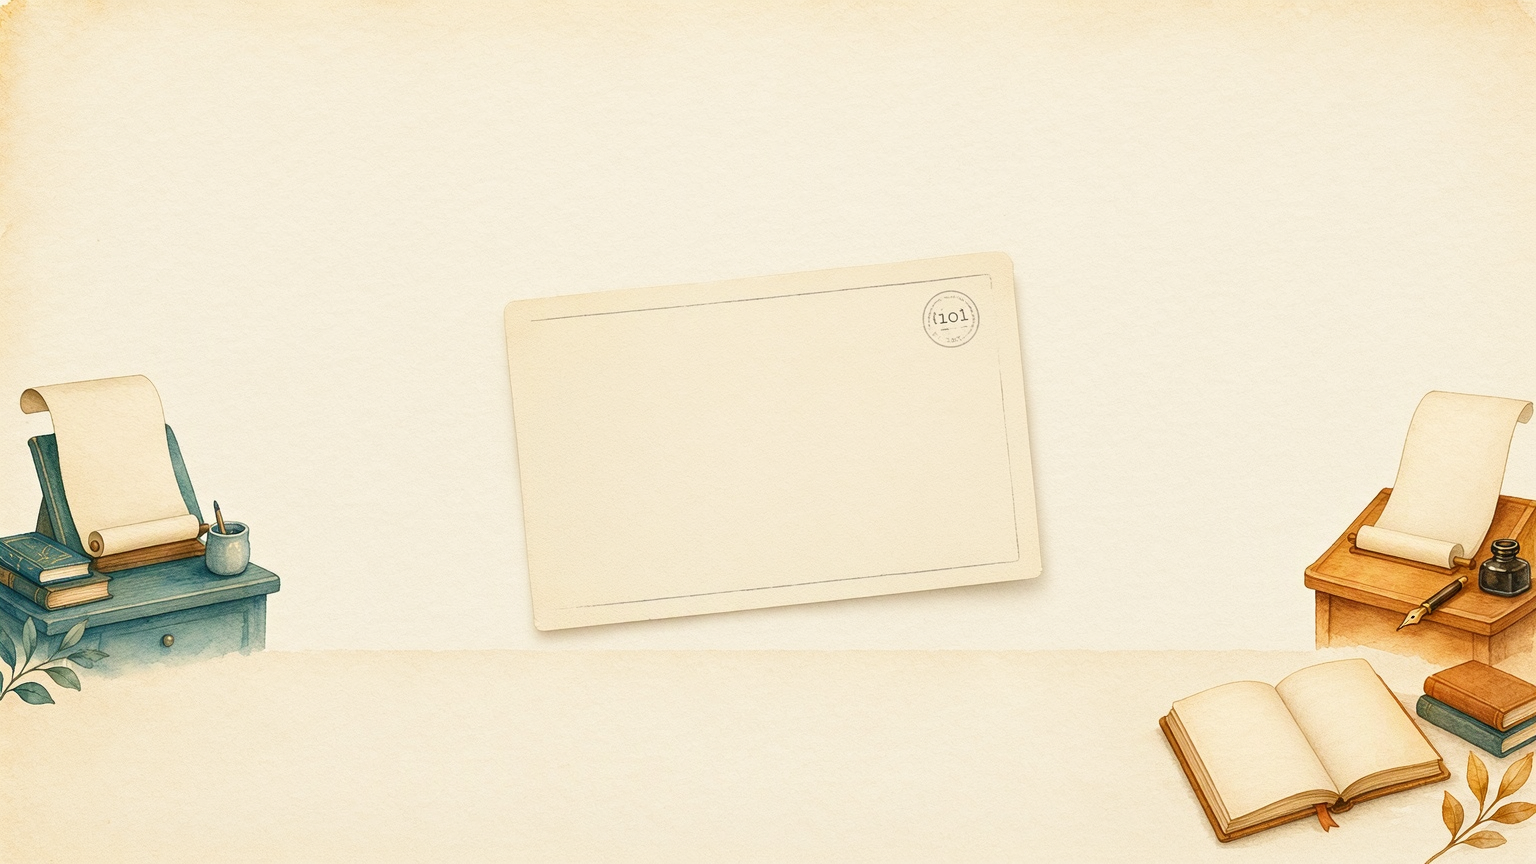&quot; x=&quot;0&quot; y=&quot;0&quot; width=&quot;1536&quot; height=&quot;864&quot;/&gt;&#10;&lt;rect x=&quot;930&quot; y=&quot;300&quot; width=&quot;55&quot; height=&quot;75&quot; fill=&quot;#fffdf7&quot;/&gt;&#10;&lt;rect x=&quot;38&quot; y=&quot;15&quot; width=&quot;1460&quot; height=&quot;85&quot; rx=&quot;14&quot; class=&quot;panel&quot; stroke=&quot;#d7c6a9&quot;/&gt;&#10;&lt;text id=&quot;stage-title&quot; x=&quot;64&quot; y=&quot;49&quot; class=&quot;label&quot;&gt;&lt;/text&gt;&lt;text x=&quot;64&quot; y=&quot;83&quot; class=&quot;small&quot;&gt;Read first. Carry context. Write one answer word. Grade it before choosing the NEXT input.&lt;/text&gt;&#10;&lt;g id=&quot;source-chips&quot;&gt;&lt;/g&gt;&#10;&lt;path id=&quot;route-read&quot; class=&quot;route&quot; stroke=&quot;#007f86&quot; d=&quot;M470 210 V248 H308 V272&quot;/&gt;&#10;&lt;path id=&quot;route-handoff&quot; class=&quot;route&quot; stroke=&quot;#007f86&quot; d=&quot;M538 407 H980&quot;/&gt;&#10;&lt;path id=&quot;route-input&quot; class=&quot;route&quot; stroke=&quot;#ad5b15&quot; d=&quot;M1448 368 H1405&quot;/&gt;&#10;&lt;path id=&quot;route-grade&quot; class=&quot;route&quot; stroke=&quot;#ad5b15&quot; d=&quot;M1212 397 V450&quot;/&gt;&#10;&lt;path id=&quot;route-teacher&quot; class=&quot;route&quot; stroke=&quot;#7950a3&quot; d=&quot;M765 600 V566 H1480 V368 H1410&quot;/&gt;&#10;&lt;path id=&quot;route-own&quot; class=&quot;route&quot; stroke=&quot;#ad5b15&quot; d=&quot;M1225 542 V567 H1480 V368 H1410&quot;/&gt;&#10;&lt;path id=&quot;route-backward&quot; class=&quot;route&quot; stroke=&quot;#b33c38&quot; d=&quot;M1200 490 H950 V295 H310 V275&quot;/&gt;&#10;&lt;path id=&quot;route-update&quot; class=&quot;route&quot; stroke=&quot;#b33c38&quot; d=&quot;M310 275 H1200&quot;/&gt;&#10;&lt;rect x=&quot;80&quot; y=&quot;275&quot; width=&quot;455&quot; height=&quot;265&quot; rx=&quot;18&quot; class=&quot;panel&quot; stroke=&quot;#007f86&quot;/&gt;&#10;&lt;text x=&quot;104&quot; y=&quot;316&quot; class=&quot;label&quot; fill=&quot;#007f86&quot;&gt;Encoder / reader&lt;/text&gt;&#10;&lt;text id=&quot;encoder-read&quot; x=&quot;104&quot; y=&quot;365&quot; class=&quot;value&quot;&gt;&lt;/text&gt;&#10;&lt;text x=&quot;104&quot; y=&quot;414&quot; class=&quot;small&quot;&gt;Current note: 64 features&lt;/text&gt;&lt;text id=&quot;encoder-state&quot; x=&quot;104&quot; y=&quot;452&quot; class=&quot;small&quot;&gt;&lt;/text&gt;&#10;&lt;text x=&quot;104&quot; y=&quot;500&quot; class=&quot;small&quot;&gt;Same reader weights at every source word&lt;/text&gt;&#10;&lt;rect x=&quot;595&quot; y=&quot;337&quot; width=&quot;330&quot; height=&quot;142&quot; rx=&quot;18&quot; class=&quot;panel&quot; stroke=&quot;#007f86&quot;/&gt;&#10;&lt;text x=&quot;620&quot; y=&quot;378&quot; class=&quot;label&quot;&gt;Source note&lt;/text&gt;&lt;text id=&quot;handoff-label&quot; x=&quot;620&quot; y=&quot;419&quot; class=&quot;small&quot;&gt;&lt;/text&gt;&#10;&lt;text x=&quot;620&quot; y=&quot;456&quot; class=&quot;small&quot;&gt;Not words or copied weights&lt;/text&gt;&#10;&lt;rect x=&quot;985&quot; y=&quot;275&quot; width=&quot;465&quot; height=&quot;265&quot; rx=&quot;18&quot; class=&quot;panel&quot; stroke=&quot;#ad5b15&quot;/&gt;&#10;&lt;text x=&quot;1010&quot; y=&quot;316&quot; class=&quot;label&quot;&gt;Decoder + separate word head&lt;/text&gt;&#10;&lt;text id=&quot;decoder-input&quot; x=&quot;1010&quot; y=&quot;365&quot; class=&quot;value&quot;&gt;&lt;/text&gt;&lt;text id=&quot;decoder-guess&quot; x=&quot;1010&quot; y=&quot;414&quot; class=&quot;value&quot;&gt;&lt;/text&gt;&#10;&lt;text id=&quot;decoder-target&quot; x=&quot;1010&quot; y=&quot;463&quot; class=&quot;value&quot;&gt;&lt;/text&gt;&lt;text id=&quot;decoder-probability&quot; x=&quot;1010&quot; y=&quot;507&quot; class=&quot;small&quot;&gt;&lt;/text&gt;&#10;&lt;rect x=&quot;75&quot; y=&quot;600&quot; width=&quot;1375&quot; height=&quot;77&quot; rx=&quot;15&quot; class=&quot;panel&quot; stroke=&quot;#7950a3&quot;/&gt;&#10;&lt;text id=&quot;teacher-line&quot; x=&quot;97&quot; y=&quot;632&quot; class=&quot;value&quot;&gt;&lt;/text&gt;&#10;&lt;text x=&quot;97&quot; y=&quot;663&quot; class=&quot;small&quot;&gt;A correct next input does not replace the guess or reset the writing state.&lt;/text&gt;&#10;&lt;/svg&gt;&#10;&lt;p id=&quot;caption&quot; aria-live=&quot;polite&quot;&gt;&lt;/p&gt;&#10;&lt;details id=&quot;details&quot;&gt;&lt;summary&gt;Recorded states and training values&lt;/summary&gt;&lt;pre id=&quot;numbers&quot;&gt;&lt;/pre&gt;&lt;/details&gt;&#10;&lt;p class=&quot;note&quot;&gt;Base artwork: MAI-Image-2.6. Overlay: actual initialized/trained class shown in the notebook. The before-learning update is an isolated copy, not the corpus run.&lt;/p&gt;&#10;&lt;/main&gt;&#10;&lt;script id=&quot;recorded-flow&quot; type=&quot;application/json&quot;&gt;{&quot;version&quot;:1,&quot;background&quot;:{&quot;file&quot;:&quot;03c-encoder-decoder-animation-base.png&quot;,&quot;model&quot;:&quot;MAI-Image-2.6&quot;,&quot;sha256&quot;:&quot;277c4705f7413717abdfcd5a216d6aac80dc0e4469ee5cd0ccbf4136fe379313&quot;},&quot;origin&quot;:&quot;The exact small EncoderDecoder class shown in 03C; seed 31; all vectors and guesses recorded.&quot;,&quot;model_source_sha256&quot;:&quot;b0e5f1c025ab6c1b9fcd985d1cd96e6cee9f074f4030cd7006a09c4677927a30&quot;,&quot;runs&quot;:{&quot;practice&quot;:{&quot;teacher&quot;:true,&quot;source_words&quot;:[&quot;the&quot;,&quot;cat&quot;,&quot;sat&quot;,&quot;on&quot;,&quot;the&quot;,&quot;mat&quot;],&quot;required_words&quot;:[&quot;mat&quot;,&quot;the&quot;,&quot;on&quot;,&quot;sat&quot;,&quot;cat&quot;,&quot;the&quot;,&quot;\u003ceos&gt;&quot;],&quot;guesses&quot;:[&quot;\u003cpad&gt;&quot;,&quot;\u003cpad&gt;&quot;,&quot;\u003cpad&gt;&quot;,&quot;\u003cpad&gt;&quot;,&quot;\u003ceos&gt;&quot;,&quot;dog&quot;,&quot;dog&quot;],&quot;frames&quot;:[{&quot;stage&quot;:&quot;read&quot;,&quot;title&quot;:&quot;Read source word 1: the&quot;,&quot;narration&quot;:&quot;The encoder reads the. Its new note depends on this word and the previous note. No answer word is predicted by the encoder.&quot;,&quot;source_position&quot;:0,&quot;encoder&quot;:[-0.12667329609394073,0.06970030814409256,0.05471193045377731,-0.18192154169082642,0.0589204803109169,0.05032527819275856,0.010525585152208805,-0.2758617103099823,0.0284397155046463,-0.08492733538150787,0.20924390852451324,-0.0546315498650074,-0.14919328689575195,-0.14413121342658997,0.39075377583503723,-0.19694626331329346,0.0516766682267189,-0.12633971869945526,0.14578530192375183,0.16981427371501923,-0.09351770579814911,-0.009367798455059528,0.0342048704624176,-0.04265952110290527,0.17063364386558533,-0.07838313281536102,-0.05125616490840912,-0.00883642677217722,-0.06989916414022446,0.015098068863153458,0.20228463411331177,0.2176780104637146,0.2705315947532654,0.049474507570266724,0.1128329336643219,-0.16637451946735382,0.1165887713432312,-0.2400515079498291,0.1340598315000534,0.42111924290657043,-0.09350015223026276,-0.07040338963270187,-0.07880862802267075,0.14110645651817322,-0.26118946075439453,-0.1848307102918625,-0.004222431220114231,0.09909483790397644,0.13682499527931213,0.029828228056430817,0.11860236525535583,0.10330173373222351,-0.23251022398471832,-0.5107465982437134,0.06385178864002228,0.07515472173690796,-0.4004274904727936,0.24424804747104645,0.33307620882987976,-0.3344510495662689,0.2927913963794708,0.48538076877593994,-0.2775700092315674,0.29416462779045105],&quot;route&quot;:&quot;read&quot;,&quot;old_encoder&quot;:[0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0]},{&quot;stage&quot;:&quot;read&quot;,&quot;title&quot;:&quot;Read source word 2: cat&quot;,&quot;narration&quot;:&quot;The encoder reads cat. Its new note depends on this word and the previous note. No answer word is predicted by the encoder.&quot;,&quot;source_position&quot;:1,&quot;encoder&quot;:[0.19484485685825348,-0.1484077274799347,-0.041673243045806885,-0.39506715536117554,0.027792928740382195,-0.19189932942390442,0.1403818279504776,0.0051843225955963135,-0.02063596248626709,0.16573411226272583,0.39916807413101196,-0.0635407567024231,0.06179767847061157,0.16716903448104858,0.022257879376411438,-0.16307233273983002,0.10874360799789429,-0.00285407155752182,-0.009006030857563019,0.36798909306526184,-0.23467740416526794,0.21358543634414673,-0.0726667195558548,0.11097150295972824,0.003833197057247162,-0.042539339512586594,0.13270321488380432,0.01421450637280941,-0.10825522243976593,-0.012826140969991684,-0.0327015221118927,0.25235649943351746,0.2700663208961487,0.07389915734529495,-0.05943314731121063,-0.21906371414661407,0.5356957912445068,-0.06215578690171242,0.043147120624780655,0.12150172889232635,0.10036370158195496,-0.30201250314712524,-0.05175305902957916,-0.13058923184871674,-0.1984286904335022,-0.2016899138689041,0.3457662761211395,0.03397414833307266,0.17867568135261536,0.261118620634079,-0.011432662606239319,-0.021746575832366943,-0.16685661673545837,-0.011435121297836304,-0.19422058761119843,-0.2942422032356262,-0.4230988621711731,0.2573132812976837,-0.0168512761592865,-0.38878437876701355,-0.001621931791305542,-0.015183180570602417,0.1732502281665802,0.2678622007369995],&quot;route&quot;:&quot;read&quot;,&quot;old_encoder&quot;:[-0.12667329609394073,0.06970030814409256,0.05471193045377731,-0.18192154169082642,0.0589204803109169,0.05032527819275856,0.010525585152208805,-0.2758617103099823,0.0284397155046463,-0.08492733538150787,0.20924390852451324,-0.0546315498650074,-0.14919328689575195,-0.14413121342658997,0.39075377583503723,-0.19694626331329346,0.0516766682267189,-0.12633971869945526,0.14578530192375183,0.16981427371501923,-0.09351770579814911,-0.009367798455059528,0.0342048704624176,-0.04265952110290527,0.17063364386558533,-0.07838313281536102,-0.05125616490840912,-0.00883642677217722,-0.06989916414022446,0.015098068863153458,0.20228463411331177,0.2176780104637146,0.2705315947532654,0.049474507570266724,0.1128329336643219,-0.16637451946735382,0.1165887713432312,-0.2400515079498291,0.1340598315000534,0.42111924290657043,-0.09350015223026276,-0.07040338963270187,-0.07880862802267075,0.14110645651817322,-0.26118946075439453,-0.1848307102918625,-0.004222431220114231,0.09909483790397644,0.13682499527931213,0.029828228056430817,0.11860236525535583,0.10330173373222351,-0.23251022398471832,-0.5107465982437134,0.06385178864002228,0.07515472173690796,-0.4004274904727936,0.24424804747104645,0.33307620882987976,-0.3344510495662689,0.2927913963794708,0.48538076877593994,-0.2775700092315674,0.29416462779045105]},{&quot;stage&quot;:&quot;read&quot;,&quot;title&quot;:&quot;Read source word 3: sat&quot;,&quot;narration&quot;:&quot;The encoder reads sat. Its new note depends on this word and the previous note. No answer word is predicted by the encoder.&quot;,&quot;source_position&quot;:2,&quot;encoder&quot;:[-0.15215229988098145,-0.2522323727607727,-0.005529440939426422,-0.017404228448867798,-0.027356132864952087,-0.3441926836967468,0.44437164068222046,-0.2661034166812897,-0.15696865320205688,0.18758156895637512,-0.06710821390151978,-0.27229389548301697,0.0922948345541954,-0.21568769216537476,-0.04507555812597275,-0.402856707572937,0.17138949036598206,-0.09247102588415146,0.10612005740404129,-0.055790841579437256,0.06419491767883301,0.3727463483810425,0.06478861719369888,-0.08325374126434326,-0.12961789965629578,0.014053955674171448,0.14457592368125916,0.16383537650108337,0.0997222512960434,-0.03880942612886429,0.23365125060081482,0.3166356086730957,0.08640675246715546,0.03368102014064789,-0.07422821968793869,0.4451127350330353,0.3970620036125183,-0.12677764892578125,-0.14477691054344177,-0.25125643610954285,-0.14284983277320862,-0.09441369771957397,-0.2733086347579956,0.11359989643096924,0.07043421268463135,-0.07716549932956696,0.13116510212421417,0.26205044984817505,-0.028505921363830566,0.3881572484970093,0.13133758306503296,0.17034128308296204,-0.14999254047870636,-0.17978325486183167,0.0656726062297821,-0.35496458411216736,-0.5084254741668701,0.05633789300918579,-0.07580053806304932,-0.1901065856218338,-0.05489511787891388,0.3588826060295105,0.11938172578811646,0.07523421943187714],&quot;route&quot;:&quot;read&quot;,&quot;old_encoder&quot;:[0.19484485685825348,-0.1484077274799347,-0.041673243045806885,-0.39506715536117554,0.027792928740382195,-0.19189932942390442,0.1403818279504776,0.0051843225955963135,-0.02063596248626709,0.16573411226272583,0.39916807413101196,-0.0635407567024231,0.06179767847061157,0.16716903448104858,0.022257879376411438,-0.16307233273983002,0.10874360799789429,-0.00285407155752182,-0.009006030857563019,0.36798909306526184,-0.23467740416526794,0.21358543634414673,-0.0726667195558548,0.11097150295972824,0.003833197057247162,-0.042539339512586594,0.13270321488380432,0.01421450637280941,-0.10825522243976593,-0.012826140969991684,-0.0327015221118927,0.25235649943351746,0.2700663208961487,0.07389915734529495,-0.05943314731121063,-0.21906371414661407,0.5356957912445068,-0.06215578690171242,0.043147120624780655,0.12150172889232635,0.10036370158195496,-0.30201250314712524,-0.05175305902957916,-0.13058923184871674,-0.1984286904335022,-0.2016899138689041,0.3457662761211395,0.03397414833307266,0.17867568135261536,0.261118620634079,-0.011432662606239319,-0.021746575832366943,-0.16685661673545837,-0.011435121297836304,-0.19422058761119843,-0.2942422032356262,-0.4230988621711731,0.2573132812976837,-0.0168512761592865,-0.38878437876701355,-0.001621931791305542,-0.015183180570602417,0.1732502281665802,0.2678622007369995]},{&quot;stage&quot;:&quot;read&quot;,&quot;title&quot;:&quot;Read source word 4: on&quot;,&quot;narration&quot;:&quot;The encoder reads on. Its new note depends on this word and the previous note. No answer word is predicted by the encoder.&quot;,&quot;source_position&quot;:3,&quot;encoder&quot;:[-0.3658868074417114,0.006395772099494934,0.05780357867479324,0.13507744669914246,0.13914692401885986,-0.351125031709671,0.5087435245513916,-0.28846848011016846,0.25600317120552063,0.3781680762767792,-0.13133060932159424,-0.3486657440662384,0.14132866263389587,-0.3424779772758484,0.26809829473495483,-0.3560338020324707,-0.11904294788837433,0.1310744732618332,-0.11424374580383301,-0.11827760189771652,-0.1838042140007019,0.372048556804657,-0.025160931050777435,-0.16087913513183594,0.3077540993690491,0.12441752851009369,0.2038625180721283,0.20282293856143951,0.22753481566905975,-0.31054922938346863,0.19631826877593994,0.2798861861228943,-0.06958243995904922,-0.12478041648864746,-0.15540483593940735,0.41498908400535583,0.29422348737716675,-0.005166441202163696,-0.20649529993534088,0.009637340903282166,0.14479359984397888,-0.06731869280338287,-0.36167579889297485,0.0375877320766449,0.02987443096935749,-0.21533618867397308,0.020376935601234436,0.34675732254981995,0.07061007618904114,0.35668498277664185,0.4111463129520416,0.30805203318595886,-0.41191786527633667,-0.36689549684524536,-0.18743368983268738,-0.3026586174964905,-0.44475239515304565,-0.0625428631901741,-0.02331865206360817,-0.236698716878891,0.26135528087615967,0.17857056856155396,-0.163270965218544,0.027341626584529877],&quot;route&quot;:&quot;read&quot;,&quot;old_encoder&quot;:[-0.15215229988098145,-0.2522323727607727,-0.005529440939426422,-0.017404228448867798,-0.027356132864952087,-0.3441926836967468,0.44437164068222046,-0.2661034166812897,-0.15696865320205688,0.18758156895637512,-0.06710821390151978,-0.27229389548301697,0.0922948345541954,-0.21568769216537476,-0.04507555812597275,-0.402856707572937,0.17138949036598206,-0.09247102588415146,0.10612005740404129,-0.055790841579437256,0.06419491767883301,0.3727463483810425,0.06478861719369888,-0.08325374126434326,-0.12961789965629578,0.014053955674171448,0.14457592368125916,0.16383537650108337,0.0997222512960434,-0.03880942612886429,0.23365125060081482,0.3166356086730957,0.08640675246715546,0.03368102014064789,-0.07422821968793869,0.4451127350330353,0.3970620036125183,-0.12677764892578125,-0.14477691054344177,-0.25125643610954285,-0.14284983277320862,-0.09441369771957397,-0.2733086347579956,0.11359989643096924,0.07043421268463135,-0.07716549932956696,0.13116510212421417,0.26205044984817505,-0.028505921363830566,0.3881572484970093,0.13133758306503296,0.17034128308296204,-0.14999254047870636,-0.17978325486183167,0.0656726062297821,-0.35496458411216736,-0.5084254741668701,0.05633789300918579,-0.07580053806304932,-0.1901065856218338,-0.05489511787891388,0.3588826060295105,0.11938172578811646,0.07523421943187714]},{&quot;stage&quot;:&quot;read&quot;,&quot;title&quot;:&quot;Read source word 5: the&quot;,&quot;narration&quot;:&quot;The encoder reads the. Its new note depends on this word and the previous note. No answer word is predicted by the encoder.&quot;,&quot;source_position&quot;:4,&quot;encoder&quot;:[-0.36064791679382324,0.027877945452928543,0.08825872838497162,-0.11067846417427063,0.15652711689472198,-0.21219505369663239,0.27916401624679565,-0.3971039652824402,0.11832555383443832,0.21059831976890564,0.21818675100803375,-0.17386505007743835,-0.07777386903762817,-0.35534167289733887,0.5486297607421875,-0.3741914927959442,-0.07091279327869415,-0.0783149003982544,0.04338359832763672,0.13019001483917236,-0.2274528443813324,0.20255906879901886,-0.00186065211892128,-0.15254783630371094,0.3239355683326721,0.0534682422876358,0.07993656396865845,0.1242842897772789,0.06550878286361694,-0.14862653613090515,0.3310423791408539,0.4097808301448822,0.23231422901153564,-0.0133604034781456,-0.0016621053218841553,0.055998414754867554,0.25168827176094055,-0.1635855734348297,0.05726677179336548,0.4475521743297577,0.033767178654670715,-0.08098350465297699,-0.2924395203590393,0.20753949880599976,-0.23135921359062195,-0.35478347539901733,0.018222801387310028,0.2592408061027527,0.17301499843597412,0.15860337018966675,0.3368076682090759,0.3514949381351471,-0.39035677909851074,-0.6029485464096069,-0.0480010062456131,-0.03091926872730255,-0.6196916103363037,0.21804967522621155,0.35680091381073,-0.4534488916397095,0.3928638696670532,0.5027916431427002,-0.3710584342479706,0.26296526193618774],&quot;route&quot;:&quot;read&quot;,&quot;old_encoder&quot;:[-0.3658868074417114,0.006395772099494934,0.05780357867479324,0.13507744669914246,0.13914692401885986,-0.351125031709671,0.5087435245513916,-0.28846848011016846,0.25600317120552063,0.3781680762767792,-0.13133060932159424,-0.3486657440662384,0.14132866263389587,-0.3424779772758484,0.26809829473495483,-0.3560338020324707,-0.11904294788837433,0.1310744732618332,-0.11424374580383301,-0.11827760189771652,-0.1838042140007019,0.372048556804657,-0.025160931050777435,-0.16087913513183594,0.3077540993690491,0.12441752851009369,0.2038625180721283,0.20282293856143951,0.22753481566905975,-0.31054922938346863,0.19631826877593994,0.2798861861228943,-0.06958243995904922,-0.12478041648864746,-0.15540483593940735,0.41498908400535583,0.29422348737716675,-0.005166441202163696,-0.20649529993534088,0.009637340903282166,0.14479359984397888,-0.06731869280338287,-0.36167579889297485,0.0375877320766449,0.02987443096935749,-0.21533618867397308,0.020376935601234436,0.34675732254981995,0.07061007618904114,0.35668498277664185,0.4111463129520416,0.30805203318595886,-0.41191786527633667,-0.36689549684524536,-0.18743368983268738,-0.3026586174964905,-0.44475239515304565,-0.0625428631901741,-0.02331865206360817,-0.236698716878891,0.26135528087615967,0.17857056856155396,-0.163270965218544,0.027341626584529877]},{&quot;stage&quot;:&quot;read&quot;,&quot;title&quot;:&quot;Read source word 6: mat&quot;,&quot;narration&quot;:&quot;The encoder reads mat. Its new note depends on this word and the previous note. No answer word is predicted by the encoder.&quot;,&quot;source_position&quot;:5,&quot;encoder&quot;:[-0.4463062286376953,-0.037689752876758575,-0.34346967935562134,-0.05264362692832947,-0.1792164444923401,0.0024566352367401123,0.3834644556045532,-0.32967811822891235,0.29325568675994873,-0.0815967321395874,-0.09463198482990265,0.05522346496582031,-0.16789378225803375,-0.4372974634170532,0.26376259326934814,-0.2122441679239273,-0.10973456501960754,-0.2486904412508011,0.0893261656165123,0.1358565390110016,0.1602717638015747,-0.09883618354797363,-0.2787823975086212,0.17908653616905212,0.06830024719238281,0.23203332722187042,0.1429453194141388,0.14033222198486328,-0.0029817670583724976,0.07774554193019867,0.31805872917175293,0.11188994348049164,0.01729714870452881,-0.17200015485286713,-0.05664150416851044,0.03356488421559334,0.027903638780117035,-0.10373841971158981,-0.10293048620223999,0.4356008470058441,0.20517241954803467,0.10878871381282806,0.042736947536468506,0.33901742100715637,0.06978201866149902,0.1469022035598755,-0.09904606640338898,-0.007099121809005737,-0.17923372983932495,0.2942688763141632,-0.3173077702522278,0.16393548250198364,-0.21440628170967102,-0.522390604019165,-0.07970909774303436,0.19045820832252502,-0.17001447081565857,0.2230786383152008,0.17744365334510803,-0.27326756715774536,0.2059570699930191,0.13369248807430267,0.09266036748886108,-0.11557848751544952],&quot;route&quot;:&quot;read&quot;,&quot;old_encoder&quot;:[-0.36064791679382324,0.027877945452928543,0.08825872838497162,-0.11067846417427063,0.15652711689472198,-0.21219505369663239,0.27916401624679565,-0.3971039652824402,0.11832555383443832,0.21059831976890564,0.21818675100803375,-0.17386505007743835,-0.07777386903762817,-0.35534167289733887,0.5486297607421875,-0.3741914927959442,-0.07091279327869415,-0.0783149003982544,0.04338359832763672,0.13019001483917236,-0.2274528443813324,0.20255906879901886,-0.00186065211892128,-0.15254783630371094,0.3239355683326721,0.0534682422876358,0.07993656396865845,0.1242842897772789,0.06550878286361694,-0.14862653613090515,0.3310423791408539,0.4097808301448822,0.23231422901153564,-0.0133604034781456,-0.0016621053218841553,0.055998414754867554,0.25168827176094055,-0.1635855734348297,0.05726677179336548,0.4475521743297577,0.033767178654670715,-0.08098350465297699,-0.2924395203590393,0.20753949880599976,-0.23135921359062195,-0.35478347539901733,0.018222801387310028,0.2592408061027527,0.17301499843597412,0.15860337018966675,0.3368076682090759,0.3514949381351471,-0.39035677909851074,-0.6029485464096069,-0.0480010062456131,-0.03091926872730255,-0.6196916103363037,0.21804967522621155,0.35680091381073,-0.4534488916397095,0.3928638696670532,0.5027916431427002,-0.3710584342479706,0.26296526193618774]},{&quot;stage&quot;:&quot;handoff&quot;,&quot;title&quot;:&quot;Pass the final note, not a word or weights&quot;,&quot;narration&quot;:&quot;All six source words have been read. The final encoder note becomes the decoder&#x27;s starting state. The decoder has separate learned weights.&quot;,&quot;source_position&quot;:5,&quot;encoder&quot;:[-0.4463062286376953,-0.037689752876758575,-0.34346967935562134,-0.05264362692832947,-0.1792164444923401,0.0024566352367401123,0.3834644556045532,-0.32967811822891235,0.29325568675994873,-0.0815967321395874,-0.09463198482990265,0.05522346496582031,-0.16789378225803375,-0.4372974634170532,0.26376259326934814,-0.2122441679239273,-0.10973456501960754,-0.2486904412508011,0.0893261656165123,0.1358565390110016,0.1602717638015747,-0.09883618354797363,-0.2787823975086212,0.17908653616905212,0.06830024719238281,0.23203332722187042,0.1429453194141388,0.14033222198486328,-0.0029817670583724976,0.07774554193019867,0.31805872917175293,0.11188994348049164,0.01729714870452881,-0.17200015485286713,-0.05664150416851044,0.03356488421559334,0.027903638780117035,-0.10373841971158981,-0.10293048620223999,0.4356008470058441,0.20517241954803467,0.10878871381282806,0.042736947536468506,0.33901742100715637,0.06978201866149902,0.1469022035598755,-0.09904606640338898,-0.007099121809005737,-0.17923372983932495,0.2942688763141632,-0.3173077702522278,0.16393548250198364,-0.21440628170967102,-0.522390604019165,-0.07970909774303436,0.19045820832252502,-0.17001447081565857,0.2230786383152008,0.17744365334510803,-0.27326756715774536,0.2059570699930191,0.13369248807430267,0.09266036748886108,-0.11557848751544952],&quot;decoder&quot;:[-0.4463062286376953,-0.037689752876758575,-0.34346967935562134,-0.05264362692832947,-0.1792164444923401,0.0024566352367401123,0.3834644556045532,-0.32967811822891235,0.29325568675994873,-0.0815967321395874,-0.09463198482990265,0.05522346496582031,-0.16789378225803375,-0.4372974634170532,0.26376259326934814,-0.2122441679239273,-0.10973456501960754,-0.2486904412508011,0.0893261656165123,0.1358565390110016,0.1602717638015747,-0.09883618354797363,-0.2787823975086212,0.17908653616905212,0.06830024719238281,0.23203332722187042,0.1429453194141388,0.14033222198486328,-0.0029817670583724976,0.07774554193019867,0.31805872917175293,0.11188994348049164,0.01729714870452881,-0.17200015485286713,-0.05664150416851044,0.03356488421559334,0.027903638780117035,-0.10373841971158981,-0.10293048620223999,0.4356008470058441,0.20517241954803467,0.10878871381282806,0.042736947536468506,0.33901742100715637,0.06978201866149902,0.1469022035598755,-0.09904606640338898,-0.007099121809005737,-0.17923372983932495,0.2942688763141632,-0.3173077702522278,0.16393548250198364,-0.21440628170967102,-0.522390604019165,-0.07970909774303436,0.19045820832252502,-0.17001447081565857,0.2230786383152008,0.17744365334510803,-0.27326756715774536,0.2059570699930191,0.13369248807430267,0.09266036748886108,-0.11557848751544952],&quot;route&quot;:&quot;handoff&quot;},{&quot;writer_step&quot;:0,&quot;source_position&quot;:5,&quot;encoder&quot;:[-0.4463062286376953,-0.037689752876758575,-0.34346967935562134,-0.05264362692832947,-0.1792164444923401,0.0024566352367401123,0.3834644556045532,-0.32967811822891235,0.29325568675994873,-0.0815967321395874,-0.09463198482990265,0.05522346496582031,-0.16789378225803375,-0.4372974634170532,0.26376259326934814,-0.2122441679239273,-0.10973456501960754,-0.2486904412508011,0.0893261656165123,0.1358565390110016,0.1602717638015747,-0.09883618354797363,-0.2787823975086212,0.17908653616905212,0.06830024719238281,0.23203332722187042,0.1429453194141388,0.14033222198486328,-0.0029817670583724976,0.07774554193019867,0.31805872917175293,0.11188994348049164,0.01729714870452881,-0.17200015485286713,-0.05664150416851044,0.03356488421559334,0.027903638780117035,-0.10373841971158981,-0.10293048620223999,0.4356008470058441,0.20517241954803467,0.10878871381282806,0.042736947536468506,0.33901742100715637,0.06978201866149902,0.1469022035598755,-0.09904606640338898,-0.007099121809005737,-0.17923372983932495,0.2942688763141632,-0.3173077702522278,0.16393548250198364,-0.21440628170967102,-0.522390604019165,-0.07970909774303436,0.19045820832252502,-0.17001447081565857,0.2230786383152008,0.17744365334510803,-0.27326756715774536,0.2059570699930191,0.13369248807430267,0.09266036748886108,-0.11557848751544952],&quot;old_decoder&quot;:[-0.4463062286376953,-0.037689752876758575,-0.34346967935562134,-0.05264362692832947,-0.1792164444923401,0.0024566352367401123,0.3834644556045532,-0.32967811822891235,0.29325568675994873,-0.0815967321395874,-0.09463198482990265,0.05522346496582031,-0.16789378225803375,-0.4372974634170532,0.26376259326934814,-0.2122441679239273,-0.10973456501960754,-0.2486904412508011,0.0893261656165123,0.1358565390110016,0.1602717638015747,-0.09883618354797363,-0.2787823975086212,0.17908653616905212,0.06830024719238281,0.23203332722187042,0.1429453194141388,0.14033222198486328,-0.0029817670583724976,0.07774554193019867,0.31805872917175293,0.11188994348049164,0.01729714870452881,-0.17200015485286713,-0.05664150416851044,0.03356488421559334,0.027903638780117035,-0.10373841971158981,-0.10293048620223999,0.4356008470058441,0.20517241954803467,0.10878871381282806,0.042736947536468506,0.33901742100715637,0.06978201866149902,0.1469022035598755,-0.09904606640338898,-0.007099121809005737,-0.17923372983932495,0.2942688763141632,-0.3173077702522278,0.16393548250198364,-0.21440628170967102,-0.522390604019165,-0.07970909774303436,0.19045820832252502,-0.17001447081565857,0.2230786383152008,0.17744365334510803,-0.27326756715774536,0.2059570699930191,0.13369248807430267,0.09266036748886108,-0.11557848751544952],&quot;decoder&quot;:[-0.22123301029205322,-0.16741010546684265,-0.11810721457004547,-0.09990732371807098,-0.01965465396642685,0.1333981156349182,0.2771174907684326,-0.2662217617034912,0.11729719489812851,0.1911989003419876,0.06597632169723511,0.20773351192474365,-0.24563363194465637,-0.13264241814613342,-0.030934959650039673,0.045815691351890564,-0.07701865583658218,-0.04716092348098755,-0.0960569828748703,0.22504232823848724,0.12570632994174957,0.0792926773428917,-0.1435387283563614,0.15694300830364227,0.15276315808296204,0.058059170842170715,-0.011061608791351318,0.31151890754699707,0.08614102751016617,-0.06020760536193848,0.13283105194568634,0.08339273929595947,0.08134277164936066,-0.012461021542549133,0.04252038151025772,-0.0809079259634018,-0.03657080978155136,-0.1173003762960434,-0.15139712393283844,0.27940595149993896,0.4290451407432556,0.12959611415863037,-0.11728985607624054,0.07565456628799438,-0.08195212483406067,0.16011038422584534,-0.30945101380348206,0.06769081950187683,-0.13006815314292908,0.45631784200668335,-0.13209621608257294,0.025146961212158203,0.04232874512672424,-0.28238609433174133,-0.18378609418869019,0.03196963667869568,0.002392590045928955,0.4060320258140564,0.1871606707572937,-0.06826633214950562,0.09584910422563553,0.19419777393341064,-0.2280959188938141,-0.006221696734428406],&quot;input_id&quot;:11,&quot;input_word&quot;:&quot;\u003cbos&gt;&quot;,&quot;expected&quot;:&quot;mat&quot;,&quot;guess_id&quot;:0,&quot;guess&quot;:&quot;\u003cpad&gt;&quot;,&quot;correct_probability&quot;:0.0758923813700676,&quot;loss&quot;:2.5784389972686768,&quot;scores&quot;:[0.218415766954422,-0.22564221918582916,-0.1619134098291397,-0.18725177645683289,-0.1567530333995819,-0.11177254468202591,0.028394825756549835,-0.186813622713089,-0.22724395990371704,0.03201206028461456,-0.24066102504730225,-0.120612233877182,-0.04925265908241272],&quot;produced&quot;:[&quot;\u003cpad&gt;&quot;],&quot;stage&quot;:&quot;input&quot;,&quot;title&quot;:&quot;Writer step 1: input \u003cbos&gt;&quot;,&quot;narration&quot;:&quot;The decoder receives \u003cbos&gt; and its carried writing state. It computes the next writing state; the separate head then scores answer words.&quot;,&quot;route&quot;:&quot;input&quot;},{&quot;writer_step&quot;:0,&quot;source_position&quot;:5,&quot;encoder&quot;:[-0.4463062286376953,-0.037689752876758575,-0.34346967935562134,-0.05264362692832947,-0.1792164444923401,0.0024566352367401123,0.3834644556045532,-0.32967811822891235,0.29325568675994873,-0.0815967321395874,-0.09463198482990265,0.05522346496582031,-0.16789378225803375,-0.4372974634170532,0.26376259326934814,-0.2122441679239273,-0.10973456501960754,-0.2486904412508011,0.0893261656165123,0.1358565390110016,0.1602717638015747,-0.09883618354797363,-0.2787823975086212,0.17908653616905212,0.06830024719238281,0.23203332722187042,0.1429453194141388,0.14033222198486328,-0.0029817670583724976,0.07774554193019867,0.31805872917175293,0.11188994348049164,0.01729714870452881,-0.17200015485286713,-0.05664150416851044,0.03356488421559334,0.027903638780117035,-0.10373841971158981,-0.10293048620223999,0.4356008470058441,0.20517241954803467,0.10878871381282806,0.042736947536468506,0.33901742100715637,0.06978201866149902,0.1469022035598755,-0.09904606640338898,-0.007099121809005737,-0.17923372983932495,0.2942688763141632,-0.3173077702522278,0.16393548250198364,-0.21440628170967102,-0.522390604019165,-0.07970909774303436,0.19045820832252502,-0.17001447081565857,0.2230786383152008,0.17744365334510803,-0.27326756715774536,0.2059570699930191,0.13369248807430267,0.09266036748886108,-0.11557848751544952],&quot;old_decoder&quot;:[-0.4463062286376953,-0.037689752876758575,-0.34346967935562134,-0.05264362692832947,-0.1792164444923401,0.0024566352367401123,0.3834644556045532,-0.32967811822891235,0.29325568675994873,-0.0815967321395874,-0.09463198482990265,0.05522346496582031,-0.16789378225803375,-0.4372974634170532,0.26376259326934814,-0.2122441679239273,-0.10973456501960754,-0.2486904412508011,0.0893261656165123,0.1358565390110016,0.1602717638015747,-0.09883618354797363,-0.2787823975086212,0.17908653616905212,0.06830024719238281,0.23203332722187042,0.1429453194141388,0.14033222198486328,-0.0029817670583724976,0.07774554193019867,0.31805872917175293,0.11188994348049164,0.01729714870452881,-0.17200015485286713,-0.05664150416851044,0.03356488421559334,0.027903638780117035,-0.10373841971158981,-0.10293048620223999,0.4356008470058441,0.20517241954803467,0.10878871381282806,0.042736947536468506,0.33901742100715637,0.06978201866149902,0.1469022035598755,-0.09904606640338898,-0.007099121809005737,-0.17923372983932495,0.2942688763141632,-0.3173077702522278,0.16393548250198364,-0.21440628170967102,-0.522390604019165,-0.07970909774303436,0.19045820832252502,-0.17001447081565857,0.2230786383152008,0.17744365334510803,-0.27326756715774536,0.2059570699930191,0.13369248807430267,0.09266036748886108,-0.11557848751544952],&quot;decoder&quot;:[-0.22123301029205322,-0.16741010546684265,-0.11810721457004547,-0.09990732371807098,-0.01965465396642685,0.1333981156349182,0.2771174907684326,-0.2662217617034912,0.11729719489812851,0.1911989003419876,0.06597632169723511,0.20773351192474365,-0.24563363194465637,-0.13264241814613342,-0.030934959650039673,0.045815691351890564,-0.07701865583658218,-0.04716092348098755,-0.0960569828748703,0.22504232823848724,0.12570632994174957,0.0792926773428917,-0.1435387283563614,0.15694300830364227,0.15276315808296204,0.058059170842170715,-0.011061608791351318,0.31151890754699707,0.08614102751016617,-0.06020760536193848,0.13283105194568634,0.08339273929595947,0.08134277164936066,-0.012461021542549133,0.04252038151025772,-0.0809079259634018,-0.03657080978155136,-0.1173003762960434,-0.15139712393283844,0.27940595149993896,0.4290451407432556,0.12959611415863037,-0.11728985607624054,0.07565456628799438,-0.08195212483406067,0.16011038422584534,-0.30945101380348206,0.06769081950187683,-0.13006815314292908,0.45631784200668335,-0.13209621608257294,0.025146961212158203,0.04232874512672424,-0.28238609433174133,-0.18378609418869019,0.03196963667869568,0.002392590045928955,0.4060320258140564,0.1871606707572937,-0.06826633214950562,0.09584910422563553,0.19419777393341064,-0.2280959188938141,-0.006221696734428406],&quot;input_id&quot;:11,&quot;input_word&quot;:&quot;\u003cbos&gt;&quot;,&quot;expected&quot;:&quot;mat&quot;,&quot;guess_id&quot;:0,&quot;guess&quot;:&quot;\u003cpad&gt;&quot;,&quot;correct_probability&quot;:0.0758923813700676,&quot;loss&quot;:2.5784389972686768,&quot;scores&quot;:[0.218415766954422,-0.22564221918582916,-0.1619134098291397,-0.18725177645683289,-0.1567530333995819,-0.11177254468202591,0.028394825756549835,-0.186813622713089,-0.22724395990371704,0.03201206028461456,-0.24066102504730225,-0.120612233877182,-0.04925265908241272],&quot;produced&quot;:[&quot;\u003cpad&gt;&quot;],&quot;stage&quot;:&quot;grade&quot;,&quot;title&quot;:&quot;Actual guess: \u003cpad&gt;. Check against mat.&quot;,&quot;narration&quot;:&quot;The actual highest-scoring word is \u003cpad&gt;. The current target is mat; its probability is 7.6%. Grading does not replace the prediction.&quot;,&quot;route&quot;:&quot;grade&quot;},{&quot;writer_step&quot;:0,&quot;source_position&quot;:5,&quot;encoder&quot;:[-0.4463062286376953,-0.037689752876758575,-0.34346967935562134,-0.05264362692832947,-0.1792164444923401,0.0024566352367401123,0.3834644556045532,-0.32967811822891235,0.29325568675994873,-0.0815967321395874,-0.09463198482990265,0.05522346496582031,-0.16789378225803375,-0.4372974634170532,0.26376259326934814,-0.2122441679239273,-0.10973456501960754,-0.2486904412508011,0.0893261656165123,0.1358565390110016,0.1602717638015747,-0.09883618354797363,-0.2787823975086212,0.17908653616905212,0.06830024719238281,0.23203332722187042,0.1429453194141388,0.14033222198486328,-0.0029817670583724976,0.07774554193019867,0.31805872917175293,0.11188994348049164,0.01729714870452881,-0.17200015485286713,-0.05664150416851044,0.03356488421559334,0.027903638780117035,-0.10373841971158981,-0.10293048620223999,0.4356008470058441,0.20517241954803467,0.10878871381282806,0.042736947536468506,0.33901742100715637,0.06978201866149902,0.1469022035598755,-0.09904606640338898,-0.007099121809005737,-0.17923372983932495,0.2942688763141632,-0.3173077702522278,0.16393548250198364,-0.21440628170967102,-0.522390604019165,-0.07970909774303436,0.19045820832252502,-0.17001447081565857,0.2230786383152008,0.17744365334510803,-0.27326756715774536,0.2059570699930191,0.13369248807430267,0.09266036748886108,-0.11557848751544952],&quot;old_decoder&quot;:[-0.4463062286376953,-0.037689752876758575,-0.34346967935562134,-0.05264362692832947,-0.1792164444923401,0.0024566352367401123,0.3834644556045532,-0.32967811822891235,0.29325568675994873,-0.0815967321395874,-0.09463198482990265,0.05522346496582031,-0.16789378225803375,-0.4372974634170532,0.26376259326934814,-0.2122441679239273,-0.10973456501960754,-0.2486904412508011,0.0893261656165123,0.1358565390110016,0.1602717638015747,-0.09883618354797363,-0.2787823975086212,0.17908653616905212,0.06830024719238281,0.23203332722187042,0.1429453194141388,0.14033222198486328,-0.0029817670583724976,0.07774554193019867,0.31805872917175293,0.11188994348049164,0.01729714870452881,-0.17200015485286713,-0.05664150416851044,0.03356488421559334,0.027903638780117035,-0.10373841971158981,-0.10293048620223999,0.4356008470058441,0.20517241954803467,0.10878871381282806,0.042736947536468506,0.33901742100715637,0.06978201866149902,0.1469022035598755,-0.09904606640338898,-0.007099121809005737,-0.17923372983932495,0.2942688763141632,-0.3173077702522278,0.16393548250198364,-0.21440628170967102,-0.522390604019165,-0.07970909774303436,0.19045820832252502,-0.17001447081565857,0.2230786383152008,0.17744365334510803,-0.27326756715774536,0.2059570699930191,0.13369248807430267,0.09266036748886108,-0.11557848751544952],&quot;decoder&quot;:[-0.22123301029205322,-0.16741010546684265,-0.11810721457004547,-0.09990732371807098,-0.01965465396642685,0.1333981156349182,0.2771174907684326,-0.2662217617034912,0.11729719489812851,0.1911989003419876,0.06597632169723511,0.20773351192474365,-0.24563363194465637,-0.13264241814613342,-0.030934959650039673,0.045815691351890564,-0.07701865583658218,-0.04716092348098755,-0.0960569828748703,0.22504232823848724,0.12570632994174957,0.0792926773428917,-0.1435387283563614,0.15694300830364227,0.15276315808296204,0.058059170842170715,-0.011061608791351318,0.31151890754699707,0.08614102751016617,-0.06020760536193848,0.13283105194568634,0.08339273929595947,0.08134277164936066,-0.012461021542549133,0.04252038151025772,-0.0809079259634018,-0.03657080978155136,-0.1173003762960434,-0.15139712393283844,0.27940595149993896,0.4290451407432556,0.12959611415863037,-0.11728985607624054,0.07565456628799438,-0.08195212483406067,0.16011038422584534,-0.30945101380348206,0.06769081950187683,-0.13006815314292908,0.45631784200668335,-0.13209621608257294,0.025146961212158203,0.04232874512672424,-0.28238609433174133,-0.18378609418869019,0.03196963667869568,0.002392590045928955,0.4060320258140564,0.1871606707572937,-0.06826633214950562,0.09584910422563553,0.19419777393341064,-0.2280959188938141,-0.006221696734428406],&quot;input_id&quot;:11,&quot;input_word&quot;:&quot;\u003cbos&gt;&quot;,&quot;expected&quot;:&quot;mat&quot;,&quot;guess_id&quot;:0,&quot;guess&quot;:&quot;\u003cpad&gt;&quot;,&quot;correct_probability&quot;:0.0758923813700676,&quot;loss&quot;:2.5784389972686768,&quot;scores&quot;:[0.218415766954422,-0.22564221918582916,-0.1619134098291397,-0.18725177645683289,-0.1567530333995819,-0.11177254468202591,0.028394825756549835,-0.186813622713089,-0.22724395990371704,0.03201206028461456,-0.24066102504730225,-0.120612233877182,-0.04925265908241272],&quot;produced&quot;:[&quot;\u003cpad&gt;&quot;],&quot;stage&quot;:&quot;teacher&quot;,&quot;title&quot;:&quot;Teacher supplies mat&quot;,&quot;narration&quot;:&quot;Keep the actual guess \u003cpad&gt; and its error. Supply the correct previous answer, mat, as the NEXT input. The writing state is not reset.&quot;,&quot;next_input&quot;:&quot;mat&quot;,&quot;route&quot;:&quot;teacher&quot;},{&quot;writer_step&quot;:1,&quot;source_position&quot;:5,&quot;encoder&quot;:[-0.4463062286376953,-0.037689752876758575,-0.34346967935562134,-0.05264362692832947,-0.1792164444923401,0.0024566352367401123,0.3834644556045532,-0.32967811822891235,0.29325568675994873,-0.0815967321395874,-0.09463198482990265,0.05522346496582031,-0.16789378225803375,-0.4372974634170532,0.26376259326934814,-0.2122441679239273,-0.10973456501960754,-0.2486904412508011,0.0893261656165123,0.1358565390110016,0.1602717638015747,-0.09883618354797363,-0.2787823975086212,0.17908653616905212,0.06830024719238281,0.23203332722187042,0.1429453194141388,0.14033222198486328,-0.0029817670583724976,0.07774554193019867,0.31805872917175293,0.11188994348049164,0.01729714870452881,-0.17200015485286713,-0.05664150416851044,0.03356488421559334,0.027903638780117035,-0.10373841971158981,-0.10293048620223999,0.4356008470058441,0.20517241954803467,0.10878871381282806,0.042736947536468506,0.33901742100715637,0.06978201866149902,0.1469022035598755,-0.09904606640338898,-0.007099121809005737,-0.17923372983932495,0.2942688763141632,-0.3173077702522278,0.16393548250198364,-0.21440628170967102,-0.522390604019165,-0.07970909774303436,0.19045820832252502,-0.17001447081565857,0.2230786383152008,0.17744365334510803,-0.27326756715774536,0.2059570699930191,0.13369248807430267,0.09266036748886108,-0.11557848751544952],&quot;old_decoder&quot;:[-0.22123301029205322,-0.16741010546684265,-0.11810721457004547,-0.09990732371807098,-0.01965465396642685,0.1333981156349182,0.2771174907684326,-0.2662217617034912,0.11729719489812851,0.1911989003419876,0.06597632169723511,0.20773351192474365,-0.24563363194465637,-0.13264241814613342,-0.030934959650039673,0.045815691351890564,-0.07701865583658218,-0.04716092348098755,-0.0960569828748703,0.22504232823848724,0.12570632994174957,0.0792926773428917,-0.1435387283563614,0.15694300830364227,0.15276315808296204,0.058059170842170715,-0.011061608791351318,0.31151890754699707,0.08614102751016617,-0.06020760536193848,0.13283105194568634,0.08339273929595947,0.08134277164936066,-0.012461021542549133,0.04252038151025772,-0.0809079259634018,-0.03657080978155136,-0.1173003762960434,-0.15139712393283844,0.27940595149993896,0.4290451407432556,0.12959611415863037,-0.11728985607624054,0.07565456628799438,-0.08195212483406067,0.16011038422584534,-0.30945101380348206,0.06769081950187683,-0.13006815314292908,0.45631784200668335,-0.13209621608257294,0.025146961212158203,0.04232874512672424,-0.28238609433174133,-0.18378609418869019,0.03196963667869568,0.002392590045928955,0.4060320258140564,0.1871606707572937,-0.06826633214950562,0.09584910422563553,0.19419777393341064,-0.2280959188938141,-0.006221696734428406],&quot;decoder&quot;:[0.1268206238746643,-0.03868993744254112,0.16908332705497742,0.34889012575149536,-0.10887433588504791,-0.10326206684112549,0.045128367841243744,-0.18868699669837952,-0.07250905781984329,-0.11824667453765869,0.08045073598623276,-0.21912598609924316,-0.04786786437034607,-0.22330829501152039,-0.046218179166316986,-0.29109156131744385,0.31897714734077454,-0.0746539905667305,-0.022055381909012794,0.06483295559883118,0.10292002558708191,-0.19563010334968567,0.04551936686038971,-0.14996324479579926,0.18718110024929047,0.03314154967665672,-0.015510997734963894,0.11162751913070679,-0.11202020943164825,0.13858383893966675,0.18660718202590942,-0.12161347270011902,0.18172350525856018,0.10587255656719208,0.17203375697135925,0.20269876718521118,0.0664055347442627,-0.07567109167575836,-0.4340364933013916,-0.2172560691833496,0.2480941265821457,-0.11228224635124207,0.3456428050994873,0.19461587071418762,0.018761545419692993,0.20173735916614532,-0.23255318403244019,-0.28761976957321167,-0.15756967663764954,0.39765143394470215,0.22573095560073853,0.29371267557144165,-0.07365569472312927,-0.39364027976989746,0.09715282917022705,-0.22154361009597778,-0.027622925117611885,0.4294946789741516,0.13660502433776855,0.20770907402038574,-0.06725078821182251,0.22104822099208832,-0.2784695625305176,-0.1871507465839386],&quot;input_id&quot;:5,&quot;input_word&quot;:&quot;mat&quot;,&quot;expected&quot;:&quot;the&quot;,&quot;guess_id&quot;:0,&quot;guess&quot;:&quot;\u003cpad&gt;&quot;,&quot;correct_probability&quot;:0.07289636135101318,&quot;loss&quot;:2.6187167167663574,&quot;scores&quot;:[0.23799091577529907,-0.11562596261501312,-0.10019760578870773,-0.0909472405910492,-0.13332033157348633,0.029177740216255188,0.09840887784957886,-0.1658978909254074,-0.11066468060016632,-0.015051528811454773,-0.34203439950942993,-0.04902270808815956,-0.1685943901538849],&quot;produced&quot;:[&quot;\u003cpad&gt;&quot;,&quot;\u003cpad&gt;&quot;],&quot;stage&quot;:&quot;input&quot;,&quot;title&quot;:&quot;Writer step 2: input mat&quot;,&quot;narration&quot;:&quot;The decoder receives mat and its carried writing state. It computes the next writing state; the separate head then scores answer words.&quot;,&quot;route&quot;:&quot;input&quot;},{&quot;writer_step&quot;:1,&quot;source_position&quot;:5,&quot;encoder&quot;:[-0.4463062286376953,-0.037689752876758575,-0.34346967935562134,-0.05264362692832947,-0.1792164444923401,0.0024566352367401123,0.3834644556045532,-0.32967811822891235,0.29325568675994873,-0.0815967321395874,-0.09463198482990265,0.05522346496582031,-0.16789378225803375,-0.4372974634170532,0.26376259326934814,-0.2122441679239273,-0.10973456501960754,-0.2486904412508011,0.0893261656165123,0.1358565390110016,0.1602717638015747,-0.09883618354797363,-0.2787823975086212,0.17908653616905212,0.06830024719238281,0.23203332722187042,0.1429453194141388,0.14033222198486328,-0.0029817670583724976,0.07774554193019867,0.31805872917175293,0.11188994348049164,0.01729714870452881,-0.17200015485286713,-0.05664150416851044,0.03356488421559334,0.027903638780117035,-0.10373841971158981,-0.10293048620223999,0.4356008470058441,0.20517241954803467,0.10878871381282806,0.042736947536468506,0.33901742100715637,0.06978201866149902,0.1469022035598755,-0.09904606640338898,-0.007099121809005737,-0.17923372983932495,0.2942688763141632,-0.3173077702522278,0.16393548250198364,-0.21440628170967102,-0.522390604019165,-0.07970909774303436,0.19045820832252502,-0.17001447081565857,0.2230786383152008,0.17744365334510803,-0.27326756715774536,0.2059570699930191,0.13369248807430267,0.09266036748886108,-0.11557848751544952],&quot;old_decoder&quot;:[-0.22123301029205322,-0.16741010546684265,-0.11810721457004547,-0.09990732371807098,-0.01965465396642685,0.1333981156349182,0.2771174907684326,-0.2662217617034912,0.11729719489812851,0.1911989003419876,0.06597632169723511,0.20773351192474365,-0.24563363194465637,-0.13264241814613342,-0.030934959650039673,0.045815691351890564,-0.07701865583658218,-0.04716092348098755,-0.0960569828748703,0.22504232823848724,0.12570632994174957,0.0792926773428917,-0.1435387283563614,0.15694300830364227,0.15276315808296204,0.058059170842170715,-0.011061608791351318,0.31151890754699707,0.08614102751016617,-0.06020760536193848,0.13283105194568634,0.08339273929595947,0.08134277164936066,-0.012461021542549133,0.04252038151025772,-0.0809079259634018,-0.03657080978155136,-0.1173003762960434,-0.15139712393283844,0.27940595149993896,0.4290451407432556,0.12959611415863037,-0.11728985607624054,0.07565456628799438,-0.08195212483406067,0.16011038422584534,-0.30945101380348206,0.06769081950187683,-0.13006815314292908,0.45631784200668335,-0.13209621608257294,0.025146961212158203,0.04232874512672424,-0.28238609433174133,-0.18378609418869019,0.03196963667869568,0.002392590045928955,0.4060320258140564,0.1871606707572937,-0.06826633214950562,0.09584910422563553,0.19419777393341064,-0.2280959188938141,-0.006221696734428406],&quot;decoder&quot;:[0.1268206238746643,-0.03868993744254112,0.16908332705497742,0.34889012575149536,-0.10887433588504791,-0.10326206684112549,0.045128367841243744,-0.18868699669837952,-0.07250905781984329,-0.11824667453765869,0.08045073598623276,-0.21912598609924316,-0.04786786437034607,-0.22330829501152039,-0.046218179166316986,-0.29109156131744385,0.31897714734077454,-0.0746539905667305,-0.022055381909012794,0.06483295559883118,0.10292002558708191,-0.19563010334968567,0.04551936686038971,-0.14996324479579926,0.18718110024929047,0.03314154967665672,-0.015510997734963894,0.11162751913070679,-0.11202020943164825,0.13858383893966675,0.18660718202590942,-0.12161347270011902,0.18172350525856018,0.10587255656719208,0.17203375697135925,0.20269876718521118,0.0664055347442627,-0.07567109167575836,-0.4340364933013916,-0.2172560691833496,0.2480941265821457,-0.11228224635124207,0.3456428050994873,0.19461587071418762,0.018761545419692993,0.20173735916614532,-0.23255318403244019,-0.28761976957321167,-0.15756967663764954,0.39765143394470215,0.22573095560073853,0.29371267557144165,-0.07365569472312927,-0.39364027976989746,0.09715282917022705,-0.22154361009597778,-0.027622925117611885,0.4294946789741516,0.13660502433776855,0.20770907402038574,-0.06725078821182251,0.22104822099208832,-0.2784695625305176,-0.1871507465839386],&quot;input_id&quot;:5,&quot;input_word&quot;:&quot;mat&quot;,&quot;expected&quot;:&quot;the&quot;,&quot;guess_id&quot;:0,&quot;guess&quot;:&quot;\u003cpad&gt;&quot;,&quot;correct_probability&quot;:0.07289636135101318,&quot;loss&quot;:2.6187167167663574,&quot;scores&quot;:[0.23799091577529907,-0.11562596261501312,-0.10019760578870773,-0.0909472405910492,-0.13332033157348633,0.029177740216255188,0.09840887784957886,-0.1658978909254074,-0.11066468060016632,-0.015051528811454773,-0.34203439950942993,-0.04902270808815956,-0.1685943901538849],&quot;produced&quot;:[&quot;\u003cpad&gt;&quot;,&quot;\u003cpad&gt;&quot;],&quot;stage&quot;:&quot;grade&quot;,&quot;title&quot;:&quot;Actual guess: \u003cpad&gt;. Check against the.&quot;,&quot;narration&quot;:&quot;The actual highest-scoring word is \u003cpad&gt;. The current target is the; its probability is 7.3%. Grading does not replace the prediction.&quot;,&quot;route&quot;:&quot;grade&quot;},{&quot;writer_step&quot;:1,&quot;source_position&quot;:5,&quot;encoder&quot;:[-0.4463062286376953,-0.037689752876758575,-0.34346967935562134,-0.05264362692832947,-0.1792164444923401,0.0024566352367401123,0.3834644556045532,-0.32967811822891235,0.29325568675994873,-0.0815967321395874,-0.09463198482990265,0.05522346496582031,-0.16789378225803375,-0.4372974634170532,0.26376259326934814,-0.2122441679239273,-0.10973456501960754,-0.2486904412508011,0.0893261656165123,0.1358565390110016,0.1602717638015747,-0.09883618354797363,-0.2787823975086212,0.17908653616905212,0.06830024719238281,0.23203332722187042,0.1429453194141388,0.14033222198486328,-0.0029817670583724976,0.07774554193019867,0.31805872917175293,0.11188994348049164,0.01729714870452881,-0.17200015485286713,-0.05664150416851044,0.03356488421559334,0.027903638780117035,-0.10373841971158981,-0.10293048620223999,0.4356008470058441,0.20517241954803467,0.10878871381282806,0.042736947536468506,0.33901742100715637,0.06978201866149902,0.1469022035598755,-0.09904606640338898,-0.007099121809005737,-0.17923372983932495,0.2942688763141632,-0.3173077702522278,0.16393548250198364,-0.21440628170967102,-0.522390604019165,-0.07970909774303436,0.19045820832252502,-0.17001447081565857,0.2230786383152008,0.17744365334510803,-0.27326756715774536,0.2059570699930191,0.13369248807430267,0.09266036748886108,-0.11557848751544952],&quot;old_decoder&quot;:[-0.22123301029205322,-0.16741010546684265,-0.11810721457004547,-0.09990732371807098,-0.01965465396642685,0.1333981156349182,0.2771174907684326,-0.2662217617034912,0.11729719489812851,0.1911989003419876,0.06597632169723511,0.20773351192474365,-0.24563363194465637,-0.13264241814613342,-0.030934959650039673,0.045815691351890564,-0.07701865583658218,-0.04716092348098755,-0.0960569828748703,0.22504232823848724,0.12570632994174957,0.0792926773428917,-0.1435387283563614,0.15694300830364227,0.15276315808296204,0.058059170842170715,-0.011061608791351318,0.31151890754699707,0.08614102751016617,-0.06020760536193848,0.13283105194568634,0.08339273929595947,0.08134277164936066,-0.012461021542549133,0.04252038151025772,-0.0809079259634018,-0.03657080978155136,-0.1173003762960434,-0.15139712393283844,0.27940595149993896,0.4290451407432556,0.12959611415863037,-0.11728985607624054,0.07565456628799438,-0.08195212483406067,0.16011038422584534,-0.30945101380348206,0.06769081950187683,-0.13006815314292908,0.45631784200668335,-0.13209621608257294,0.025146961212158203,0.04232874512672424,-0.28238609433174133,-0.18378609418869019,0.03196963667869568,0.002392590045928955,0.4060320258140564,0.1871606707572937,-0.06826633214950562,0.09584910422563553,0.19419777393341064,-0.2280959188938141,-0.006221696734428406],&quot;decoder&quot;:[0.1268206238746643,-0.03868993744254112,0.16908332705497742,0.34889012575149536,-0.10887433588504791,-0.10326206684112549,0.045128367841243744,-0.18868699669837952,-0.07250905781984329,-0.11824667453765869,0.08045073598623276,-0.21912598609924316,-0.04786786437034607,-0.22330829501152039,-0.046218179166316986,-0.29109156131744385,0.31897714734077454,-0.0746539905667305,-0.022055381909012794,0.06483295559883118,0.10292002558708191,-0.19563010334968567,0.04551936686038971,-0.14996324479579926,0.18718110024929047,0.03314154967665672,-0.015510997734963894,0.11162751913070679,-0.11202020943164825,0.13858383893966675,0.18660718202590942,-0.12161347270011902,0.18172350525856018,0.10587255656719208,0.17203375697135925,0.20269876718521118,0.0664055347442627,-0.07567109167575836,-0.4340364933013916,-0.2172560691833496,0.2480941265821457,-0.11228224635124207,0.3456428050994873,0.19461587071418762,0.018761545419692993,0.20173735916614532,-0.23255318403244019,-0.28761976957321167,-0.15756967663764954,0.39765143394470215,0.22573095560073853,0.29371267557144165,-0.07365569472312927,-0.39364027976989746,0.09715282917022705,-0.22154361009597778,-0.027622925117611885,0.4294946789741516,0.13660502433776855,0.20770907402038574,-0.06725078821182251,0.22104822099208832,-0.2784695625305176,-0.1871507465839386],&quot;input_id&quot;:5,&quot;input_word&quot;:&quot;mat&quot;,&quot;expected&quot;:&quot;the&quot;,&quot;guess_id&quot;:0,&quot;guess&quot;:&quot;\u003cpad&gt;&quot;,&quot;correct_probability&quot;:0.07289636135101318,&quot;loss&quot;:2.6187167167663574,&quot;scores&quot;:[0.23799091577529907,-0.11562596261501312,-0.10019760578870773,-0.0909472405910492,-0.13332033157348633,0.029177740216255188,0.09840887784957886,-0.1658978909254074,-0.11066468060016632,-0.015051528811454773,-0.34203439950942993,-0.04902270808815956,-0.1685943901538849],&quot;produced&quot;:[&quot;\u003cpad&gt;&quot;,&quot;\u003cpad&gt;&quot;],&quot;stage&quot;:&quot;teacher&quot;,&quot;title&quot;:&quot;Teacher supplies the&quot;,&quot;narration&quot;:&quot;Keep the actual guess \u003cpad&gt; and its error. Supply the correct previous answer, the, as the NEXT input. The writing state is not reset.&quot;,&quot;next_input&quot;:&quot;the&quot;,&quot;route&quot;:&quot;teacher&quot;},{&quot;writer_step&quot;:2,&quot;source_position&quot;:5,&quot;encoder&quot;:[-0.4463062286376953,-0.037689752876758575,-0.34346967935562134,-0.05264362692832947,-0.1792164444923401,0.0024566352367401123,0.3834644556045532,-0.32967811822891235,0.29325568675994873,-0.0815967321395874,-0.09463198482990265,0.05522346496582031,-0.16789378225803375,-0.4372974634170532,0.26376259326934814,-0.2122441679239273,-0.10973456501960754,-0.2486904412508011,0.0893261656165123,0.1358565390110016,0.1602717638015747,-0.09883618354797363,-0.2787823975086212,0.17908653616905212,0.06830024719238281,0.23203332722187042,0.1429453194141388,0.14033222198486328,-0.0029817670583724976,0.07774554193019867,0.31805872917175293,0.11188994348049164,0.01729714870452881,-0.17200015485286713,-0.05664150416851044,0.03356488421559334,0.027903638780117035,-0.10373841971158981,-0.10293048620223999,0.4356008470058441,0.20517241954803467,0.10878871381282806,0.042736947536468506,0.33901742100715637,0.06978201866149902,0.1469022035598755,-0.09904606640338898,-0.007099121809005737,-0.17923372983932495,0.2942688763141632,-0.3173077702522278,0.16393548250198364,-0.21440628170967102,-0.522390604019165,-0.07970909774303436,0.19045820832252502,-0.17001447081565857,0.2230786383152008,0.17744365334510803,-0.27326756715774536,0.2059570699930191,0.13369248807430267,0.09266036748886108,-0.11557848751544952],&quot;old_decoder&quot;:[0.1268206238746643,-0.03868993744254112,0.16908332705497742,0.34889012575149536,-0.10887433588504791,-0.10326206684112549,0.045128367841243744,-0.18868699669837952,-0.07250905781984329,-0.11824667453765869,0.08045073598623276,-0.21912598609924316,-0.04786786437034607,-0.22330829501152039,-0.046218179166316986,-0.29109156131744385,0.31897714734077454,-0.0746539905667305,-0.022055381909012794,0.06483295559883118,0.10292002558708191,-0.19563010334968567,0.04551936686038971,-0.14996324479579926,0.18718110024929047,0.03314154967665672,-0.015510997734963894,0.11162751913070679,-0.11202020943164825,0.13858383893966675,0.18660718202590942,-0.12161347270011902,0.18172350525856018,0.10587255656719208,0.17203375697135925,0.20269876718521118,0.0664055347442627,-0.07567109167575836,-0.4340364933013916,-0.2172560691833496,0.2480941265821457,-0.11228224635124207,0.3456428050994873,0.19461587071418762,0.018761545419692993,0.20173735916614532,-0.23255318403244019,-0.28761976957321167,-0.15756967663764954,0.39765143394470215,0.22573095560073853,0.29371267557144165,-0.07365569472312927,-0.39364027976989746,0.09715282917022705,-0.22154361009597778,-0.027622925117611885,0.4294946789741516,0.13660502433776855,0.20770907402038574,-0.06725078821182251,0.22104822099208832,-0.2784695625305176,-0.1871507465839386],&quot;decoder&quot;:[0.04165568947792053,0.02497027814388275,0.3009888529777527,0.18962767720222473,0.1128372848033905,-0.08956938236951828,-0.0846567302942276,-0.22061435878276825,-0.13296209275722504,-0.2393224835395813,-0.09493397176265717,-0.10490661859512329,-0.39591747522354126,-0.040977686643600464,0.025411713868379593,-0.12012293934822083,0.05283933877944946,-0.09847776591777802,-0.11614455282688141,0.0530807301402092,-0.20475272834300995,-0.04096153378486633,0.0880293995141983,-0.18929404020309448,0.1652253270149231,-0.18051999807357788,-0.18120476603507996,0.13713131844997406,-0.029538560658693314,-0.17374427616596222,0.06272105872631073,-0.0852128118276596,0.22952985763549805,-0.059075623750686646,0.3729400634765625,0.2991791367530823,-0.1479071080684662,0.07339996099472046,0.024675190448760986,-0.08919050544500351,0.32125699520111084,0.0612386018037796,0.16090281307697296,0.16554979979991913,0.12187455594539642,0.07777626812458038,-0.4578797221183777,-0.07789786159992218,-0.23142516613006592,0.45248648524284363,0.023495227098464966,-0.1284365952014923,-0.16759878396987915,-0.2966873049736023,0.03915246203541756,-0.05533137917518616,-0.06307642161846161,0.23983579874038696,0.3261009454727173,-0.0475926399230957,0.23535919189453125,0.09726905822753906,-0.1374911218881607,-0.1613096296787262],&quot;input_id&quot;:1,&quot;input_word&quot;:&quot;the&quot;,&quot;expected&quot;:&quot;on&quot;,&quot;guess_id&quot;:0,&quot;guess&quot;:&quot;\u003cpad&gt;&quot;,&quot;correct_probability&quot;:0.07563290745019913,&quot;loss&quot;:2.5818638801574707,&quot;scores&quot;:[0.15824563801288605,-0.03915993869304657,-0.11072888970375061,-0.059915654361248016,-0.06950853765010834,-0.0220634788274765,0.08576438575983047,-0.15989413857460022,-0.1536581665277481,0.06019312143325806,-0.3596165180206299,-0.05885879322886467,-0.05059373378753662],&quot;produced&quot;:[&quot;\u003cpad&gt;&quot;,&quot;\u003cpad&gt;&quot;,&quot;\u003cpad&gt;&quot;],&quot;stage&quot;:&quot;input&quot;,&quot;title&quot;:&quot;Writer step 3: input the&quot;,&quot;narration&quot;:&quot;The decoder receives the and its carried writing state. It computes the next writing state; the separate head then scores answer words.&quot;,&quot;route&quot;:&quot;input&quot;},{&quot;writer_step&quot;:2,&quot;source_position&quot;:5,&quot;encoder&quot;:[-0.4463062286376953,-0.037689752876758575,-0.34346967935562134,-0.05264362692832947,-0.1792164444923401,0.0024566352367401123,0.3834644556045532,-0.32967811822891235,0.29325568675994873,-0.0815967321395874,-0.09463198482990265,0.05522346496582031,-0.16789378225803375,-0.4372974634170532,0.26376259326934814,-0.2122441679239273,-0.10973456501960754,-0.2486904412508011,0.0893261656165123,0.1358565390110016,0.1602717638015747,-0.09883618354797363,-0.2787823975086212,0.17908653616905212,0.06830024719238281,0.23203332722187042,0.1429453194141388,0.14033222198486328,-0.0029817670583724976,0.07774554193019867,0.31805872917175293,0.11188994348049164,0.01729714870452881,-0.17200015485286713,-0.05664150416851044,0.03356488421559334,0.027903638780117035,-0.10373841971158981,-0.10293048620223999,0.4356008470058441,0.20517241954803467,0.10878871381282806,0.042736947536468506,0.33901742100715637,0.06978201866149902,0.1469022035598755,-0.09904606640338898,-0.007099121809005737,-0.17923372983932495,0.2942688763141632,-0.3173077702522278,0.16393548250198364,-0.21440628170967102,-0.522390604019165,-0.07970909774303436,0.19045820832252502,-0.17001447081565857,0.2230786383152008,0.17744365334510803,-0.27326756715774536,0.2059570699930191,0.13369248807430267,0.09266036748886108,-0.11557848751544952],&quot;old_decoder&quot;:[0.1268206238746643,-0.03868993744254112,0.16908332705497742,0.34889012575149536,-0.10887433588504791,-0.10326206684112549,0.045128367841243744,-0.18868699669837952,-0.07250905781984329,-0.11824667453765869,0.08045073598623276,-0.21912598609924316,-0.04786786437034607,-0.22330829501152039,-0.046218179166316986,-0.29109156131744385,0.31897714734077454,-0.0746539905667305,-0.022055381909012794,0.06483295559883118,0.10292002558708191,-0.19563010334968567,0.04551936686038971,-0.14996324479579926,0.18718110024929047,0.03314154967665672,-0.015510997734963894,0.11162751913070679,-0.11202020943164825,0.13858383893966675,0.18660718202590942,-0.12161347270011902,0.18172350525856018,0.10587255656719208,0.17203375697135925,0.20269876718521118,0.0664055347442627,-0.07567109167575836,-0.4340364933013916,-0.2172560691833496,0.2480941265821457,-0.11228224635124207,0.3456428050994873,0.19461587071418762,0.018761545419692993,0.20173735916614532,-0.23255318403244019,-0.28761976957321167,-0.15756967663764954,0.39765143394470215,0.22573095560073853,0.29371267557144165,-0.07365569472312927,-0.39364027976989746,0.09715282917022705,-0.22154361009597778,-0.027622925117611885,0.4294946789741516,0.13660502433776855,0.20770907402038574,-0.06725078821182251,0.22104822099208832,-0.2784695625305176,-0.1871507465839386],&quot;decoder&quot;:[0.04165568947792053,0.02497027814388275,0.3009888529777527,0.18962767720222473,0.1128372848033905,-0.08956938236951828,-0.0846567302942276,-0.22061435878276825,-0.13296209275722504,-0.2393224835395813,-0.09493397176265717,-0.10490661859512329,-0.39591747522354126,-0.040977686643600464,0.025411713868379593,-0.12012293934822083,0.05283933877944946,-0.09847776591777802,-0.11614455282688141,0.0530807301402092,-0.20475272834300995,-0.04096153378486633,0.0880293995141983,-0.18929404020309448,0.1652253270149231,-0.18051999807357788,-0.18120476603507996,0.13713131844997406,-0.029538560658693314,-0.17374427616596222,0.06272105872631073,-0.0852128118276596,0.22952985763549805,-0.059075623750686646,0.3729400634765625,0.2991791367530823,-0.1479071080684662,0.07339996099472046,0.024675190448760986,-0.08919050544500351,0.32125699520111084,0.0612386018037796,0.16090281307697296,0.16554979979991913,0.12187455594539642,0.07777626812458038,-0.4578797221183777,-0.07789786159992218,-0.23142516613006592,0.45248648524284363,0.023495227098464966,-0.1284365952014923,-0.16759878396987915,-0.2966873049736023,0.03915246203541756,-0.05533137917518616,-0.06307642161846161,0.23983579874038696,0.3261009454727173,-0.0475926399230957,0.23535919189453125,0.09726905822753906,-0.1374911218881607,-0.1613096296787262],&quot;input_id&quot;:1,&quot;input_word&quot;:&quot;the&quot;,&quot;expected&quot;:&quot;on&quot;,&quot;guess_id&quot;:0,&quot;guess&quot;:&quot;\u003cpad&gt;&quot;,&quot;correct_probability&quot;:0.07563290745019913,&quot;loss&quot;:2.5818638801574707,&quot;scores&quot;:[0.15824563801288605,-0.03915993869304657,-0.11072888970375061,-0.059915654361248016,-0.06950853765010834,-0.0220634788274765,0.08576438575983047,-0.15989413857460022,-0.1536581665277481,0.06019312143325806,-0.3596165180206299,-0.05885879322886467,-0.05059373378753662],&quot;produced&quot;:[&quot;\u003cpad&gt;&quot;,&quot;\u003cpad&gt;&quot;,&quot;\u003cpad&gt;&quot;],&quot;stage&quot;:&quot;grade&quot;,&quot;title&quot;:&quot;Actual guess: \u003cpad&gt;. Check against on.&quot;,&quot;narration&quot;:&quot;The actual highest-scoring word is \u003cpad&gt;. The current target is on; its probability is 7.6%. Grading does not replace the prediction.&quot;,&quot;route&quot;:&quot;grade&quot;},{&quot;writer_step&quot;:2,&quot;source_position&quot;:5,&quot;encoder&quot;:[-0.4463062286376953,-0.037689752876758575,-0.34346967935562134,-0.05264362692832947,-0.1792164444923401,0.0024566352367401123,0.3834644556045532,-0.32967811822891235,0.29325568675994873,-0.0815967321395874,-0.09463198482990265,0.05522346496582031,-0.16789378225803375,-0.4372974634170532,0.26376259326934814,-0.2122441679239273,-0.10973456501960754,-0.2486904412508011,0.0893261656165123,0.1358565390110016,0.1602717638015747,-0.09883618354797363,-0.2787823975086212,0.17908653616905212,0.06830024719238281,0.23203332722187042,0.1429453194141388,0.14033222198486328,-0.0029817670583724976,0.07774554193019867,0.31805872917175293,0.11188994348049164,0.01729714870452881,-0.17200015485286713,-0.05664150416851044,0.03356488421559334,0.027903638780117035,-0.10373841971158981,-0.10293048620223999,0.4356008470058441,0.20517241954803467,0.10878871381282806,0.042736947536468506,0.33901742100715637,0.06978201866149902,0.1469022035598755,-0.09904606640338898,-0.007099121809005737,-0.17923372983932495,0.2942688763141632,-0.3173077702522278,0.16393548250198364,-0.21440628170967102,-0.522390604019165,-0.07970909774303436,0.19045820832252502,-0.17001447081565857,0.2230786383152008,0.17744365334510803,-0.27326756715774536,0.2059570699930191,0.13369248807430267,0.09266036748886108,-0.11557848751544952],&quot;old_decoder&quot;:[0.1268206238746643,-0.03868993744254112,0.16908332705497742,0.34889012575149536,-0.10887433588504791,-0.10326206684112549,0.045128367841243744,-0.18868699669837952,-0.07250905781984329,-0.11824667453765869,0.08045073598623276,-0.21912598609924316,-0.04786786437034607,-0.22330829501152039,-0.046218179166316986,-0.29109156131744385,0.31897714734077454,-0.0746539905667305,-0.022055381909012794,0.06483295559883118,0.10292002558708191,-0.19563010334968567,0.04551936686038971,-0.14996324479579926,0.18718110024929047,0.03314154967665672,-0.015510997734963894,0.11162751913070679,-0.11202020943164825,0.13858383893966675,0.18660718202590942,-0.12161347270011902,0.18172350525856018,0.10587255656719208,0.17203375697135925,0.20269876718521118,0.0664055347442627,-0.07567109167575836,-0.4340364933013916,-0.2172560691833496,0.2480941265821457,-0.11228224635124207,0.3456428050994873,0.19461587071418762,0.018761545419692993,0.20173735916614532,-0.23255318403244019,-0.28761976957321167,-0.15756967663764954,0.39765143394470215,0.22573095560073853,0.29371267557144165,-0.07365569472312927,-0.39364027976989746,0.09715282917022705,-0.22154361009597778,-0.027622925117611885,0.4294946789741516,0.13660502433776855,0.20770907402038574,-0.06725078821182251,0.22104822099208832,-0.2784695625305176,-0.1871507465839386],&quot;decoder&quot;:[0.04165568947792053,0.02497027814388275,0.3009888529777527,0.18962767720222473,0.1128372848033905,-0.08956938236951828,-0.0846567302942276,-0.22061435878276825,-0.13296209275722504,-0.2393224835395813,-0.09493397176265717,-0.10490661859512329,-0.39591747522354126,-0.040977686643600464,0.025411713868379593,-0.12012293934822083,0.05283933877944946,-0.09847776591777802,-0.11614455282688141,0.0530807301402092,-0.20475272834300995,-0.04096153378486633,0.0880293995141983,-0.18929404020309448,0.1652253270149231,-0.18051999807357788,-0.18120476603507996,0.13713131844997406,-0.029538560658693314,-0.17374427616596222,0.06272105872631073,-0.0852128118276596,0.22952985763549805,-0.059075623750686646,0.3729400634765625,0.2991791367530823,-0.1479071080684662,0.07339996099472046,0.024675190448760986,-0.08919050544500351,0.32125699520111084,0.0612386018037796,0.16090281307697296,0.16554979979991913,0.12187455594539642,0.07777626812458038,-0.4578797221183777,-0.07789786159992218,-0.23142516613006592,0.45248648524284363,0.023495227098464966,-0.1284365952014923,-0.16759878396987915,-0.2966873049736023,0.03915246203541756,-0.05533137917518616,-0.06307642161846161,0.23983579874038696,0.3261009454727173,-0.0475926399230957,0.23535919189453125,0.09726905822753906,-0.1374911218881607,-0.1613096296787262],&quot;input_id&quot;:1,&quot;input_word&quot;:&quot;the&quot;,&quot;expected&quot;:&quot;on&quot;,&quot;guess_id&quot;:0,&quot;guess&quot;:&quot;\u003cpad&gt;&quot;,&quot;correct_probability&quot;:0.07563290745019913,&quot;loss&quot;:2.5818638801574707,&quot;scores&quot;:[0.15824563801288605,-0.03915993869304657,-0.11072888970375061,-0.059915654361248016,-0.06950853765010834,-0.0220634788274765,0.08576438575983047,-0.15989413857460022,-0.1536581665277481,0.06019312143325806,-0.3596165180206299,-0.05885879322886467,-0.05059373378753662],&quot;produced&quot;:[&quot;\u003cpad&gt;&quot;,&quot;\u003cpad&gt;&quot;,&quot;\u003cpad&gt;&quot;],&quot;stage&quot;:&quot;teacher&quot;,&quot;title&quot;:&quot;Teacher supplies on&quot;,&quot;narration&quot;:&quot;Keep the actual guess \u003cpad&gt; and its error. Supply the correct previous answer, on, as the NEXT input. The writing state is not reset.&quot;,&quot;next_input&quot;:&quot;on&quot;,&quot;route&quot;:&quot;teacher&quot;},{&quot;writer_step&quot;:3,&quot;source_position&quot;:5,&quot;encoder&quot;:[-0.4463062286376953,-0.037689752876758575,-0.34346967935562134,-0.05264362692832947,-0.1792164444923401,0.0024566352367401123,0.3834644556045532,-0.32967811822891235,0.29325568675994873,-0.0815967321395874,-0.09463198482990265,0.05522346496582031,-0.16789378225803375,-0.4372974634170532,0.26376259326934814,-0.2122441679239273,-0.10973456501960754,-0.2486904412508011,0.0893261656165123,0.1358565390110016,0.1602717638015747,-0.09883618354797363,-0.2787823975086212,0.17908653616905212,0.06830024719238281,0.23203332722187042,0.1429453194141388,0.14033222198486328,-0.0029817670583724976,0.07774554193019867,0.31805872917175293,0.11188994348049164,0.01729714870452881,-0.17200015485286713,-0.05664150416851044,0.03356488421559334,0.027903638780117035,-0.10373841971158981,-0.10293048620223999,0.4356008470058441,0.20517241954803467,0.10878871381282806,0.042736947536468506,0.33901742100715637,0.06978201866149902,0.1469022035598755,-0.09904606640338898,-0.007099121809005737,-0.17923372983932495,0.2942688763141632,-0.3173077702522278,0.16393548250198364,-0.21440628170967102,-0.522390604019165,-0.07970909774303436,0.19045820832252502,-0.17001447081565857,0.2230786383152008,0.17744365334510803,-0.27326756715774536,0.2059570699930191,0.13369248807430267,0.09266036748886108,-0.11557848751544952],&quot;old_decoder&quot;:[0.04165568947792053,0.02497027814388275,0.3009888529777527,0.18962767720222473,0.1128372848033905,-0.08956938236951828,-0.0846567302942276,-0.22061435878276825,-0.13296209275722504,-0.2393224835395813,-0.09493397176265717,-0.10490661859512329,-0.39591747522354126,-0.040977686643600464,0.025411713868379593,-0.12012293934822083,0.05283933877944946,-0.09847776591777802,-0.11614455282688141,0.0530807301402092,-0.20475272834300995,-0.04096153378486633,0.0880293995141983,-0.18929404020309448,0.1652253270149231,-0.18051999807357788,-0.18120476603507996,0.13713131844997406,-0.029538560658693314,-0.17374427616596222,0.06272105872631073,-0.0852128118276596,0.22952985763549805,-0.059075623750686646,0.3729400634765625,0.2991791367530823,-0.1479071080684662,0.07339996099472046,0.024675190448760986,-0.08919050544500351,0.32125699520111084,0.0612386018037796,0.16090281307697296,0.16554979979991913,0.12187455594539642,0.07777626812458038,-0.4578797221183777,-0.07789786159992218,-0.23142516613006592,0.45248648524284363,0.023495227098464966,-0.1284365952014923,-0.16759878396987915,-0.2966873049736023,0.03915246203541756,-0.05533137917518616,-0.06307642161846161,0.23983579874038696,0.3261009454727173,-0.0475926399230957,0.23535919189453125,0.09726905822753906,-0.1374911218881607,-0.1613096296787262],&quot;decoder&quot;:[-0.05189533531665802,-0.16020706295967102,0.2540892958641052,-0.11578652262687683,-0.04164627194404602,-0.2504415214061737,-0.38147199153900146,-0.26337549090385437,0.053923845291137695,0.15366706252098083,-0.10439550131559372,0.10494089126586914,-0.13235816359519958,-0.02995743788778782,-0.09768247604370117,-0.11928948014974594,-0.06851443648338318,-0.03712785243988037,-0.19534346461296082,0.027699371799826622,-0.07082854211330414,0.0021838508546352386,-0.05880637466907501,-0.05811659246683121,0.29763263463974,-0.270163357257843,-0.2940254807472229,0.2534993886947632,0.04340795427560806,-0.07343588769435883,-0.16337360441684723,0.09418624639511108,0.07270240038633347,0.07042196393013,0.1368786096572876,0.006843775510787964,-0.3110995292663574,0.13831734657287598,0.06957170367240906,-0.23139998316764832,0.37908005714416504,0.3122001588344574,0.1005139872431755,0.3159281611442566,0.20175379514694214,0.23427996039390564,-0.33423128724098206,-0.10207893699407578,-0.17369242012500763,0.14197738468647003,-0.14512136578559875,-0.15009397268295288,-0.3101065754890442,0.028068989515304565,-0.04415879398584366,-0.23408038914203644,-0.20228099822998047,0.07536634057760239,0.45788663625717163,0.2460801750421524,0.11623141914606094,0.11869356781244278,-0.08784259855747223,-0.20302461087703705],&quot;input_id&quot;:4,&quot;input_word&quot;:&quot;on&quot;,&quot;expected&quot;:&quot;sat&quot;,&quot;guess_id&quot;:0,&quot;guess&quot;:&quot;\u003cpad&gt;&quot;,&quot;correct_probability&quot;:0.07798038423061371,&quot;loss&quot;:2.551298141479492,&quot;scores&quot;:[0.3223249316215515,-0.13126039505004883,-0.1582733690738678,-0.010216251015663147,-0.1611868441104889,0.012910477817058563,0.1331288367509842,-0.18122172355651855,-0.049832627177238464,0.047788120806217194,-0.3468623161315918,0.009545959532260895,0.03441350907087326],&quot;produced&quot;:[&quot;\u003cpad&gt;&quot;,&quot;\u003cpad&gt;&quot;,&quot;\u003cpad&gt;&quot;,&quot;\u003cpad&gt;&quot;],&quot;stage&quot;:&quot;input&quot;,&quot;title&quot;:&quot;Writer step 4: input on&quot;,&quot;narration&quot;:&quot;The decoder receives on and its carried writing state. It computes the next writing state; the separate head then scores answer words.&quot;,&quot;route&quot;:&quot;input&quot;},{&quot;writer_step&quot;:3,&quot;source_position&quot;:5,&quot;encoder&quot;:[-0.4463062286376953,-0.037689752876758575,-0.34346967935562134,-0.05264362692832947,-0.1792164444923401,0.0024566352367401123,0.3834644556045532,-0.32967811822891235,0.29325568675994873,-0.0815967321395874,-0.09463198482990265,0.05522346496582031,-0.16789378225803375,-0.4372974634170532,0.26376259326934814,-0.2122441679239273,-0.10973456501960754,-0.2486904412508011,0.0893261656165123,0.1358565390110016,0.1602717638015747,-0.09883618354797363,-0.2787823975086212,0.17908653616905212,0.06830024719238281,0.23203332722187042,0.1429453194141388,0.14033222198486328,-0.0029817670583724976,0.07774554193019867,0.31805872917175293,0.11188994348049164,0.01729714870452881,-0.17200015485286713,-0.05664150416851044,0.03356488421559334,0.027903638780117035,-0.10373841971158981,-0.10293048620223999,0.4356008470058441,0.20517241954803467,0.10878871381282806,0.042736947536468506,0.33901742100715637,0.06978201866149902,0.1469022035598755,-0.09904606640338898,-0.007099121809005737,-0.17923372983932495,0.2942688763141632,-0.3173077702522278,0.16393548250198364,-0.21440628170967102,-0.522390604019165,-0.07970909774303436,0.19045820832252502,-0.17001447081565857,0.2230786383152008,0.17744365334510803,-0.27326756715774536,0.2059570699930191,0.13369248807430267,0.09266036748886108,-0.11557848751544952],&quot;old_decoder&quot;:[0.04165568947792053,0.02497027814388275,0.3009888529777527,0.18962767720222473,0.1128372848033905,-0.08956938236951828,-0.0846567302942276,-0.22061435878276825,-0.13296209275722504,-0.2393224835395813,-0.09493397176265717,-0.10490661859512329,-0.39591747522354126,-0.040977686643600464,0.025411713868379593,-0.12012293934822083,0.05283933877944946,-0.09847776591777802,-0.11614455282688141,0.0530807301402092,-0.20475272834300995,-0.04096153378486633,0.0880293995141983,-0.18929404020309448,0.1652253270149231,-0.18051999807357788,-0.18120476603507996,0.13713131844997406,-0.029538560658693314,-0.17374427616596222,0.06272105872631073,-0.0852128118276596,0.22952985763549805,-0.059075623750686646,0.3729400634765625,0.2991791367530823,-0.1479071080684662,0.07339996099472046,0.024675190448760986,-0.08919050544500351,0.32125699520111084,0.0612386018037796,0.16090281307697296,0.16554979979991913,0.12187455594539642,0.07777626812458038,-0.4578797221183777,-0.07789786159992218,-0.23142516613006592,0.45248648524284363,0.023495227098464966,-0.1284365952014923,-0.16759878396987915,-0.2966873049736023,0.03915246203541756,-0.05533137917518616,-0.06307642161846161,0.23983579874038696,0.3261009454727173,-0.0475926399230957,0.23535919189453125,0.09726905822753906,-0.1374911218881607,-0.1613096296787262],&quot;decoder&quot;:[-0.05189533531665802,-0.16020706295967102,0.2540892958641052,-0.11578652262687683,-0.04164627194404602,-0.2504415214061737,-0.38147199153900146,-0.26337549090385437,0.053923845291137695,0.15366706252098083,-0.10439550131559372,0.10494089126586914,-0.13235816359519958,-0.02995743788778782,-0.09768247604370117,-0.11928948014974594,-0.06851443648338318,-0.03712785243988037,-0.19534346461296082,0.027699371799826622,-0.07082854211330414,0.0021838508546352386,-0.05880637466907501,-0.05811659246683121,0.29763263463974,-0.270163357257843,-0.2940254807472229,0.2534993886947632,0.04340795427560806,-0.07343588769435883,-0.16337360441684723,0.09418624639511108,0.07270240038633347,0.07042196393013,0.1368786096572876,0.006843775510787964,-0.3110995292663574,0.13831734657287598,0.06957170367240906,-0.23139998316764832,0.37908005714416504,0.3122001588344574,0.1005139872431755,0.3159281611442566,0.20175379514694214,0.23427996039390564,-0.33423128724098206,-0.10207893699407578,-0.17369242012500763,0.14197738468647003,-0.14512136578559875,-0.15009397268295288,-0.3101065754890442,0.028068989515304565,-0.04415879398584366,-0.23408038914203644,-0.20228099822998047,0.07536634057760239,0.45788663625717163,0.2460801750421524,0.11623141914606094,0.11869356781244278,-0.08784259855747223,-0.20302461087703705],&quot;input_id&quot;:4,&quot;input_word&quot;:&quot;on&quot;,&quot;expected&quot;:&quot;sat&quot;,&quot;guess_id&quot;:0,&quot;guess&quot;:&quot;\u003cpad&gt;&quot;,&quot;correct_probability&quot;:0.07798038423061371,&quot;loss&quot;:2.551298141479492,&quot;scores&quot;:[0.3223249316215515,-0.13126039505004883,-0.1582733690738678,-0.010216251015663147,-0.1611868441104889,0.012910477817058563,0.1331288367509842,-0.18122172355651855,-0.049832627177238464,0.047788120806217194,-0.3468623161315918,0.009545959532260895,0.03441350907087326],&quot;produced&quot;:[&quot;\u003cpad&gt;&quot;,&quot;\u003cpad&gt;&quot;,&quot;\u003cpad&gt;&quot;,&quot;\u003cpad&gt;&quot;],&quot;stage&quot;:&quot;grade&quot;,&quot;title&quot;:&quot;Actual guess: \u003cpad&gt;. Check against sat.&quot;,&quot;narration&quot;:&quot;The actual highest-scoring word is \u003cpad&gt;. The current target is sat; its probability is 7.8%. Grading does not replace the prediction.&quot;,&quot;route&quot;:&quot;grade&quot;},{&quot;writer_step&quot;:3,&quot;source_position&quot;:5,&quot;encoder&quot;:[-0.4463062286376953,-0.037689752876758575,-0.34346967935562134,-0.05264362692832947,-0.1792164444923401,0.0024566352367401123,0.3834644556045532,-0.32967811822891235,0.29325568675994873,-0.0815967321395874,-0.09463198482990265,0.05522346496582031,-0.16789378225803375,-0.4372974634170532,0.26376259326934814,-0.2122441679239273,-0.10973456501960754,-0.2486904412508011,0.0893261656165123,0.1358565390110016,0.1602717638015747,-0.09883618354797363,-0.2787823975086212,0.17908653616905212,0.06830024719238281,0.23203332722187042,0.1429453194141388,0.14033222198486328,-0.0029817670583724976,0.07774554193019867,0.31805872917175293,0.11188994348049164,0.01729714870452881,-0.17200015485286713,-0.05664150416851044,0.03356488421559334,0.027903638780117035,-0.10373841971158981,-0.10293048620223999,0.4356008470058441,0.20517241954803467,0.10878871381282806,0.042736947536468506,0.33901742100715637,0.06978201866149902,0.1469022035598755,-0.09904606640338898,-0.007099121809005737,-0.17923372983932495,0.2942688763141632,-0.3173077702522278,0.16393548250198364,-0.21440628170967102,-0.522390604019165,-0.07970909774303436,0.19045820832252502,-0.17001447081565857,0.2230786383152008,0.17744365334510803,-0.27326756715774536,0.2059570699930191,0.13369248807430267,0.09266036748886108,-0.11557848751544952],&quot;old_decoder&quot;:[0.04165568947792053,0.02497027814388275,0.3009888529777527,0.18962767720222473,0.1128372848033905,-0.08956938236951828,-0.0846567302942276,-0.22061435878276825,-0.13296209275722504,-0.2393224835395813,-0.09493397176265717,-0.10490661859512329,-0.39591747522354126,-0.040977686643600464,0.025411713868379593,-0.12012293934822083,0.05283933877944946,-0.09847776591777802,-0.11614455282688141,0.0530807301402092,-0.20475272834300995,-0.04096153378486633,0.0880293995141983,-0.18929404020309448,0.1652253270149231,-0.18051999807357788,-0.18120476603507996,0.13713131844997406,-0.029538560658693314,-0.17374427616596222,0.06272105872631073,-0.0852128118276596,0.22952985763549805,-0.059075623750686646,0.3729400634765625,0.2991791367530823,-0.1479071080684662,0.07339996099472046,0.024675190448760986,-0.08919050544500351,0.32125699520111084,0.0612386018037796,0.16090281307697296,0.16554979979991913,0.12187455594539642,0.07777626812458038,-0.4578797221183777,-0.07789786159992218,-0.23142516613006592,0.45248648524284363,0.023495227098464966,-0.1284365952014923,-0.16759878396987915,-0.2966873049736023,0.03915246203541756,-0.05533137917518616,-0.06307642161846161,0.23983579874038696,0.3261009454727173,-0.0475926399230957,0.23535919189453125,0.09726905822753906,-0.1374911218881607,-0.1613096296787262],&quot;decoder&quot;:[-0.05189533531665802,-0.16020706295967102,0.2540892958641052,-0.11578652262687683,-0.04164627194404602,-0.2504415214061737,-0.38147199153900146,-0.26337549090385437,0.053923845291137695,0.15366706252098083,-0.10439550131559372,0.10494089126586914,-0.13235816359519958,-0.02995743788778782,-0.09768247604370117,-0.11928948014974594,-0.06851443648338318,-0.03712785243988037,-0.19534346461296082,0.027699371799826622,-0.07082854211330414,0.0021838508546352386,-0.05880637466907501,-0.05811659246683121,0.29763263463974,-0.270163357257843,-0.2940254807472229,0.2534993886947632,0.04340795427560806,-0.07343588769435883,-0.16337360441684723,0.09418624639511108,0.07270240038633347,0.07042196393013,0.1368786096572876,0.006843775510787964,-0.3110995292663574,0.13831734657287598,0.06957170367240906,-0.23139998316764832,0.37908005714416504,0.3122001588344574,0.1005139872431755,0.3159281611442566,0.20175379514694214,0.23427996039390564,-0.33423128724098206,-0.10207893699407578,-0.17369242012500763,0.14197738468647003,-0.14512136578559875,-0.15009397268295288,-0.3101065754890442,0.028068989515304565,-0.04415879398584366,-0.23408038914203644,-0.20228099822998047,0.07536634057760239,0.45788663625717163,0.2460801750421524,0.11623141914606094,0.11869356781244278,-0.08784259855747223,-0.20302461087703705],&quot;input_id&quot;:4,&quot;input_word&quot;:&quot;on&quot;,&quot;expected&quot;:&quot;sat&quot;,&quot;guess_id&quot;:0,&quot;guess&quot;:&quot;\u003cpad&gt;&quot;,&quot;correct_probability&quot;:0.07798038423061371,&quot;loss&quot;:2.551298141479492,&quot;scores&quot;:[0.3223249316215515,-0.13126039505004883,-0.1582733690738678,-0.010216251015663147,-0.1611868441104889,0.012910477817058563,0.1331288367509842,-0.18122172355651855,-0.049832627177238464,0.047788120806217194,-0.3468623161315918,0.009545959532260895,0.03441350907087326],&quot;produced&quot;:[&quot;\u003cpad&gt;&quot;,&quot;\u003cpad&gt;&quot;,&quot;\u003cpad&gt;&quot;,&quot;\u003cpad&gt;&quot;],&quot;stage&quot;:&quot;teacher&quot;,&quot;title&quot;:&quot;Teacher supplies sat&quot;,&quot;narration&quot;:&quot;Keep the actual guess \u003cpad&gt; and its error. Supply the correct previous answer, sat, as the NEXT input. The writing state is not reset.&quot;,&quot;next_input&quot;:&quot;sat&quot;,&quot;route&quot;:&quot;teacher&quot;},{&quot;writer_step&quot;:4,&quot;source_position&quot;:5,&quot;encoder&quot;:[-0.4463062286376953,-0.037689752876758575,-0.34346967935562134,-0.05264362692832947,-0.1792164444923401,0.0024566352367401123,0.3834644556045532,-0.32967811822891235,0.29325568675994873,-0.0815967321395874,-0.09463198482990265,0.05522346496582031,-0.16789378225803375,-0.4372974634170532,0.26376259326934814,-0.2122441679239273,-0.10973456501960754,-0.2486904412508011,0.0893261656165123,0.1358565390110016,0.1602717638015747,-0.09883618354797363,-0.2787823975086212,0.17908653616905212,0.06830024719238281,0.23203332722187042,0.1429453194141388,0.14033222198486328,-0.0029817670583724976,0.07774554193019867,0.31805872917175293,0.11188994348049164,0.01729714870452881,-0.17200015485286713,-0.05664150416851044,0.03356488421559334,0.027903638780117035,-0.10373841971158981,-0.10293048620223999,0.4356008470058441,0.20517241954803467,0.10878871381282806,0.042736947536468506,0.33901742100715637,0.06978201866149902,0.1469022035598755,-0.09904606640338898,-0.007099121809005737,-0.17923372983932495,0.2942688763141632,-0.3173077702522278,0.16393548250198364,-0.21440628170967102,-0.522390604019165,-0.07970909774303436,0.19045820832252502,-0.17001447081565857,0.2230786383152008,0.17744365334510803,-0.27326756715774536,0.2059570699930191,0.13369248807430267,0.09266036748886108,-0.11557848751544952],&quot;old_decoder&quot;:[-0.05189533531665802,-0.16020706295967102,0.2540892958641052,-0.11578652262687683,-0.04164627194404602,-0.2504415214061737,-0.38147199153900146,-0.26337549090385437,0.053923845291137695,0.15366706252098083,-0.10439550131559372,0.10494089126586914,-0.13235816359519958,-0.02995743788778782,-0.09768247604370117,-0.11928948014974594,-0.06851443648338318,-0.03712785243988037,-0.19534346461296082,0.027699371799826622,-0.07082854211330414,0.0021838508546352386,-0.05880637466907501,-0.05811659246683121,0.29763263463974,-0.270163357257843,-0.2940254807472229,0.2534993886947632,0.04340795427560806,-0.07343588769435883,-0.16337360441684723,0.09418624639511108,0.07270240038633347,0.07042196393013,0.1368786096572876,0.006843775510787964,-0.3110995292663574,0.13831734657287598,0.06957170367240906,-0.23139998316764832,0.37908005714416504,0.3122001588344574,0.1005139872431755,0.3159281611442566,0.20175379514694214,0.23427996039390564,-0.33423128724098206,-0.10207893699407578,-0.17369242012500763,0.14197738468647003,-0.14512136578559875,-0.15009397268295288,-0.3101065754890442,0.028068989515304565,-0.04415879398584366,-0.23408038914203644,-0.20228099822998047,0.07536634057760239,0.45788663625717163,0.2460801750421524,0.11623141914606094,0.11869356781244278,-0.08784259855747223,-0.20302461087703705],&quot;decoder&quot;:[-0.04531373083591461,-0.15208515524864197,0.17580842971801758,-0.06339876353740692,-0.05551028251647949,-0.004549264907836914,-0.43537843227386475,-0.02375301718711853,0.09282397478818893,0.05215328931808472,0.15154851973056793,0.06368039548397064,0.050369493663311005,-0.07882075756788254,-0.24841423332691193,-0.27241456508636475,0.1067287027835846,0.1836017370223999,-0.2238137573003769,0.07074090838432312,-0.159702867269516,-0.15854710340499878,-0.20636092126369476,0.033098623156547546,0.10585448145866394,-0.12212030589580536,-0.08707400411367416,0.24822059273719788,0.17675764858722687,-0.3178894519805908,-0.30995267629623413,0.013694606721401215,0.1435125768184662,-0.33635884523391724,0.024041354656219482,-0.22436782717704773,-0.2313736081123352,-0.13964514434337616,-0.1385192722082138,-0.25211161375045776,0.10172806680202484,0.1573767215013504,0.20703770220279694,-0.16125640273094177,0.18396127223968506,-0.034482330083847046,-0.1912326067686081,0.1398857682943344,-0.09106746315956116,0.05706286057829857,-0.3414907455444336,-0.24531865119934082,0.10736604034900665,-0.28588682413101196,0.24925664067268372,-0.15309080481529236,-0.20485186576843262,0.19696348905563354,0.16306841373443604,0.0831984281539917,-0.13440974056720734,-0.1811521351337433,0.00871293991804123,-0.010055363178253174],&quot;input_id&quot;:3,&quot;input_word&quot;:&quot;sat&quot;,&quot;expected&quot;:&quot;cat&quot;,&quot;guess_id&quot;:12,&quot;guess&quot;:&quot;\u003ceos&gt;&quot;,&quot;correct_probability&quot;:0.06964344531297684,&quot;loss&quot;:2.6643667221069336,&quot;scores&quot;:[0.1342124044895172,0.0356350839138031,-0.11693708598613739,-0.08944493532180786,-0.25008130073547363,-0.10242532938718796,0.1072797179222107,0.061411529779434204,-0.07332812994718552,0.02340615540742874,-0.38715893030166626,0.11145640909671783,0.16754677891731262],&quot;produced&quot;:[&quot;\u003cpad&gt;&quot;,&quot;\u003cpad&gt;&quot;,&quot;\u003cpad&gt;&quot;,&quot;\u003cpad&gt;&quot;,&quot;\u003ceos&gt;&quot;],&quot;stage&quot;:&quot;input&quot;,&quot;title&quot;:&quot;Writer step 5: input sat&quot;,&quot;narration&quot;:&quot;The decoder receives sat and its carried writing state. It computes the next writing state; the separate head then scores answer words.&quot;,&quot;route&quot;:&quot;input&quot;},{&quot;writer_step&quot;:4,&quot;source_position&quot;:5,&quot;encoder&quot;:[-0.4463062286376953,-0.037689752876758575,-0.34346967935562134,-0.05264362692832947,-0.1792164444923401,0.0024566352367401123,0.3834644556045532,-0.32967811822891235,0.29325568675994873,-0.0815967321395874,-0.09463198482990265,0.05522346496582031,-0.16789378225803375,-0.4372974634170532,0.26376259326934814,-0.2122441679239273,-0.10973456501960754,-0.2486904412508011,0.0893261656165123,0.1358565390110016,0.1602717638015747,-0.09883618354797363,-0.2787823975086212,0.17908653616905212,0.06830024719238281,0.23203332722187042,0.1429453194141388,0.14033222198486328,-0.0029817670583724976,0.07774554193019867,0.31805872917175293,0.11188994348049164,0.01729714870452881,-0.17200015485286713,-0.05664150416851044,0.03356488421559334,0.027903638780117035,-0.10373841971158981,-0.10293048620223999,0.4356008470058441,0.20517241954803467,0.10878871381282806,0.042736947536468506,0.33901742100715637,0.06978201866149902,0.1469022035598755,-0.09904606640338898,-0.007099121809005737,-0.17923372983932495,0.2942688763141632,-0.3173077702522278,0.16393548250198364,-0.21440628170967102,-0.522390604019165,-0.07970909774303436,0.19045820832252502,-0.17001447081565857,0.2230786383152008,0.17744365334510803,-0.27326756715774536,0.2059570699930191,0.13369248807430267,0.09266036748886108,-0.11557848751544952],&quot;old_decoder&quot;:[-0.05189533531665802,-0.16020706295967102,0.2540892958641052,-0.11578652262687683,-0.04164627194404602,-0.2504415214061737,-0.38147199153900146,-0.26337549090385437,0.053923845291137695,0.15366706252098083,-0.10439550131559372,0.10494089126586914,-0.13235816359519958,-0.02995743788778782,-0.09768247604370117,-0.11928948014974594,-0.06851443648338318,-0.03712785243988037,-0.19534346461296082,0.027699371799826622,-0.07082854211330414,0.0021838508546352386,-0.05880637466907501,-0.05811659246683121,0.29763263463974,-0.270163357257843,-0.2940254807472229,0.2534993886947632,0.04340795427560806,-0.07343588769435883,-0.16337360441684723,0.09418624639511108,0.07270240038633347,0.07042196393013,0.1368786096572876,0.006843775510787964,-0.3110995292663574,0.13831734657287598,0.06957170367240906,-0.23139998316764832,0.37908005714416504,0.3122001588344574,0.1005139872431755,0.3159281611442566,0.20175379514694214,0.23427996039390564,-0.33423128724098206,-0.10207893699407578,-0.17369242012500763,0.14197738468647003,-0.14512136578559875,-0.15009397268295288,-0.3101065754890442,0.028068989515304565,-0.04415879398584366,-0.23408038914203644,-0.20228099822998047,0.07536634057760239,0.45788663625717163,0.2460801750421524,0.11623141914606094,0.11869356781244278,-0.08784259855747223,-0.20302461087703705],&quot;decoder&quot;:[-0.04531373083591461,-0.15208515524864197,0.17580842971801758,-0.06339876353740692,-0.05551028251647949,-0.004549264907836914,-0.43537843227386475,-0.02375301718711853,0.09282397478818893,0.05215328931808472,0.15154851973056793,0.06368039548397064,0.050369493663311005,-0.07882075756788254,-0.24841423332691193,-0.27241456508636475,0.1067287027835846,0.1836017370223999,-0.2238137573003769,0.07074090838432312,-0.159702867269516,-0.15854710340499878,-0.20636092126369476,0.033098623156547546,0.10585448145866394,-0.12212030589580536,-0.08707400411367416,0.24822059273719788,0.17675764858722687,-0.3178894519805908,-0.30995267629623413,0.013694606721401215,0.1435125768184662,-0.33635884523391724,0.024041354656219482,-0.22436782717704773,-0.2313736081123352,-0.13964514434337616,-0.1385192722082138,-0.25211161375045776,0.10172806680202484,0.1573767215013504,0.20703770220279694,-0.16125640273094177,0.18396127223968506,-0.034482330083847046,-0.1912326067686081,0.1398857682943344,-0.09106746315956116,0.05706286057829857,-0.3414907455444336,-0.24531865119934082,0.10736604034900665,-0.28588682413101196,0.24925664067268372,-0.15309080481529236,-0.20485186576843262,0.19696348905563354,0.16306841373443604,0.0831984281539917,-0.13440974056720734,-0.1811521351337433,0.00871293991804123,-0.010055363178253174],&quot;input_id&quot;:3,&quot;input_word&quot;:&quot;sat&quot;,&quot;expected&quot;:&quot;cat&quot;,&quot;guess_id&quot;:12,&quot;guess&quot;:&quot;\u003ceos&gt;&quot;,&quot;correct_probability&quot;:0.06964344531297684,&quot;loss&quot;:2.6643667221069336,&quot;scores&quot;:[0.1342124044895172,0.0356350839138031,-0.11693708598613739,-0.08944493532180786,-0.25008130073547363,-0.10242532938718796,0.1072797179222107,0.061411529779434204,-0.07332812994718552,0.02340615540742874,-0.38715893030166626,0.11145640909671783,0.16754677891731262],&quot;produced&quot;:[&quot;\u003cpad&gt;&quot;,&quot;\u003cpad&gt;&quot;,&quot;\u003cpad&gt;&quot;,&quot;\u003cpad&gt;&quot;,&quot;\u003ceos&gt;&quot;],&quot;stage&quot;:&quot;grade&quot;,&quot;title&quot;:&quot;Actual guess: \u003ceos&gt;. Check against cat.&quot;,&quot;narration&quot;:&quot;The actual highest-scoring word is \u003ceos&gt;. The current target is cat; its probability is 7.0%. Grading does not replace the prediction.&quot;,&quot;route&quot;:&quot;grade&quot;},{&quot;writer_step&quot;:4,&quot;source_position&quot;:5,&quot;encoder&quot;:[-0.4463062286376953,-0.037689752876758575,-0.34346967935562134,-0.05264362692832947,-0.1792164444923401,0.0024566352367401123,0.3834644556045532,-0.32967811822891235,0.29325568675994873,-0.0815967321395874,-0.09463198482990265,0.05522346496582031,-0.16789378225803375,-0.4372974634170532,0.26376259326934814,-0.2122441679239273,-0.10973456501960754,-0.2486904412508011,0.0893261656165123,0.1358565390110016,0.1602717638015747,-0.09883618354797363,-0.2787823975086212,0.17908653616905212,0.06830024719238281,0.23203332722187042,0.1429453194141388,0.14033222198486328,-0.0029817670583724976,0.07774554193019867,0.31805872917175293,0.11188994348049164,0.01729714870452881,-0.17200015485286713,-0.05664150416851044,0.03356488421559334,0.027903638780117035,-0.10373841971158981,-0.10293048620223999,0.4356008470058441,0.20517241954803467,0.10878871381282806,0.042736947536468506,0.33901742100715637,0.06978201866149902,0.1469022035598755,-0.09904606640338898,-0.007099121809005737,-0.17923372983932495,0.2942688763141632,-0.3173077702522278,0.16393548250198364,-0.21440628170967102,-0.522390604019165,-0.07970909774303436,0.19045820832252502,-0.17001447081565857,0.2230786383152008,0.17744365334510803,-0.27326756715774536,0.2059570699930191,0.13369248807430267,0.09266036748886108,-0.11557848751544952],&quot;old_decoder&quot;:[-0.05189533531665802,-0.16020706295967102,0.2540892958641052,-0.11578652262687683,-0.04164627194404602,-0.2504415214061737,-0.38147199153900146,-0.26337549090385437,0.053923845291137695,0.15366706252098083,-0.10439550131559372,0.10494089126586914,-0.13235816359519958,-0.02995743788778782,-0.09768247604370117,-0.11928948014974594,-0.06851443648338318,-0.03712785243988037,-0.19534346461296082,0.027699371799826622,-0.07082854211330414,0.0021838508546352386,-0.05880637466907501,-0.05811659246683121,0.29763263463974,-0.270163357257843,-0.2940254807472229,0.2534993886947632,0.04340795427560806,-0.07343588769435883,-0.16337360441684723,0.09418624639511108,0.07270240038633347,0.07042196393013,0.1368786096572876,0.006843775510787964,-0.3110995292663574,0.13831734657287598,0.06957170367240906,-0.23139998316764832,0.37908005714416504,0.3122001588344574,0.1005139872431755,0.3159281611442566,0.20175379514694214,0.23427996039390564,-0.33423128724098206,-0.10207893699407578,-0.17369242012500763,0.14197738468647003,-0.14512136578559875,-0.15009397268295288,-0.3101065754890442,0.028068989515304565,-0.04415879398584366,-0.23408038914203644,-0.20228099822998047,0.07536634057760239,0.45788663625717163,0.2460801750421524,0.11623141914606094,0.11869356781244278,-0.08784259855747223,-0.20302461087703705],&quot;decoder&quot;:[-0.04531373083591461,-0.15208515524864197,0.17580842971801758,-0.06339876353740692,-0.05551028251647949,-0.004549264907836914,-0.43537843227386475,-0.02375301718711853,0.09282397478818893,0.05215328931808472,0.15154851973056793,0.06368039548397064,0.050369493663311005,-0.07882075756788254,-0.24841423332691193,-0.27241456508636475,0.1067287027835846,0.1836017370223999,-0.2238137573003769,0.07074090838432312,-0.159702867269516,-0.15854710340499878,-0.20636092126369476,0.033098623156547546,0.10585448145866394,-0.12212030589580536,-0.08707400411367416,0.24822059273719788,0.17675764858722687,-0.3178894519805908,-0.30995267629623413,0.013694606721401215,0.1435125768184662,-0.33635884523391724,0.024041354656219482,-0.22436782717704773,-0.2313736081123352,-0.13964514434337616,-0.1385192722082138,-0.25211161375045776,0.10172806680202484,0.1573767215013504,0.20703770220279694,-0.16125640273094177,0.18396127223968506,-0.034482330083847046,-0.1912326067686081,0.1398857682943344,-0.09106746315956116,0.05706286057829857,-0.3414907455444336,-0.24531865119934082,0.10736604034900665,-0.28588682413101196,0.24925664067268372,-0.15309080481529236,-0.20485186576843262,0.19696348905563354,0.16306841373443604,0.0831984281539917,-0.13440974056720734,-0.1811521351337433,0.00871293991804123,-0.010055363178253174],&quot;input_id&quot;:3,&quot;input_word&quot;:&quot;sat&quot;,&quot;expected&quot;:&quot;cat&quot;,&quot;guess_id&quot;:12,&quot;guess&quot;:&quot;\u003ceos&gt;&quot;,&quot;correct_probability&quot;:0.06964344531297684,&quot;loss&quot;:2.6643667221069336,&quot;scores&quot;:[0.1342124044895172,0.0356350839138031,-0.11693708598613739,-0.08944493532180786,-0.25008130073547363,-0.10242532938718796,0.1072797179222107,0.061411529779434204,-0.07332812994718552,0.02340615540742874,-0.38715893030166626,0.11145640909671783,0.16754677891731262],&quot;produced&quot;:[&quot;\u003cpad&gt;&quot;,&quot;\u003cpad&gt;&quot;,&quot;\u003cpad&gt;&quot;,&quot;\u003cpad&gt;&quot;,&quot;\u003ceos&gt;&quot;],&quot;stage&quot;:&quot;teacher&quot;,&quot;title&quot;:&quot;Teacher supplies cat&quot;,&quot;narration&quot;:&quot;Keep the actual guess \u003ceos&gt; and its error. Supply the correct previous answer, cat, as the NEXT input. The writing state is not reset.&quot;,&quot;next_input&quot;:&quot;cat&quot;,&quot;route&quot;:&quot;teacher&quot;},{&quot;writer_step&quot;:5,&quot;source_position&quot;:5,&quot;encoder&quot;:[-0.4463062286376953,-0.037689752876758575,-0.34346967935562134,-0.05264362692832947,-0.1792164444923401,0.0024566352367401123,0.3834644556045532,-0.32967811822891235,0.29325568675994873,-0.0815967321395874,-0.09463198482990265,0.05522346496582031,-0.16789378225803375,-0.4372974634170532,0.26376259326934814,-0.2122441679239273,-0.10973456501960754,-0.2486904412508011,0.0893261656165123,0.1358565390110016,0.1602717638015747,-0.09883618354797363,-0.2787823975086212,0.17908653616905212,0.06830024719238281,0.23203332722187042,0.1429453194141388,0.14033222198486328,-0.0029817670583724976,0.07774554193019867,0.31805872917175293,0.11188994348049164,0.01729714870452881,-0.17200015485286713,-0.05664150416851044,0.03356488421559334,0.027903638780117035,-0.10373841971158981,-0.10293048620223999,0.4356008470058441,0.20517241954803467,0.10878871381282806,0.042736947536468506,0.33901742100715637,0.06978201866149902,0.1469022035598755,-0.09904606640338898,-0.007099121809005737,-0.17923372983932495,0.2942688763141632,-0.3173077702522278,0.16393548250198364,-0.21440628170967102,-0.522390604019165,-0.07970909774303436,0.19045820832252502,-0.17001447081565857,0.2230786383152008,0.17744365334510803,-0.27326756715774536,0.2059570699930191,0.13369248807430267,0.09266036748886108,-0.11557848751544952],&quot;old_decoder&quot;:[-0.04531373083591461,-0.15208515524864197,0.17580842971801758,-0.06339876353740692,-0.05551028251647949,-0.004549264907836914,-0.43537843227386475,-0.02375301718711853,0.09282397478818893,0.05215328931808472,0.15154851973056793,0.06368039548397064,0.050369493663311005,-0.07882075756788254,-0.24841423332691193,-0.27241456508636475,0.1067287027835846,0.1836017370223999,-0.2238137573003769,0.07074090838432312,-0.159702867269516,-0.15854710340499878,-0.20636092126369476,0.033098623156547546,0.10585448145866394,-0.12212030589580536,-0.08707400411367416,0.24822059273719788,0.17675764858722687,-0.3178894519805908,-0.30995267629623413,0.013694606721401215,0.1435125768184662,-0.33635884523391724,0.024041354656219482,-0.22436782717704773,-0.2313736081123352,-0.13964514434337616,-0.1385192722082138,-0.25211161375045776,0.10172806680202484,0.1573767215013504,0.20703770220279694,-0.16125640273094177,0.18396127223968506,-0.034482330083847046,-0.1912326067686081,0.1398857682943344,-0.09106746315956116,0.05706286057829857,-0.3414907455444336,-0.24531865119934082,0.10736604034900665,-0.28588682413101196,0.24925664067268372,-0.15309080481529236,-0.20485186576843262,0.19696348905563354,0.16306841373443604,0.0831984281539917,-0.13440974056720734,-0.1811521351337433,0.00871293991804123,-0.010055363178253174],&quot;decoder&quot;:[-0.0746915191411972,-0.017314285039901733,0.15328344702720642,-0.11898794770240784,-0.13999353349208832,-0.0983966737985611,-0.19059020280838013,0.069902203977108,0.17364880442619324,0.4649679362773895,-0.14648154377937317,0.26846104860305786,-0.2981940805912018,0.06366921961307526,-0.09404605627059937,-0.17761452496051788,-0.09217104315757751,0.05453991889953613,0.0405145138502121,0.20905470848083496,-0.09607420861721039,0.06417308747768402,-0.2521655261516571,0.10026676952838898,-0.044682860374450684,0.07273557782173157,-0.08340030908584595,0.2239348292350769,0.11680580675601959,-0.25652384757995605,0.07082498073577881,0.15856850147247314,0.08750879019498825,-0.05938512086868286,0.13498704135417938,-0.20225894451141357,-0.4660564661026001,-0.05115731060504913,0.012376487255096436,-0.19984668493270874,0.22082114219665527,0.04904685914516449,-0.11138749122619629,-0.24453121423721313,-0.16198527812957764,0.28885963559150696,-0.21971142292022705,0.3365964889526367,-0.04449031502008438,0.18867717683315277,-0.07909634709358215,0.08724337816238403,-0.01937486231327057,0.25957155227661133,0.08566780388355255,0.11945071816444397,0.06501929461956024,-0.04123386740684509,0.2443736344575882,0.09093508124351501,-0.09253072738647461,0.029687494039535522,-0.09442225098609924,0.02600923925638199],&quot;input_id&quot;:2,&quot;input_word&quot;:&quot;cat&quot;,&quot;expected&quot;:&quot;the&quot;,&quot;guess_id&quot;:6,&quot;guess&quot;:&quot;dog&quot;,&quot;correct_probability&quot;:0.0664442852139473,&quot;loss&quot;:2.7113914489746094,&quot;scores&quot;:[0.1769370436668396,-0.1816789209842682,-0.19371186196804047,-0.0770602747797966,-0.07565385848283768,-0.05511004850268364,0.19953720271587372,-0.051390428096055984,-0.1138962134718895,0.04460957646369934,-0.15480217337608337,-0.07204941660165787,0.003434479236602783],&quot;produced&quot;:[&quot;\u003cpad&gt;&quot;,&quot;\u003cpad&gt;&quot;,&quot;\u003cpad&gt;&quot;,&quot;\u003cpad&gt;&quot;,&quot;\u003ceos&gt;&quot;,&quot;dog&quot;],&quot;stage&quot;:&quot;input&quot;,&quot;title&quot;:&quot;Writer step 6: input cat&quot;,&quot;narration&quot;:&quot;The decoder receives cat and its carried writing state. It computes the next writing state; the separate head then scores answer words.&quot;,&quot;route&quot;:&quot;input&quot;},{&quot;writer_step&quot;:5,&quot;source_position&quot;:5,&quot;encoder&quot;:[-0.4463062286376953,-0.037689752876758575,-0.34346967935562134,-0.05264362692832947,-0.1792164444923401,0.0024566352367401123,0.3834644556045532,-0.32967811822891235,0.29325568675994873,-0.0815967321395874,-0.09463198482990265,0.05522346496582031,-0.16789378225803375,-0.4372974634170532,0.26376259326934814,-0.2122441679239273,-0.10973456501960754,-0.2486904412508011,0.0893261656165123,0.1358565390110016,0.1602717638015747,-0.09883618354797363,-0.2787823975086212,0.17908653616905212,0.06830024719238281,0.23203332722187042,0.1429453194141388,0.14033222198486328,-0.0029817670583724976,0.07774554193019867,0.31805872917175293,0.11188994348049164,0.01729714870452881,-0.17200015485286713,-0.05664150416851044,0.03356488421559334,0.027903638780117035,-0.10373841971158981,-0.10293048620223999,0.4356008470058441,0.20517241954803467,0.10878871381282806,0.042736947536468506,0.33901742100715637,0.06978201866149902,0.1469022035598755,-0.09904606640338898,-0.007099121809005737,-0.17923372983932495,0.2942688763141632,-0.3173077702522278,0.16393548250198364,-0.21440628170967102,-0.522390604019165,-0.07970909774303436,0.19045820832252502,-0.17001447081565857,0.2230786383152008,0.17744365334510803,-0.27326756715774536,0.2059570699930191,0.13369248807430267,0.09266036748886108,-0.11557848751544952],&quot;old_decoder&quot;:[-0.04531373083591461,-0.15208515524864197,0.17580842971801758,-0.06339876353740692,-0.05551028251647949,-0.004549264907836914,-0.43537843227386475,-0.02375301718711853,0.09282397478818893,0.05215328931808472,0.15154851973056793,0.06368039548397064,0.050369493663311005,-0.07882075756788254,-0.24841423332691193,-0.27241456508636475,0.1067287027835846,0.1836017370223999,-0.2238137573003769,0.07074090838432312,-0.159702867269516,-0.15854710340499878,-0.20636092126369476,0.033098623156547546,0.10585448145866394,-0.12212030589580536,-0.08707400411367416,0.24822059273719788,0.17675764858722687,-0.3178894519805908,-0.30995267629623413,0.013694606721401215,0.1435125768184662,-0.33635884523391724,0.024041354656219482,-0.22436782717704773,-0.2313736081123352,-0.13964514434337616,-0.1385192722082138,-0.25211161375045776,0.10172806680202484,0.1573767215013504,0.20703770220279694,-0.16125640273094177,0.18396127223968506,-0.034482330083847046,-0.1912326067686081,0.1398857682943344,-0.09106746315956116,0.05706286057829857,-0.3414907455444336,-0.24531865119934082,0.10736604034900665,-0.28588682413101196,0.24925664067268372,-0.15309080481529236,-0.20485186576843262,0.19696348905563354,0.16306841373443604,0.0831984281539917,-0.13440974056720734,-0.1811521351337433,0.00871293991804123,-0.010055363178253174],&quot;decoder&quot;:[-0.0746915191411972,-0.017314285039901733,0.15328344702720642,-0.11898794770240784,-0.13999353349208832,-0.0983966737985611,-0.19059020280838013,0.069902203977108,0.17364880442619324,0.4649679362773895,-0.14648154377937317,0.26846104860305786,-0.2981940805912018,0.06366921961307526,-0.09404605627059937,-0.17761452496051788,-0.09217104315757751,0.05453991889953613,0.0405145138502121,0.20905470848083496,-0.09607420861721039,0.06417308747768402,-0.2521655261516571,0.10026676952838898,-0.044682860374450684,0.07273557782173157,-0.08340030908584595,0.2239348292350769,0.11680580675601959,-0.25652384757995605,0.07082498073577881,0.15856850147247314,0.08750879019498825,-0.05938512086868286,0.13498704135417938,-0.20225894451141357,-0.4660564661026001,-0.05115731060504913,0.012376487255096436,-0.19984668493270874,0.22082114219665527,0.04904685914516449,-0.11138749122619629,-0.24453121423721313,-0.16198527812957764,0.28885963559150696,-0.21971142292022705,0.3365964889526367,-0.04449031502008438,0.18867717683315277,-0.07909634709358215,0.08724337816238403,-0.01937486231327057,0.25957155227661133,0.08566780388355255,0.11945071816444397,0.06501929461956024,-0.04123386740684509,0.2443736344575882,0.09093508124351501,-0.09253072738647461,0.029687494039535522,-0.09442225098609924,0.02600923925638199],&quot;input_id&quot;:2,&quot;input_word&quot;:&quot;cat&quot;,&quot;expected&quot;:&quot;the&quot;,&quot;guess_id&quot;:6,&quot;guess&quot;:&quot;dog&quot;,&quot;correct_probability&quot;:0.0664442852139473,&quot;loss&quot;:2.7113914489746094,&quot;scores&quot;:[0.1769370436668396,-0.1816789209842682,-0.19371186196804047,-0.0770602747797966,-0.07565385848283768,-0.05511004850268364,0.19953720271587372,-0.051390428096055984,-0.1138962134718895,0.04460957646369934,-0.15480217337608337,-0.07204941660165787,0.003434479236602783],&quot;produced&quot;:[&quot;\u003cpad&gt;&quot;,&quot;\u003cpad&gt;&quot;,&quot;\u003cpad&gt;&quot;,&quot;\u003cpad&gt;&quot;,&quot;\u003ceos&gt;&quot;,&quot;dog&quot;],&quot;stage&quot;:&quot;grade&quot;,&quot;title&quot;:&quot;Actual guess: dog. Check against the.&quot;,&quot;narration&quot;:&quot;The actual highest-scoring word is dog. The current target is the; its probability is 6.6%. Grading does not replace the prediction.&quot;,&quot;route&quot;:&quot;grade&quot;},{&quot;writer_step&quot;:5,&quot;source_position&quot;:5,&quot;encoder&quot;:[-0.4463062286376953,-0.037689752876758575,-0.34346967935562134,-0.05264362692832947,-0.1792164444923401,0.0024566352367401123,0.3834644556045532,-0.32967811822891235,0.29325568675994873,-0.0815967321395874,-0.09463198482990265,0.05522346496582031,-0.16789378225803375,-0.4372974634170532,0.26376259326934814,-0.2122441679239273,-0.10973456501960754,-0.2486904412508011,0.0893261656165123,0.1358565390110016,0.1602717638015747,-0.09883618354797363,-0.2787823975086212,0.17908653616905212,0.06830024719238281,0.23203332722187042,0.1429453194141388,0.14033222198486328,-0.0029817670583724976,0.07774554193019867,0.31805872917175293,0.11188994348049164,0.01729714870452881,-0.17200015485286713,-0.05664150416851044,0.03356488421559334,0.027903638780117035,-0.10373841971158981,-0.10293048620223999,0.4356008470058441,0.20517241954803467,0.10878871381282806,0.042736947536468506,0.33901742100715637,0.06978201866149902,0.1469022035598755,-0.09904606640338898,-0.007099121809005737,-0.17923372983932495,0.2942688763141632,-0.3173077702522278,0.16393548250198364,-0.21440628170967102,-0.522390604019165,-0.07970909774303436,0.19045820832252502,-0.17001447081565857,0.2230786383152008,0.17744365334510803,-0.27326756715774536,0.2059570699930191,0.13369248807430267,0.09266036748886108,-0.11557848751544952],&quot;old_decoder&quot;:[-0.04531373083591461,-0.15208515524864197,0.17580842971801758,-0.06339876353740692,-0.05551028251647949,-0.004549264907836914,-0.43537843227386475,-0.02375301718711853,0.09282397478818893,0.05215328931808472,0.15154851973056793,0.06368039548397064,0.050369493663311005,-0.07882075756788254,-0.24841423332691193,-0.27241456508636475,0.1067287027835846,0.1836017370223999,-0.2238137573003769,0.07074090838432312,-0.159702867269516,-0.15854710340499878,-0.20636092126369476,0.033098623156547546,0.10585448145866394,-0.12212030589580536,-0.08707400411367416,0.24822059273719788,0.17675764858722687,-0.3178894519805908,-0.30995267629623413,0.013694606721401215,0.1435125768184662,-0.33635884523391724,0.024041354656219482,-0.22436782717704773,-0.2313736081123352,-0.13964514434337616,-0.1385192722082138,-0.25211161375045776,0.10172806680202484,0.1573767215013504,0.20703770220279694,-0.16125640273094177,0.18396127223968506,-0.034482330083847046,-0.1912326067686081,0.1398857682943344,-0.09106746315956116,0.05706286057829857,-0.3414907455444336,-0.24531865119934082,0.10736604034900665,-0.28588682413101196,0.24925664067268372,-0.15309080481529236,-0.20485186576843262,0.19696348905563354,0.16306841373443604,0.0831984281539917,-0.13440974056720734,-0.1811521351337433,0.00871293991804123,-0.010055363178253174],&quot;decoder&quot;:[-0.0746915191411972,-0.017314285039901733,0.15328344702720642,-0.11898794770240784,-0.13999353349208832,-0.0983966737985611,-0.19059020280838013,0.069902203977108,0.17364880442619324,0.4649679362773895,-0.14648154377937317,0.26846104860305786,-0.2981940805912018,0.06366921961307526,-0.09404605627059937,-0.17761452496051788,-0.09217104315757751,0.05453991889953613,0.0405145138502121,0.20905470848083496,-0.09607420861721039,0.06417308747768402,-0.2521655261516571,0.10026676952838898,-0.044682860374450684,0.07273557782173157,-0.08340030908584595,0.2239348292350769,0.11680580675601959,-0.25652384757995605,0.07082498073577881,0.15856850147247314,0.08750879019498825,-0.05938512086868286,0.13498704135417938,-0.20225894451141357,-0.4660564661026001,-0.05115731060504913,0.012376487255096436,-0.19984668493270874,0.22082114219665527,0.04904685914516449,-0.11138749122619629,-0.24453121423721313,-0.16198527812957764,0.28885963559150696,-0.21971142292022705,0.3365964889526367,-0.04449031502008438,0.18867717683315277,-0.07909634709358215,0.08724337816238403,-0.01937486231327057,0.25957155227661133,0.08566780388355255,0.11945071816444397,0.06501929461956024,-0.04123386740684509,0.2443736344575882,0.09093508124351501,-0.09253072738647461,0.029687494039535522,-0.09442225098609924,0.02600923925638199],&quot;input_id&quot;:2,&quot;input_word&quot;:&quot;cat&quot;,&quot;expected&quot;:&quot;the&quot;,&quot;guess_id&quot;:6,&quot;guess&quot;:&quot;dog&quot;,&quot;correct_probability&quot;:0.0664442852139473,&quot;loss&quot;:2.7113914489746094,&quot;scores&quot;:[0.1769370436668396,-0.1816789209842682,-0.19371186196804047,-0.0770602747797966,-0.07565385848283768,-0.05511004850268364,0.19953720271587372,-0.051390428096055984,-0.1138962134718895,0.04460957646369934,-0.15480217337608337,-0.07204941660165787,0.003434479236602783],&quot;produced&quot;:[&quot;\u003cpad&gt;&quot;,&quot;\u003cpad&gt;&quot;,&quot;\u003cpad&gt;&quot;,&quot;\u003cpad&gt;&quot;,&quot;\u003ceos&gt;&quot;,&quot;dog&quot;],&quot;stage&quot;:&quot;teacher&quot;,&quot;title&quot;:&quot;Teacher supplies the&quot;,&quot;narration&quot;:&quot;Keep the actual guess dog and its error. Supply the correct previous answer, the, as the NEXT input. The writing state is not reset.&quot;,&quot;next_input&quot;:&quot;the&quot;,&quot;route&quot;:&quot;teacher&quot;},{&quot;writer_step&quot;:6,&quot;source_position&quot;:5,&quot;encoder&quot;:[-0.4463062286376953,-0.037689752876758575,-0.34346967935562134,-0.05264362692832947,-0.1792164444923401,0.0024566352367401123,0.3834644556045532,-0.32967811822891235,0.29325568675994873,-0.0815967321395874,-0.09463198482990265,0.05522346496582031,-0.16789378225803375,-0.4372974634170532,0.26376259326934814,-0.2122441679239273,-0.10973456501960754,-0.2486904412508011,0.0893261656165123,0.1358565390110016,0.1602717638015747,-0.09883618354797363,-0.2787823975086212,0.17908653616905212,0.06830024719238281,0.23203332722187042,0.1429453194141388,0.14033222198486328,-0.0029817670583724976,0.07774554193019867,0.31805872917175293,0.11188994348049164,0.01729714870452881,-0.17200015485286713,-0.05664150416851044,0.03356488421559334,0.027903638780117035,-0.10373841971158981,-0.10293048620223999,0.4356008470058441,0.20517241954803467,0.10878871381282806,0.042736947536468506,0.33901742100715637,0.06978201866149902,0.1469022035598755,-0.09904606640338898,-0.007099121809005737,-0.17923372983932495,0.2942688763141632,-0.3173077702522278,0.16393548250198364,-0.21440628170967102,-0.522390604019165,-0.07970909774303436,0.19045820832252502,-0.17001447081565857,0.2230786383152008,0.17744365334510803,-0.27326756715774536,0.2059570699930191,0.13369248807430267,0.09266036748886108,-0.11557848751544952],&quot;old_decoder&quot;:[-0.0746915191411972,-0.017314285039901733,0.15328344702720642,-0.11898794770240784,-0.13999353349208832,-0.0983966737985611,-0.19059020280838013,0.069902203977108,0.17364880442619324,0.4649679362773895,-0.14648154377937317,0.26846104860305786,-0.2981940805912018,0.06366921961307526,-0.09404605627059937,-0.17761452496051788,-0.09217104315757751,0.05453991889953613,0.0405145138502121,0.20905470848083496,-0.09607420861721039,0.06417308747768402,-0.2521655261516571,0.10026676952838898,-0.044682860374450684,0.07273557782173157,-0.08340030908584595,0.2239348292350769,0.11680580675601959,-0.25652384757995605,0.07082498073577881,0.15856850147247314,0.08750879019498825,-0.05938512086868286,0.13498704135417938,-0.20225894451141357,-0.4660564661026001,-0.05115731060504913,0.012376487255096436,-0.19984668493270874,0.22082114219665527,0.04904685914516449,-0.11138749122619629,-0.24453121423721313,-0.16198527812957764,0.28885963559150696,-0.21971142292022705,0.3365964889526367,-0.04449031502008438,0.18867717683315277,-0.07909634709358215,0.08724337816238403,-0.01937486231327057,0.25957155227661133,0.08566780388355255,0.11945071816444397,0.06501929461956024,-0.04123386740684509,0.2443736344575882,0.09093508124351501,-0.09253072738647461,0.029687494039535522,-0.09442225098609924,0.02600923925638199],&quot;decoder&quot;:[-0.04762380197644234,0.0312366783618927,0.30051520466804504,-0.0533575601875782,0.05667734146118164,-0.011799976229667664,-0.21948128938674927,-0.030593901872634888,-0.044801145792007446,0.049662768840789795,-0.1655031442642212,0.05487535148859024,-0.4818824231624603,0.0546424463391304,-0.01236436516046524,-0.039735063910484314,-0.11935889720916748,-0.02804495394229889,-0.11739808320999146,0.1687898188829422,-0.27706658840179443,0.10000503063201904,-0.12749479711055756,-0.13010212779045105,0.05722501873970032,-0.12563765048980713,-0.1918027549982071,0.23432759940624237,0.06377722322940826,-0.35470888018608093,0.05310141295194626,0.04156494140625,0.1856526881456375,-0.13999903202056885,0.3523723781108856,0.029147982597351074,-0.3864101469516754,0.07957422733306885,0.24912160634994507,-0.01793883740901947,0.31183922290802,0.05963052436709404,-0.09098087251186371,-0.08664599061012268,0.02908185124397278,0.13178275525569916,-0.4337736666202545,0.22336697578430176,-0.19371701776981354,0.41289013624191284,-0.1788589507341385,-0.1769142746925354,-0.10338144749403,0.02079761028289795,-0.03037846088409424,0.06787995249032974,0.025683965533971786,-0.03715331852436066,0.2819656729698181,-0.08868652582168579,0.15997537970542908,0.02222551964223385,-0.01218065619468689,-0.044833049178123474],&quot;input_id&quot;:1,&quot;input_word&quot;:&quot;the&quot;,&quot;expected&quot;:&quot;\u003ceos&gt;&quot;,&quot;guess_id&quot;:6,&quot;guess&quot;:&quot;dog&quot;,&quot;correct_probability&quot;:0.08281276375055313,&quot;loss&quot;:2.491173028945923,&quot;scores&quot;:[0.08649677038192749,-0.0780952200293541,-0.14572025835514069,-0.08422505855560303,-0.01850074902176857,-0.039461057633161545,0.15564872324466705,-0.12592805922031403,-0.15211932361125946,0.05773112550377846,-0.26849788427352905,-0.05903027579188347,0.030412599444389343],&quot;produced&quot;:[&quot;\u003cpad&gt;&quot;,&quot;\u003cpad&gt;&quot;,&quot;\u003cpad&gt;&quot;,&quot;\u003cpad&gt;&quot;,&quot;\u003ceos&gt;&quot;,&quot;dog&quot;,&quot;dog&quot;],&quot;stage&quot;:&quot;input&quot;,&quot;title&quot;:&quot;Writer step 7: input the&quot;,&quot;narration&quot;:&quot;The decoder receives the and its carried writing state. It computes the next writing state; the separate head then scores answer words.&quot;,&quot;route&quot;:&quot;input&quot;},{&quot;writer_step&quot;:6,&quot;source_position&quot;:5,&quot;encoder&quot;:[-0.4463062286376953,-0.037689752876758575,-0.34346967935562134,-0.05264362692832947,-0.1792164444923401,0.0024566352367401123,0.3834644556045532,-0.32967811822891235,0.29325568675994873,-0.0815967321395874,-0.09463198482990265,0.05522346496582031,-0.16789378225803375,-0.4372974634170532,0.26376259326934814,-0.2122441679239273,-0.10973456501960754,-0.2486904412508011,0.0893261656165123,0.1358565390110016,0.1602717638015747,-0.09883618354797363,-0.2787823975086212,0.17908653616905212,0.06830024719238281,0.23203332722187042,0.1429453194141388,0.14033222198486328,-0.0029817670583724976,0.07774554193019867,0.31805872917175293,0.11188994348049164,0.01729714870452881,-0.17200015485286713,-0.05664150416851044,0.03356488421559334,0.027903638780117035,-0.10373841971158981,-0.10293048620223999,0.4356008470058441,0.20517241954803467,0.10878871381282806,0.042736947536468506,0.33901742100715637,0.06978201866149902,0.1469022035598755,-0.09904606640338898,-0.007099121809005737,-0.17923372983932495,0.2942688763141632,-0.3173077702522278,0.16393548250198364,-0.21440628170967102,-0.522390604019165,-0.07970909774303436,0.19045820832252502,-0.17001447081565857,0.2230786383152008,0.17744365334510803,-0.27326756715774536,0.2059570699930191,0.13369248807430267,0.09266036748886108,-0.11557848751544952],&quot;old_decoder&quot;:[-0.0746915191411972,-0.017314285039901733,0.15328344702720642,-0.11898794770240784,-0.13999353349208832,-0.0983966737985611,-0.19059020280838013,0.069902203977108,0.17364880442619324,0.4649679362773895,-0.14648154377937317,0.26846104860305786,-0.2981940805912018,0.06366921961307526,-0.09404605627059937,-0.17761452496051788,-0.09217104315757751,0.05453991889953613,0.0405145138502121,0.20905470848083496,-0.09607420861721039,0.06417308747768402,-0.2521655261516571,0.10026676952838898,-0.044682860374450684,0.07273557782173157,-0.08340030908584595,0.2239348292350769,0.11680580675601959,-0.25652384757995605,0.07082498073577881,0.15856850147247314,0.08750879019498825,-0.05938512086868286,0.13498704135417938,-0.20225894451141357,-0.4660564661026001,-0.05115731060504913,0.012376487255096436,-0.19984668493270874,0.22082114219665527,0.04904685914516449,-0.11138749122619629,-0.24453121423721313,-0.16198527812957764,0.28885963559150696,-0.21971142292022705,0.3365964889526367,-0.04449031502008438,0.18867717683315277,-0.07909634709358215,0.08724337816238403,-0.01937486231327057,0.25957155227661133,0.08566780388355255,0.11945071816444397,0.06501929461956024,-0.04123386740684509,0.2443736344575882,0.09093508124351501,-0.09253072738647461,0.029687494039535522,-0.09442225098609924,0.02600923925638199],&quot;decoder&quot;:[-0.04762380197644234,0.0312366783618927,0.30051520466804504,-0.0533575601875782,0.05667734146118164,-0.011799976229667664,-0.21948128938674927,-0.030593901872634888,-0.044801145792007446,0.049662768840789795,-0.1655031442642212,0.05487535148859024,-0.4818824231624603,0.0546424463391304,-0.01236436516046524,-0.039735063910484314,-0.11935889720916748,-0.02804495394229889,-0.11739808320999146,0.1687898188829422,-0.27706658840179443,0.10000503063201904,-0.12749479711055756,-0.13010212779045105,0.05722501873970032,-0.12563765048980713,-0.1918027549982071,0.23432759940624237,0.06377722322940826,-0.35470888018608093,0.05310141295194626,0.04156494140625,0.1856526881456375,-0.13999903202056885,0.3523723781108856,0.029147982597351074,-0.3864101469516754,0.07957422733306885,0.24912160634994507,-0.01793883740901947,0.31183922290802,0.05963052436709404,-0.09098087251186371,-0.08664599061012268,0.02908185124397278,0.13178275525569916,-0.4337736666202545,0.22336697578430176,-0.19371701776981354,0.41289013624191284,-0.1788589507341385,-0.1769142746925354,-0.10338144749403,0.02079761028289795,-0.03037846088409424,0.06787995249032974,0.025683965533971786,-0.03715331852436066,0.2819656729698181,-0.08868652582168579,0.15997537970542908,0.02222551964223385,-0.01218065619468689,-0.044833049178123474],&quot;input_id&quot;:1,&quot;input_word&quot;:&quot;the&quot;,&quot;expected&quot;:&quot;\u003ceos&gt;&quot;,&quot;guess_id&quot;:6,&quot;guess&quot;:&quot;dog&quot;,&quot;correct_probability&quot;:0.08281276375055313,&quot;loss&quot;:2.491173028945923,&quot;scores&quot;:[0.08649677038192749,-0.0780952200293541,-0.14572025835514069,-0.08422505855560303,-0.01850074902176857,-0.039461057633161545,0.15564872324466705,-0.12592805922031403,-0.15211932361125946,0.05773112550377846,-0.26849788427352905,-0.05903027579188347,0.030412599444389343],&quot;produced&quot;:[&quot;\u003cpad&gt;&quot;,&quot;\u003cpad&gt;&quot;,&quot;\u003cpad&gt;&quot;,&quot;\u003cpad&gt;&quot;,&quot;\u003ceos&gt;&quot;,&quot;dog&quot;,&quot;dog&quot;],&quot;stage&quot;:&quot;grade&quot;,&quot;title&quot;:&quot;Actual guess: dog. Check against \u003ceos&gt;.&quot;,&quot;narration&quot;:&quot;The actual highest-scoring word is dog. The current target is \u003ceos&gt;; its probability is 8.3%. Grading does not replace the prediction.&quot;,&quot;route&quot;:&quot;grade&quot;},{&quot;writer_step&quot;:6,&quot;source_position&quot;:5,&quot;encoder&quot;:[-0.4463062286376953,-0.037689752876758575,-0.34346967935562134,-0.05264362692832947,-0.1792164444923401,0.0024566352367401123,0.3834644556045532,-0.32967811822891235,0.29325568675994873,-0.0815967321395874,-0.09463198482990265,0.05522346496582031,-0.16789378225803375,-0.4372974634170532,0.26376259326934814,-0.2122441679239273,-0.10973456501960754,-0.2486904412508011,0.0893261656165123,0.1358565390110016,0.1602717638015747,-0.09883618354797363,-0.2787823975086212,0.17908653616905212,0.06830024719238281,0.23203332722187042,0.1429453194141388,0.14033222198486328,-0.0029817670583724976,0.07774554193019867,0.31805872917175293,0.11188994348049164,0.01729714870452881,-0.17200015485286713,-0.05664150416851044,0.03356488421559334,0.027903638780117035,-0.10373841971158981,-0.10293048620223999,0.4356008470058441,0.20517241954803467,0.10878871381282806,0.042736947536468506,0.33901742100715637,0.06978201866149902,0.1469022035598755,-0.09904606640338898,-0.007099121809005737,-0.17923372983932495,0.2942688763141632,-0.3173077702522278,0.16393548250198364,-0.21440628170967102,-0.522390604019165,-0.07970909774303436,0.19045820832252502,-0.17001447081565857,0.2230786383152008,0.17744365334510803,-0.27326756715774536,0.2059570699930191,0.13369248807430267,0.09266036748886108,-0.11557848751544952],&quot;old_decoder&quot;:[-0.0746915191411972,-0.017314285039901733,0.15328344702720642,-0.11898794770240784,-0.13999353349208832,-0.0983966737985611,-0.19059020280838013,0.069902203977108,0.17364880442619324,0.4649679362773895,-0.14648154377937317,0.26846104860305786,-0.2981940805912018,0.06366921961307526,-0.09404605627059937,-0.17761452496051788,-0.09217104315757751,0.05453991889953613,0.0405145138502121,0.20905470848083496,-0.09607420861721039,0.06417308747768402,-0.2521655261516571,0.10026676952838898,-0.044682860374450684,0.07273557782173157,-0.08340030908584595,0.2239348292350769,0.11680580675601959,-0.25652384757995605,0.07082498073577881,0.15856850147247314,0.08750879019498825,-0.05938512086868286,0.13498704135417938,-0.20225894451141357,-0.4660564661026001,-0.05115731060504913,0.012376487255096436,-0.19984668493270874,0.22082114219665527,0.04904685914516449,-0.11138749122619629,-0.24453121423721313,-0.16198527812957764,0.28885963559150696,-0.21971142292022705,0.3365964889526367,-0.04449031502008438,0.18867717683315277,-0.07909634709358215,0.08724337816238403,-0.01937486231327057,0.25957155227661133,0.08566780388355255,0.11945071816444397,0.06501929461956024,-0.04123386740684509,0.2443736344575882,0.09093508124351501,-0.09253072738647461,0.029687494039535522,-0.09442225098609924,0.02600923925638199],&quot;decoder&quot;:[-0.04762380197644234,0.0312366783618927,0.30051520466804504,-0.0533575601875782,0.05667734146118164,-0.011799976229667664,-0.21948128938674927,-0.030593901872634888,-0.044801145792007446,0.049662768840789795,-0.1655031442642212,0.05487535148859024,-0.4818824231624603,0.0546424463391304,-0.01236436516046524,-0.039735063910484314,-0.11935889720916748,-0.02804495394229889,-0.11739808320999146,0.1687898188829422,-0.27706658840179443,0.10000503063201904,-0.12749479711055756,-0.13010212779045105,0.05722501873970032,-0.12563765048980713,-0.1918027549982071,0.23432759940624237,0.06377722322940826,-0.35470888018608093,0.05310141295194626,0.04156494140625,0.1856526881456375,-0.13999903202056885,0.3523723781108856,0.029147982597351074,-0.3864101469516754,0.07957422733306885,0.24912160634994507,-0.01793883740901947,0.31183922290802,0.05963052436709404,-0.09098087251186371,-0.08664599061012268,0.02908185124397278,0.13178275525569916,-0.4337736666202545,0.22336697578430176,-0.19371701776981354,0.41289013624191284,-0.1788589507341385,-0.1769142746925354,-0.10338144749403,0.02079761028289795,-0.03037846088409424,0.06787995249032974,0.025683965533971786,-0.03715331852436066,0.2819656729698181,-0.08868652582168579,0.15997537970542908,0.02222551964223385,-0.01218065619468689,-0.044833049178123474],&quot;input_id&quot;:1,&quot;input_word&quot;:&quot;the&quot;,&quot;expected&quot;:&quot;\u003ceos&gt;&quot;,&quot;guess_id&quot;:6,&quot;guess&quot;:&quot;dog&quot;,&quot;correct_probability&quot;:0.08281276375055313,&quot;loss&quot;:2.491173028945923,&quot;scores&quot;:[0.08649677038192749,-0.0780952200293541,-0.14572025835514069,-0.08422505855560303,-0.01850074902176857,-0.039461057633161545,0.15564872324466705,-0.12592805922031403,-0.15211932361125946,0.05773112550377846,-0.26849788427352905,-0.05903027579188347,0.030412599444389343],&quot;produced&quot;:[&quot;\u003cpad&gt;&quot;,&quot;\u003cpad&gt;&quot;,&quot;\u003cpad&gt;&quot;,&quot;\u003cpad&gt;&quot;,&quot;\u003ceos&gt;&quot;,&quot;dog&quot;,&quot;dog&quot;],&quot;stage&quot;:&quot;backward&quot;,&quot;title&quot;:&quot;Follow every answer error backward&quot;,&quot;narration&quot;:&quot;All current-word errors contribute. Feedback goes from the head through decoder states, across the source-note handoff, and through encoder reads to their learned weights.&quot;,&quot;route&quot;:&quot;backward&quot;,&quot;training&quot;:{&quot;loss_before&quot;:2.599606990814209,&quot;loss_after&quot;:2.417802095413208,&quot;gradient_norms&quot;:{&quot;embedding&quot;:0.039115208589260854,&quot;encoder&quot;:0.15653710065755477,&quot;decoder&quot;:0.6016775058448477,&quot;head&quot;:0.5817132183347825},&quot;weight_changes&quot;:{&quot;embedding&quot;:0.0040000081062316895,&quot;encoder&quot;:0.0040000006556510925,&quot;decoder&quot;:0.0040000006556510925,&quot;head&quot;:0.0040000006556510925},&quot;backward_preserved_weights&quot;:true}},{&quot;writer_step&quot;:6,&quot;source_position&quot;:5,&quot;encoder&quot;:[-0.4463062286376953,-0.037689752876758575,-0.34346967935562134,-0.05264362692832947,-0.1792164444923401,0.0024566352367401123,0.3834644556045532,-0.32967811822891235,0.29325568675994873,-0.0815967321395874,-0.09463198482990265,0.05522346496582031,-0.16789378225803375,-0.4372974634170532,0.26376259326934814,-0.2122441679239273,-0.10973456501960754,-0.2486904412508011,0.0893261656165123,0.1358565390110016,0.1602717638015747,-0.09883618354797363,-0.2787823975086212,0.17908653616905212,0.06830024719238281,0.23203332722187042,0.1429453194141388,0.14033222198486328,-0.0029817670583724976,0.07774554193019867,0.31805872917175293,0.11188994348049164,0.01729714870452881,-0.17200015485286713,-0.05664150416851044,0.03356488421559334,0.027903638780117035,-0.10373841971158981,-0.10293048620223999,0.4356008470058441,0.20517241954803467,0.10878871381282806,0.042736947536468506,0.33901742100715637,0.06978201866149902,0.1469022035598755,-0.09904606640338898,-0.007099121809005737,-0.17923372983932495,0.2942688763141632,-0.3173077702522278,0.16393548250198364,-0.21440628170967102,-0.522390604019165,-0.07970909774303436,0.19045820832252502,-0.17001447081565857,0.2230786383152008,0.17744365334510803,-0.27326756715774536,0.2059570699930191,0.13369248807430267,0.09266036748886108,-0.11557848751544952],&quot;old_decoder&quot;:[-0.0746915191411972,-0.017314285039901733,0.15328344702720642,-0.11898794770240784,-0.13999353349208832,-0.0983966737985611,-0.19059020280838013,0.069902203977108,0.17364880442619324,0.4649679362773895,-0.14648154377937317,0.26846104860305786,-0.2981940805912018,0.06366921961307526,-0.09404605627059937,-0.17761452496051788,-0.09217104315757751,0.05453991889953613,0.0405145138502121,0.20905470848083496,-0.09607420861721039,0.06417308747768402,-0.2521655261516571,0.10026676952838898,-0.044682860374450684,0.07273557782173157,-0.08340030908584595,0.2239348292350769,0.11680580675601959,-0.25652384757995605,0.07082498073577881,0.15856850147247314,0.08750879019498825,-0.05938512086868286,0.13498704135417938,-0.20225894451141357,-0.4660564661026001,-0.05115731060504913,0.012376487255096436,-0.19984668493270874,0.22082114219665527,0.04904685914516449,-0.11138749122619629,-0.24453121423721313,-0.16198527812957764,0.28885963559150696,-0.21971142292022705,0.3365964889526367,-0.04449031502008438,0.18867717683315277,-0.07909634709358215,0.08724337816238403,-0.01937486231327057,0.25957155227661133,0.08566780388355255,0.11945071816444397,0.06501929461956024,-0.04123386740684509,0.2443736344575882,0.09093508124351501,-0.09253072738647461,0.029687494039535522,-0.09442225098609924,0.02600923925638199],&quot;decoder&quot;:[-0.04762380197644234,0.0312366783618927,0.30051520466804504,-0.0533575601875782,0.05667734146118164,-0.011799976229667664,-0.21948128938674927,-0.030593901872634888,-0.044801145792007446,0.049662768840789795,-0.1655031442642212,0.05487535148859024,-0.4818824231624603,0.0546424463391304,-0.01236436516046524,-0.039735063910484314,-0.11935889720916748,-0.02804495394229889,-0.11739808320999146,0.1687898188829422,-0.27706658840179443,0.10000503063201904,-0.12749479711055756,-0.13010212779045105,0.05722501873970032,-0.12563765048980713,-0.1918027549982071,0.23432759940624237,0.06377722322940826,-0.35470888018608093,0.05310141295194626,0.04156494140625,0.1856526881456375,-0.13999903202056885,0.3523723781108856,0.029147982597351074,-0.3864101469516754,0.07957422733306885,0.24912160634994507,-0.01793883740901947,0.31183922290802,0.05963052436709404,-0.09098087251186371,-0.08664599061012268,0.02908185124397278,0.13178275525569916,-0.4337736666202545,0.22336697578430176,-0.19371701776981354,0.41289013624191284,-0.1788589507341385,-0.1769142746925354,-0.10338144749403,0.02079761028289795,-0.03037846088409424,0.06787995249032974,0.025683965533971786,-0.03715331852436066,0.2819656729698181,-0.08868652582168579,0.15997537970542908,0.02222551964223385,-0.01218065619468689,-0.044833049178123474],&quot;input_id&quot;:1,&quot;input_word&quot;:&quot;the&quot;,&quot;expected&quot;:&quot;\u003ceos&gt;&quot;,&quot;guess_id&quot;:6,&quot;guess&quot;:&quot;dog&quot;,&quot;correct_probability&quot;:0.08281276375055313,&quot;loss&quot;:2.491173028945923,&quot;scores&quot;:[0.08649677038192749,-0.0780952200293541,-0.14572025835514069,-0.08422505855560303,-0.01850074902176857,-0.039461057633161545,0.15564872324466705,-0.12592805922031403,-0.15211932361125946,0.05773112550377846,-0.26849788427352905,-0.05903027579188347,0.030412599444389343],&quot;produced&quot;:[&quot;\u003cpad&gt;&quot;,&quot;\u003cpad&gt;&quot;,&quot;\u003cpad&gt;&quot;,&quot;\u003cpad&gt;&quot;,&quot;\u003ceos&gt;&quot;,&quot;dog&quot;,&quot;dog&quot;],&quot;stage&quot;:&quot;backward&quot;,&quot;title&quot;:&quot;Backward prepares feedback; weights are still unchanged&quot;,&quot;narration&quot;:&quot;Both encoder and decoder receive measured weight gradients. The word table and head do too. Backward has not edited any stored prediction or parameter yet.&quot;,&quot;route&quot;:&quot;backward&quot;,&quot;training&quot;:{&quot;loss_before&quot;:2.599606990814209,&quot;loss_after&quot;:2.417802095413208,&quot;gradient_norms&quot;:{&quot;embedding&quot;:0.039115208589260854,&quot;encoder&quot;:0.15653710065755477,&quot;decoder&quot;:0.6016775058448477,&quot;head&quot;:0.5817132183347825},&quot;weight_changes&quot;:{&quot;embedding&quot;:0.0040000081062316895,&quot;encoder&quot;:0.0040000006556510925,&quot;decoder&quot;:0.0040000006556510925,&quot;head&quot;:0.0040000006556510925},&quot;backward_preserved_weights&quot;:true}},{&quot;writer_step&quot;:6,&quot;source_position&quot;:5,&quot;encoder&quot;:[-0.4463062286376953,-0.037689752876758575,-0.34346967935562134,-0.05264362692832947,-0.1792164444923401,0.0024566352367401123,0.3834644556045532,-0.32967811822891235,0.29325568675994873,-0.0815967321395874,-0.09463198482990265,0.05522346496582031,-0.16789378225803375,-0.4372974634170532,0.26376259326934814,-0.2122441679239273,-0.10973456501960754,-0.2486904412508011,0.0893261656165123,0.1358565390110016,0.1602717638015747,-0.09883618354797363,-0.2787823975086212,0.17908653616905212,0.06830024719238281,0.23203332722187042,0.1429453194141388,0.14033222198486328,-0.0029817670583724976,0.07774554193019867,0.31805872917175293,0.11188994348049164,0.01729714870452881,-0.17200015485286713,-0.05664150416851044,0.03356488421559334,0.027903638780117035,-0.10373841971158981,-0.10293048620223999,0.4356008470058441,0.20517241954803467,0.10878871381282806,0.042736947536468506,0.33901742100715637,0.06978201866149902,0.1469022035598755,-0.09904606640338898,-0.007099121809005737,-0.17923372983932495,0.2942688763141632,-0.3173077702522278,0.16393548250198364,-0.21440628170967102,-0.522390604019165,-0.07970909774303436,0.19045820832252502,-0.17001447081565857,0.2230786383152008,0.17744365334510803,-0.27326756715774536,0.2059570699930191,0.13369248807430267,0.09266036748886108,-0.11557848751544952],&quot;old_decoder&quot;:[-0.0746915191411972,-0.017314285039901733,0.15328344702720642,-0.11898794770240784,-0.13999353349208832,-0.0983966737985611,-0.19059020280838013,0.069902203977108,0.17364880442619324,0.4649679362773895,-0.14648154377937317,0.26846104860305786,-0.2981940805912018,0.06366921961307526,-0.09404605627059937,-0.17761452496051788,-0.09217104315757751,0.05453991889953613,0.0405145138502121,0.20905470848083496,-0.09607420861721039,0.06417308747768402,-0.2521655261516571,0.10026676952838898,-0.044682860374450684,0.07273557782173157,-0.08340030908584595,0.2239348292350769,0.11680580675601959,-0.25652384757995605,0.07082498073577881,0.15856850147247314,0.08750879019498825,-0.05938512086868286,0.13498704135417938,-0.20225894451141357,-0.4660564661026001,-0.05115731060504913,0.012376487255096436,-0.19984668493270874,0.22082114219665527,0.04904685914516449,-0.11138749122619629,-0.24453121423721313,-0.16198527812957764,0.28885963559150696,-0.21971142292022705,0.3365964889526367,-0.04449031502008438,0.18867717683315277,-0.07909634709358215,0.08724337816238403,-0.01937486231327057,0.25957155227661133,0.08566780388355255,0.11945071816444397,0.06501929461956024,-0.04123386740684509,0.2443736344575882,0.09093508124351501,-0.09253072738647461,0.029687494039535522,-0.09442225098609924,0.02600923925638199],&quot;decoder&quot;:[-0.04762380197644234,0.0312366783618927,0.30051520466804504,-0.0533575601875782,0.05667734146118164,-0.011799976229667664,-0.21948128938674927,-0.030593901872634888,-0.044801145792007446,0.049662768840789795,-0.1655031442642212,0.05487535148859024,-0.4818824231624603,0.0546424463391304,-0.01236436516046524,-0.039735063910484314,-0.11935889720916748,-0.02804495394229889,-0.11739808320999146,0.1687898188829422,-0.27706658840179443,0.10000503063201904,-0.12749479711055756,-0.13010212779045105,0.05722501873970032,-0.12563765048980713,-0.1918027549982071,0.23432759940624237,0.06377722322940826,-0.35470888018608093,0.05310141295194626,0.04156494140625,0.1856526881456375,-0.13999903202056885,0.3523723781108856,0.029147982597351074,-0.3864101469516754,0.07957422733306885,0.24912160634994507,-0.01793883740901947,0.31183922290802,0.05963052436709404,-0.09098087251186371,-0.08664599061012268,0.02908185124397278,0.13178275525569916,-0.4337736666202545,0.22336697578430176,-0.19371701776981354,0.41289013624191284,-0.1788589507341385,-0.1769142746925354,-0.10338144749403,0.02079761028289795,-0.03037846088409424,0.06787995249032974,0.025683965533971786,-0.03715331852436066,0.2819656729698181,-0.08868652582168579,0.15997537970542908,0.02222551964223385,-0.01218065619468689,-0.044833049178123474],&quot;input_id&quot;:1,&quot;input_word&quot;:&quot;the&quot;,&quot;expected&quot;:&quot;\u003ceos&gt;&quot;,&quot;guess_id&quot;:6,&quot;guess&quot;:&quot;dog&quot;,&quot;correct_probability&quot;:0.08281276375055313,&quot;loss&quot;:2.491173028945923,&quot;scores&quot;:[0.08649677038192749,-0.0780952200293541,-0.14572025835514069,-0.08422505855560303,-0.01850074902176857,-0.039461057633161545,0.15564872324466705,-0.12592805922031403,-0.15211932361125946,0.05773112550377846,-0.26849788427352905,-0.05903027579188347,0.030412599444389343],&quot;produced&quot;:[&quot;\u003cpad&gt;&quot;,&quot;\u003cpad&gt;&quot;,&quot;\u003cpad&gt;&quot;,&quot;\u003cpad&gt;&quot;,&quot;\u003ceos&gt;&quot;,&quot;dog&quot;,&quot;dog&quot;],&quot;stage&quot;:&quot;update&quot;,&quot;title&quot;:&quot;Now the optimizer changes the learned rules&quot;,&quot;narration&quot;:&quot;One Adam step on this separate copy lowers its example loss from 2.5996 to 2.4178. A new read will compute new notes. This is not a quality benchmark.&quot;,&quot;route&quot;:&quot;update&quot;,&quot;training&quot;:{&quot;loss_before&quot;:2.599606990814209,&quot;loss_after&quot;:2.417802095413208,&quot;gradient_norms&quot;:{&quot;embedding&quot;:0.039115208589260854,&quot;encoder&quot;:0.15653710065755477,&quot;decoder&quot;:0.6016775058448477,&quot;head&quot;:0.5817132183347825},&quot;weight_changes&quot;:{&quot;embedding&quot;:0.0040000081062316895,&quot;encoder&quot;:0.0040000006556510925,&quot;decoder&quot;:0.0040000006556510925,&quot;head&quot;:0.0040000006556510925},&quot;backward_preserved_weights&quot;:true}}]},&quot;generation&quot;:{&quot;teacher&quot;:false,&quot;source_words&quot;:[&quot;the&quot;,&quot;cat&quot;,&quot;sat&quot;,&quot;on&quot;,&quot;the&quot;,&quot;mat&quot;],&quot;required_words&quot;:[&quot;mat&quot;,&quot;the&quot;,&quot;on&quot;,&quot;sat&quot;,&quot;cat&quot;,&quot;the&quot;,&quot;\u003ceos&gt;&quot;],&quot;guesses&quot;:[&quot;\u003cpad&gt;&quot;,&quot;\u003ceos&gt;&quot;],&quot;frames&quot;:[{&quot;stage&quot;:&quot;read&quot;,&quot;title&quot;:&quot;Read source word 1: the&quot;,&quot;narration&quot;:&quot;The encoder reads the. Its new note depends on this word and the previous note. No answer word is predicted by the encoder.&quot;,&quot;source_position&quot;:0,&quot;encoder&quot;:[-0.12667329609394073,0.06970030814409256,0.05471193045377731,-0.18192154169082642,0.0589204803109169,0.05032527819275856,0.010525585152208805,-0.2758617103099823,0.0284397155046463,-0.08492733538150787,0.20924390852451324,-0.0546315498650074,-0.14919328689575195,-0.14413121342658997,0.39075377583503723,-0.19694626331329346,0.0516766682267189,-0.12633971869945526,0.14578530192375183,0.16981427371501923,-0.09351770579814911,-0.009367798455059528,0.0342048704624176,-0.04265952110290527,0.17063364386558533,-0.07838313281536102,-0.05125616490840912,-0.00883642677217722,-0.06989916414022446,0.015098068863153458,0.20228463411331177,0.2176780104637146,0.2705315947532654,0.049474507570266724,0.1128329336643219,-0.16637451946735382,0.1165887713432312,-0.2400515079498291,0.1340598315000534,0.42111924290657043,-0.09350015223026276,-0.07040338963270187,-0.07880862802267075,0.14110645651817322,-0.26118946075439453,-0.1848307102918625,-0.004222431220114231,0.09909483790397644,0.13682499527931213,0.029828228056430817,0.11860236525535583,0.10330173373222351,-0.23251022398471832,-0.5107465982437134,0.06385178864002228,0.07515472173690796,-0.4004274904727936,0.24424804747104645,0.33307620882987976,-0.3344510495662689,0.2927913963794708,0.48538076877593994,-0.2775700092315674,0.29416462779045105],&quot;route&quot;:&quot;read&quot;,&quot;old_encoder&quot;:[0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0]},{&quot;stage&quot;:&quot;read&quot;,&quot;title&quot;:&quot;Read source word 2: cat&quot;,&quot;narration&quot;:&quot;The encoder reads cat. Its new note depends on this word and the previous note. No answer word is predicted by the encoder.&quot;,&quot;source_position&quot;:1,&quot;encoder&quot;:[0.19484485685825348,-0.1484077274799347,-0.041673243045806885,-0.39506715536117554,0.027792928740382195,-0.19189932942390442,0.1403818279504776,0.0051843225955963135,-0.02063596248626709,0.16573411226272583,0.39916807413101196,-0.0635407567024231,0.06179767847061157,0.16716903448104858,0.022257879376411438,-0.16307233273983002,0.10874360799789429,-0.00285407155752182,-0.009006030857563019,0.36798909306526184,-0.23467740416526794,0.21358543634414673,-0.0726667195558548,0.11097150295972824,0.003833197057247162,-0.042539339512586594,0.13270321488380432,0.01421450637280941,-0.10825522243976593,-0.012826140969991684,-0.0327015221118927,0.25235649943351746,0.2700663208961487,0.07389915734529495,-0.05943314731121063,-0.21906371414661407,0.5356957912445068,-0.06215578690171242,0.043147120624780655,0.12150172889232635,0.10036370158195496,-0.30201250314712524,-0.05175305902957916,-0.13058923184871674,-0.1984286904335022,-0.2016899138689041,0.3457662761211395,0.03397414833307266,0.17867568135261536,0.261118620634079,-0.011432662606239319,-0.021746575832366943,-0.16685661673545837,-0.011435121297836304,-0.19422058761119843,-0.2942422032356262,-0.4230988621711731,0.2573132812976837,-0.0168512761592865,-0.38878437876701355,-0.001621931791305542,-0.015183180570602417,0.1732502281665802,0.2678622007369995],&quot;route&quot;:&quot;read&quot;,&quot;old_encoder&quot;:[-0.12667329609394073,0.06970030814409256,0.05471193045377731,-0.18192154169082642,0.0589204803109169,0.05032527819275856,0.010525585152208805,-0.2758617103099823,0.0284397155046463,-0.08492733538150787,0.20924390852451324,-0.0546315498650074,-0.14919328689575195,-0.14413121342658997,0.39075377583503723,-0.19694626331329346,0.0516766682267189,-0.12633971869945526,0.14578530192375183,0.16981427371501923,-0.09351770579814911,-0.009367798455059528,0.0342048704624176,-0.04265952110290527,0.17063364386558533,-0.07838313281536102,-0.05125616490840912,-0.00883642677217722,-0.06989916414022446,0.015098068863153458,0.20228463411331177,0.2176780104637146,0.2705315947532654,0.049474507570266724,0.1128329336643219,-0.16637451946735382,0.1165887713432312,-0.2400515079498291,0.1340598315000534,0.42111924290657043,-0.09350015223026276,-0.07040338963270187,-0.07880862802267075,0.14110645651817322,-0.26118946075439453,-0.1848307102918625,-0.004222431220114231,0.09909483790397644,0.13682499527931213,0.029828228056430817,0.11860236525535583,0.10330173373222351,-0.23251022398471832,-0.5107465982437134,0.06385178864002228,0.07515472173690796,-0.4004274904727936,0.24424804747104645,0.33307620882987976,-0.3344510495662689,0.2927913963794708,0.48538076877593994,-0.2775700092315674,0.29416462779045105]},{&quot;stage&quot;:&quot;read&quot;,&quot;title&quot;:&quot;Read source word 3: sat&quot;,&quot;narration&quot;:&quot;The encoder reads sat. Its new note depends on this word and the previous note. No answer word is predicted by the encoder.&quot;,&quot;source_position&quot;:2,&quot;encoder&quot;:[-0.15215229988098145,-0.2522323727607727,-0.005529440939426422,-0.017404228448867798,-0.027356132864952087,-0.3441926836967468,0.44437164068222046,-0.2661034166812897,-0.15696865320205688,0.18758156895637512,-0.06710821390151978,-0.27229389548301697,0.0922948345541954,-0.21568769216537476,-0.04507555812597275,-0.402856707572937,0.17138949036598206,-0.09247102588415146,0.10612005740404129,-0.055790841579437256,0.06419491767883301,0.3727463483810425,0.06478861719369888,-0.08325374126434326,-0.12961789965629578,0.014053955674171448,0.14457592368125916,0.16383537650108337,0.0997222512960434,-0.03880942612886429,0.23365125060081482,0.3166356086730957,0.08640675246715546,0.03368102014064789,-0.07422821968793869,0.4451127350330353,0.3970620036125183,-0.12677764892578125,-0.14477691054344177,-0.25125643610954285,-0.14284983277320862,-0.09441369771957397,-0.2733086347579956,0.11359989643096924,0.07043421268463135,-0.07716549932956696,0.13116510212421417,0.26205044984817505,-0.028505921363830566,0.3881572484970093,0.13133758306503296,0.17034128308296204,-0.14999254047870636,-0.17978325486183167,0.0656726062297821,-0.35496458411216736,-0.5084254741668701,0.05633789300918579,-0.07580053806304932,-0.1901065856218338,-0.05489511787891388,0.3588826060295105,0.11938172578811646,0.07523421943187714],&quot;route&quot;:&quot;read&quot;,&quot;old_encoder&quot;:[0.19484485685825348,-0.1484077274799347,-0.041673243045806885,-0.39506715536117554,0.027792928740382195,-0.19189932942390442,0.1403818279504776,0.0051843225955963135,-0.02063596248626709,0.16573411226272583,0.39916807413101196,-0.0635407567024231,0.06179767847061157,0.16716903448104858,0.022257879376411438,-0.16307233273983002,0.10874360799789429,-0.00285407155752182,-0.009006030857563019,0.36798909306526184,-0.23467740416526794,0.21358543634414673,-0.0726667195558548,0.11097150295972824,0.003833197057247162,-0.042539339512586594,0.13270321488380432,0.01421450637280941,-0.10825522243976593,-0.012826140969991684,-0.0327015221118927,0.25235649943351746,0.2700663208961487,0.07389915734529495,-0.05943314731121063,-0.21906371414661407,0.5356957912445068,-0.06215578690171242,0.043147120624780655,0.12150172889232635,0.10036370158195496,-0.30201250314712524,-0.05175305902957916,-0.13058923184871674,-0.1984286904335022,-0.2016899138689041,0.3457662761211395,0.03397414833307266,0.17867568135261536,0.261118620634079,-0.011432662606239319,-0.021746575832366943,-0.16685661673545837,-0.011435121297836304,-0.19422058761119843,-0.2942422032356262,-0.4230988621711731,0.2573132812976837,-0.0168512761592865,-0.38878437876701355,-0.001621931791305542,-0.015183180570602417,0.1732502281665802,0.2678622007369995]},{&quot;stage&quot;:&quot;read&quot;,&quot;title&quot;:&quot;Read source word 4: on&quot;,&quot;narration&quot;:&quot;The encoder reads on. Its new note depends on this word and the previous note. No answer word is predicted by the encoder.&quot;,&quot;source_position&quot;:3,&quot;encoder&quot;:[-0.3658868074417114,0.006395772099494934,0.05780357867479324,0.13507744669914246,0.13914692401885986,-0.351125031709671,0.5087435245513916,-0.28846848011016846,0.25600317120552063,0.3781680762767792,-0.13133060932159424,-0.3486657440662384,0.14132866263389587,-0.3424779772758484,0.26809829473495483,-0.3560338020324707,-0.11904294788837433,0.1310744732618332,-0.11424374580383301,-0.11827760189771652,-0.1838042140007019,0.372048556804657,-0.025160931050777435,-0.16087913513183594,0.3077540993690491,0.12441752851009369,0.2038625180721283,0.20282293856143951,0.22753481566905975,-0.31054922938346863,0.19631826877593994,0.2798861861228943,-0.06958243995904922,-0.12478041648864746,-0.15540483593940735,0.41498908400535583,0.29422348737716675,-0.005166441202163696,-0.20649529993534088,0.009637340903282166,0.14479359984397888,-0.06731869280338287,-0.36167579889297485,0.0375877320766449,0.02987443096935749,-0.21533618867397308,0.020376935601234436,0.34675732254981995,0.07061007618904114,0.35668498277664185,0.4111463129520416,0.30805203318595886,-0.41191786527633667,-0.36689549684524536,-0.18743368983268738,-0.3026586174964905,-0.44475239515304565,-0.0625428631901741,-0.02331865206360817,-0.236698716878891,0.26135528087615967,0.17857056856155396,-0.163270965218544,0.027341626584529877],&quot;route&quot;:&quot;read&quot;,&quot;old_encoder&quot;:[-0.15215229988098145,-0.2522323727607727,-0.005529440939426422,-0.017404228448867798,-0.027356132864952087,-0.3441926836967468,0.44437164068222046,-0.2661034166812897,-0.15696865320205688,0.18758156895637512,-0.06710821390151978,-0.27229389548301697,0.0922948345541954,-0.21568769216537476,-0.04507555812597275,-0.402856707572937,0.17138949036598206,-0.09247102588415146,0.10612005740404129,-0.055790841579437256,0.06419491767883301,0.3727463483810425,0.06478861719369888,-0.08325374126434326,-0.12961789965629578,0.014053955674171448,0.14457592368125916,0.16383537650108337,0.0997222512960434,-0.03880942612886429,0.23365125060081482,0.3166356086730957,0.08640675246715546,0.03368102014064789,-0.07422821968793869,0.4451127350330353,0.3970620036125183,-0.12677764892578125,-0.14477691054344177,-0.25125643610954285,-0.14284983277320862,-0.09441369771957397,-0.2733086347579956,0.11359989643096924,0.07043421268463135,-0.07716549932956696,0.13116510212421417,0.26205044984817505,-0.028505921363830566,0.3881572484970093,0.13133758306503296,0.17034128308296204,-0.14999254047870636,-0.17978325486183167,0.0656726062297821,-0.35496458411216736,-0.5084254741668701,0.05633789300918579,-0.07580053806304932,-0.1901065856218338,-0.05489511787891388,0.3588826060295105,0.11938172578811646,0.07523421943187714]},{&quot;stage&quot;:&quot;read&quot;,&quot;title&quot;:&quot;Read source word 5: the&quot;,&quot;narration&quot;:&quot;The encoder reads the. Its new note depends on this word and the previous note. No answer word is predicted by the encoder.&quot;,&quot;source_position&quot;:4,&quot;encoder&quot;:[-0.36064791679382324,0.027877945452928543,0.08825872838497162,-0.11067846417427063,0.15652711689472198,-0.21219505369663239,0.27916401624679565,-0.3971039652824402,0.11832555383443832,0.21059831976890564,0.21818675100803375,-0.17386505007743835,-0.07777386903762817,-0.35534167289733887,0.5486297607421875,-0.3741914927959442,-0.07091279327869415,-0.0783149003982544,0.04338359832763672,0.13019001483917236,-0.2274528443813324,0.20255906879901886,-0.00186065211892128,-0.15254783630371094,0.3239355683326721,0.0534682422876358,0.07993656396865845,0.1242842897772789,0.06550878286361694,-0.14862653613090515,0.3310423791408539,0.4097808301448822,0.23231422901153564,-0.0133604034781456,-0.0016621053218841553,0.055998414754867554,0.25168827176094055,-0.1635855734348297,0.05726677179336548,0.4475521743297577,0.033767178654670715,-0.08098350465297699,-0.2924395203590393,0.20753949880599976,-0.23135921359062195,-0.35478347539901733,0.018222801387310028,0.2592408061027527,0.17301499843597412,0.15860337018966675,0.3368076682090759,0.3514949381351471,-0.39035677909851074,-0.6029485464096069,-0.0480010062456131,-0.03091926872730255,-0.6196916103363037,0.21804967522621155,0.35680091381073,-0.4534488916397095,0.3928638696670532,0.5027916431427002,-0.3710584342479706,0.26296526193618774],&quot;route&quot;:&quot;read&quot;,&quot;old_encoder&quot;:[-0.3658868074417114,0.006395772099494934,0.05780357867479324,0.13507744669914246,0.13914692401885986,-0.351125031709671,0.5087435245513916,-0.28846848011016846,0.25600317120552063,0.3781680762767792,-0.13133060932159424,-0.3486657440662384,0.14132866263389587,-0.3424779772758484,0.26809829473495483,-0.3560338020324707,-0.11904294788837433,0.1310744732618332,-0.11424374580383301,-0.11827760189771652,-0.1838042140007019,0.372048556804657,-0.025160931050777435,-0.16087913513183594,0.3077540993690491,0.12441752851009369,0.2038625180721283,0.20282293856143951,0.22753481566905975,-0.31054922938346863,0.19631826877593994,0.2798861861228943,-0.06958243995904922,-0.12478041648864746,-0.15540483593940735,0.41498908400535583,0.29422348737716675,-0.005166441202163696,-0.20649529993534088,0.009637340903282166,0.14479359984397888,-0.06731869280338287,-0.36167579889297485,0.0375877320766449,0.02987443096935749,-0.21533618867397308,0.020376935601234436,0.34675732254981995,0.07061007618904114,0.35668498277664185,0.4111463129520416,0.30805203318595886,-0.41191786527633667,-0.36689549684524536,-0.18743368983268738,-0.3026586174964905,-0.44475239515304565,-0.0625428631901741,-0.02331865206360817,-0.236698716878891,0.26135528087615967,0.17857056856155396,-0.163270965218544,0.027341626584529877]},{&quot;stage&quot;:&quot;read&quot;,&quot;title&quot;:&quot;Read source word 6: mat&quot;,&quot;narration&quot;:&quot;The encoder reads mat. Its new note depends on this word and the previous note. No answer word is predicted by the encoder.&quot;,&quot;source_position&quot;:5,&quot;encoder&quot;:[-0.4463062286376953,-0.037689752876758575,-0.34346967935562134,-0.05264362692832947,-0.1792164444923401,0.0024566352367401123,0.3834644556045532,-0.32967811822891235,0.29325568675994873,-0.0815967321395874,-0.09463198482990265,0.05522346496582031,-0.16789378225803375,-0.4372974634170532,0.26376259326934814,-0.2122441679239273,-0.10973456501960754,-0.2486904412508011,0.0893261656165123,0.1358565390110016,0.1602717638015747,-0.09883618354797363,-0.2787823975086212,0.17908653616905212,0.06830024719238281,0.23203332722187042,0.1429453194141388,0.14033222198486328,-0.0029817670583724976,0.07774554193019867,0.31805872917175293,0.11188994348049164,0.01729714870452881,-0.17200015485286713,-0.05664150416851044,0.03356488421559334,0.027903638780117035,-0.10373841971158981,-0.10293048620223999,0.4356008470058441,0.20517241954803467,0.10878871381282806,0.042736947536468506,0.33901742100715637,0.06978201866149902,0.1469022035598755,-0.09904606640338898,-0.007099121809005737,-0.17923372983932495,0.2942688763141632,-0.3173077702522278,0.16393548250198364,-0.21440628170967102,-0.522390604019165,-0.07970909774303436,0.19045820832252502,-0.17001447081565857,0.2230786383152008,0.17744365334510803,-0.27326756715774536,0.2059570699930191,0.13369248807430267,0.09266036748886108,-0.11557848751544952],&quot;route&quot;:&quot;read&quot;,&quot;old_encoder&quot;:[-0.36064791679382324,0.027877945452928543,0.08825872838497162,-0.11067846417427063,0.15652711689472198,-0.21219505369663239,0.27916401624679565,-0.3971039652824402,0.11832555383443832,0.21059831976890564,0.21818675100803375,-0.17386505007743835,-0.07777386903762817,-0.35534167289733887,0.5486297607421875,-0.3741914927959442,-0.07091279327869415,-0.0783149003982544,0.04338359832763672,0.13019001483917236,-0.2274528443813324,0.20255906879901886,-0.00186065211892128,-0.15254783630371094,0.3239355683326721,0.0534682422876358,0.07993656396865845,0.1242842897772789,0.06550878286361694,-0.14862653613090515,0.3310423791408539,0.4097808301448822,0.23231422901153564,-0.0133604034781456,-0.0016621053218841553,0.055998414754867554,0.25168827176094055,-0.1635855734348297,0.05726677179336548,0.4475521743297577,0.033767178654670715,-0.08098350465297699,-0.2924395203590393,0.20753949880599976,-0.23135921359062195,-0.35478347539901733,0.018222801387310028,0.2592408061027527,0.17301499843597412,0.15860337018966675,0.3368076682090759,0.3514949381351471,-0.39035677909851074,-0.6029485464096069,-0.0480010062456131,-0.03091926872730255,-0.6196916103363037,0.21804967522621155,0.35680091381073,-0.4534488916397095,0.3928638696670532,0.5027916431427002,-0.3710584342479706,0.26296526193618774]},{&quot;stage&quot;:&quot;handoff&quot;,&quot;title&quot;:&quot;Pass the final note, not a word or weights&quot;,&quot;narration&quot;:&quot;All six source words have been read. The final encoder note becomes the decoder&#x27;s starting state. The decoder has separate learned weights.&quot;,&quot;source_position&quot;:5,&quot;encoder&quot;:[-0.4463062286376953,-0.037689752876758575,-0.34346967935562134,-0.05264362692832947,-0.1792164444923401,0.0024566352367401123,0.3834644556045532,-0.32967811822891235,0.29325568675994873,-0.0815967321395874,-0.09463198482990265,0.05522346496582031,-0.16789378225803375,-0.4372974634170532,0.26376259326934814,-0.2122441679239273,-0.10973456501960754,-0.2486904412508011,0.0893261656165123,0.1358565390110016,0.1602717638015747,-0.09883618354797363,-0.2787823975086212,0.17908653616905212,0.06830024719238281,0.23203332722187042,0.1429453194141388,0.14033222198486328,-0.0029817670583724976,0.07774554193019867,0.31805872917175293,0.11188994348049164,0.01729714870452881,-0.17200015485286713,-0.05664150416851044,0.03356488421559334,0.027903638780117035,-0.10373841971158981,-0.10293048620223999,0.4356008470058441,0.20517241954803467,0.10878871381282806,0.042736947536468506,0.33901742100715637,0.06978201866149902,0.1469022035598755,-0.09904606640338898,-0.007099121809005737,-0.17923372983932495,0.2942688763141632,-0.3173077702522278,0.16393548250198364,-0.21440628170967102,-0.522390604019165,-0.07970909774303436,0.19045820832252502,-0.17001447081565857,0.2230786383152008,0.17744365334510803,-0.27326756715774536,0.2059570699930191,0.13369248807430267,0.09266036748886108,-0.11557848751544952],&quot;decoder&quot;:[-0.4463062286376953,-0.037689752876758575,-0.34346967935562134,-0.05264362692832947,-0.1792164444923401,0.0024566352367401123,0.3834644556045532,-0.32967811822891235,0.29325568675994873,-0.0815967321395874,-0.09463198482990265,0.05522346496582031,-0.16789378225803375,-0.4372974634170532,0.26376259326934814,-0.2122441679239273,-0.10973456501960754,-0.2486904412508011,0.0893261656165123,0.1358565390110016,0.1602717638015747,-0.09883618354797363,-0.2787823975086212,0.17908653616905212,0.06830024719238281,0.23203332722187042,0.1429453194141388,0.14033222198486328,-0.0029817670583724976,0.07774554193019867,0.31805872917175293,0.11188994348049164,0.01729714870452881,-0.17200015485286713,-0.05664150416851044,0.03356488421559334,0.027903638780117035,-0.10373841971158981,-0.10293048620223999,0.4356008470058441,0.20517241954803467,0.10878871381282806,0.042736947536468506,0.33901742100715637,0.06978201866149902,0.1469022035598755,-0.09904606640338898,-0.007099121809005737,-0.17923372983932495,0.2942688763141632,-0.3173077702522278,0.16393548250198364,-0.21440628170967102,-0.522390604019165,-0.07970909774303436,0.19045820832252502,-0.17001447081565857,0.2230786383152008,0.17744365334510803,-0.27326756715774536,0.2059570699930191,0.13369248807430267,0.09266036748886108,-0.11557848751544952],&quot;route&quot;:&quot;handoff&quot;},{&quot;writer_step&quot;:0,&quot;source_position&quot;:5,&quot;encoder&quot;:[-0.4463062286376953,-0.037689752876758575,-0.34346967935562134,-0.05264362692832947,-0.1792164444923401,0.0024566352367401123,0.3834644556045532,-0.32967811822891235,0.29325568675994873,-0.0815967321395874,-0.09463198482990265,0.05522346496582031,-0.16789378225803375,-0.4372974634170532,0.26376259326934814,-0.2122441679239273,-0.10973456501960754,-0.2486904412508011,0.0893261656165123,0.1358565390110016,0.1602717638015747,-0.09883618354797363,-0.2787823975086212,0.17908653616905212,0.06830024719238281,0.23203332722187042,0.1429453194141388,0.14033222198486328,-0.0029817670583724976,0.07774554193019867,0.31805872917175293,0.11188994348049164,0.01729714870452881,-0.17200015485286713,-0.05664150416851044,0.03356488421559334,0.027903638780117035,-0.10373841971158981,-0.10293048620223999,0.4356008470058441,0.20517241954803467,0.10878871381282806,0.042736947536468506,0.33901742100715637,0.06978201866149902,0.1469022035598755,-0.09904606640338898,-0.007099121809005737,-0.17923372983932495,0.2942688763141632,-0.3173077702522278,0.16393548250198364,-0.21440628170967102,-0.522390604019165,-0.07970909774303436,0.19045820832252502,-0.17001447081565857,0.2230786383152008,0.17744365334510803,-0.27326756715774536,0.2059570699930191,0.13369248807430267,0.09266036748886108,-0.11557848751544952],&quot;old_decoder&quot;:[-0.4463062286376953,-0.037689752876758575,-0.34346967935562134,-0.05264362692832947,-0.1792164444923401,0.0024566352367401123,0.3834644556045532,-0.32967811822891235,0.29325568675994873,-0.0815967321395874,-0.09463198482990265,0.05522346496582031,-0.16789378225803375,-0.4372974634170532,0.26376259326934814,-0.2122441679239273,-0.10973456501960754,-0.2486904412508011,0.0893261656165123,0.1358565390110016,0.1602717638015747,-0.09883618354797363,-0.2787823975086212,0.17908653616905212,0.06830024719238281,0.23203332722187042,0.1429453194141388,0.14033222198486328,-0.0029817670583724976,0.07774554193019867,0.31805872917175293,0.11188994348049164,0.01729714870452881,-0.17200015485286713,-0.05664150416851044,0.03356488421559334,0.027903638780117035,-0.10373841971158981,-0.10293048620223999,0.4356008470058441,0.20517241954803467,0.10878871381282806,0.042736947536468506,0.33901742100715637,0.06978201866149902,0.1469022035598755,-0.09904606640338898,-0.007099121809005737,-0.17923372983932495,0.2942688763141632,-0.3173077702522278,0.16393548250198364,-0.21440628170967102,-0.522390604019165,-0.07970909774303436,0.19045820832252502,-0.17001447081565857,0.2230786383152008,0.17744365334510803,-0.27326756715774536,0.2059570699930191,0.13369248807430267,0.09266036748886108,-0.11557848751544952],&quot;decoder&quot;:[-0.22123301029205322,-0.16741010546684265,-0.11810721457004547,-0.09990732371807098,-0.01965465396642685,0.1333981156349182,0.2771174907684326,-0.2662217617034912,0.11729719489812851,0.1911989003419876,0.06597632169723511,0.20773351192474365,-0.24563363194465637,-0.13264241814613342,-0.030934959650039673,0.045815691351890564,-0.07701865583658218,-0.04716092348098755,-0.0960569828748703,0.22504232823848724,0.12570632994174957,0.0792926773428917,-0.1435387283563614,0.15694300830364227,0.15276315808296204,0.058059170842170715,-0.011061608791351318,0.31151890754699707,0.08614102751016617,-0.06020760536193848,0.13283105194568634,0.08339273929595947,0.08134277164936066,-0.012461021542549133,0.04252038151025772,-0.0809079259634018,-0.03657080978155136,-0.1173003762960434,-0.15139712393283844,0.27940595149993896,0.4290451407432556,0.12959611415863037,-0.11728985607624054,0.07565456628799438,-0.08195212483406067,0.16011038422584534,-0.30945101380348206,0.06769081950187683,-0.13006815314292908,0.45631784200668335,-0.13209621608257294,0.025146961212158203,0.04232874512672424,-0.28238609433174133,-0.18378609418869019,0.03196963667869568,0.002392590045928955,0.4060320258140564,0.1871606707572937,-0.06826633214950562,0.09584910422563553,0.19419777393341064,-0.2280959188938141,-0.006221696734428406],&quot;input_id&quot;:11,&quot;input_word&quot;:&quot;\u003cbos&gt;&quot;,&quot;expected&quot;:&quot;mat&quot;,&quot;guess_id&quot;:0,&quot;guess&quot;:&quot;\u003cpad&gt;&quot;,&quot;correct_probability&quot;:0.0758923813700676,&quot;loss&quot;:2.5784389972686768,&quot;scores&quot;:[0.218415766954422,-0.22564221918582916,-0.1619134098291397,-0.18725177645683289,-0.1567530333995819,-0.11177254468202591,0.028394825756549835,-0.186813622713089,-0.22724395990371704,0.03201206028461456,-0.24066102504730225,-0.120612233877182,-0.04925265908241272],&quot;produced&quot;:[&quot;\u003cpad&gt;&quot;],&quot;stage&quot;:&quot;input&quot;,&quot;title&quot;:&quot;Writer step 1: input \u003cbos&gt;&quot;,&quot;narration&quot;:&quot;The decoder receives \u003cbos&gt; and its carried writing state. It computes the next writing state; the separate head then scores answer words.&quot;,&quot;route&quot;:&quot;input&quot;},{&quot;writer_step&quot;:0,&quot;source_position&quot;:5,&quot;encoder&quot;:[-0.4463062286376953,-0.037689752876758575,-0.34346967935562134,-0.05264362692832947,-0.1792164444923401,0.0024566352367401123,0.3834644556045532,-0.32967811822891235,0.29325568675994873,-0.0815967321395874,-0.09463198482990265,0.05522346496582031,-0.16789378225803375,-0.4372974634170532,0.26376259326934814,-0.2122441679239273,-0.10973456501960754,-0.2486904412508011,0.0893261656165123,0.1358565390110016,0.1602717638015747,-0.09883618354797363,-0.2787823975086212,0.17908653616905212,0.06830024719238281,0.23203332722187042,0.1429453194141388,0.14033222198486328,-0.0029817670583724976,0.07774554193019867,0.31805872917175293,0.11188994348049164,0.01729714870452881,-0.17200015485286713,-0.05664150416851044,0.03356488421559334,0.027903638780117035,-0.10373841971158981,-0.10293048620223999,0.4356008470058441,0.20517241954803467,0.10878871381282806,0.042736947536468506,0.33901742100715637,0.06978201866149902,0.1469022035598755,-0.09904606640338898,-0.007099121809005737,-0.17923372983932495,0.2942688763141632,-0.3173077702522278,0.16393548250198364,-0.21440628170967102,-0.522390604019165,-0.07970909774303436,0.19045820832252502,-0.17001447081565857,0.2230786383152008,0.17744365334510803,-0.27326756715774536,0.2059570699930191,0.13369248807430267,0.09266036748886108,-0.11557848751544952],&quot;old_decoder&quot;:[-0.4463062286376953,-0.037689752876758575,-0.34346967935562134,-0.05264362692832947,-0.1792164444923401,0.0024566352367401123,0.3834644556045532,-0.32967811822891235,0.29325568675994873,-0.0815967321395874,-0.09463198482990265,0.05522346496582031,-0.16789378225803375,-0.4372974634170532,0.26376259326934814,-0.2122441679239273,-0.10973456501960754,-0.2486904412508011,0.0893261656165123,0.1358565390110016,0.1602717638015747,-0.09883618354797363,-0.2787823975086212,0.17908653616905212,0.06830024719238281,0.23203332722187042,0.1429453194141388,0.14033222198486328,-0.0029817670583724976,0.07774554193019867,0.31805872917175293,0.11188994348049164,0.01729714870452881,-0.17200015485286713,-0.05664150416851044,0.03356488421559334,0.027903638780117035,-0.10373841971158981,-0.10293048620223999,0.4356008470058441,0.20517241954803467,0.10878871381282806,0.042736947536468506,0.33901742100715637,0.06978201866149902,0.1469022035598755,-0.09904606640338898,-0.007099121809005737,-0.17923372983932495,0.2942688763141632,-0.3173077702522278,0.16393548250198364,-0.21440628170967102,-0.522390604019165,-0.07970909774303436,0.19045820832252502,-0.17001447081565857,0.2230786383152008,0.17744365334510803,-0.27326756715774536,0.2059570699930191,0.13369248807430267,0.09266036748886108,-0.11557848751544952],&quot;decoder&quot;:[-0.22123301029205322,-0.16741010546684265,-0.11810721457004547,-0.09990732371807098,-0.01965465396642685,0.1333981156349182,0.2771174907684326,-0.2662217617034912,0.11729719489812851,0.1911989003419876,0.06597632169723511,0.20773351192474365,-0.24563363194465637,-0.13264241814613342,-0.030934959650039673,0.045815691351890564,-0.07701865583658218,-0.04716092348098755,-0.0960569828748703,0.22504232823848724,0.12570632994174957,0.0792926773428917,-0.1435387283563614,0.15694300830364227,0.15276315808296204,0.058059170842170715,-0.011061608791351318,0.31151890754699707,0.08614102751016617,-0.06020760536193848,0.13283105194568634,0.08339273929595947,0.08134277164936066,-0.012461021542549133,0.04252038151025772,-0.0809079259634018,-0.03657080978155136,-0.1173003762960434,-0.15139712393283844,0.27940595149993896,0.4290451407432556,0.12959611415863037,-0.11728985607624054,0.07565456628799438,-0.08195212483406067,0.16011038422584534,-0.30945101380348206,0.06769081950187683,-0.13006815314292908,0.45631784200668335,-0.13209621608257294,0.025146961212158203,0.04232874512672424,-0.28238609433174133,-0.18378609418869019,0.03196963667869568,0.002392590045928955,0.4060320258140564,0.1871606707572937,-0.06826633214950562,0.09584910422563553,0.19419777393341064,-0.2280959188938141,-0.006221696734428406],&quot;input_id&quot;:11,&quot;input_word&quot;:&quot;\u003cbos&gt;&quot;,&quot;expected&quot;:&quot;mat&quot;,&quot;guess_id&quot;:0,&quot;guess&quot;:&quot;\u003cpad&gt;&quot;,&quot;correct_probability&quot;:0.0758923813700676,&quot;loss&quot;:2.5784389972686768,&quot;scores&quot;:[0.218415766954422,-0.22564221918582916,-0.1619134098291397,-0.18725177645683289,-0.1567530333995819,-0.11177254468202591,0.028394825756549835,-0.186813622713089,-0.22724395990371704,0.03201206028461456,-0.24066102504730225,-0.120612233877182,-0.04925265908241272],&quot;produced&quot;:[&quot;\u003cpad&gt;&quot;],&quot;stage&quot;:&quot;grade&quot;,&quot;title&quot;:&quot;Actual guess: \u003cpad&gt;. Check against mat.&quot;,&quot;narration&quot;:&quot;The actual highest-scoring word is \u003cpad&gt;. The current target is mat; its probability is 7.6%. Grading does not replace the prediction.&quot;,&quot;route&quot;:&quot;grade&quot;},{&quot;writer_step&quot;:0,&quot;source_position&quot;:5,&quot;encoder&quot;:[-0.4463062286376953,-0.037689752876758575,-0.34346967935562134,-0.05264362692832947,-0.1792164444923401,0.0024566352367401123,0.3834644556045532,-0.32967811822891235,0.29325568675994873,-0.0815967321395874,-0.09463198482990265,0.05522346496582031,-0.16789378225803375,-0.4372974634170532,0.26376259326934814,-0.2122441679239273,-0.10973456501960754,-0.2486904412508011,0.0893261656165123,0.1358565390110016,0.1602717638015747,-0.09883618354797363,-0.2787823975086212,0.17908653616905212,0.06830024719238281,0.23203332722187042,0.1429453194141388,0.14033222198486328,-0.0029817670583724976,0.07774554193019867,0.31805872917175293,0.11188994348049164,0.01729714870452881,-0.17200015485286713,-0.05664150416851044,0.03356488421559334,0.027903638780117035,-0.10373841971158981,-0.10293048620223999,0.4356008470058441,0.20517241954803467,0.10878871381282806,0.042736947536468506,0.33901742100715637,0.06978201866149902,0.1469022035598755,-0.09904606640338898,-0.007099121809005737,-0.17923372983932495,0.2942688763141632,-0.3173077702522278,0.16393548250198364,-0.21440628170967102,-0.522390604019165,-0.07970909774303436,0.19045820832252502,-0.17001447081565857,0.2230786383152008,0.17744365334510803,-0.27326756715774536,0.2059570699930191,0.13369248807430267,0.09266036748886108,-0.11557848751544952],&quot;old_decoder&quot;:[-0.4463062286376953,-0.037689752876758575,-0.34346967935562134,-0.05264362692832947,-0.1792164444923401,0.0024566352367401123,0.3834644556045532,-0.32967811822891235,0.29325568675994873,-0.0815967321395874,-0.09463198482990265,0.05522346496582031,-0.16789378225803375,-0.4372974634170532,0.26376259326934814,-0.2122441679239273,-0.10973456501960754,-0.2486904412508011,0.0893261656165123,0.1358565390110016,0.1602717638015747,-0.09883618354797363,-0.2787823975086212,0.17908653616905212,0.06830024719238281,0.23203332722187042,0.1429453194141388,0.14033222198486328,-0.0029817670583724976,0.07774554193019867,0.31805872917175293,0.11188994348049164,0.01729714870452881,-0.17200015485286713,-0.05664150416851044,0.03356488421559334,0.027903638780117035,-0.10373841971158981,-0.10293048620223999,0.4356008470058441,0.20517241954803467,0.10878871381282806,0.042736947536468506,0.33901742100715637,0.06978201866149902,0.1469022035598755,-0.09904606640338898,-0.007099121809005737,-0.17923372983932495,0.2942688763141632,-0.3173077702522278,0.16393548250198364,-0.21440628170967102,-0.522390604019165,-0.07970909774303436,0.19045820832252502,-0.17001447081565857,0.2230786383152008,0.17744365334510803,-0.27326756715774536,0.2059570699930191,0.13369248807430267,0.09266036748886108,-0.11557848751544952],&quot;decoder&quot;:[-0.22123301029205322,-0.16741010546684265,-0.11810721457004547,-0.09990732371807098,-0.01965465396642685,0.1333981156349182,0.2771174907684326,-0.2662217617034912,0.11729719489812851,0.1911989003419876,0.06597632169723511,0.20773351192474365,-0.24563363194465637,-0.13264241814613342,-0.030934959650039673,0.045815691351890564,-0.07701865583658218,-0.04716092348098755,-0.0960569828748703,0.22504232823848724,0.12570632994174957,0.0792926773428917,-0.1435387283563614,0.15694300830364227,0.15276315808296204,0.058059170842170715,-0.011061608791351318,0.31151890754699707,0.08614102751016617,-0.06020760536193848,0.13283105194568634,0.08339273929595947,0.08134277164936066,-0.012461021542549133,0.04252038151025772,-0.0809079259634018,-0.03657080978155136,-0.1173003762960434,-0.15139712393283844,0.27940595149993896,0.4290451407432556,0.12959611415863037,-0.11728985607624054,0.07565456628799438,-0.08195212483406067,0.16011038422584534,-0.30945101380348206,0.06769081950187683,-0.13006815314292908,0.45631784200668335,-0.13209621608257294,0.025146961212158203,0.04232874512672424,-0.28238609433174133,-0.18378609418869019,0.03196963667869568,0.002392590045928955,0.4060320258140564,0.1871606707572937,-0.06826633214950562,0.09584910422563553,0.19419777393341064,-0.2280959188938141,-0.006221696734428406],&quot;input_id&quot;:11,&quot;input_word&quot;:&quot;\u003cbos&gt;&quot;,&quot;expected&quot;:&quot;mat&quot;,&quot;guess_id&quot;:0,&quot;guess&quot;:&quot;\u003cpad&gt;&quot;,&quot;correct_probability&quot;:0.0758923813700676,&quot;loss&quot;:2.5784389972686768,&quot;scores&quot;:[0.218415766954422,-0.22564221918582916,-0.1619134098291397,-0.18725177645683289,-0.1567530333995819,-0.11177254468202591,0.028394825756549835,-0.186813622713089,-0.22724395990371704,0.03201206028461456,-0.24066102504730225,-0.120612233877182,-0.04925265908241272],&quot;produced&quot;:[&quot;\u003cpad&gt;&quot;],&quot;stage&quot;:&quot;own&quot;,&quot;title&quot;:&quot;Feed back the chosen word \u003cpad&gt;&quot;,&quot;narration&quot;:&quot;There is no teacher. The actual guess \u003cpad&gt; becomes the NEXT input. The source stays fixed and the writing state continues.&quot;,&quot;next_input&quot;:&quot;\u003cpad&gt;&quot;,&quot;route&quot;:&quot;own&quot;},{&quot;writer_step&quot;:1,&quot;source_position&quot;:5,&quot;encoder&quot;:[-0.4463062286376953,-0.037689752876758575,-0.34346967935562134,-0.05264362692832947,-0.1792164444923401,0.0024566352367401123,0.3834644556045532,-0.32967811822891235,0.29325568675994873,-0.0815967321395874,-0.09463198482990265,0.05522346496582031,-0.16789378225803375,-0.4372974634170532,0.26376259326934814,-0.2122441679239273,-0.10973456501960754,-0.2486904412508011,0.0893261656165123,0.1358565390110016,0.1602717638015747,-0.09883618354797363,-0.2787823975086212,0.17908653616905212,0.06830024719238281,0.23203332722187042,0.1429453194141388,0.14033222198486328,-0.0029817670583724976,0.07774554193019867,0.31805872917175293,0.11188994348049164,0.01729714870452881,-0.17200015485286713,-0.05664150416851044,0.03356488421559334,0.027903638780117035,-0.10373841971158981,-0.10293048620223999,0.4356008470058441,0.20517241954803467,0.10878871381282806,0.042736947536468506,0.33901742100715637,0.06978201866149902,0.1469022035598755,-0.09904606640338898,-0.007099121809005737,-0.17923372983932495,0.2942688763141632,-0.3173077702522278,0.16393548250198364,-0.21440628170967102,-0.522390604019165,-0.07970909774303436,0.19045820832252502,-0.17001447081565857,0.2230786383152008,0.17744365334510803,-0.27326756715774536,0.2059570699930191,0.13369248807430267,0.09266036748886108,-0.11557848751544952],&quot;old_decoder&quot;:[-0.22123301029205322,-0.16741010546684265,-0.11810721457004547,-0.09990732371807098,-0.01965465396642685,0.1333981156349182,0.2771174907684326,-0.2662217617034912,0.11729719489812851,0.1911989003419876,0.06597632169723511,0.20773351192474365,-0.24563363194465637,-0.13264241814613342,-0.030934959650039673,0.045815691351890564,-0.07701865583658218,-0.04716092348098755,-0.0960569828748703,0.22504232823848724,0.12570632994174957,0.0792926773428917,-0.1435387283563614,0.15694300830364227,0.15276315808296204,0.058059170842170715,-0.011061608791351318,0.31151890754699707,0.08614102751016617,-0.06020760536193848,0.13283105194568634,0.08339273929595947,0.08134277164936066,-0.012461021542549133,0.04252038151025772,-0.0809079259634018,-0.03657080978155136,-0.1173003762960434,-0.15139712393283844,0.27940595149993896,0.4290451407432556,0.12959611415863037,-0.11728985607624054,0.07565456628799438,-0.08195212483406067,0.16011038422584534,-0.30945101380348206,0.06769081950187683,-0.13006815314292908,0.45631784200668335,-0.13209621608257294,0.025146961212158203,0.04232874512672424,-0.28238609433174133,-0.18378609418869019,0.03196963667869568,0.002392590045928955,0.4060320258140564,0.1871606707572937,-0.06826633214950562,0.09584910422563553,0.19419777393341064,-0.2280959188938141,-0.006221696734428406],&quot;decoder&quot;:[-0.12504830956459045,0.0032266974449157715,0.03676654398441315,-0.04398171976208687,0.03991522639989853,0.20518538355827332,0.1729537844657898,0.0070557743310928345,0.13387171924114227,-0.07594186067581177,0.09842266142368317,-0.04787871241569519,0.003784269094467163,-0.0345810130238533,-0.13400956988334656,-0.13291071355342865,0.2293907105922699,-0.03465381637215614,0.046202436089515686,0.040590375661849976,0.12293670326471329,-0.09472721815109253,0.027969464659690857,0.02091255784034729,0.04630861431360245,0.12742039561271667,0.04464467614889145,0.06360204517841339,0.10234582424163818,-0.12312572449445724,-0.017569616436958313,-0.1733972132205963,-0.057746902108192444,-0.156352698802948,0.3259563148021698,0.029371410608291626,0.0991029143333435,-0.048313189297914505,-0.10161113739013672,0.03120461106300354,0.055178046226501465,0.10801799595355988,0.03299231082201004,-0.20863717794418335,-0.030086899176239967,0.21805128455162048,-0.24217024445533752,0.16656166315078735,0.0739147961139679,0.07353508472442627,-0.19717589020729065,0.1002550944685936,0.2547786235809326,-0.412177175283432,0.05269540846347809,0.2957766354084015,-0.12506136298179626,0.31937557458877563,-0.011840194463729858,-0.14014706015586853,-0.12554246187210083,-0.4516626000404358,-0.1467413753271103,0.11616245657205582],&quot;input_id&quot;:0,&quot;input_word&quot;:&quot;\u003cpad&gt;&quot;,&quot;expected&quot;:&quot;the&quot;,&quot;guess_id&quot;:12,&quot;guess&quot;:&quot;\u003ceos&gt;&quot;,&quot;correct_probability&quot;:0.07796548306941986,&quot;loss&quot;:2.5514891147613525,&quot;scores&quot;:[0.023265350610017776,-0.04818519949913025,-0.18803147971630096,-0.060050562024116516,-0.09901060909032822,-0.0805426687002182,0.007358573377132416,-0.054983194917440414,-0.154875710606575,0.0555962510406971,-0.2559159994125366,-0.052679430693387985,0.05561332404613495],&quot;produced&quot;:[&quot;\u003cpad&gt;&quot;,&quot;\u003ceos&gt;&quot;],&quot;stage&quot;:&quot;input&quot;,&quot;title&quot;:&quot;Writer step 2: input \u003cpad&gt;&quot;,&quot;narration&quot;:&quot;The decoder receives \u003cpad&gt; and its carried writing state. It computes the next writing state; the separate head then scores answer words.&quot;,&quot;route&quot;:&quot;input&quot;},{&quot;writer_step&quot;:1,&quot;source_position&quot;:5,&quot;encoder&quot;:[-0.4463062286376953,-0.037689752876758575,-0.34346967935562134,-0.05264362692832947,-0.1792164444923401,0.0024566352367401123,0.3834644556045532,-0.32967811822891235,0.29325568675994873,-0.0815967321395874,-0.09463198482990265,0.05522346496582031,-0.16789378225803375,-0.4372974634170532,0.26376259326934814,-0.2122441679239273,-0.10973456501960754,-0.2486904412508011,0.0893261656165123,0.1358565390110016,0.1602717638015747,-0.09883618354797363,-0.2787823975086212,0.17908653616905212,0.06830024719238281,0.23203332722187042,0.1429453194141388,0.14033222198486328,-0.0029817670583724976,0.07774554193019867,0.31805872917175293,0.11188994348049164,0.01729714870452881,-0.17200015485286713,-0.05664150416851044,0.03356488421559334,0.027903638780117035,-0.10373841971158981,-0.10293048620223999,0.4356008470058441,0.20517241954803467,0.10878871381282806,0.042736947536468506,0.33901742100715637,0.06978201866149902,0.1469022035598755,-0.09904606640338898,-0.007099121809005737,-0.17923372983932495,0.2942688763141632,-0.3173077702522278,0.16393548250198364,-0.21440628170967102,-0.522390604019165,-0.07970909774303436,0.19045820832252502,-0.17001447081565857,0.2230786383152008,0.17744365334510803,-0.27326756715774536,0.2059570699930191,0.13369248807430267,0.09266036748886108,-0.11557848751544952],&quot;old_decoder&quot;:[-0.22123301029205322,-0.16741010546684265,-0.11810721457004547,-0.09990732371807098,-0.01965465396642685,0.1333981156349182,0.2771174907684326,-0.2662217617034912,0.11729719489812851,0.1911989003419876,0.06597632169723511,0.20773351192474365,-0.24563363194465637,-0.13264241814613342,-0.030934959650039673,0.045815691351890564,-0.07701865583658218,-0.04716092348098755,-0.0960569828748703,0.22504232823848724,0.12570632994174957,0.0792926773428917,-0.1435387283563614,0.15694300830364227,0.15276315808296204,0.058059170842170715,-0.011061608791351318,0.31151890754699707,0.08614102751016617,-0.06020760536193848,0.13283105194568634,0.08339273929595947,0.08134277164936066,-0.012461021542549133,0.04252038151025772,-0.0809079259634018,-0.03657080978155136,-0.1173003762960434,-0.15139712393283844,0.27940595149993896,0.4290451407432556,0.12959611415863037,-0.11728985607624054,0.07565456628799438,-0.08195212483406067,0.16011038422584534,-0.30945101380348206,0.06769081950187683,-0.13006815314292908,0.45631784200668335,-0.13209621608257294,0.025146961212158203,0.04232874512672424,-0.28238609433174133,-0.18378609418869019,0.03196963667869568,0.002392590045928955,0.4060320258140564,0.1871606707572937,-0.06826633214950562,0.09584910422563553,0.19419777393341064,-0.2280959188938141,-0.006221696734428406],&quot;decoder&quot;:[-0.12504830956459045,0.0032266974449157715,0.03676654398441315,-0.04398171976208687,0.03991522639989853,0.20518538355827332,0.1729537844657898,0.0070557743310928345,0.13387171924114227,-0.07594186067581177,0.09842266142368317,-0.04787871241569519,0.003784269094467163,-0.0345810130238533,-0.13400956988334656,-0.13291071355342865,0.2293907105922699,-0.03465381637215614,0.046202436089515686,0.040590375661849976,0.12293670326471329,-0.09472721815109253,0.027969464659690857,0.02091255784034729,0.04630861431360245,0.12742039561271667,0.04464467614889145,0.06360204517841339,0.10234582424163818,-0.12312572449445724,-0.017569616436958313,-0.1733972132205963,-0.057746902108192444,-0.156352698802948,0.3259563148021698,0.029371410608291626,0.0991029143333435,-0.048313189297914505,-0.10161113739013672,0.03120461106300354,0.055178046226501465,0.10801799595355988,0.03299231082201004,-0.20863717794418335,-0.030086899176239967,0.21805128455162048,-0.24217024445533752,0.16656166315078735,0.0739147961139679,0.07353508472442627,-0.19717589020729065,0.1002550944685936,0.2547786235809326,-0.412177175283432,0.05269540846347809,0.2957766354084015,-0.12506136298179626,0.31937557458877563,-0.011840194463729858,-0.14014706015586853,-0.12554246187210083,-0.4516626000404358,-0.1467413753271103,0.11616245657205582],&quot;input_id&quot;:0,&quot;input_word&quot;:&quot;\u003cpad&gt;&quot;,&quot;expected&quot;:&quot;the&quot;,&quot;guess_id&quot;:12,&quot;guess&quot;:&quot;\u003ceos&gt;&quot;,&quot;correct_probability&quot;:0.07796548306941986,&quot;loss&quot;:2.5514891147613525,&quot;scores&quot;:[0.023265350610017776,-0.04818519949913025,-0.18803147971630096,-0.060050562024116516,-0.09901060909032822,-0.0805426687002182,0.007358573377132416,-0.054983194917440414,-0.154875710606575,0.0555962510406971,-0.2559159994125366,-0.052679430693387985,0.05561332404613495],&quot;produced&quot;:[&quot;\u003cpad&gt;&quot;,&quot;\u003ceos&gt;&quot;],&quot;stage&quot;:&quot;grade&quot;,&quot;title&quot;:&quot;Actual guess: \u003ceos&gt;. Check against the.&quot;,&quot;narration&quot;:&quot;The actual highest-scoring word is \u003ceos&gt;. The current target is the; its probability is 7.8%. Grading does not replace the prediction. The model chose end, so generation stops.&quot;,&quot;route&quot;:&quot;grade&quot;}]},&quot;trained&quot;:{&quot;teacher&quot;:false,&quot;source_words&quot;:[&quot;the&quot;,&quot;cat&quot;,&quot;sat&quot;,&quot;on&quot;,&quot;the&quot;,&quot;mat&quot;],&quot;required_words&quot;:[&quot;mat&quot;,&quot;the&quot;,&quot;on&quot;,&quot;sat&quot;,&quot;cat&quot;,&quot;the&quot;,&quot;\u003ceos&gt;&quot;],&quot;guesses&quot;:[&quot;mat&quot;,&quot;the&quot;,&quot;on&quot;,&quot;sat&quot;,&quot;cat&quot;,&quot;the&quot;,&quot;\u003ceos&gt;&quot;],&quot;frames&quot;:[{&quot;stage&quot;:&quot;read&quot;,&quot;title&quot;:&quot;Read source word 1: the&quot;,&quot;narration&quot;:&quot;The encoder reads the. Its new note depends on this word and the previous note. No answer word is predicted by the encoder.&quot;,&quot;source_position&quot;:0,&quot;encoder&quot;:[0.11039555072784424,-0.11893022060394287,0.8564969897270203,-0.4458475708961487,0.6716229915618896,0.3140847384929657,-0.07038792967796326,-0.06101536750793457,-0.18499919772148132,-0.8513680100440979,0.48056963086128235,-0.10756614804267883,-0.2945513129234314,-0.12703949213027954,0.1777976155281067,-0.08884014934301376,0.05780024826526642,-0.11215847730636597,-0.027427032589912415,0.31879621744155884,-0.1849026083946228,0.12335735559463501,-0.15235155820846558,0.13229119777679443,0.7694827318191528,-0.05089797079563141,-0.36717909574508667,0.22213196754455566,0.16673243045806885,0.3522239327430725,0.11612159013748169,0.36358121037483215,0.3432924747467041,-0.489841490983963,0.10171571373939514,0.18752512335777283,0.42732784152030945,-0.30781811475753784,0.5734907388687134,0.8897255659103394,-0.4489995241165161,-0.001917209941893816,0.01774975284934044,0.14037925004959106,-0.38131946325302124,-0.27946799993515015,-0.03657884895801544,0.46347537636756897,-0.04214266687631607,-0.2597045302391052,0.024375811219215393,-0.2355385422706604,0.8704020380973816,-0.6960174441337585,0.4005558490753174,-0.5631777048110962,0.0006415229290723801,0.27227696776390076,0.1570616513490677,-0.13151907920837402,0.7130967378616333,0.10309718549251556,-0.9197249412536621,0.5840829610824585],&quot;route&quot;:&quot;read&quot;,&quot;old_encoder&quot;:[0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0]},{&quot;stage&quot;:&quot;read&quot;,&quot;title&quot;:&quot;Read source word 2: cat&quot;,&quot;narration&quot;:&quot;The encoder reads cat. Its new note depends on this word and the previous note. No answer word is predicted by the encoder.&quot;,&quot;source_position&quot;:1,&quot;encoder&quot;:[0.8539288640022278,-0.4743278920650482,0.8471219539642334,-0.5343341827392578,0.21917015314102173,0.2650907039642334,0.2554726004600525,-0.18119150400161743,-0.137907013297081,-0.31302356719970703,0.6177643537521362,0.1837233304977417,-0.23791101574897766,0.04243168234825134,-0.7601473331451416,0.7779755592346191,0.13999250531196594,0.4455583989620209,-0.6678861379623413,0.36332544684410095,-0.12605540454387665,-0.661078691482544,-0.32078710198402405,0.20439261198043823,-0.16906988620758057,-0.2706492841243744,0.0474877655506134,-0.47064006328582764,-0.45858389139175415,-0.14867830276489258,0.27097806334495544,0.2820425033569336,0.9108265042304993,-0.6464245915412903,-0.8090503215789795,-0.7307312488555908,0.6682748794555664,0.16818073391914368,-0.8108674883842468,0.8403705358505249,-0.4740167260169983,-0.5510604977607727,-0.27615854144096375,0.34212106466293335,-0.7927334308624268,0.08803296089172363,0.47843098640441895,0.3586575984954834,0.6796857118606567,0.09676936268806458,0.06397262215614319,-0.4004085063934326,0.0272369384765625,-0.7605212330818176,-0.1738618016242981,-0.8874542713165283,-0.09372000396251678,0.6670540571212769,-0.08030378818511963,-0.6110010743141174,0.6952493190765381,-0.1780182123184204,-0.44793856143951416,0.8313094973564148],&quot;route&quot;:&quot;read&quot;,&quot;old_encoder&quot;:[0.11039555072784424,-0.11893022060394287,0.8564969897270203,-0.4458475708961487,0.6716229915618896,0.3140847384929657,-0.07038792967796326,-0.06101536750793457,-0.18499919772148132,-0.8513680100440979,0.48056963086128235,-0.10756614804267883,-0.2945513129234314,-0.12703949213027954,0.1777976155281067,-0.08884014934301376,0.05780024826526642,-0.11215847730636597,-0.027427032589912415,0.31879621744155884,-0.1849026083946228,0.12335735559463501,-0.15235155820846558,0.13229119777679443,0.7694827318191528,-0.05089797079563141,-0.36717909574508667,0.22213196754455566,0.16673243045806885,0.3522239327430725,0.11612159013748169,0.36358121037483215,0.3432924747467041,-0.489841490983963,0.10171571373939514,0.18752512335777283,0.42732784152030945,-0.30781811475753784,0.5734907388687134,0.8897255659103394,-0.4489995241165161,-0.001917209941893816,0.01774975284934044,0.14037925004959106,-0.38131946325302124,-0.27946799993515015,-0.03657884895801544,0.46347537636756897,-0.04214266687631607,-0.2597045302391052,0.024375811219215393,-0.2355385422706604,0.8704020380973816,-0.6960174441337585,0.4005558490753174,-0.5631777048110962,0.0006415229290723801,0.27227696776390076,0.1570616513490677,-0.13151907920837402,0.7130967378616333,0.10309718549251556,-0.9197249412536621,0.5840829610824585]},{&quot;stage&quot;:&quot;read&quot;,&quot;title&quot;:&quot;Read source word 3: sat&quot;,&quot;narration&quot;:&quot;The encoder reads sat. Its new note depends on this word and the previous note. No answer word is predicted by the encoder.&quot;,&quot;source_position&quot;:2,&quot;encoder&quot;:[0.4294124245643616,-0.49807530641555786,0.9899048209190369,-0.5927801132202148,0.8631370067596436,0.19926942884922028,0.7148779630661011,-0.9322872161865234,-0.038965433835983276,-0.7424894571304321,0.2597137689590454,-0.02624112367630005,-0.19086769223213196,0.05194186419248581,0.579277515411377,-0.6311591863632202,-0.38673537969589233,-0.6683410406112671,-0.7001072764396667,-0.9003922939300537,0.08708629012107849,0.4892802834510803,-0.4683022201061249,0.5994381308555603,-0.9272867441177368,0.06884792447090149,0.0955667719244957,-0.38493674993515015,-0.2019413560628891,0.3345709443092346,0.540509819984436,0.6995621919631958,0.6225299835205078,0.5068994760513306,-0.7379720211029053,-0.1816616654396057,0.7055575847625732,0.44298622012138367,-0.24313753843307495,0.2557414174079895,-0.6513106226921082,-0.46125972270965576,0.08416254818439484,0.849667489528656,-0.3365596532821655,-0.5448266267776489,0.08799880743026733,0.4314280152320862,0.9221789836883545,0.2640175223350525,0.4295392632484436,0.37449759244918823,-0.7678393125534058,-0.6420461535453796,-0.16107094287872314,-0.8440679311752319,-0.5051736831665039,-0.007955700159072876,-0.36092430353164673,-0.8291705250740051,-0.39383044838905334,0.16148892045021057,-0.11510565876960754,0.9309443235397339],&quot;route&quot;:&quot;read&quot;,&quot;old_encoder&quot;:[0.8539288640022278,-0.4743278920650482,0.8471219539642334,-0.5343341827392578,0.21917015314102173,0.2650907039642334,0.2554726004600525,-0.18119150400161743,-0.137907013297081,-0.31302356719970703,0.6177643537521362,0.1837233304977417,-0.23791101574897766,0.04243168234825134,-0.7601473331451416,0.7779755592346191,0.13999250531196594,0.4455583989620209,-0.6678861379623413,0.36332544684410095,-0.12605540454387665,-0.661078691482544,-0.32078710198402405,0.20439261198043823,-0.16906988620758057,-0.2706492841243744,0.0474877655506134,-0.47064006328582764,-0.45858389139175415,-0.14867830276489258,0.27097806334495544,0.2820425033569336,0.9108265042304993,-0.6464245915412903,-0.8090503215789795,-0.7307312488555908,0.6682748794555664,0.16818073391914368,-0.8108674883842468,0.8403705358505249,-0.4740167260169983,-0.5510604977607727,-0.27615854144096375,0.34212106466293335,-0.7927334308624268,0.08803296089172363,0.47843098640441895,0.3586575984954834,0.6796857118606567,0.09676936268806458,0.06397262215614319,-0.4004085063934326,0.0272369384765625,-0.7605212330818176,-0.1738618016242981,-0.8874542713165283,-0.09372000396251678,0.6670540571212769,-0.08030378818511963,-0.6110010743141174,0.6952493190765381,-0.1780182123184204,-0.44793856143951416,0.8313094973564148]},{&quot;stage&quot;:&quot;read&quot;,&quot;title&quot;:&quot;Read source word 4: on&quot;,&quot;narration&quot;:&quot;The encoder reads on. Its new note depends on this word and the previous note. No answer word is predicted by the encoder.&quot;,&quot;source_position&quot;:3,&quot;encoder&quot;:[-0.3205498456954956,0.028296053409576416,0.9789184927940369,-0.4142829477787018,0.9522947072982788,-0.25061148405075073,0.8638378381729126,0.18050365149974823,0.158966064453125,0.5559453368186951,0.36063578724861145,-0.3199533224105835,-0.3678146004676819,0.0080605149269104,0.8199931979179382,0.7197555303573608,-0.9125617146492004,-0.7133917212486267,-0.8015307784080505,-0.6318013072013855,0.05773692578077316,0.796157717704773,-0.4960551857948303,0.398158460855484,0.9289729595184326,0.31191927194595337,0.5935558080673218,-0.39325958490371704,-0.22113965451717377,0.44818347692489624,0.629485011100769,0.8067688941955566,0.4948726296424866,0.0401269793510437,-0.5425268411636353,0.35435789823532104,0.7565403580665588,0.5760555267333984,-0.7693376541137695,0.11018091440200806,-0.46904700994491577,-0.30195677280426025,-0.3463444709777832,0.896014928817749,-0.3725714683532715,-0.6465356349945068,0.1054566353559494,0.5831937789916992,0.941512405872345,0.2999844551086426,0.4430774450302124,0.7088073492050171,-0.9068412184715271,-0.7658363580703735,-0.2992047071456909,-0.7658095359802246,-0.524925708770752,-0.8861947059631348,-0.4098854064941406,-0.9056640863418579,-0.5098465085029602,-0.5754284262657166,0.15986114740371704,0.9457757472991943],&quot;route&quot;:&quot;read&quot;,&quot;old_encoder&quot;:[0.4294124245643616,-0.49807530641555786,0.9899048209190369,-0.5927801132202148,0.8631370067596436,0.19926942884922028,0.7148779630661011,-0.9322872161865234,-0.038965433835983276,-0.7424894571304321,0.2597137689590454,-0.02624112367630005,-0.19086769223213196,0.05194186419248581,0.579277515411377,-0.6311591863632202,-0.38673537969589233,-0.6683410406112671,-0.7001072764396667,-0.9003922939300537,0.08708629012107849,0.4892802834510803,-0.4683022201061249,0.5994381308555603,-0.9272867441177368,0.06884792447090149,0.0955667719244957,-0.38493674993515015,-0.2019413560628891,0.3345709443092346,0.540509819984436,0.6995621919631958,0.6225299835205078,0.5068994760513306,-0.7379720211029053,-0.1816616654396057,0.7055575847625732,0.44298622012138367,-0.24313753843307495,0.2557414174079895,-0.6513106226921082,-0.46125972270965576,0.08416254818439484,0.849667489528656,-0.3365596532821655,-0.5448266267776489,0.08799880743026733,0.4314280152320862,0.9221789836883545,0.2640175223350525,0.4295392632484436,0.37449759244918823,-0.7678393125534058,-0.6420461535453796,-0.16107094287872314,-0.8440679311752319,-0.5051736831665039,-0.007955700159072876,-0.36092430353164673,-0.8291705250740051,-0.39383044838905334,0.16148892045021057,-0.11510565876960754,0.9309443235397339]},{&quot;stage&quot;:&quot;read&quot;,&quot;title&quot;:&quot;Read source word 5: the&quot;,&quot;narration&quot;:&quot;The encoder reads the. Its new note depends on this word and the previous note. No answer word is predicted by the encoder.&quot;,&quot;source_position&quot;:4,&quot;encoder&quot;:[0.08549916744232178,0.0029110610485076904,0.9866105318069458,-0.3261367678642273,0.9579910635948181,-0.5149869918823242,0.858027458190918,0.5243402719497681,0.1851436346769333,-0.8184963464736938,0.6613926291465759,-0.46556538343429565,-0.6588044166564941,-0.11218756437301636,0.7674450874328613,0.014670908451080322,-0.5355126857757568,-0.729075014591217,-0.8030588030815125,-0.3839677572250366,0.0032600462436676025,0.5510680079460144,-0.5354951024055481,0.6022298336029053,0.9812490940093994,0.4458945393562317,0.3663003444671631,-0.3505818545818329,0.006891429424285889,0.8401118516921997,0.7093424797058105,0.8407530784606934,0.07624503970146179,-0.5337907075881958,-0.5430938005447388,0.6406768560409546,0.7916182279586792,0.7557343244552612,0.032406389713287354,0.8143473267555237,-0.5752800107002258,-0.1325540542602539,-0.6064105033874512,0.905029296875,-0.724360466003418,-0.6523723602294922,0.0974690318107605,0.8325682878494263,0.6221110820770264,0.24637623131275177,0.4505631923675537,0.4943144917488098,0.7640038728713989,-0.8925153017044067,0.05486685037612915,-0.8443645238876343,-0.5085045099258423,-0.7873976826667786,-0.025649309158325195,-0.9600716829299927,0.32161426544189453,-0.15773087739944458,-0.7776790857315063,0.8645471930503845],&quot;route&quot;:&quot;read&quot;,&quot;old_encoder&quot;:[-0.3205498456954956,0.028296053409576416,0.9789184927940369,-0.4142829477787018,0.9522947072982788,-0.25061148405075073,0.8638378381729126,0.18050365149974823,0.158966064453125,0.5559453368186951,0.36063578724861145,-0.3199533224105835,-0.3678146004676819,0.0080605149269104,0.8199931979179382,0.7197555303573608,-0.9125617146492004,-0.7133917212486267,-0.8015307784080505,-0.6318013072013855,0.05773692578077316,0.796157717704773,-0.4960551857948303,0.398158460855484,0.9289729595184326,0.31191927194595337,0.5935558080673218,-0.39325958490371704,-0.22113965451717377,0.44818347692489624,0.629485011100769,0.8067688941955566,0.4948726296424866,0.0401269793510437,-0.5425268411636353,0.35435789823532104,0.7565403580665588,0.5760555267333984,-0.7693376541137695,0.11018091440200806,-0.46904700994491577,-0.30195677280426025,-0.3463444709777832,0.896014928817749,-0.3725714683532715,-0.6465356349945068,0.1054566353559494,0.5831937789916992,0.941512405872345,0.2999844551086426,0.4430774450302124,0.7088073492050171,-0.9068412184715271,-0.7658363580703735,-0.2992047071456909,-0.7658095359802246,-0.524925708770752,-0.8861947059631348,-0.4098854064941406,-0.9056640863418579,-0.5098465085029602,-0.5754284262657166,0.15986114740371704,0.9457757472991943]},{&quot;stage&quot;:&quot;read&quot;,&quot;title&quot;:&quot;Read source word 6: mat&quot;,&quot;narration&quot;:&quot;The encoder reads mat. Its new note depends on this word and the previous note. No answer word is predicted by the encoder.&quot;,&quot;source_position&quot;:5,&quot;encoder&quot;:[-0.9624015092849731,0.04435649514198303,-0.7792754173278809,-0.296924352645874,0.9560946226119995,-0.5900503993034363,0.9123877882957458,0.8847869634628296,0.28882932662963867,-0.5769115090370178,-0.1796160340309143,-0.5364856719970703,-0.7744874954223633,-0.44054147601127625,0.780301570892334,-0.2840827703475952,0.044707655906677246,-0.7700920104980469,-0.8372441530227661,-0.46874338388442993,0.12698370218276978,0.3361480236053467,-0.541568398475647,0.8131048679351807,-0.29469412565231323,0.34414762258529663,0.4391629099845886,-0.33480167388916016,0.7467505931854248,0.9601492881774902,0.7403925657272339,0.8316360116004944,-0.15283268690109253,-0.7216493487358093,-0.5859240293502808,0.7075971364974976,0.8039366602897644,0.8363881707191467,0.17418861389160156,0.7978018522262573,-0.4713902175426483,0.3502165675163269,-0.7531206607818604,-0.7597473859786987,0.15803349018096924,0.9066458940505981,0.12977725267410278,0.36228787899017334,-0.38015568256378174,0.514501690864563,0.1943923830986023,-0.11230355501174927,0.27444344758987427,-0.8620768785476685,-0.26765644550323486,-0.2864122986793518,0.6361342072486877,-0.8330299854278564,-0.04742506518959999,-0.9976425170898438,0.0007455050945281982,-0.22760245203971863,-0.5692577958106995,0.7872114181518555],&quot;route&quot;:&quot;read&quot;,&quot;old_encoder&quot;:[0.08549916744232178,0.0029110610485076904,0.9866105318069458,-0.3261367678642273,0.9579910635948181,-0.5149869918823242,0.858027458190918,0.5243402719497681,0.1851436346769333,-0.8184963464736938,0.6613926291465759,-0.46556538343429565,-0.6588044166564941,-0.11218756437301636,0.7674450874328613,0.014670908451080322,-0.5355126857757568,-0.729075014591217,-0.8030588030815125,-0.3839677572250366,0.0032600462436676025,0.5510680079460144,-0.5354951024055481,0.6022298336029053,0.9812490940093994,0.4458945393562317,0.3663003444671631,-0.3505818545818329,0.006891429424285889,0.8401118516921997,0.7093424797058105,0.8407530784606934,0.07624503970146179,-0.5337907075881958,-0.5430938005447388,0.6406768560409546,0.7916182279586792,0.7557343244552612,0.032406389713287354,0.8143473267555237,-0.5752800107002258,-0.1325540542602539,-0.6064105033874512,0.905029296875,-0.724360466003418,-0.6523723602294922,0.0974690318107605,0.8325682878494263,0.6221110820770264,0.24637623131275177,0.4505631923675537,0.4943144917488098,0.7640038728713989,-0.8925153017044067,0.05486685037612915,-0.8443645238876343,-0.5085045099258423,-0.7873976826667786,-0.025649309158325195,-0.9600716829299927,0.32161426544189453,-0.15773087739944458,-0.7776790857315063,0.8645471930503845]},{&quot;stage&quot;:&quot;handoff&quot;,&quot;title&quot;:&quot;Pass the final note, not a word or weights&quot;,&quot;narration&quot;:&quot;All six source words have been read. The final encoder note becomes the decoder&#x27;s starting state. The decoder has separate learned weights.&quot;,&quot;source_position&quot;:5,&quot;encoder&quot;:[-0.9624015092849731,0.04435649514198303,-0.7792754173278809,-0.296924352645874,0.9560946226119995,-0.5900503993034363,0.9123877882957458,0.8847869634628296,0.28882932662963867,-0.5769115090370178,-0.1796160340309143,-0.5364856719970703,-0.7744874954223633,-0.44054147601127625,0.780301570892334,-0.2840827703475952,0.044707655906677246,-0.7700920104980469,-0.8372441530227661,-0.46874338388442993,0.12698370218276978,0.3361480236053467,-0.541568398475647,0.8131048679351807,-0.29469412565231323,0.34414762258529663,0.4391629099845886,-0.33480167388916016,0.7467505931854248,0.9601492881774902,0.7403925657272339,0.8316360116004944,-0.15283268690109253,-0.7216493487358093,-0.5859240293502808,0.7075971364974976,0.8039366602897644,0.8363881707191467,0.17418861389160156,0.7978018522262573,-0.4713902175426483,0.3502165675163269,-0.7531206607818604,-0.7597473859786987,0.15803349018096924,0.9066458940505981,0.12977725267410278,0.36228787899017334,-0.38015568256378174,0.514501690864563,0.1943923830986023,-0.11230355501174927,0.27444344758987427,-0.8620768785476685,-0.26765644550323486,-0.2864122986793518,0.6361342072486877,-0.8330299854278564,-0.04742506518959999,-0.9976425170898438,0.0007455050945281982,-0.22760245203971863,-0.5692577958106995,0.7872114181518555],&quot;decoder&quot;:[-0.9624015092849731,0.04435649514198303,-0.7792754173278809,-0.296924352645874,0.9560946226119995,-0.5900503993034363,0.9123877882957458,0.8847869634628296,0.28882932662963867,-0.5769115090370178,-0.1796160340309143,-0.5364856719970703,-0.7744874954223633,-0.44054147601127625,0.780301570892334,-0.2840827703475952,0.044707655906677246,-0.7700920104980469,-0.8372441530227661,-0.46874338388442993,0.12698370218276978,0.3361480236053467,-0.541568398475647,0.8131048679351807,-0.29469412565231323,0.34414762258529663,0.4391629099845886,-0.33480167388916016,0.7467505931854248,0.9601492881774902,0.7403925657272339,0.8316360116004944,-0.15283268690109253,-0.7216493487358093,-0.5859240293502808,0.7075971364974976,0.8039366602897644,0.8363881707191467,0.17418861389160156,0.7978018522262573,-0.4713902175426483,0.3502165675163269,-0.7531206607818604,-0.7597473859786987,0.15803349018096924,0.9066458940505981,0.12977725267410278,0.36228787899017334,-0.38015568256378174,0.514501690864563,0.1943923830986023,-0.11230355501174927,0.27444344758987427,-0.8620768785476685,-0.26765644550323486,-0.2864122986793518,0.6361342072486877,-0.8330299854278564,-0.04742506518959999,-0.9976425170898438,0.0007455050945281982,-0.22760245203971863,-0.5692577958106995,0.7872114181518555],&quot;route&quot;:&quot;handoff&quot;},{&quot;writer_step&quot;:0,&quot;source_position&quot;:5,&quot;encoder&quot;:[-0.9624015092849731,0.04435649514198303,-0.7792754173278809,-0.296924352645874,0.9560946226119995,-0.5900503993034363,0.9123877882957458,0.8847869634628296,0.28882932662963867,-0.5769115090370178,-0.1796160340309143,-0.5364856719970703,-0.7744874954223633,-0.44054147601127625,0.780301570892334,-0.2840827703475952,0.044707655906677246,-0.7700920104980469,-0.8372441530227661,-0.46874338388442993,0.12698370218276978,0.3361480236053467,-0.541568398475647,0.8131048679351807,-0.29469412565231323,0.34414762258529663,0.4391629099845886,-0.33480167388916016,0.7467505931854248,0.9601492881774902,0.7403925657272339,0.8316360116004944,-0.15283268690109253,-0.7216493487358093,-0.5859240293502808,0.7075971364974976,0.8039366602897644,0.8363881707191467,0.17418861389160156,0.7978018522262573,-0.4713902175426483,0.3502165675163269,-0.7531206607818604,-0.7597473859786987,0.15803349018096924,0.9066458940505981,0.12977725267410278,0.36228787899017334,-0.38015568256378174,0.514501690864563,0.1943923830986023,-0.11230355501174927,0.27444344758987427,-0.8620768785476685,-0.26765644550323486,-0.2864122986793518,0.6361342072486877,-0.8330299854278564,-0.04742506518959999,-0.9976425170898438,0.0007455050945281982,-0.22760245203971863,-0.5692577958106995,0.7872114181518555],&quot;old_decoder&quot;:[-0.9624015092849731,0.04435649514198303,-0.7792754173278809,-0.296924352645874,0.9560946226119995,-0.5900503993034363,0.9123877882957458,0.8847869634628296,0.28882932662963867,-0.5769115090370178,-0.1796160340309143,-0.5364856719970703,-0.7744874954223633,-0.44054147601127625,0.780301570892334,-0.2840827703475952,0.044707655906677246,-0.7700920104980469,-0.8372441530227661,-0.46874338388442993,0.12698370218276978,0.3361480236053467,-0.541568398475647,0.8131048679351807,-0.29469412565231323,0.34414762258529663,0.4391629099845886,-0.33480167388916016,0.7467505931854248,0.9601492881774902,0.7403925657272339,0.8316360116004944,-0.15283268690109253,-0.7216493487358093,-0.5859240293502808,0.7075971364974976,0.8039366602897644,0.8363881707191467,0.17418861389160156,0.7978018522262573,-0.4713902175426483,0.3502165675163269,-0.7531206607818604,-0.7597473859786987,0.15803349018096924,0.9066458940505981,0.12977725267410278,0.36228787899017334,-0.38015568256378174,0.514501690864563,0.1943923830986023,-0.11230355501174927,0.27444344758987427,-0.8620768785476685,-0.26765644550323486,-0.2864122986793518,0.6361342072486877,-0.8330299854278564,-0.04742506518959999,-0.9976425170898438,0.0007455050945281982,-0.22760245203971863,-0.5692577958106995,0.7872114181518555],&quot;decoder&quot;:[-0.9608997106552124,0.037828803062438965,-0.7772496342658997,-0.2969079911708832,0.9588515758514404,-0.5750570297241211,0.9125202894210815,0.8878162503242493,0.2954944968223572,-0.5824557542800903,-0.17504596710205078,-0.5306617021560669,-0.7646925449371338,-0.31272873282432556,0.7162435054779053,-0.28651148080825806,0.03536975383758545,-0.7703286409378052,-0.8379651308059692,-0.4688132703304291,0.1199789047241211,0.33699581027030945,-0.5426016449928284,0.8132905960083008,-0.29031163454055786,0.2958064079284668,0.4189884066581726,-0.32679975032806396,0.7468818426132202,0.9602335691452026,0.7419898509979248,0.8234560489654541,-0.1062660813331604,-0.7027421593666077,-0.5724966526031494,0.6605872511863708,0.8040642738342285,0.8283430337905884,0.17550909519195557,0.797755241394043,-0.4720618426799774,0.34839093685150146,-0.7531251907348633,-0.7652238607406616,0.13869071006774902,0.9075000882148743,0.13139957189559937,0.31476134061813354,-0.39383596181869507,0.514720618724823,0.19536608457565308,-0.1385226845741272,0.2799498438835144,-0.8639203310012817,-0.2868046760559082,-0.3021988272666931,0.6648718118667603,-0.8331677913665771,-0.05386227369308472,0.09087276458740234,0.006908982992172241,-0.2248031198978424,-0.5699670910835266,0.7959262132644653],&quot;input_id&quot;:11,&quot;input_word&quot;:&quot;\u003cbos&gt;&quot;,&quot;expected&quot;:&quot;mat&quot;,&quot;guess_id&quot;:5,&quot;guess&quot;:&quot;mat&quot;,&quot;correct_probability&quot;:0.9972346425056458,&quot;loss&quot;:0.0027692087460309267,&quot;scores&quot;:[-0.7975208163261414,3.8444488048553467,-0.8243177533149719,0.49204978346824646,1.2213804721832275,10.033387184143066,-1.9579150676727295,-3.1804513931274414,-0.833986222743988,-2.098132610321045,2.24219012260437,-1.1338868141174316,-3.4627695083618164],&quot;produced&quot;:[&quot;mat&quot;],&quot;stage&quot;:&quot;input&quot;,&quot;title&quot;:&quot;Writer step 1: input \u003cbos&gt;&quot;,&quot;narration&quot;:&quot;The decoder receives \u003cbos&gt; and its carried writing state. It computes the next writing state; the separate head then scores answer words.&quot;,&quot;route&quot;:&quot;input&quot;},{&quot;writer_step&quot;:0,&quot;source_position&quot;:5,&quot;encoder&quot;:[-0.9624015092849731,0.04435649514198303,-0.7792754173278809,-0.296924352645874,0.9560946226119995,-0.5900503993034363,0.9123877882957458,0.8847869634628296,0.28882932662963867,-0.5769115090370178,-0.1796160340309143,-0.5364856719970703,-0.7744874954223633,-0.44054147601127625,0.780301570892334,-0.2840827703475952,0.044707655906677246,-0.7700920104980469,-0.8372441530227661,-0.46874338388442993,0.12698370218276978,0.3361480236053467,-0.541568398475647,0.8131048679351807,-0.29469412565231323,0.34414762258529663,0.4391629099845886,-0.33480167388916016,0.7467505931854248,0.9601492881774902,0.7403925657272339,0.8316360116004944,-0.15283268690109253,-0.7216493487358093,-0.5859240293502808,0.7075971364974976,0.8039366602897644,0.8363881707191467,0.17418861389160156,0.7978018522262573,-0.4713902175426483,0.3502165675163269,-0.7531206607818604,-0.7597473859786987,0.15803349018096924,0.9066458940505981,0.12977725267410278,0.36228787899017334,-0.38015568256378174,0.514501690864563,0.1943923830986023,-0.11230355501174927,0.27444344758987427,-0.8620768785476685,-0.26765644550323486,-0.2864122986793518,0.6361342072486877,-0.8330299854278564,-0.04742506518959999,-0.9976425170898438,0.0007455050945281982,-0.22760245203971863,-0.5692577958106995,0.7872114181518555],&quot;old_decoder&quot;:[-0.9624015092849731,0.04435649514198303,-0.7792754173278809,-0.296924352645874,0.9560946226119995,-0.5900503993034363,0.9123877882957458,0.8847869634628296,0.28882932662963867,-0.5769115090370178,-0.1796160340309143,-0.5364856719970703,-0.7744874954223633,-0.44054147601127625,0.780301570892334,-0.2840827703475952,0.044707655906677246,-0.7700920104980469,-0.8372441530227661,-0.46874338388442993,0.12698370218276978,0.3361480236053467,-0.541568398475647,0.8131048679351807,-0.29469412565231323,0.34414762258529663,0.4391629099845886,-0.33480167388916016,0.7467505931854248,0.9601492881774902,0.7403925657272339,0.8316360116004944,-0.15283268690109253,-0.7216493487358093,-0.5859240293502808,0.7075971364974976,0.8039366602897644,0.8363881707191467,0.17418861389160156,0.7978018522262573,-0.4713902175426483,0.3502165675163269,-0.7531206607818604,-0.7597473859786987,0.15803349018096924,0.9066458940505981,0.12977725267410278,0.36228787899017334,-0.38015568256378174,0.514501690864563,0.1943923830986023,-0.11230355501174927,0.27444344758987427,-0.8620768785476685,-0.26765644550323486,-0.2864122986793518,0.6361342072486877,-0.8330299854278564,-0.04742506518959999,-0.9976425170898438,0.0007455050945281982,-0.22760245203971863,-0.5692577958106995,0.7872114181518555],&quot;decoder&quot;:[-0.9608997106552124,0.037828803062438965,-0.7772496342658997,-0.2969079911708832,0.9588515758514404,-0.5750570297241211,0.9125202894210815,0.8878162503242493,0.2954944968223572,-0.5824557542800903,-0.17504596710205078,-0.5306617021560669,-0.7646925449371338,-0.31272873282432556,0.7162435054779053,-0.28651148080825806,0.03536975383758545,-0.7703286409378052,-0.8379651308059692,-0.4688132703304291,0.1199789047241211,0.33699581027030945,-0.5426016449928284,0.8132905960083008,-0.29031163454055786,0.2958064079284668,0.4189884066581726,-0.32679975032806396,0.7468818426132202,0.9602335691452026,0.7419898509979248,0.8234560489654541,-0.1062660813331604,-0.7027421593666077,-0.5724966526031494,0.6605872511863708,0.8040642738342285,0.8283430337905884,0.17550909519195557,0.797755241394043,-0.4720618426799774,0.34839093685150146,-0.7531251907348633,-0.7652238607406616,0.13869071006774902,0.9075000882148743,0.13139957189559937,0.31476134061813354,-0.39383596181869507,0.514720618724823,0.19536608457565308,-0.1385226845741272,0.2799498438835144,-0.8639203310012817,-0.2868046760559082,-0.3021988272666931,0.6648718118667603,-0.8331677913665771,-0.05386227369308472,0.09087276458740234,0.006908982992172241,-0.2248031198978424,-0.5699670910835266,0.7959262132644653],&quot;input_id&quot;:11,&quot;input_word&quot;:&quot;\u003cbos&gt;&quot;,&quot;expected&quot;:&quot;mat&quot;,&quot;guess_id&quot;:5,&quot;guess&quot;:&quot;mat&quot;,&quot;correct_probability&quot;:0.9972346425056458,&quot;loss&quot;:0.0027692087460309267,&quot;scores&quot;:[-0.7975208163261414,3.8444488048553467,-0.8243177533149719,0.49204978346824646,1.2213804721832275,10.033387184143066,-1.9579150676727295,-3.1804513931274414,-0.833986222743988,-2.098132610321045,2.24219012260437,-1.1338868141174316,-3.4627695083618164],&quot;produced&quot;:[&quot;mat&quot;],&quot;stage&quot;:&quot;grade&quot;,&quot;title&quot;:&quot;Actual guess: mat. Check against mat.&quot;,&quot;narration&quot;:&quot;The actual highest-scoring word is mat. The current target is mat; its probability is 99.7%. Grading does not replace the prediction.&quot;,&quot;route&quot;:&quot;grade&quot;},{&quot;writer_step&quot;:0,&quot;source_position&quot;:5,&quot;encoder&quot;:[-0.9624015092849731,0.04435649514198303,-0.7792754173278809,-0.296924352645874,0.9560946226119995,-0.5900503993034363,0.9123877882957458,0.8847869634628296,0.28882932662963867,-0.5769115090370178,-0.1796160340309143,-0.5364856719970703,-0.7744874954223633,-0.44054147601127625,0.780301570892334,-0.2840827703475952,0.044707655906677246,-0.7700920104980469,-0.8372441530227661,-0.46874338388442993,0.12698370218276978,0.3361480236053467,-0.541568398475647,0.8131048679351807,-0.29469412565231323,0.34414762258529663,0.4391629099845886,-0.33480167388916016,0.7467505931854248,0.9601492881774902,0.7403925657272339,0.8316360116004944,-0.15283268690109253,-0.7216493487358093,-0.5859240293502808,0.7075971364974976,0.8039366602897644,0.8363881707191467,0.17418861389160156,0.7978018522262573,-0.4713902175426483,0.3502165675163269,-0.7531206607818604,-0.7597473859786987,0.15803349018096924,0.9066458940505981,0.12977725267410278,0.36228787899017334,-0.38015568256378174,0.514501690864563,0.1943923830986023,-0.11230355501174927,0.27444344758987427,-0.8620768785476685,-0.26765644550323486,-0.2864122986793518,0.6361342072486877,-0.8330299854278564,-0.04742506518959999,-0.9976425170898438,0.0007455050945281982,-0.22760245203971863,-0.5692577958106995,0.7872114181518555],&quot;old_decoder&quot;:[-0.9624015092849731,0.04435649514198303,-0.7792754173278809,-0.296924352645874,0.9560946226119995,-0.5900503993034363,0.9123877882957458,0.8847869634628296,0.28882932662963867,-0.5769115090370178,-0.1796160340309143,-0.5364856719970703,-0.7744874954223633,-0.44054147601127625,0.780301570892334,-0.2840827703475952,0.044707655906677246,-0.7700920104980469,-0.8372441530227661,-0.46874338388442993,0.12698370218276978,0.3361480236053467,-0.541568398475647,0.8131048679351807,-0.29469412565231323,0.34414762258529663,0.4391629099845886,-0.33480167388916016,0.7467505931854248,0.9601492881774902,0.7403925657272339,0.8316360116004944,-0.15283268690109253,-0.7216493487358093,-0.5859240293502808,0.7075971364974976,0.8039366602897644,0.8363881707191467,0.17418861389160156,0.7978018522262573,-0.4713902175426483,0.3502165675163269,-0.7531206607818604,-0.7597473859786987,0.15803349018096924,0.9066458940505981,0.12977725267410278,0.36228787899017334,-0.38015568256378174,0.514501690864563,0.1943923830986023,-0.11230355501174927,0.27444344758987427,-0.8620768785476685,-0.26765644550323486,-0.2864122986793518,0.6361342072486877,-0.8330299854278564,-0.04742506518959999,-0.9976425170898438,0.0007455050945281982,-0.22760245203971863,-0.5692577958106995,0.7872114181518555],&quot;decoder&quot;:[-0.9608997106552124,0.037828803062438965,-0.7772496342658997,-0.2969079911708832,0.9588515758514404,-0.5750570297241211,0.9125202894210815,0.8878162503242493,0.2954944968223572,-0.5824557542800903,-0.17504596710205078,-0.5306617021560669,-0.7646925449371338,-0.31272873282432556,0.7162435054779053,-0.28651148080825806,0.03536975383758545,-0.7703286409378052,-0.8379651308059692,-0.4688132703304291,0.1199789047241211,0.33699581027030945,-0.5426016449928284,0.8132905960083008,-0.29031163454055786,0.2958064079284668,0.4189884066581726,-0.32679975032806396,0.7468818426132202,0.9602335691452026,0.7419898509979248,0.8234560489654541,-0.1062660813331604,-0.7027421593666077,-0.5724966526031494,0.6605872511863708,0.8040642738342285,0.8283430337905884,0.17550909519195557,0.797755241394043,-0.4720618426799774,0.34839093685150146,-0.7531251907348633,-0.7652238607406616,0.13869071006774902,0.9075000882148743,0.13139957189559937,0.31476134061813354,-0.39383596181869507,0.514720618724823,0.19536608457565308,-0.1385226845741272,0.2799498438835144,-0.8639203310012817,-0.2868046760559082,-0.3021988272666931,0.6648718118667603,-0.8331677913665771,-0.05386227369308472,0.09087276458740234,0.006908982992172241,-0.2248031198978424,-0.5699670910835266,0.7959262132644653],&quot;input_id&quot;:11,&quot;input_word&quot;:&quot;\u003cbos&gt;&quot;,&quot;expected&quot;:&quot;mat&quot;,&quot;guess_id&quot;:5,&quot;guess&quot;:&quot;mat&quot;,&quot;correct_probability&quot;:0.9972346425056458,&quot;loss&quot;:0.0027692087460309267,&quot;scores&quot;:[-0.7975208163261414,3.8444488048553467,-0.8243177533149719,0.49204978346824646,1.2213804721832275,10.033387184143066,-1.9579150676727295,-3.1804513931274414,-0.833986222743988,-2.098132610321045,2.24219012260437,-1.1338868141174316,-3.4627695083618164],&quot;produced&quot;:[&quot;mat&quot;],&quot;stage&quot;:&quot;own&quot;,&quot;title&quot;:&quot;Feed back the chosen word mat&quot;,&quot;narration&quot;:&quot;There is no teacher. The actual guess mat becomes the NEXT input. The source stays fixed and the writing state continues.&quot;,&quot;next_input&quot;:&quot;mat&quot;,&quot;route&quot;:&quot;own&quot;},{&quot;writer_step&quot;:1,&quot;source_position&quot;:5,&quot;encoder&quot;:[-0.9624015092849731,0.04435649514198303,-0.7792754173278809,-0.296924352645874,0.9560946226119995,-0.5900503993034363,0.9123877882957458,0.8847869634628296,0.28882932662963867,-0.5769115090370178,-0.1796160340309143,-0.5364856719970703,-0.7744874954223633,-0.44054147601127625,0.780301570892334,-0.2840827703475952,0.044707655906677246,-0.7700920104980469,-0.8372441530227661,-0.46874338388442993,0.12698370218276978,0.3361480236053467,-0.541568398475647,0.8131048679351807,-0.29469412565231323,0.34414762258529663,0.4391629099845886,-0.33480167388916016,0.7467505931854248,0.9601492881774902,0.7403925657272339,0.8316360116004944,-0.15283268690109253,-0.7216493487358093,-0.5859240293502808,0.7075971364974976,0.8039366602897644,0.8363881707191467,0.17418861389160156,0.7978018522262573,-0.4713902175426483,0.3502165675163269,-0.7531206607818604,-0.7597473859786987,0.15803349018096924,0.9066458940505981,0.12977725267410278,0.36228787899017334,-0.38015568256378174,0.514501690864563,0.1943923830986023,-0.11230355501174927,0.27444344758987427,-0.8620768785476685,-0.26765644550323486,-0.2864122986793518,0.6361342072486877,-0.8330299854278564,-0.04742506518959999,-0.9976425170898438,0.0007455050945281982,-0.22760245203971863,-0.5692577958106995,0.7872114181518555],&quot;old_decoder&quot;:[-0.9608997106552124,0.037828803062438965,-0.7772496342658997,-0.2969079911708832,0.9588515758514404,-0.5750570297241211,0.9125202894210815,0.8878162503242493,0.2954944968223572,-0.5824557542800903,-0.17504596710205078,-0.5306617021560669,-0.7646925449371338,-0.31272873282432556,0.7162435054779053,-0.28651148080825806,0.03536975383758545,-0.7703286409378052,-0.8379651308059692,-0.4688132703304291,0.1199789047241211,0.33699581027030945,-0.5426016449928284,0.8132905960083008,-0.29031163454055786,0.2958064079284668,0.4189884066581726,-0.32679975032806396,0.7468818426132202,0.9602335691452026,0.7419898509979248,0.8234560489654541,-0.1062660813331604,-0.7027421593666077,-0.5724966526031494,0.6605872511863708,0.8040642738342285,0.8283430337905884,0.17550909519195557,0.797755241394043,-0.4720618426799774,0.34839093685150146,-0.7531251907348633,-0.7652238607406616,0.13869071006774902,0.9075000882148743,0.13139957189559937,0.31476134061813354,-0.39383596181869507,0.514720618724823,0.19536608457565308,-0.1385226845741272,0.2799498438835144,-0.8639203310012817,-0.2868046760559082,-0.3021988272666931,0.6648718118667603,-0.8331677913665771,-0.05386227369308472,0.09087276458740234,0.006908982992172241,-0.2248031198978424,-0.5699670910835266,0.7959262132644653],&quot;decoder&quot;:[0.6068282127380371,-0.02187269926071167,0.3133974075317383,-0.29555585980415344,0.9684468507766724,-0.48568761348724365,0.9134248495101929,0.5434502363204956,0.25760626792907715,-0.6914094686508179,0.5883406400680542,-0.5395464897155762,-0.6972151398658752,0.22747303545475006,0.3775380849838257,-0.03040751814842224,-0.06230497360229492,-0.7458640336990356,-0.8523778915405273,-0.24768012762069702,0.013449907302856445,0.33118903636932373,-0.5413631200790405,0.7937009334564209,0.14355456829071045,0.35072609782218933,0.21374839544296265,-0.25898629426956177,0.08554202318191528,0.9468714594841003,0.7613556385040283,0.8264615535736084,0.08394819498062134,-0.592821478843689,-0.43746256828308105,0.5698248147964478,0.8045302629470825,0.8010557889938354,0.1694393754005432,0.7955247163772583,-0.4800577163696289,0.18541628122329712,-0.7533251047134399,0.3184688687324524,-0.26672983169555664,-0.7088789939880371,0.09098964929580688,0.27432751655578613,0.13885590434074402,0.49226683378219604,0.3901185393333435,-0.03151065111160278,0.4096766710281372,-0.8775044083595276,-0.08360090851783752,-0.42159906029701233,-0.8794662356376648,-0.597294270992279,-0.07058355212211609,0.34417814016342163,0.00844748318195343,0.014515131711959839,-0.575076162815094,0.8483556509017944],&quot;input_id&quot;:5,&quot;input_word&quot;:&quot;mat&quot;,&quot;expected&quot;:&quot;the&quot;,&quot;guess_id&quot;:1,&quot;guess&quot;:&quot;the&quot;,&quot;correct_probability&quot;:0.9066861867904663,&quot;loss&quot;:0.09795887768268585,&quot;scores&quot;:[-1.0767874717712402,7.058492660522461,1.6297330856323242,3.3661739826202393,4.391443729400635,1.0379561185836792,-1.142260193824768,-1.5872987508773804,-2.631295919418335,-0.7377045154571533,-1.4706215858459473,-1.0677359104156494,-3.779514789581299],&quot;produced&quot;:[&quot;mat&quot;,&quot;the&quot;],&quot;stage&quot;:&quot;input&quot;,&quot;title&quot;:&quot;Writer step 2: input mat&quot;,&quot;narration&quot;:&quot;The decoder receives mat and its carried writing state. It computes the next writing state; the separate head then scores answer words.&quot;,&quot;route&quot;:&quot;input&quot;},{&quot;writer_step&quot;:1,&quot;source_position&quot;:5,&quot;encoder&quot;:[-0.9624015092849731,0.04435649514198303,-0.7792754173278809,-0.296924352645874,0.9560946226119995,-0.5900503993034363,0.9123877882957458,0.8847869634628296,0.28882932662963867,-0.5769115090370178,-0.1796160340309143,-0.5364856719970703,-0.7744874954223633,-0.44054147601127625,0.780301570892334,-0.2840827703475952,0.044707655906677246,-0.7700920104980469,-0.8372441530227661,-0.46874338388442993,0.12698370218276978,0.3361480236053467,-0.541568398475647,0.8131048679351807,-0.29469412565231323,0.34414762258529663,0.4391629099845886,-0.33480167388916016,0.7467505931854248,0.9601492881774902,0.7403925657272339,0.8316360116004944,-0.15283268690109253,-0.7216493487358093,-0.5859240293502808,0.7075971364974976,0.8039366602897644,0.8363881707191467,0.17418861389160156,0.7978018522262573,-0.4713902175426483,0.3502165675163269,-0.7531206607818604,-0.7597473859786987,0.15803349018096924,0.9066458940505981,0.12977725267410278,0.36228787899017334,-0.38015568256378174,0.514501690864563,0.1943923830986023,-0.11230355501174927,0.27444344758987427,-0.8620768785476685,-0.26765644550323486,-0.2864122986793518,0.6361342072486877,-0.8330299854278564,-0.04742506518959999,-0.9976425170898438,0.0007455050945281982,-0.22760245203971863,-0.5692577958106995,0.7872114181518555],&quot;old_decoder&quot;:[-0.9608997106552124,0.037828803062438965,-0.7772496342658997,-0.2969079911708832,0.9588515758514404,-0.5750570297241211,0.9125202894210815,0.8878162503242493,0.2954944968223572,-0.5824557542800903,-0.17504596710205078,-0.5306617021560669,-0.7646925449371338,-0.31272873282432556,0.7162435054779053,-0.28651148080825806,0.03536975383758545,-0.7703286409378052,-0.8379651308059692,-0.4688132703304291,0.1199789047241211,0.33699581027030945,-0.5426016449928284,0.8132905960083008,-0.29031163454055786,0.2958064079284668,0.4189884066581726,-0.32679975032806396,0.7468818426132202,0.9602335691452026,0.7419898509979248,0.8234560489654541,-0.1062660813331604,-0.7027421593666077,-0.5724966526031494,0.6605872511863708,0.8040642738342285,0.8283430337905884,0.17550909519195557,0.797755241394043,-0.4720618426799774,0.34839093685150146,-0.7531251907348633,-0.7652238607406616,0.13869071006774902,0.9075000882148743,0.13139957189559937,0.31476134061813354,-0.39383596181869507,0.514720618724823,0.19536608457565308,-0.1385226845741272,0.2799498438835144,-0.8639203310012817,-0.2868046760559082,-0.3021988272666931,0.6648718118667603,-0.8331677913665771,-0.05386227369308472,0.09087276458740234,0.006908982992172241,-0.2248031198978424,-0.5699670910835266,0.7959262132644653],&quot;decoder&quot;:[0.6068282127380371,-0.02187269926071167,0.3133974075317383,-0.29555585980415344,0.9684468507766724,-0.48568761348724365,0.9134248495101929,0.5434502363204956,0.25760626792907715,-0.6914094686508179,0.5883406400680542,-0.5395464897155762,-0.6972151398658752,0.22747303545475006,0.3775380849838257,-0.03040751814842224,-0.06230497360229492,-0.7458640336990356,-0.8523778915405273,-0.24768012762069702,0.013449907302856445,0.33118903636932373,-0.5413631200790405,0.7937009334564209,0.14355456829071045,0.35072609782218933,0.21374839544296265,-0.25898629426956177,0.08554202318191528,0.9468714594841003,0.7613556385040283,0.8264615535736084,0.08394819498062134,-0.592821478843689,-0.43746256828308105,0.5698248147964478,0.8045302629470825,0.8010557889938354,0.1694393754005432,0.7955247163772583,-0.4800577163696289,0.18541628122329712,-0.7533251047134399,0.3184688687324524,-0.26672983169555664,-0.7088789939880371,0.09098964929580688,0.27432751655578613,0.13885590434074402,0.49226683378219604,0.3901185393333435,-0.03151065111160278,0.4096766710281372,-0.8775044083595276,-0.08360090851783752,-0.42159906029701233,-0.8794662356376648,-0.597294270992279,-0.07058355212211609,0.34417814016342163,0.00844748318195343,0.014515131711959839,-0.575076162815094,0.8483556509017944],&quot;input_id&quot;:5,&quot;input_word&quot;:&quot;mat&quot;,&quot;expected&quot;:&quot;the&quot;,&quot;guess_id&quot;:1,&quot;guess&quot;:&quot;the&quot;,&quot;correct_probability&quot;:0.9066861867904663,&quot;loss&quot;:0.09795887768268585,&quot;scores&quot;:[-1.0767874717712402,7.058492660522461,1.6297330856323242,3.3661739826202393,4.391443729400635,1.0379561185836792,-1.142260193824768,-1.5872987508773804,-2.631295919418335,-0.7377045154571533,-1.4706215858459473,-1.0677359104156494,-3.779514789581299],&quot;produced&quot;:[&quot;mat&quot;,&quot;the&quot;],&quot;stage&quot;:&quot;grade&quot;,&quot;title&quot;:&quot;Actual guess: the. Check against the.&quot;,&quot;narration&quot;:&quot;The actual highest-scoring word is the. The current target is the; its probability is 90.7%. Grading does not replace the prediction.&quot;,&quot;route&quot;:&quot;grade&quot;},{&quot;writer_step&quot;:1,&quot;source_position&quot;:5,&quot;encoder&quot;:[-0.9624015092849731,0.04435649514198303,-0.7792754173278809,-0.296924352645874,0.9560946226119995,-0.5900503993034363,0.9123877882957458,0.8847869634628296,0.28882932662963867,-0.5769115090370178,-0.1796160340309143,-0.5364856719970703,-0.7744874954223633,-0.44054147601127625,0.780301570892334,-0.2840827703475952,0.044707655906677246,-0.7700920104980469,-0.8372441530227661,-0.46874338388442993,0.12698370218276978,0.3361480236053467,-0.541568398475647,0.8131048679351807,-0.29469412565231323,0.34414762258529663,0.4391629099845886,-0.33480167388916016,0.7467505931854248,0.9601492881774902,0.7403925657272339,0.8316360116004944,-0.15283268690109253,-0.7216493487358093,-0.5859240293502808,0.7075971364974976,0.8039366602897644,0.8363881707191467,0.17418861389160156,0.7978018522262573,-0.4713902175426483,0.3502165675163269,-0.7531206607818604,-0.7597473859786987,0.15803349018096924,0.9066458940505981,0.12977725267410278,0.36228787899017334,-0.38015568256378174,0.514501690864563,0.1943923830986023,-0.11230355501174927,0.27444344758987427,-0.8620768785476685,-0.26765644550323486,-0.2864122986793518,0.6361342072486877,-0.8330299854278564,-0.04742506518959999,-0.9976425170898438,0.0007455050945281982,-0.22760245203971863,-0.5692577958106995,0.7872114181518555],&quot;old_decoder&quot;:[-0.9608997106552124,0.037828803062438965,-0.7772496342658997,-0.2969079911708832,0.9588515758514404,-0.5750570297241211,0.9125202894210815,0.8878162503242493,0.2954944968223572,-0.5824557542800903,-0.17504596710205078,-0.5306617021560669,-0.7646925449371338,-0.31272873282432556,0.7162435054779053,-0.28651148080825806,0.03536975383758545,-0.7703286409378052,-0.8379651308059692,-0.4688132703304291,0.1199789047241211,0.33699581027030945,-0.5426016449928284,0.8132905960083008,-0.29031163454055786,0.2958064079284668,0.4189884066581726,-0.32679975032806396,0.7468818426132202,0.9602335691452026,0.7419898509979248,0.8234560489654541,-0.1062660813331604,-0.7027421593666077,-0.5724966526031494,0.6605872511863708,0.8040642738342285,0.8283430337905884,0.17550909519195557,0.797755241394043,-0.4720618426799774,0.34839093685150146,-0.7531251907348633,-0.7652238607406616,0.13869071006774902,0.9075000882148743,0.13139957189559937,0.31476134061813354,-0.39383596181869507,0.514720618724823,0.19536608457565308,-0.1385226845741272,0.2799498438835144,-0.8639203310012817,-0.2868046760559082,-0.3021988272666931,0.6648718118667603,-0.8331677913665771,-0.05386227369308472,0.09087276458740234,0.006908982992172241,-0.2248031198978424,-0.5699670910835266,0.7959262132644653],&quot;decoder&quot;:[0.6068282127380371,-0.02187269926071167,0.3133974075317383,-0.29555585980415344,0.9684468507766724,-0.48568761348724365,0.9134248495101929,0.5434502363204956,0.25760626792907715,-0.6914094686508179,0.5883406400680542,-0.5395464897155762,-0.6972151398658752,0.22747303545475006,0.3775380849838257,-0.03040751814842224,-0.06230497360229492,-0.7458640336990356,-0.8523778915405273,-0.24768012762069702,0.013449907302856445,0.33118903636932373,-0.5413631200790405,0.7937009334564209,0.14355456829071045,0.35072609782218933,0.21374839544296265,-0.25898629426956177,0.08554202318191528,0.9468714594841003,0.7613556385040283,0.8264615535736084,0.08394819498062134,-0.592821478843689,-0.43746256828308105,0.5698248147964478,0.8045302629470825,0.8010557889938354,0.1694393754005432,0.7955247163772583,-0.4800577163696289,0.18541628122329712,-0.7533251047134399,0.3184688687324524,-0.26672983169555664,-0.7088789939880371,0.09098964929580688,0.27432751655578613,0.13885590434074402,0.49226683378219604,0.3901185393333435,-0.03151065111160278,0.4096766710281372,-0.8775044083595276,-0.08360090851783752,-0.42159906029701233,-0.8794662356376648,-0.597294270992279,-0.07058355212211609,0.34417814016342163,0.00844748318195343,0.014515131711959839,-0.575076162815094,0.8483556509017944],&quot;input_id&quot;:5,&quot;input_word&quot;:&quot;mat&quot;,&quot;expected&quot;:&quot;the&quot;,&quot;guess_id&quot;:1,&quot;guess&quot;:&quot;the&quot;,&quot;correct_probability&quot;:0.9066861867904663,&quot;loss&quot;:0.09795887768268585,&quot;scores&quot;:[-1.0767874717712402,7.058492660522461,1.6297330856323242,3.3661739826202393,4.391443729400635,1.0379561185836792,-1.142260193824768,-1.5872987508773804,-2.631295919418335,-0.7377045154571533,-1.4706215858459473,-1.0677359104156494,-3.779514789581299],&quot;produced&quot;:[&quot;mat&quot;,&quot;the&quot;],&quot;stage&quot;:&quot;own&quot;,&quot;title&quot;:&quot;Feed back the chosen word the&quot;,&quot;narration&quot;:&quot;There is no teacher. The actual guess the becomes the NEXT input. The source stays fixed and the writing state continues.&quot;,&quot;next_input&quot;:&quot;the&quot;,&quot;route&quot;:&quot;own&quot;},{&quot;writer_step&quot;:2,&quot;source_position&quot;:5,&quot;encoder&quot;:[-0.9624015092849731,0.04435649514198303,-0.7792754173278809,-0.296924352645874,0.9560946226119995,-0.5900503993034363,0.9123877882957458,0.8847869634628296,0.28882932662963867,-0.5769115090370178,-0.1796160340309143,-0.5364856719970703,-0.7744874954223633,-0.44054147601127625,0.780301570892334,-0.2840827703475952,0.044707655906677246,-0.7700920104980469,-0.8372441530227661,-0.46874338388442993,0.12698370218276978,0.3361480236053467,-0.541568398475647,0.8131048679351807,-0.29469412565231323,0.34414762258529663,0.4391629099845886,-0.33480167388916016,0.7467505931854248,0.9601492881774902,0.7403925657272339,0.8316360116004944,-0.15283268690109253,-0.7216493487358093,-0.5859240293502808,0.7075971364974976,0.8039366602897644,0.8363881707191467,0.17418861389160156,0.7978018522262573,-0.4713902175426483,0.3502165675163269,-0.7531206607818604,-0.7597473859786987,0.15803349018096924,0.9066458940505981,0.12977725267410278,0.36228787899017334,-0.38015568256378174,0.514501690864563,0.1943923830986023,-0.11230355501174927,0.27444344758987427,-0.8620768785476685,-0.26765644550323486,-0.2864122986793518,0.6361342072486877,-0.8330299854278564,-0.04742506518959999,-0.9976425170898438,0.0007455050945281982,-0.22760245203971863,-0.5692577958106995,0.7872114181518555],&quot;old_decoder&quot;:[0.6068282127380371,-0.02187269926071167,0.3133974075317383,-0.29555585980415344,0.9684468507766724,-0.48568761348724365,0.9134248495101929,0.5434502363204956,0.25760626792907715,-0.6914094686508179,0.5883406400680542,-0.5395464897155762,-0.6972151398658752,0.22747303545475006,0.3775380849838257,-0.03040751814842224,-0.06230497360229492,-0.7458640336990356,-0.8523778915405273,-0.24768012762069702,0.013449907302856445,0.33118903636932373,-0.5413631200790405,0.7937009334564209,0.14355456829071045,0.35072609782218933,0.21374839544296265,-0.25898629426956177,0.08554202318191528,0.9468714594841003,0.7613556385040283,0.8264615535736084,0.08394819498062134,-0.592821478843689,-0.43746256828308105,0.5698248147964478,0.8045302629470825,0.8010557889938354,0.1694393754005432,0.7955247163772583,-0.4800577163696289,0.18541628122329712,-0.7533251047134399,0.3184688687324524,-0.26672983169555664,-0.7088789939880371,0.09098964929580688,0.27432751655578613,0.13885590434074402,0.49226683378219604,0.3901185393333435,-0.03151065111160278,0.4096766710281372,-0.8775044083595276,-0.08360090851783752,-0.42159906029701233,-0.8794662356376648,-0.597294270992279,-0.07058355212211609,0.34417814016342163,0.00844748318195343,0.014515131711959839,-0.575076162815094,0.8483556509017944],&quot;decoder&quot;:[0.457084596157074,-0.011731699109077454,0.9608978033065796,-0.2943154275417328,0.9471558928489685,-0.486560195684433,0.9149482846260071,0.5475503206253052,0.2307354211807251,0.18817386031150818,0.5313655138015747,-0.5025701522827148,-0.6665169596672058,0.48419761657714844,0.5477957725524902,0.05077844113111496,-0.3437206745147705,-0.7338930368423462,-0.8590249419212341,-0.2755691707134247,0.013137646950781345,0.45967522263526917,-0.4599003791809082,0.6464946866035461,0.2231055051088333,0.04719811677932739,0.22311456501483917,-0.27346017956733704,0.035588860511779785,0.8370778560638428,0.7882385849952698,0.7653074860572815,0.4680368900299072,0.27976754307746887,-0.27050089836120605,0.4210887551307678,0.7901902198791504,0.7945473790168762,-0.3312137722969055,-0.408230185508728,-0.053912341594696045,0.13292056322097778,-0.7481014728546143,0.410388320684433,-0.391772985458374,-0.543067991733551,0.0974740982055664,0.1267138123512268,0.2316151261329651,0.49691832065582275,0.388378381729126,-0.004964396357536316,-0.1972125768661499,-0.7853068709373474,-0.27689027786254883,-0.25104472041130066,-0.8492079973220825,-0.4895341396331787,-0.22190117835998535,0.09737266600131989,0.15757232904434204,0.006683384999632835,0.5223438143730164,0.8273367881774902],&quot;input_id&quot;:1,&quot;input_word&quot;:&quot;the&quot;,&quot;expected&quot;:&quot;on&quot;,&quot;guess_id&quot;:4,&quot;guess&quot;:&quot;on&quot;,&quot;correct_probability&quot;:0.9775110483169556,&quot;loss&quot;:0.022745665162801743,&quot;scores&quot;:[-1.322827696800232,2.235302686691284,2.9123101234436035,4.9325056076049805,8.921780586242676,1.4651166200637817,-1.588798999786377,-2.457956552505493,-4.277843952178955,-0.8257623910903931,-1.1194230318069458,-1.470699667930603,-3.5950026512145996],&quot;produced&quot;:[&quot;mat&quot;,&quot;the&quot;,&quot;on&quot;],&quot;stage&quot;:&quot;input&quot;,&quot;title&quot;:&quot;Writer step 3: input the&quot;,&quot;narration&quot;:&quot;The decoder receives the and its carried writing state. It computes the next writing state; the separate head then scores answer words.&quot;,&quot;route&quot;:&quot;input&quot;},{&quot;writer_step&quot;:2,&quot;source_position&quot;:5,&quot;encoder&quot;:[-0.9624015092849731,0.04435649514198303,-0.7792754173278809,-0.296924352645874,0.9560946226119995,-0.5900503993034363,0.9123877882957458,0.8847869634628296,0.28882932662963867,-0.5769115090370178,-0.1796160340309143,-0.5364856719970703,-0.7744874954223633,-0.44054147601127625,0.780301570892334,-0.2840827703475952,0.044707655906677246,-0.7700920104980469,-0.8372441530227661,-0.46874338388442993,0.12698370218276978,0.3361480236053467,-0.541568398475647,0.8131048679351807,-0.29469412565231323,0.34414762258529663,0.4391629099845886,-0.33480167388916016,0.7467505931854248,0.9601492881774902,0.7403925657272339,0.8316360116004944,-0.15283268690109253,-0.7216493487358093,-0.5859240293502808,0.7075971364974976,0.8039366602897644,0.8363881707191467,0.17418861389160156,0.7978018522262573,-0.4713902175426483,0.3502165675163269,-0.7531206607818604,-0.7597473859786987,0.15803349018096924,0.9066458940505981,0.12977725267410278,0.36228787899017334,-0.38015568256378174,0.514501690864563,0.1943923830986023,-0.11230355501174927,0.27444344758987427,-0.8620768785476685,-0.26765644550323486,-0.2864122986793518,0.6361342072486877,-0.8330299854278564,-0.04742506518959999,-0.9976425170898438,0.0007455050945281982,-0.22760245203971863,-0.5692577958106995,0.7872114181518555],&quot;old_decoder&quot;:[0.6068282127380371,-0.02187269926071167,0.3133974075317383,-0.29555585980415344,0.9684468507766724,-0.48568761348724365,0.9134248495101929,0.5434502363204956,0.25760626792907715,-0.6914094686508179,0.5883406400680542,-0.5395464897155762,-0.6972151398658752,0.22747303545475006,0.3775380849838257,-0.03040751814842224,-0.06230497360229492,-0.7458640336990356,-0.8523778915405273,-0.24768012762069702,0.013449907302856445,0.33118903636932373,-0.5413631200790405,0.7937009334564209,0.14355456829071045,0.35072609782218933,0.21374839544296265,-0.25898629426956177,0.08554202318191528,0.9468714594841003,0.7613556385040283,0.8264615535736084,0.08394819498062134,-0.592821478843689,-0.43746256828308105,0.5698248147964478,0.8045302629470825,0.8010557889938354,0.1694393754005432,0.7955247163772583,-0.4800577163696289,0.18541628122329712,-0.7533251047134399,0.3184688687324524,-0.26672983169555664,-0.7088789939880371,0.09098964929580688,0.27432751655578613,0.13885590434074402,0.49226683378219604,0.3901185393333435,-0.03151065111160278,0.4096766710281372,-0.8775044083595276,-0.08360090851783752,-0.42159906029701233,-0.8794662356376648,-0.597294270992279,-0.07058355212211609,0.34417814016342163,0.00844748318195343,0.014515131711959839,-0.575076162815094,0.8483556509017944],&quot;decoder&quot;:[0.457084596157074,-0.011731699109077454,0.9608978033065796,-0.2943154275417328,0.9471558928489685,-0.486560195684433,0.9149482846260071,0.5475503206253052,0.2307354211807251,0.18817386031150818,0.5313655138015747,-0.5025701522827148,-0.6665169596672058,0.48419761657714844,0.5477957725524902,0.05077844113111496,-0.3437206745147705,-0.7338930368423462,-0.8590249419212341,-0.2755691707134247,0.013137646950781345,0.45967522263526917,-0.4599003791809082,0.6464946866035461,0.2231055051088333,0.04719811677932739,0.22311456501483917,-0.27346017956733704,0.035588860511779785,0.8370778560638428,0.7882385849952698,0.7653074860572815,0.4680368900299072,0.27976754307746887,-0.27050089836120605,0.4210887551307678,0.7901902198791504,0.7945473790168762,-0.3312137722969055,-0.408230185508728,-0.053912341594696045,0.13292056322097778,-0.7481014728546143,0.410388320684433,-0.391772985458374,-0.543067991733551,0.0974740982055664,0.1267138123512268,0.2316151261329651,0.49691832065582275,0.388378381729126,-0.004964396357536316,-0.1972125768661499,-0.7853068709373474,-0.27689027786254883,-0.25104472041130066,-0.8492079973220825,-0.4895341396331787,-0.22190117835998535,0.09737266600131989,0.15757232904434204,0.006683384999632835,0.5223438143730164,0.8273367881774902],&quot;input_id&quot;:1,&quot;input_word&quot;:&quot;the&quot;,&quot;expected&quot;:&quot;on&quot;,&quot;guess_id&quot;:4,&quot;guess&quot;:&quot;on&quot;,&quot;correct_probability&quot;:0.9775110483169556,&quot;loss&quot;:0.022745665162801743,&quot;scores&quot;:[-1.322827696800232,2.235302686691284,2.9123101234436035,4.9325056076049805,8.921780586242676,1.4651166200637817,-1.588798999786377,-2.457956552505493,-4.277843952178955,-0.8257623910903931,-1.1194230318069458,-1.470699667930603,-3.5950026512145996],&quot;produced&quot;:[&quot;mat&quot;,&quot;the&quot;,&quot;on&quot;],&quot;stage&quot;:&quot;grade&quot;,&quot;title&quot;:&quot;Actual guess: on. Check against on.&quot;,&quot;narration&quot;:&quot;The actual highest-scoring word is on. The current target is on; its probability is 97.8%. Grading does not replace the prediction.&quot;,&quot;route&quot;:&quot;grade&quot;},{&quot;writer_step&quot;:2,&quot;source_position&quot;:5,&quot;encoder&quot;:[-0.9624015092849731,0.04435649514198303,-0.7792754173278809,-0.296924352645874,0.9560946226119995,-0.5900503993034363,0.9123877882957458,0.8847869634628296,0.28882932662963867,-0.5769115090370178,-0.1796160340309143,-0.5364856719970703,-0.7744874954223633,-0.44054147601127625,0.780301570892334,-0.2840827703475952,0.044707655906677246,-0.7700920104980469,-0.8372441530227661,-0.46874338388442993,0.12698370218276978,0.3361480236053467,-0.541568398475647,0.8131048679351807,-0.29469412565231323,0.34414762258529663,0.4391629099845886,-0.33480167388916016,0.7467505931854248,0.9601492881774902,0.7403925657272339,0.8316360116004944,-0.15283268690109253,-0.7216493487358093,-0.5859240293502808,0.7075971364974976,0.8039366602897644,0.8363881707191467,0.17418861389160156,0.7978018522262573,-0.4713902175426483,0.3502165675163269,-0.7531206607818604,-0.7597473859786987,0.15803349018096924,0.9066458940505981,0.12977725267410278,0.36228787899017334,-0.38015568256378174,0.514501690864563,0.1943923830986023,-0.11230355501174927,0.27444344758987427,-0.8620768785476685,-0.26765644550323486,-0.2864122986793518,0.6361342072486877,-0.8330299854278564,-0.04742506518959999,-0.9976425170898438,0.0007455050945281982,-0.22760245203971863,-0.5692577958106995,0.7872114181518555],&quot;old_decoder&quot;:[0.6068282127380371,-0.02187269926071167,0.3133974075317383,-0.29555585980415344,0.9684468507766724,-0.48568761348724365,0.9134248495101929,0.5434502363204956,0.25760626792907715,-0.6914094686508179,0.5883406400680542,-0.5395464897155762,-0.6972151398658752,0.22747303545475006,0.3775380849838257,-0.03040751814842224,-0.06230497360229492,-0.7458640336990356,-0.8523778915405273,-0.24768012762069702,0.013449907302856445,0.33118903636932373,-0.5413631200790405,0.7937009334564209,0.14355456829071045,0.35072609782218933,0.21374839544296265,-0.25898629426956177,0.08554202318191528,0.9468714594841003,0.7613556385040283,0.8264615535736084,0.08394819498062134,-0.592821478843689,-0.43746256828308105,0.5698248147964478,0.8045302629470825,0.8010557889938354,0.1694393754005432,0.7955247163772583,-0.4800577163696289,0.18541628122329712,-0.7533251047134399,0.3184688687324524,-0.26672983169555664,-0.7088789939880371,0.09098964929580688,0.27432751655578613,0.13885590434074402,0.49226683378219604,0.3901185393333435,-0.03151065111160278,0.4096766710281372,-0.8775044083595276,-0.08360090851783752,-0.42159906029701233,-0.8794662356376648,-0.597294270992279,-0.07058355212211609,0.34417814016342163,0.00844748318195343,0.014515131711959839,-0.575076162815094,0.8483556509017944],&quot;decoder&quot;:[0.457084596157074,-0.011731699109077454,0.9608978033065796,-0.2943154275417328,0.9471558928489685,-0.486560195684433,0.9149482846260071,0.5475503206253052,0.2307354211807251,0.18817386031150818,0.5313655138015747,-0.5025701522827148,-0.6665169596672058,0.48419761657714844,0.5477957725524902,0.05077844113111496,-0.3437206745147705,-0.7338930368423462,-0.8590249419212341,-0.2755691707134247,0.013137646950781345,0.45967522263526917,-0.4599003791809082,0.6464946866035461,0.2231055051088333,0.04719811677932739,0.22311456501483917,-0.27346017956733704,0.035588860511779785,0.8370778560638428,0.7882385849952698,0.7653074860572815,0.4680368900299072,0.27976754307746887,-0.27050089836120605,0.4210887551307678,0.7901902198791504,0.7945473790168762,-0.3312137722969055,-0.408230185508728,-0.053912341594696045,0.13292056322097778,-0.7481014728546143,0.410388320684433,-0.391772985458374,-0.543067991733551,0.0974740982055664,0.1267138123512268,0.2316151261329651,0.49691832065582275,0.388378381729126,-0.004964396357536316,-0.1972125768661499,-0.7853068709373474,-0.27689027786254883,-0.25104472041130066,-0.8492079973220825,-0.4895341396331787,-0.22190117835998535,0.09737266600131989,0.15757232904434204,0.006683384999632835,0.5223438143730164,0.8273367881774902],&quot;input_id&quot;:1,&quot;input_word&quot;:&quot;the&quot;,&quot;expected&quot;:&quot;on&quot;,&quot;guess_id&quot;:4,&quot;guess&quot;:&quot;on&quot;,&quot;correct_probability&quot;:0.9775110483169556,&quot;loss&quot;:0.022745665162801743,&quot;scores&quot;:[-1.322827696800232,2.235302686691284,2.9123101234436035,4.9325056076049805,8.921780586242676,1.4651166200637817,-1.588798999786377,-2.457956552505493,-4.277843952178955,-0.8257623910903931,-1.1194230318069458,-1.470699667930603,-3.5950026512145996],&quot;produced&quot;:[&quot;mat&quot;,&quot;the&quot;,&quot;on&quot;],&quot;stage&quot;:&quot;own&quot;,&quot;title&quot;:&quot;Feed back the chosen word on&quot;,&quot;narration&quot;:&quot;There is no teacher. The actual guess on becomes the NEXT input. The source stays fixed and the writing state continues.&quot;,&quot;next_input&quot;:&quot;on&quot;,&quot;route&quot;:&quot;own&quot;},{&quot;writer_step&quot;:3,&quot;source_position&quot;:5,&quot;encoder&quot;:[-0.9624015092849731,0.04435649514198303,-0.7792754173278809,-0.296924352645874,0.9560946226119995,-0.5900503993034363,0.9123877882957458,0.8847869634628296,0.28882932662963867,-0.5769115090370178,-0.1796160340309143,-0.5364856719970703,-0.7744874954223633,-0.44054147601127625,0.780301570892334,-0.2840827703475952,0.044707655906677246,-0.7700920104980469,-0.8372441530227661,-0.46874338388442993,0.12698370218276978,0.3361480236053467,-0.541568398475647,0.8131048679351807,-0.29469412565231323,0.34414762258529663,0.4391629099845886,-0.33480167388916016,0.7467505931854248,0.9601492881774902,0.7403925657272339,0.8316360116004944,-0.15283268690109253,-0.7216493487358093,-0.5859240293502808,0.7075971364974976,0.8039366602897644,0.8363881707191467,0.17418861389160156,0.7978018522262573,-0.4713902175426483,0.3502165675163269,-0.7531206607818604,-0.7597473859786987,0.15803349018096924,0.9066458940505981,0.12977725267410278,0.36228787899017334,-0.38015568256378174,0.514501690864563,0.1943923830986023,-0.11230355501174927,0.27444344758987427,-0.8620768785476685,-0.26765644550323486,-0.2864122986793518,0.6361342072486877,-0.8330299854278564,-0.04742506518959999,-0.9976425170898438,0.0007455050945281982,-0.22760245203971863,-0.5692577958106995,0.7872114181518555],&quot;old_decoder&quot;:[0.457084596157074,-0.011731699109077454,0.9608978033065796,-0.2943154275417328,0.9471558928489685,-0.486560195684433,0.9149482846260071,0.5475503206253052,0.2307354211807251,0.18817386031150818,0.5313655138015747,-0.5025701522827148,-0.6665169596672058,0.48419761657714844,0.5477957725524902,0.05077844113111496,-0.3437206745147705,-0.7338930368423462,-0.8590249419212341,-0.2755691707134247,0.013137646950781345,0.45967522263526917,-0.4599003791809082,0.6464946866035461,0.2231055051088333,0.04719811677932739,0.22311456501483917,-0.27346017956733704,0.035588860511779785,0.8370778560638428,0.7882385849952698,0.7653074860572815,0.4680368900299072,0.27976754307746887,-0.27050089836120605,0.4210887551307678,0.7901902198791504,0.7945473790168762,-0.3312137722969055,-0.408230185508728,-0.053912341594696045,0.13292056322097778,-0.7481014728546143,0.410388320684433,-0.391772985458374,-0.543067991733551,0.0974740982055664,0.1267138123512268,0.2316151261329651,0.49691832065582275,0.388378381729126,-0.004964396357536316,-0.1972125768661499,-0.7853068709373474,-0.27689027786254883,-0.25104472041130066,-0.8492079973220825,-0.4895341396331787,-0.22190117835998535,0.09737266600131989,0.15757232904434204,0.006683384999632835,0.5223438143730164,0.8273367881774902],&quot;decoder&quot;:[0.49609336256980896,-0.5606110095977783,0.9531247019767761,-0.29889601469039917,0.3125891089439392,-0.2966346740722656,0.9053851962089539,-0.40142667293548584,0.20819267630577087,-0.5658248662948608,0.3742641508579254,-0.4793410003185272,-0.18801993131637573,-0.04006345570087433,0.21675482392311096,-0.657046914100647,0.20409893989562988,-0.6710415482521057,-0.7000601291656494,-0.31834477186203003,0.023438841104507446,-0.0746343731880188,-0.4535905420780182,0.5733388066291809,-0.3500605821609497,-0.37755149602890015,-0.37681376934051514,-0.22938868403434753,-0.019524455070495605,0.5843828916549683,0.7979736328125,0.4478774666786194,0.8265007138252258,0.3778383135795593,-0.16263419389724731,-0.19643712043762207,0.7871752977371216,0.7435817122459412,0.3042909502983093,-0.40619683265686035,-0.2022438645362854,0.0936240553855896,-0.7407662272453308,0.5491498708724976,-0.3369290828704834,-0.46574991941452026,0.08616945147514343,0.027063369750976562,0.2661929726600647,0.494657039642334,0.384086936712265,-0.36540642380714417,-0.008978962898254395,-0.6014498472213745,-0.38618332147598267,-0.5384988784790039,-0.8275257349014282,0.6634451150894165,-0.3178480863571167,-0.3956587314605713,0.6053094267845154,0.3364925980567932,0.41746532917022705,0.9283654689788818],&quot;input_id&quot;:4,&quot;input_word&quot;:&quot;on&quot;,&quot;expected&quot;:&quot;sat&quot;,&quot;guess_id&quot;:3,&quot;guess&quot;:&quot;sat&quot;,&quot;correct_probability&quot;:0.6824122071266174,&quot;loss&quot;:0.38212138414382935,&quot;scores&quot;:[-2.8668320178985596,3.5361545085906982,4.989208221435547,6.013285160064697,1.5257688760757446,-0.22259686887264252,-2.9084362983703613,-0.8081656694412231,-1.8452893495559692,-1.4383853673934937,0.9672988653182983,-2.8891894817352295,-2.660818338394165],&quot;produced&quot;:[&quot;mat&quot;,&quot;the&quot;,&quot;on&quot;,&quot;sat&quot;],&quot;stage&quot;:&quot;input&quot;,&quot;title&quot;:&quot;Writer step 4: input on&quot;,&quot;narration&quot;:&quot;The decoder receives on and its carried writing state. It computes the next writing state; the separate head then scores answer words.&quot;,&quot;route&quot;:&quot;input&quot;},{&quot;writer_step&quot;:3,&quot;source_position&quot;:5,&quot;encoder&quot;:[-0.9624015092849731,0.04435649514198303,-0.7792754173278809,-0.296924352645874,0.9560946226119995,-0.5900503993034363,0.9123877882957458,0.8847869634628296,0.28882932662963867,-0.5769115090370178,-0.1796160340309143,-0.5364856719970703,-0.7744874954223633,-0.44054147601127625,0.780301570892334,-0.2840827703475952,0.044707655906677246,-0.7700920104980469,-0.8372441530227661,-0.46874338388442993,0.12698370218276978,0.3361480236053467,-0.541568398475647,0.8131048679351807,-0.29469412565231323,0.34414762258529663,0.4391629099845886,-0.33480167388916016,0.7467505931854248,0.9601492881774902,0.7403925657272339,0.8316360116004944,-0.15283268690109253,-0.7216493487358093,-0.5859240293502808,0.7075971364974976,0.8039366602897644,0.8363881707191467,0.17418861389160156,0.7978018522262573,-0.4713902175426483,0.3502165675163269,-0.7531206607818604,-0.7597473859786987,0.15803349018096924,0.9066458940505981,0.12977725267410278,0.36228787899017334,-0.38015568256378174,0.514501690864563,0.1943923830986023,-0.11230355501174927,0.27444344758987427,-0.8620768785476685,-0.26765644550323486,-0.2864122986793518,0.6361342072486877,-0.8330299854278564,-0.04742506518959999,-0.9976425170898438,0.0007455050945281982,-0.22760245203971863,-0.5692577958106995,0.7872114181518555],&quot;old_decoder&quot;:[0.457084596157074,-0.011731699109077454,0.9608978033065796,-0.2943154275417328,0.9471558928489685,-0.486560195684433,0.9149482846260071,0.5475503206253052,0.2307354211807251,0.18817386031150818,0.5313655138015747,-0.5025701522827148,-0.6665169596672058,0.48419761657714844,0.5477957725524902,0.05077844113111496,-0.3437206745147705,-0.7338930368423462,-0.8590249419212341,-0.2755691707134247,0.013137646950781345,0.45967522263526917,-0.4599003791809082,0.6464946866035461,0.2231055051088333,0.04719811677932739,0.22311456501483917,-0.27346017956733704,0.035588860511779785,0.8370778560638428,0.7882385849952698,0.7653074860572815,0.4680368900299072,0.27976754307746887,-0.27050089836120605,0.4210887551307678,0.7901902198791504,0.7945473790168762,-0.3312137722969055,-0.408230185508728,-0.053912341594696045,0.13292056322097778,-0.7481014728546143,0.410388320684433,-0.391772985458374,-0.543067991733551,0.0974740982055664,0.1267138123512268,0.2316151261329651,0.49691832065582275,0.388378381729126,-0.004964396357536316,-0.1972125768661499,-0.7853068709373474,-0.27689027786254883,-0.25104472041130066,-0.8492079973220825,-0.4895341396331787,-0.22190117835998535,0.09737266600131989,0.15757232904434204,0.006683384999632835,0.5223438143730164,0.8273367881774902],&quot;decoder&quot;:[0.49609336256980896,-0.5606110095977783,0.9531247019767761,-0.29889601469039917,0.3125891089439392,-0.2966346740722656,0.9053851962089539,-0.40142667293548584,0.20819267630577087,-0.5658248662948608,0.3742641508579254,-0.4793410003185272,-0.18801993131637573,-0.04006345570087433,0.21675482392311096,-0.657046914100647,0.20409893989562988,-0.6710415482521057,-0.7000601291656494,-0.31834477186203003,0.023438841104507446,-0.0746343731880188,-0.4535905420780182,0.5733388066291809,-0.3500605821609497,-0.37755149602890015,-0.37681376934051514,-0.22938868403434753,-0.019524455070495605,0.5843828916549683,0.7979736328125,0.4478774666786194,0.8265007138252258,0.3778383135795593,-0.16263419389724731,-0.19643712043762207,0.7871752977371216,0.7435817122459412,0.3042909502983093,-0.40619683265686035,-0.2022438645362854,0.0936240553855896,-0.7407662272453308,0.5491498708724976,-0.3369290828704834,-0.46574991941452026,0.08616945147514343,0.027063369750976562,0.2661929726600647,0.494657039642334,0.384086936712265,-0.36540642380714417,-0.008978962898254395,-0.6014498472213745,-0.38618332147598267,-0.5384988784790039,-0.8275257349014282,0.6634451150894165,-0.3178480863571167,-0.3956587314605713,0.6053094267845154,0.3364925980567932,0.41746532917022705,0.9283654689788818],&quot;input_id&quot;:4,&quot;input_word&quot;:&quot;on&quot;,&quot;expected&quot;:&quot;sat&quot;,&quot;guess_id&quot;:3,&quot;guess&quot;:&quot;sat&quot;,&quot;correct_probability&quot;:0.6824122071266174,&quot;loss&quot;:0.38212138414382935,&quot;scores&quot;:[-2.8668320178985596,3.5361545085906982,4.989208221435547,6.013285160064697,1.5257688760757446,-0.22259686887264252,-2.9084362983703613,-0.8081656694412231,-1.8452893495559692,-1.4383853673934937,0.9672988653182983,-2.8891894817352295,-2.660818338394165],&quot;produced&quot;:[&quot;mat&quot;,&quot;the&quot;,&quot;on&quot;,&quot;sat&quot;],&quot;stage&quot;:&quot;grade&quot;,&quot;title&quot;:&quot;Actual guess: sat. Check against sat.&quot;,&quot;narration&quot;:&quot;The actual highest-scoring word is sat. The current target is sat; its probability is 68.2%. Grading does not replace the prediction.&quot;,&quot;route&quot;:&quot;grade&quot;},{&quot;writer_step&quot;:3,&quot;source_position&quot;:5,&quot;encoder&quot;:[-0.9624015092849731,0.04435649514198303,-0.7792754173278809,-0.296924352645874,0.9560946226119995,-0.5900503993034363,0.9123877882957458,0.8847869634628296,0.28882932662963867,-0.5769115090370178,-0.1796160340309143,-0.5364856719970703,-0.7744874954223633,-0.44054147601127625,0.780301570892334,-0.2840827703475952,0.044707655906677246,-0.7700920104980469,-0.8372441530227661,-0.46874338388442993,0.12698370218276978,0.3361480236053467,-0.541568398475647,0.8131048679351807,-0.29469412565231323,0.34414762258529663,0.4391629099845886,-0.33480167388916016,0.7467505931854248,0.9601492881774902,0.7403925657272339,0.8316360116004944,-0.15283268690109253,-0.7216493487358093,-0.5859240293502808,0.7075971364974976,0.8039366602897644,0.8363881707191467,0.17418861389160156,0.7978018522262573,-0.4713902175426483,0.3502165675163269,-0.7531206607818604,-0.7597473859786987,0.15803349018096924,0.9066458940505981,0.12977725267410278,0.36228787899017334,-0.38015568256378174,0.514501690864563,0.1943923830986023,-0.11230355501174927,0.27444344758987427,-0.8620768785476685,-0.26765644550323486,-0.2864122986793518,0.6361342072486877,-0.8330299854278564,-0.04742506518959999,-0.9976425170898438,0.0007455050945281982,-0.22760245203971863,-0.5692577958106995,0.7872114181518555],&quot;old_decoder&quot;:[0.457084596157074,-0.011731699109077454,0.9608978033065796,-0.2943154275417328,0.9471558928489685,-0.486560195684433,0.9149482846260071,0.5475503206253052,0.2307354211807251,0.18817386031150818,0.5313655138015747,-0.5025701522827148,-0.6665169596672058,0.48419761657714844,0.5477957725524902,0.05077844113111496,-0.3437206745147705,-0.7338930368423462,-0.8590249419212341,-0.2755691707134247,0.013137646950781345,0.45967522263526917,-0.4599003791809082,0.6464946866035461,0.2231055051088333,0.04719811677932739,0.22311456501483917,-0.27346017956733704,0.035588860511779785,0.8370778560638428,0.7882385849952698,0.7653074860572815,0.4680368900299072,0.27976754307746887,-0.27050089836120605,0.4210887551307678,0.7901902198791504,0.7945473790168762,-0.3312137722969055,-0.408230185508728,-0.053912341594696045,0.13292056322097778,-0.7481014728546143,0.410388320684433,-0.391772985458374,-0.543067991733551,0.0974740982055664,0.1267138123512268,0.2316151261329651,0.49691832065582275,0.388378381729126,-0.004964396357536316,-0.1972125768661499,-0.7853068709373474,-0.27689027786254883,-0.25104472041130066,-0.8492079973220825,-0.4895341396331787,-0.22190117835998535,0.09737266600131989,0.15757232904434204,0.006683384999632835,0.5223438143730164,0.8273367881774902],&quot;decoder&quot;:[0.49609336256980896,-0.5606110095977783,0.9531247019767761,-0.29889601469039917,0.3125891089439392,-0.2966346740722656,0.9053851962089539,-0.40142667293548584,0.20819267630577087,-0.5658248662948608,0.3742641508579254,-0.4793410003185272,-0.18801993131637573,-0.04006345570087433,0.21675482392311096,-0.657046914100647,0.20409893989562988,-0.6710415482521057,-0.7000601291656494,-0.31834477186203003,0.023438841104507446,-0.0746343731880188,-0.4535905420780182,0.5733388066291809,-0.3500605821609497,-0.37755149602890015,-0.37681376934051514,-0.22938868403434753,-0.019524455070495605,0.5843828916549683,0.7979736328125,0.4478774666786194,0.8265007138252258,0.3778383135795593,-0.16263419389724731,-0.19643712043762207,0.7871752977371216,0.7435817122459412,0.3042909502983093,-0.40619683265686035,-0.2022438645362854,0.0936240553855896,-0.7407662272453308,0.5491498708724976,-0.3369290828704834,-0.46574991941452026,0.08616945147514343,0.027063369750976562,0.2661929726600647,0.494657039642334,0.384086936712265,-0.36540642380714417,-0.008978962898254395,-0.6014498472213745,-0.38618332147598267,-0.5384988784790039,-0.8275257349014282,0.6634451150894165,-0.3178480863571167,-0.3956587314605713,0.6053094267845154,0.3364925980567932,0.41746532917022705,0.9283654689788818],&quot;input_id&quot;:4,&quot;input_word&quot;:&quot;on&quot;,&quot;expected&quot;:&quot;sat&quot;,&quot;guess_id&quot;:3,&quot;guess&quot;:&quot;sat&quot;,&quot;correct_probability&quot;:0.6824122071266174,&quot;loss&quot;:0.38212138414382935,&quot;scores&quot;:[-2.8668320178985596,3.5361545085906982,4.989208221435547,6.013285160064697,1.5257688760757446,-0.22259686887264252,-2.9084362983703613,-0.8081656694412231,-1.8452893495559692,-1.4383853673934937,0.9672988653182983,-2.8891894817352295,-2.660818338394165],&quot;produced&quot;:[&quot;mat&quot;,&quot;the&quot;,&quot;on&quot;,&quot;sat&quot;],&quot;stage&quot;:&quot;own&quot;,&quot;title&quot;:&quot;Feed back the chosen word sat&quot;,&quot;narration&quot;:&quot;There is no teacher. The actual guess sat becomes the NEXT input. The source stays fixed and the writing state continues.&quot;,&quot;next_input&quot;:&quot;sat&quot;,&quot;route&quot;:&quot;own&quot;},{&quot;writer_step&quot;:4,&quot;source_position&quot;:5,&quot;encoder&quot;:[-0.9624015092849731,0.04435649514198303,-0.7792754173278809,-0.296924352645874,0.9560946226119995,-0.5900503993034363,0.9123877882957458,0.8847869634628296,0.28882932662963867,-0.5769115090370178,-0.1796160340309143,-0.5364856719970703,-0.7744874954223633,-0.44054147601127625,0.780301570892334,-0.2840827703475952,0.044707655906677246,-0.7700920104980469,-0.8372441530227661,-0.46874338388442993,0.12698370218276978,0.3361480236053467,-0.541568398475647,0.8131048679351807,-0.29469412565231323,0.34414762258529663,0.4391629099845886,-0.33480167388916016,0.7467505931854248,0.9601492881774902,0.7403925657272339,0.8316360116004944,-0.15283268690109253,-0.7216493487358093,-0.5859240293502808,0.7075971364974976,0.8039366602897644,0.8363881707191467,0.17418861389160156,0.7978018522262573,-0.4713902175426483,0.3502165675163269,-0.7531206607818604,-0.7597473859786987,0.15803349018096924,0.9066458940505981,0.12977725267410278,0.36228787899017334,-0.38015568256378174,0.514501690864563,0.1943923830986023,-0.11230355501174927,0.27444344758987427,-0.8620768785476685,-0.26765644550323486,-0.2864122986793518,0.6361342072486877,-0.8330299854278564,-0.04742506518959999,-0.9976425170898438,0.0007455050945281982,-0.22760245203971863,-0.5692577958106995,0.7872114181518555],&quot;old_decoder&quot;:[0.49609336256980896,-0.5606110095977783,0.9531247019767761,-0.29889601469039917,0.3125891089439392,-0.2966346740722656,0.9053851962089539,-0.40142667293548584,0.20819267630577087,-0.5658248662948608,0.3742641508579254,-0.4793410003185272,-0.18801993131637573,-0.04006345570087433,0.21675482392311096,-0.657046914100647,0.20409893989562988,-0.6710415482521057,-0.7000601291656494,-0.31834477186203003,0.023438841104507446,-0.0746343731880188,-0.4535905420780182,0.5733388066291809,-0.3500605821609497,-0.37755149602890015,-0.37681376934051514,-0.22938868403434753,-0.019524455070495605,0.5843828916549683,0.7979736328125,0.4478774666786194,0.8265007138252258,0.3778383135795593,-0.16263419389724731,-0.19643712043762207,0.7871752977371216,0.7435817122459412,0.3042909502983093,-0.40619683265686035,-0.2022438645362854,0.0936240553855896,-0.7407662272453308,0.5491498708724976,-0.3369290828704834,-0.46574991941452026,0.08616945147514343,0.027063369750976562,0.2661929726600647,0.494657039642334,0.384086936712265,-0.36540642380714417,-0.008978962898254395,-0.6014498472213745,-0.38618332147598267,-0.5384988784790039,-0.8275257349014282,0.6634451150894165,-0.3178480863571167,-0.3956587314605713,0.6053094267845154,0.3364925980567932,0.41746532917022705,0.9283654689788818],&quot;decoder&quot;:[0.8146835565567017,-0.6516445875167847,0.8518144488334656,-0.3001755177974701,-0.6792265176773071,0.07753759622573853,0.8812583088874817,0.3836747705936432,0.19134438037872314,-0.6835967898368835,0.34161460399627686,-0.4724721908569336,0.12466835975646973,-0.8409152626991272,-0.8552442789077759,-0.2344677746295929,-0.0773743987083435,0.7776678204536438,-0.6894487142562866,0.7187439203262329,-0.07982051372528076,-0.4450201392173767,-0.3571634888648987,0.5132594704627991,0.40075740218162537,-0.5301738977432251,-0.41078364849090576,-0.2324892282485962,-0.054885298013687134,-0.05721938610076904,0.8227061629295349,-0.3661116361618042,0.88578200340271,-0.5627150535583496,-0.16704845428466797,-0.7050925493240356,0.7867397665977478,0.5399754643440247,-0.17021161317825317,-0.38884931802749634,-0.22441139817237854,-0.20900648832321167,-0.7355400323867798,-0.3013966679573059,-0.5848194360733032,-0.11826099455356598,0.1326770782470703,-0.3528389632701874,0.30213525891304016,0.450859934091568,0.3672935962677002,-0.895092785358429,0.6841534972190857,-0.7260329127311707,-0.48051953315734863,-0.7153385877609253,-0.6291218996047974,0.7433651685714722,-0.3086383640766144,-0.40104952454566956,0.9189262390136719,-0.4356035590171814,0.4295080006122589,0.9033092260360718],&quot;input_id&quot;:3,&quot;input_word&quot;:&quot;sat&quot;,&quot;expected&quot;:&quot;cat&quot;,&quot;guess_id&quot;:2,&quot;guess&quot;:&quot;cat&quot;,&quot;correct_probability&quot;:0.997087299823761,&quot;loss&quot;:0.0029169651679694653,&quot;scores&quot;:[-3.8002710342407227,4.713818073272705,10.590774536132812,-3.3652288913726807,-0.7303732633590698,-1.6607394218444824,-0.33382493257522583,-0.10537964850664139,0.15877869725227356,-2.6729533672332764,-1.2876641750335693,-3.7224278450012207,-0.21231932938098907],&quot;produced&quot;:[&quot;mat&quot;,&quot;the&quot;,&quot;on&quot;,&quot;sat&quot;,&quot;cat&quot;],&quot;stage&quot;:&quot;input&quot;,&quot;title&quot;:&quot;Writer step 5: input sat&quot;,&quot;narration&quot;:&quot;The decoder receives sat and its carried writing state. It computes the next writing state; the separate head then scores answer words.&quot;,&quot;route&quot;:&quot;input&quot;},{&quot;writer_step&quot;:4,&quot;source_position&quot;:5,&quot;encoder&quot;:[-0.9624015092849731,0.04435649514198303,-0.7792754173278809,-0.296924352645874,0.9560946226119995,-0.5900503993034363,0.9123877882957458,0.8847869634628296,0.28882932662963867,-0.5769115090370178,-0.1796160340309143,-0.5364856719970703,-0.7744874954223633,-0.44054147601127625,0.780301570892334,-0.2840827703475952,0.044707655906677246,-0.7700920104980469,-0.8372441530227661,-0.46874338388442993,0.12698370218276978,0.3361480236053467,-0.541568398475647,0.8131048679351807,-0.29469412565231323,0.34414762258529663,0.4391629099845886,-0.33480167388916016,0.7467505931854248,0.9601492881774902,0.7403925657272339,0.8316360116004944,-0.15283268690109253,-0.7216493487358093,-0.5859240293502808,0.7075971364974976,0.8039366602897644,0.8363881707191467,0.17418861389160156,0.7978018522262573,-0.4713902175426483,0.3502165675163269,-0.7531206607818604,-0.7597473859786987,0.15803349018096924,0.9066458940505981,0.12977725267410278,0.36228787899017334,-0.38015568256378174,0.514501690864563,0.1943923830986023,-0.11230355501174927,0.27444344758987427,-0.8620768785476685,-0.26765644550323486,-0.2864122986793518,0.6361342072486877,-0.8330299854278564,-0.04742506518959999,-0.9976425170898438,0.0007455050945281982,-0.22760245203971863,-0.5692577958106995,0.7872114181518555],&quot;old_decoder&quot;:[0.49609336256980896,-0.5606110095977783,0.9531247019767761,-0.29889601469039917,0.3125891089439392,-0.2966346740722656,0.9053851962089539,-0.40142667293548584,0.20819267630577087,-0.5658248662948608,0.3742641508579254,-0.4793410003185272,-0.18801993131637573,-0.04006345570087433,0.21675482392311096,-0.657046914100647,0.20409893989562988,-0.6710415482521057,-0.7000601291656494,-0.31834477186203003,0.023438841104507446,-0.0746343731880188,-0.4535905420780182,0.5733388066291809,-0.3500605821609497,-0.37755149602890015,-0.37681376934051514,-0.22938868403434753,-0.019524455070495605,0.5843828916549683,0.7979736328125,0.4478774666786194,0.8265007138252258,0.3778383135795593,-0.16263419389724731,-0.19643712043762207,0.7871752977371216,0.7435817122459412,0.3042909502983093,-0.40619683265686035,-0.2022438645362854,0.0936240553855896,-0.7407662272453308,0.5491498708724976,-0.3369290828704834,-0.46574991941452026,0.08616945147514343,0.027063369750976562,0.2661929726600647,0.494657039642334,0.384086936712265,-0.36540642380714417,-0.008978962898254395,-0.6014498472213745,-0.38618332147598267,-0.5384988784790039,-0.8275257349014282,0.6634451150894165,-0.3178480863571167,-0.3956587314605713,0.6053094267845154,0.3364925980567932,0.41746532917022705,0.9283654689788818],&quot;decoder&quot;:[0.8146835565567017,-0.6516445875167847,0.8518144488334656,-0.3001755177974701,-0.6792265176773071,0.07753759622573853,0.8812583088874817,0.3836747705936432,0.19134438037872314,-0.6835967898368835,0.34161460399627686,-0.4724721908569336,0.12466835975646973,-0.8409152626991272,-0.8552442789077759,-0.2344677746295929,-0.0773743987083435,0.7776678204536438,-0.6894487142562866,0.7187439203262329,-0.07982051372528076,-0.4450201392173767,-0.3571634888648987,0.5132594704627991,0.40075740218162537,-0.5301738977432251,-0.41078364849090576,-0.2324892282485962,-0.054885298013687134,-0.05721938610076904,0.8227061629295349,-0.3661116361618042,0.88578200340271,-0.5627150535583496,-0.16704845428466797,-0.7050925493240356,0.7867397665977478,0.5399754643440247,-0.17021161317825317,-0.38884931802749634,-0.22441139817237854,-0.20900648832321167,-0.7355400323867798,-0.3013966679573059,-0.5848194360733032,-0.11826099455356598,0.1326770782470703,-0.3528389632701874,0.30213525891304016,0.450859934091568,0.3672935962677002,-0.895092785358429,0.6841534972190857,-0.7260329127311707,-0.48051953315734863,-0.7153385877609253,-0.6291218996047974,0.7433651685714722,-0.3086383640766144,-0.40104952454566956,0.9189262390136719,-0.4356035590171814,0.4295080006122589,0.9033092260360718],&quot;input_id&quot;:3,&quot;input_word&quot;:&quot;sat&quot;,&quot;expected&quot;:&quot;cat&quot;,&quot;guess_id&quot;:2,&quot;guess&quot;:&quot;cat&quot;,&quot;correct_probability&quot;:0.997087299823761,&quot;loss&quot;:0.0029169651679694653,&quot;scores&quot;:[-3.8002710342407227,4.713818073272705,10.590774536132812,-3.3652288913726807,-0.7303732633590698,-1.6607394218444824,-0.33382493257522583,-0.10537964850664139,0.15877869725227356,-2.6729533672332764,-1.2876641750335693,-3.7224278450012207,-0.21231932938098907],&quot;produced&quot;:[&quot;mat&quot;,&quot;the&quot;,&quot;on&quot;,&quot;sat&quot;,&quot;cat&quot;],&quot;stage&quot;:&quot;grade&quot;,&quot;title&quot;:&quot;Actual guess: cat. Check against cat.&quot;,&quot;narration&quot;:&quot;The actual highest-scoring word is cat. The current target is cat; its probability is 99.7%. Grading does not replace the prediction.&quot;,&quot;route&quot;:&quot;grade&quot;},{&quot;writer_step&quot;:4,&quot;source_position&quot;:5,&quot;encoder&quot;:[-0.9624015092849731,0.04435649514198303,-0.7792754173278809,-0.296924352645874,0.9560946226119995,-0.5900503993034363,0.9123877882957458,0.8847869634628296,0.28882932662963867,-0.5769115090370178,-0.1796160340309143,-0.5364856719970703,-0.7744874954223633,-0.44054147601127625,0.780301570892334,-0.2840827703475952,0.044707655906677246,-0.7700920104980469,-0.8372441530227661,-0.46874338388442993,0.12698370218276978,0.3361480236053467,-0.541568398475647,0.8131048679351807,-0.29469412565231323,0.34414762258529663,0.4391629099845886,-0.33480167388916016,0.7467505931854248,0.9601492881774902,0.7403925657272339,0.8316360116004944,-0.15283268690109253,-0.7216493487358093,-0.5859240293502808,0.7075971364974976,0.8039366602897644,0.8363881707191467,0.17418861389160156,0.7978018522262573,-0.4713902175426483,0.3502165675163269,-0.7531206607818604,-0.7597473859786987,0.15803349018096924,0.9066458940505981,0.12977725267410278,0.36228787899017334,-0.38015568256378174,0.514501690864563,0.1943923830986023,-0.11230355501174927,0.27444344758987427,-0.8620768785476685,-0.26765644550323486,-0.2864122986793518,0.6361342072486877,-0.8330299854278564,-0.04742506518959999,-0.9976425170898438,0.0007455050945281982,-0.22760245203971863,-0.5692577958106995,0.7872114181518555],&quot;old_decoder&quot;:[0.49609336256980896,-0.5606110095977783,0.9531247019767761,-0.29889601469039917,0.3125891089439392,-0.2966346740722656,0.9053851962089539,-0.40142667293548584,0.20819267630577087,-0.5658248662948608,0.3742641508579254,-0.4793410003185272,-0.18801993131637573,-0.04006345570087433,0.21675482392311096,-0.657046914100647,0.20409893989562988,-0.6710415482521057,-0.7000601291656494,-0.31834477186203003,0.023438841104507446,-0.0746343731880188,-0.4535905420780182,0.5733388066291809,-0.3500605821609497,-0.37755149602890015,-0.37681376934051514,-0.22938868403434753,-0.019524455070495605,0.5843828916549683,0.7979736328125,0.4478774666786194,0.8265007138252258,0.3778383135795593,-0.16263419389724731,-0.19643712043762207,0.7871752977371216,0.7435817122459412,0.3042909502983093,-0.40619683265686035,-0.2022438645362854,0.0936240553855896,-0.7407662272453308,0.5491498708724976,-0.3369290828704834,-0.46574991941452026,0.08616945147514343,0.027063369750976562,0.2661929726600647,0.494657039642334,0.384086936712265,-0.36540642380714417,-0.008978962898254395,-0.6014498472213745,-0.38618332147598267,-0.5384988784790039,-0.8275257349014282,0.6634451150894165,-0.3178480863571167,-0.3956587314605713,0.6053094267845154,0.3364925980567932,0.41746532917022705,0.9283654689788818],&quot;decoder&quot;:[0.8146835565567017,-0.6516445875167847,0.8518144488334656,-0.3001755177974701,-0.6792265176773071,0.07753759622573853,0.8812583088874817,0.3836747705936432,0.19134438037872314,-0.6835967898368835,0.34161460399627686,-0.4724721908569336,0.12466835975646973,-0.8409152626991272,-0.8552442789077759,-0.2344677746295929,-0.0773743987083435,0.7776678204536438,-0.6894487142562866,0.7187439203262329,-0.07982051372528076,-0.4450201392173767,-0.3571634888648987,0.5132594704627991,0.40075740218162537,-0.5301738977432251,-0.41078364849090576,-0.2324892282485962,-0.054885298013687134,-0.05721938610076904,0.8227061629295349,-0.3661116361618042,0.88578200340271,-0.5627150535583496,-0.16704845428466797,-0.7050925493240356,0.7867397665977478,0.5399754643440247,-0.17021161317825317,-0.38884931802749634,-0.22441139817237854,-0.20900648832321167,-0.7355400323867798,-0.3013966679573059,-0.5848194360733032,-0.11826099455356598,0.1326770782470703,-0.3528389632701874,0.30213525891304016,0.450859934091568,0.3672935962677002,-0.895092785358429,0.6841534972190857,-0.7260329127311707,-0.48051953315734863,-0.7153385877609253,-0.6291218996047974,0.7433651685714722,-0.3086383640766144,-0.40104952454566956,0.9189262390136719,-0.4356035590171814,0.4295080006122589,0.9033092260360718],&quot;input_id&quot;:3,&quot;input_word&quot;:&quot;sat&quot;,&quot;expected&quot;:&quot;cat&quot;,&quot;guess_id&quot;:2,&quot;guess&quot;:&quot;cat&quot;,&quot;correct_probability&quot;:0.997087299823761,&quot;loss&quot;:0.0029169651679694653,&quot;scores&quot;:[-3.8002710342407227,4.713818073272705,10.590774536132812,-3.3652288913726807,-0.7303732633590698,-1.6607394218444824,-0.33382493257522583,-0.10537964850664139,0.15877869725227356,-2.6729533672332764,-1.2876641750335693,-3.7224278450012207,-0.21231932938098907],&quot;produced&quot;:[&quot;mat&quot;,&quot;the&quot;,&quot;on&quot;,&quot;sat&quot;,&quot;cat&quot;],&quot;stage&quot;:&quot;own&quot;,&quot;title&quot;:&quot;Feed back the chosen word cat&quot;,&quot;narration&quot;:&quot;There is no teacher. The actual guess cat becomes the NEXT input. The source stays fixed and the writing state continues.&quot;,&quot;next_input&quot;:&quot;cat&quot;,&quot;route&quot;:&quot;own&quot;},{&quot;writer_step&quot;:5,&quot;source_position&quot;:5,&quot;encoder&quot;:[-0.9624015092849731,0.04435649514198303,-0.7792754173278809,-0.296924352645874,0.9560946226119995,-0.5900503993034363,0.9123877882957458,0.8847869634628296,0.28882932662963867,-0.5769115090370178,-0.1796160340309143,-0.5364856719970703,-0.7744874954223633,-0.44054147601127625,0.780301570892334,-0.2840827703475952,0.044707655906677246,-0.7700920104980469,-0.8372441530227661,-0.46874338388442993,0.12698370218276978,0.3361480236053467,-0.541568398475647,0.8131048679351807,-0.29469412565231323,0.34414762258529663,0.4391629099845886,-0.33480167388916016,0.7467505931854248,0.9601492881774902,0.7403925657272339,0.8316360116004944,-0.15283268690109253,-0.7216493487358093,-0.5859240293502808,0.7075971364974976,0.8039366602897644,0.8363881707191467,0.17418861389160156,0.7978018522262573,-0.4713902175426483,0.3502165675163269,-0.7531206607818604,-0.7597473859786987,0.15803349018096924,0.9066458940505981,0.12977725267410278,0.36228787899017334,-0.38015568256378174,0.514501690864563,0.1943923830986023,-0.11230355501174927,0.27444344758987427,-0.8620768785476685,-0.26765644550323486,-0.2864122986793518,0.6361342072486877,-0.8330299854278564,-0.04742506518959999,-0.9976425170898438,0.0007455050945281982,-0.22760245203971863,-0.5692577958106995,0.7872114181518555],&quot;old_decoder&quot;:[0.8146835565567017,-0.6516445875167847,0.8518144488334656,-0.3001755177974701,-0.6792265176773071,0.07753759622573853,0.8812583088874817,0.3836747705936432,0.19134438037872314,-0.6835967898368835,0.34161460399627686,-0.4724721908569336,0.12466835975646973,-0.8409152626991272,-0.8552442789077759,-0.2344677746295929,-0.0773743987083435,0.7776678204536438,-0.6894487142562866,0.7187439203262329,-0.07982051372528076,-0.4450201392173767,-0.3571634888648987,0.5132594704627991,0.40075740218162537,-0.5301738977432251,-0.41078364849090576,-0.2324892282485962,-0.054885298013687134,-0.05721938610076904,0.8227061629295349,-0.3661116361618042,0.88578200340271,-0.5627150535583496,-0.16704845428466797,-0.7050925493240356,0.7867397665977478,0.5399754643440247,-0.17021161317825317,-0.38884931802749634,-0.22441139817237854,-0.20900648832321167,-0.7355400323867798,-0.3013966679573059,-0.5848194360733032,-0.11826099455356598,0.1326770782470703,-0.3528389632701874,0.30213525891304016,0.450859934091568,0.3672935962677002,-0.895092785358429,0.6841534972190857,-0.7260329127311707,-0.48051953315734863,-0.7153385877609253,-0.6291218996047974,0.7433651685714722,-0.3086383640766144,-0.40104952454566956,0.9189262390136719,-0.4356035590171814,0.4295080006122589,0.9033092260360718],&quot;decoder&quot;:[0.801952600479126,-0.7629299163818359,0.6705621480941772,-0.29818952083587646,-0.5898768901824951,0.6188380718231201,0.418425977230072,-0.460012286901474,0.46006453037261963,-0.881929337978363,-0.14254030585289001,-0.47229138016700745,0.3139587342739105,-0.8118680715560913,-0.9008105993270874,0.09266568720340729,-0.43471136689186096,0.6558944582939148,-0.07817112654447556,0.6940710544586182,-0.5002188682556152,-0.25413933396339417,-0.1575777530670166,0.12708795070648193,0.5819540023803711,-0.6501277685165405,-0.8046812415122986,0.625978946685791,0.3976195454597473,-0.23185253143310547,0.8352662920951843,-0.44344478845596313,0.5011463165283203,-0.6150699257850647,0.7963937520980835,0.4838932752609253,0.7270370721817017,-0.014579534530639648,0.7685200572013855,-0.38610193133354187,0.008824646472930908,-0.6669834852218628,-0.729405403137207,0.12510737776756287,-0.7057385444641113,0.03499561548233032,-0.41546258330345154,-0.34207046031951904,-0.11250395327806473,0.07530003786087036,0.3613879978656769,-0.9140440821647644,0.40633609890937805,-0.8315954804420471,0.22653070092201233,-0.36901727318763733,-0.5036959648132324,0.7800501585006714,-0.2129327654838562,0.604276180267334,0.9381681084632874,-0.47170984745025635,-0.44948726892471313,0.9429290294647217],&quot;input_id&quot;:2,&quot;input_word&quot;:&quot;cat&quot;,&quot;expected&quot;:&quot;the&quot;,&quot;guess_id&quot;:1,&quot;guess&quot;:&quot;the&quot;,&quot;correct_probability&quot;:0.9871570467948914,&quot;loss&quot;:0.01292612124234438,&quot;scores&quot;:[-4.353996753692627,8.488771438598633,3.7552194595336914,-3.1964633464813232,-2.1984283924102783,-3.7849795818328857,-0.6619945168495178,-0.623597264289856,1.3483847379684448,-1.0596119165420532,-3.6354265213012695,-4.259590148925781,2.708463668823242],&quot;produced&quot;:[&quot;mat&quot;,&quot;the&quot;,&quot;on&quot;,&quot;sat&quot;,&quot;cat&quot;,&quot;the&quot;],&quot;stage&quot;:&quot;input&quot;,&quot;title&quot;:&quot;Writer step 6: input cat&quot;,&quot;narration&quot;:&quot;The decoder receives cat and its carried writing state. It computes the next writing state; the separate head then scores answer words.&quot;,&quot;route&quot;:&quot;input&quot;},{&quot;writer_step&quot;:5,&quot;source_position&quot;:5,&quot;encoder&quot;:[-0.9624015092849731,0.04435649514198303,-0.7792754173278809,-0.296924352645874,0.9560946226119995,-0.5900503993034363,0.9123877882957458,0.8847869634628296,0.28882932662963867,-0.5769115090370178,-0.1796160340309143,-0.5364856719970703,-0.7744874954223633,-0.44054147601127625,0.780301570892334,-0.2840827703475952,0.044707655906677246,-0.7700920104980469,-0.8372441530227661,-0.46874338388442993,0.12698370218276978,0.3361480236053467,-0.541568398475647,0.8131048679351807,-0.29469412565231323,0.34414762258529663,0.4391629099845886,-0.33480167388916016,0.7467505931854248,0.9601492881774902,0.7403925657272339,0.8316360116004944,-0.15283268690109253,-0.7216493487358093,-0.5859240293502808,0.7075971364974976,0.8039366602897644,0.8363881707191467,0.17418861389160156,0.7978018522262573,-0.4713902175426483,0.3502165675163269,-0.7531206607818604,-0.7597473859786987,0.15803349018096924,0.9066458940505981,0.12977725267410278,0.36228787899017334,-0.38015568256378174,0.514501690864563,0.1943923830986023,-0.11230355501174927,0.27444344758987427,-0.8620768785476685,-0.26765644550323486,-0.2864122986793518,0.6361342072486877,-0.8330299854278564,-0.04742506518959999,-0.9976425170898438,0.0007455050945281982,-0.22760245203971863,-0.5692577958106995,0.7872114181518555],&quot;old_decoder&quot;:[0.8146835565567017,-0.6516445875167847,0.8518144488334656,-0.3001755177974701,-0.6792265176773071,0.07753759622573853,0.8812583088874817,0.3836747705936432,0.19134438037872314,-0.6835967898368835,0.34161460399627686,-0.4724721908569336,0.12466835975646973,-0.8409152626991272,-0.8552442789077759,-0.2344677746295929,-0.0773743987083435,0.7776678204536438,-0.6894487142562866,0.7187439203262329,-0.07982051372528076,-0.4450201392173767,-0.3571634888648987,0.5132594704627991,0.40075740218162537,-0.5301738977432251,-0.41078364849090576,-0.2324892282485962,-0.054885298013687134,-0.05721938610076904,0.8227061629295349,-0.3661116361618042,0.88578200340271,-0.5627150535583496,-0.16704845428466797,-0.7050925493240356,0.7867397665977478,0.5399754643440247,-0.17021161317825317,-0.38884931802749634,-0.22441139817237854,-0.20900648832321167,-0.7355400323867798,-0.3013966679573059,-0.5848194360733032,-0.11826099455356598,0.1326770782470703,-0.3528389632701874,0.30213525891304016,0.450859934091568,0.3672935962677002,-0.895092785358429,0.6841534972190857,-0.7260329127311707,-0.48051953315734863,-0.7153385877609253,-0.6291218996047974,0.7433651685714722,-0.3086383640766144,-0.40104952454566956,0.9189262390136719,-0.4356035590171814,0.4295080006122589,0.9033092260360718],&quot;decoder&quot;:[0.801952600479126,-0.7629299163818359,0.6705621480941772,-0.29818952083587646,-0.5898768901824951,0.6188380718231201,0.418425977230072,-0.460012286901474,0.46006453037261963,-0.881929337978363,-0.14254030585289001,-0.47229138016700745,0.3139587342739105,-0.8118680715560913,-0.9008105993270874,0.09266568720340729,-0.43471136689186096,0.6558944582939148,-0.07817112654447556,0.6940710544586182,-0.5002188682556152,-0.25413933396339417,-0.1575777530670166,0.12708795070648193,0.5819540023803711,-0.6501277685165405,-0.8046812415122986,0.625978946685791,0.3976195454597473,-0.23185253143310547,0.8352662920951843,-0.44344478845596313,0.5011463165283203,-0.6150699257850647,0.7963937520980835,0.4838932752609253,0.7270370721817017,-0.014579534530639648,0.7685200572013855,-0.38610193133354187,0.008824646472930908,-0.6669834852218628,-0.729405403137207,0.12510737776756287,-0.7057385444641113,0.03499561548233032,-0.41546258330345154,-0.34207046031951904,-0.11250395327806473,0.07530003786087036,0.3613879978656769,-0.9140440821647644,0.40633609890937805,-0.8315954804420471,0.22653070092201233,-0.36901727318763733,-0.5036959648132324,0.7800501585006714,-0.2129327654838562,0.604276180267334,0.9381681084632874,-0.47170984745025635,-0.44948726892471313,0.9429290294647217],&quot;input_id&quot;:2,&quot;input_word&quot;:&quot;cat&quot;,&quot;expected&quot;:&quot;the&quot;,&quot;guess_id&quot;:1,&quot;guess&quot;:&quot;the&quot;,&quot;correct_probability&quot;:0.9871570467948914,&quot;loss&quot;:0.01292612124234438,&quot;scores&quot;:[-4.353996753692627,8.488771438598633,3.7552194595336914,-3.1964633464813232,-2.1984283924102783,-3.7849795818328857,-0.6619945168495178,-0.623597264289856,1.3483847379684448,-1.0596119165420532,-3.6354265213012695,-4.259590148925781,2.708463668823242],&quot;produced&quot;:[&quot;mat&quot;,&quot;the&quot;,&quot;on&quot;,&quot;sat&quot;,&quot;cat&quot;,&quot;the&quot;],&quot;stage&quot;:&quot;grade&quot;,&quot;title&quot;:&quot;Actual guess: the. Check against the.&quot;,&quot;narration&quot;:&quot;The actual highest-scoring word is the. The current target is the; its probability is 98.7%. Grading does not replace the prediction.&quot;,&quot;route&quot;:&quot;grade&quot;},{&quot;writer_step&quot;:5,&quot;source_position&quot;:5,&quot;encoder&quot;:[-0.9624015092849731,0.04435649514198303,-0.7792754173278809,-0.296924352645874,0.9560946226119995,-0.5900503993034363,0.9123877882957458,0.8847869634628296,0.28882932662963867,-0.5769115090370178,-0.1796160340309143,-0.5364856719970703,-0.7744874954223633,-0.44054147601127625,0.780301570892334,-0.2840827703475952,0.044707655906677246,-0.7700920104980469,-0.8372441530227661,-0.46874338388442993,0.12698370218276978,0.3361480236053467,-0.541568398475647,0.8131048679351807,-0.29469412565231323,0.34414762258529663,0.4391629099845886,-0.33480167388916016,0.7467505931854248,0.9601492881774902,0.7403925657272339,0.8316360116004944,-0.15283268690109253,-0.7216493487358093,-0.5859240293502808,0.7075971364974976,0.8039366602897644,0.8363881707191467,0.17418861389160156,0.7978018522262573,-0.4713902175426483,0.3502165675163269,-0.7531206607818604,-0.7597473859786987,0.15803349018096924,0.9066458940505981,0.12977725267410278,0.36228787899017334,-0.38015568256378174,0.514501690864563,0.1943923830986023,-0.11230355501174927,0.27444344758987427,-0.8620768785476685,-0.26765644550323486,-0.2864122986793518,0.6361342072486877,-0.8330299854278564,-0.04742506518959999,-0.9976425170898438,0.0007455050945281982,-0.22760245203971863,-0.5692577958106995,0.7872114181518555],&quot;old_decoder&quot;:[0.8146835565567017,-0.6516445875167847,0.8518144488334656,-0.3001755177974701,-0.6792265176773071,0.07753759622573853,0.8812583088874817,0.3836747705936432,0.19134438037872314,-0.6835967898368835,0.34161460399627686,-0.4724721908569336,0.12466835975646973,-0.8409152626991272,-0.8552442789077759,-0.2344677746295929,-0.0773743987083435,0.7776678204536438,-0.6894487142562866,0.7187439203262329,-0.07982051372528076,-0.4450201392173767,-0.3571634888648987,0.5132594704627991,0.40075740218162537,-0.5301738977432251,-0.41078364849090576,-0.2324892282485962,-0.054885298013687134,-0.05721938610076904,0.8227061629295349,-0.3661116361618042,0.88578200340271,-0.5627150535583496,-0.16704845428466797,-0.7050925493240356,0.7867397665977478,0.5399754643440247,-0.17021161317825317,-0.38884931802749634,-0.22441139817237854,-0.20900648832321167,-0.7355400323867798,-0.3013966679573059,-0.5848194360733032,-0.11826099455356598,0.1326770782470703,-0.3528389632701874,0.30213525891304016,0.450859934091568,0.3672935962677002,-0.895092785358429,0.6841534972190857,-0.7260329127311707,-0.48051953315734863,-0.7153385877609253,-0.6291218996047974,0.7433651685714722,-0.3086383640766144,-0.40104952454566956,0.9189262390136719,-0.4356035590171814,0.4295080006122589,0.9033092260360718],&quot;decoder&quot;:[0.801952600479126,-0.7629299163818359,0.6705621480941772,-0.29818952083587646,-0.5898768901824951,0.6188380718231201,0.418425977230072,-0.460012286901474,0.46006453037261963,-0.881929337978363,-0.14254030585289001,-0.47229138016700745,0.3139587342739105,-0.8118680715560913,-0.9008105993270874,0.09266568720340729,-0.43471136689186096,0.6558944582939148,-0.07817112654447556,0.6940710544586182,-0.5002188682556152,-0.25413933396339417,-0.1575777530670166,0.12708795070648193,0.5819540023803711,-0.6501277685165405,-0.8046812415122986,0.625978946685791,0.3976195454597473,-0.23185253143310547,0.8352662920951843,-0.44344478845596313,0.5011463165283203,-0.6150699257850647,0.7963937520980835,0.4838932752609253,0.7270370721817017,-0.014579534530639648,0.7685200572013855,-0.38610193133354187,0.008824646472930908,-0.6669834852218628,-0.729405403137207,0.12510737776756287,-0.7057385444641113,0.03499561548233032,-0.41546258330345154,-0.34207046031951904,-0.11250395327806473,0.07530003786087036,0.3613879978656769,-0.9140440821647644,0.40633609890937805,-0.8315954804420471,0.22653070092201233,-0.36901727318763733,-0.5036959648132324,0.7800501585006714,-0.2129327654838562,0.604276180267334,0.9381681084632874,-0.47170984745025635,-0.44948726892471313,0.9429290294647217],&quot;input_id&quot;:2,&quot;input_word&quot;:&quot;cat&quot;,&quot;expected&quot;:&quot;the&quot;,&quot;guess_id&quot;:1,&quot;guess&quot;:&quot;the&quot;,&quot;correct_probability&quot;:0.9871570467948914,&quot;loss&quot;:0.01292612124234438,&quot;scores&quot;:[-4.353996753692627,8.488771438598633,3.7552194595336914,-3.1964633464813232,-2.1984283924102783,-3.7849795818328857,-0.6619945168495178,-0.623597264289856,1.3483847379684448,-1.0596119165420532,-3.6354265213012695,-4.259590148925781,2.708463668823242],&quot;produced&quot;:[&quot;mat&quot;,&quot;the&quot;,&quot;on&quot;,&quot;sat&quot;,&quot;cat&quot;,&quot;the&quot;],&quot;stage&quot;:&quot;own&quot;,&quot;title&quot;:&quot;Feed back the chosen word the&quot;,&quot;narration&quot;:&quot;There is no teacher. The actual guess the becomes the NEXT input. The source stays fixed and the writing state continues.&quot;,&quot;next_input&quot;:&quot;the&quot;,&quot;route&quot;:&quot;own&quot;},{&quot;writer_step&quot;:6,&quot;source_position&quot;:5,&quot;encoder&quot;:[-0.9624015092849731,0.04435649514198303,-0.7792754173278809,-0.296924352645874,0.9560946226119995,-0.5900503993034363,0.9123877882957458,0.8847869634628296,0.28882932662963867,-0.5769115090370178,-0.1796160340309143,-0.5364856719970703,-0.7744874954223633,-0.44054147601127625,0.780301570892334,-0.2840827703475952,0.044707655906677246,-0.7700920104980469,-0.8372441530227661,-0.46874338388442993,0.12698370218276978,0.3361480236053467,-0.541568398475647,0.8131048679351807,-0.29469412565231323,0.34414762258529663,0.4391629099845886,-0.33480167388916016,0.7467505931854248,0.9601492881774902,0.7403925657272339,0.8316360116004944,-0.15283268690109253,-0.7216493487358093,-0.5859240293502808,0.7075971364974976,0.8039366602897644,0.8363881707191467,0.17418861389160156,0.7978018522262573,-0.4713902175426483,0.3502165675163269,-0.7531206607818604,-0.7597473859786987,0.15803349018096924,0.9066458940505981,0.12977725267410278,0.36228787899017334,-0.38015568256378174,0.514501690864563,0.1943923830986023,-0.11230355501174927,0.27444344758987427,-0.8620768785476685,-0.26765644550323486,-0.2864122986793518,0.6361342072486877,-0.8330299854278564,-0.04742506518959999,-0.9976425170898438,0.0007455050945281982,-0.22760245203971863,-0.5692577958106995,0.7872114181518555],&quot;old_decoder&quot;:[0.801952600479126,-0.7629299163818359,0.6705621480941772,-0.29818952083587646,-0.5898768901824951,0.6188380718231201,0.418425977230072,-0.460012286901474,0.46006453037261963,-0.881929337978363,-0.14254030585289001,-0.47229138016700745,0.3139587342739105,-0.8118680715560913,-0.9008105993270874,0.09266568720340729,-0.43471136689186096,0.6558944582939148,-0.07817112654447556,0.6940710544586182,-0.5002188682556152,-0.25413933396339417,-0.1575777530670166,0.12708795070648193,0.5819540023803711,-0.6501277685165405,-0.8046812415122986,0.625978946685791,0.3976195454597473,-0.23185253143310547,0.8352662920951843,-0.44344478845596313,0.5011463165283203,-0.6150699257850647,0.7963937520980835,0.4838932752609253,0.7270370721817017,-0.014579534530639648,0.7685200572013855,-0.38610193133354187,0.008824646472930908,-0.6669834852218628,-0.729405403137207,0.12510737776756287,-0.7057385444641113,0.03499561548233032,-0.41546258330345154,-0.34207046031951904,-0.11250395327806473,0.07530003786087036,0.3613879978656769,-0.9140440821647644,0.40633609890937805,-0.8315954804420471,0.22653070092201233,-0.36901727318763733,-0.5036959648132324,0.7800501585006714,-0.2129327654838562,0.604276180267334,0.9381681084632874,-0.47170984745025635,-0.44948726892471313,0.9429290294647217],&quot;decoder&quot;:[0.9346809983253479,-0.9111562967300415,-0.7897078394889832,-0.30076301097869873,-0.7992892265319824,0.8680136203765869,-0.4753149449825287,-0.7591087818145752,0.8691807985305786,0.5174810290336609,-0.8713006973266602,-0.36225563287734985,0.8442652225494385,-0.8181124329566956,-0.9751703143119812,0.025140151381492615,-0.7580448389053345,0.749161958694458,0.3833073079586029,0.5954093933105469,-0.6886700391769409,0.4353194832801819,0.18605273962020874,-0.6524292826652527,-0.37745994329452515,-0.9057561159133911,-0.7441145181655884,0.6551698446273804,0.3522484004497528,-0.8876512050628662,0.7890398502349854,-0.9059070348739624,-0.08458241820335388,-0.6774083375930786,0.8478368520736694,-0.07066130638122559,0.5953333973884583,-0.6380163431167603,-0.0978107750415802,-0.8976437449455261,0.9172297120094299,-0.9198148846626282,0.08139634132385254,-0.0795862004160881,-0.07474249601364136,0.1519230157136917,-0.14188069105148315,-0.8910836577415466,0.34184256196022034,-0.5237728357315063,0.33561521768569946,-0.9531623125076294,-0.659105658531189,-0.8217366337776184,0.21201150119304657,0.39944368600845337,-0.48976850509643555,0.930427610874176,-0.627831220626831,0.44932374358177185,0.8829110264778137,-0.6697438955307007,0.8002521395683289,0.6446213722229004],&quot;input_id&quot;:1,&quot;input_word&quot;:&quot;the&quot;,&quot;expected&quot;:&quot;\u003ceos&gt;&quot;,&quot;guess_id&quot;:12,&quot;guess&quot;:&quot;\u003ceos&gt;&quot;,&quot;correct_probability&quot;:0.9949376583099365,&quot;loss&quot;:0.005075190216302872,&quot;scores&quot;:[-4.095813274383545,-2.5620081424713135,2.416184425354004,-4.922059535980225,-3.663095235824585,-2.523195505142212,-0.6249430775642395,-1.2420271635055542,1.3939781188964844,0.27689534425735474,-0.6459770798683167,-4.537246227264404,8.177774429321289],&quot;produced&quot;:[&quot;mat&quot;,&quot;the&quot;,&quot;on&quot;,&quot;sat&quot;,&quot;cat&quot;,&quot;the&quot;,&quot;\u003ceos&gt;&quot;],&quot;stage&quot;:&quot;input&quot;,&quot;title&quot;:&quot;Writer step 7: input the&quot;,&quot;narration&quot;:&quot;The decoder receives the and its carried writing state. It computes the next writing state; the separate head then scores answer words.&quot;,&quot;route&quot;:&quot;input&quot;},{&quot;writer_step&quot;:6,&quot;source_position&quot;:5,&quot;encoder&quot;:[-0.9624015092849731,0.04435649514198303,-0.7792754173278809,-0.296924352645874,0.9560946226119995,-0.5900503993034363,0.9123877882957458,0.8847869634628296,0.28882932662963867,-0.5769115090370178,-0.1796160340309143,-0.5364856719970703,-0.7744874954223633,-0.44054147601127625,0.780301570892334,-0.2840827703475952,0.044707655906677246,-0.7700920104980469,-0.8372441530227661,-0.46874338388442993,0.12698370218276978,0.3361480236053467,-0.541568398475647,0.8131048679351807,-0.29469412565231323,0.34414762258529663,0.4391629099845886,-0.33480167388916016,0.7467505931854248,0.9601492881774902,0.7403925657272339,0.8316360116004944,-0.15283268690109253,-0.7216493487358093,-0.5859240293502808,0.7075971364974976,0.8039366602897644,0.8363881707191467,0.17418861389160156,0.7978018522262573,-0.4713902175426483,0.3502165675163269,-0.7531206607818604,-0.7597473859786987,0.15803349018096924,0.9066458940505981,0.12977725267410278,0.36228787899017334,-0.38015568256378174,0.514501690864563,0.1943923830986023,-0.11230355501174927,0.27444344758987427,-0.8620768785476685,-0.26765644550323486,-0.2864122986793518,0.6361342072486877,-0.8330299854278564,-0.04742506518959999,-0.9976425170898438,0.0007455050945281982,-0.22760245203971863,-0.5692577958106995,0.7872114181518555],&quot;old_decoder&quot;:[0.801952600479126,-0.7629299163818359,0.6705621480941772,-0.29818952083587646,-0.5898768901824951,0.6188380718231201,0.418425977230072,-0.460012286901474,0.46006453037261963,-0.881929337978363,-0.14254030585289001,-0.47229138016700745,0.3139587342739105,-0.8118680715560913,-0.9008105993270874,0.09266568720340729,-0.43471136689186096,0.6558944582939148,-0.07817112654447556,0.6940710544586182,-0.5002188682556152,-0.25413933396339417,-0.1575777530670166,0.12708795070648193,0.5819540023803711,-0.6501277685165405,-0.8046812415122986,0.625978946685791,0.3976195454597473,-0.23185253143310547,0.8352662920951843,-0.44344478845596313,0.5011463165283203,-0.6150699257850647,0.7963937520980835,0.4838932752609253,0.7270370721817017,-0.014579534530639648,0.7685200572013855,-0.38610193133354187,0.008824646472930908,-0.6669834852218628,-0.729405403137207,0.12510737776756287,-0.7057385444641113,0.03499561548233032,-0.41546258330345154,-0.34207046031951904,-0.11250395327806473,0.07530003786087036,0.3613879978656769,-0.9140440821647644,0.40633609890937805,-0.8315954804420471,0.22653070092201233,-0.36901727318763733,-0.5036959648132324,0.7800501585006714,-0.2129327654838562,0.604276180267334,0.9381681084632874,-0.47170984745025635,-0.44948726892471313,0.9429290294647217],&quot;decoder&quot;:[0.9346809983253479,-0.9111562967300415,-0.7897078394889832,-0.30076301097869873,-0.7992892265319824,0.8680136203765869,-0.4753149449825287,-0.7591087818145752,0.8691807985305786,0.5174810290336609,-0.8713006973266602,-0.36225563287734985,0.8442652225494385,-0.8181124329566956,-0.9751703143119812,0.025140151381492615,-0.7580448389053345,0.749161958694458,0.3833073079586029,0.5954093933105469,-0.6886700391769409,0.4353194832801819,0.18605273962020874,-0.6524292826652527,-0.37745994329452515,-0.9057561159133911,-0.7441145181655884,0.6551698446273804,0.3522484004497528,-0.8876512050628662,0.7890398502349854,-0.9059070348739624,-0.08458241820335388,-0.6774083375930786,0.8478368520736694,-0.07066130638122559,0.5953333973884583,-0.6380163431167603,-0.0978107750415802,-0.8976437449455261,0.9172297120094299,-0.9198148846626282,0.08139634132385254,-0.0795862004160881,-0.07474249601364136,0.1519230157136917,-0.14188069105148315,-0.8910836577415466,0.34184256196022034,-0.5237728357315063,0.33561521768569946,-0.9531623125076294,-0.659105658531189,-0.8217366337776184,0.21201150119304657,0.39944368600845337,-0.48976850509643555,0.930427610874176,-0.627831220626831,0.44932374358177185,0.8829110264778137,-0.6697438955307007,0.8002521395683289,0.6446213722229004],&quot;input_id&quot;:1,&quot;input_word&quot;:&quot;the&quot;,&quot;expected&quot;:&quot;\u003ceos&gt;&quot;,&quot;guess_id&quot;:12,&quot;guess&quot;:&quot;\u003ceos&gt;&quot;,&quot;correct_probability&quot;:0.9949376583099365,&quot;loss&quot;:0.005075190216302872,&quot;scores&quot;:[-4.095813274383545,-2.5620081424713135,2.416184425354004,-4.922059535980225,-3.663095235824585,-2.523195505142212,-0.6249430775642395,-1.2420271635055542,1.3939781188964844,0.27689534425735474,-0.6459770798683167,-4.537246227264404,8.177774429321289],&quot;produced&quot;:[&quot;mat&quot;,&quot;the&quot;,&quot;on&quot;,&quot;sat&quot;,&quot;cat&quot;,&quot;the&quot;,&quot;\u003ceos&gt;&quot;],&quot;stage&quot;:&quot;grade&quot;,&quot;title&quot;:&quot;Actual guess: \u003ceos&gt;. Check against \u003ceos&gt;.&quot;,&quot;narration&quot;:&quot;The actual highest-scoring word is \u003ceos&gt;. The current target is \u003ceos&gt;; its probability is 99.5%. Grading does not replace the prediction. The model chose end, so generation stops.&quot;,&quot;route&quot;:&quot;grade&quot;}]}},&quot;training&quot;:{&quot;loss_before&quot;:2.599606990814209,&quot;loss_after&quot;:2.417802095413208,&quot;gradient_norms&quot;:{&quot;embedding&quot;:0.039115208589260854,&quot;encoder&quot;:0.15653710065755477,&quot;decoder&quot;:0.6016775058448477,&quot;head&quot;:0.5817132183347825},&quot;weight_changes&quot;:{&quot;embedding&quot;:0.0040000081062316895,&quot;encoder&quot;:0.0040000006556510925,&quot;decoder&quot;:0.0040000006556510925,&quot;head&quot;:0.0040000006556510925},&quot;backward_preserved_weights&quot;:true}}&lt;/script&gt;&#10;&lt;script&gt;&#10;(() =&gt; {&#10; const story=JSON.parse(document.getElementById(&quot;recorded-flow&quot;).textContent),root=document.querySelector(&quot;main&quot;);&#10; const runs=document.getElementById(&quot;run&quot;),next=document.getElementById(&quot;next&quot;),back=document.getElementById(&quot;back&quot;);&#10; const play=document.getElementById(&quot;play&quot;),pace=document.getElementById(&quot;pace&quot;);&#10; let index=0,timer=null;&#10; const frames=()=&gt;story.runs[runs.value].frames;&#10; function stop(){clearTimeout(timer);timer=null;root.dataset.playing=&quot;false&quot;;play.textContent=&quot;Play slowly&quot;;play.setAttribute(&quot;aria-pressed&quot;,&quot;false&quot;);}&#10; function text(id,value){document.getElementById(id).textContent=value;}&#10; function show(){&#10;  const frame=frames()[index],source=story.runs[runs.value].source_words;&#10;  root.dataset.index=String(index);root.dataset.stage=frame.stage;root.dataset.run=runs.value;&#10;  text(&quot;status&quot;,&quot;Stage &quot;+(index+1)+&quot; / &quot;+frames().length+&quot; | &quot;+runs.options[runs.selectedIndex].text);&#10;  text(&quot;stage-title&quot;,frame.title);text(&quot;caption&quot;,frame.narration);&#10;  text(&quot;encoder-read&quot;,&quot;Read &quot;+(frame.source_position+1)+&quot; / &quot;+source.length+&quot;: &quot;+source[frame.source_position]);&#10;  text(&quot;encoder-state&quot;,&quot;[&quot;+frame.encoder.slice(0,3).map(value=&gt;value.toFixed(3)).join(&quot;, &quot;)+&quot;, ...]&quot;);&#10;  document.getElementById(&quot;route-read&quot;).setAttribute(&quot;d&quot;,&quot;M&quot;+(245+190*frame.source_position)+&quot; 210 V248 H308 V272&quot;);&#10;  text(&quot;handoff-label&quot;,frame.stage===&quot;read&quot;?&quot;Still reading source&quot;:&quot;Initial writing context&quot;);&#10;  text(&quot;decoder-input&quot;,&quot;Previous input: &quot;+(frame.input_word||&quot;not supplied yet&quot;));&#10;  const showGuess=![&quot;read&quot;,&quot;handoff&quot;,&quot;input&quot;].includes(frame.stage);&#10;  text(&quot;decoder-guess&quot;,&quot;Actual guess: &quot;+(showGuess?frame.guess:&quot;not computed yet&quot;));&#10;  text(&quot;decoder-target&quot;,&quot;Check against: &quot;+(showGuess?frame.expected:&quot;not graded yet&quot;));&#10;  text(&quot;decoder-probability&quot;,showGuess?&quot;Correct-word probability: &quot;+(100*frame.correct_probability).toFixed(1)+&quot;%&quot;:&quot;Head scores come after the writer update&quot;);&#10;  text(&quot;teacher-line&quot;,frame.stage===&quot;teacher&quot;?&quot;Teacher supplies NEXT input: &quot;+frame.next_input:&#10;    frame.stage===&quot;own&quot;?&quot;Own guess supplies NEXT input: &quot;+frame.next_input:&#10;    frame.stage===&quot;backward&quot;?&quot;Follow answer errors backward into BOTH learned components&quot;:&#10;    frame.stage===&quot;update&quot;?&quot;Optimizer step: recompute notes with updated weights&quot;:&quot;Grade first. Then choose the following input.&quot;);&#10;  text(&quot;numbers&quot;,JSON.stringify({encoder:frame.encoder,decoder:frame.decoder||null,training:frame.training||null},null,2));&#10;  document.querySelectorAll(&quot;.route&quot;).forEach(route=&gt;route.classList.toggle(&quot;active&quot;,route.id===&quot;route-&quot;+frame.route));&#10;  const group=document.getElementById(&quot;source-chips&quot;);group.replaceChildren();&#10;  source.forEach((word,position)=&gt;{&#10;   const x=170+position*190,rect=document.createElementNS(&quot;http://www.w3.org/2000/svg&quot;,&quot;rect&quot;);&#10;   for(const [name,value] of Object.entries({x,y:150,width:150,height:55,rx:10,class:&quot;chip&quot;+(position===frame.source_position?&quot; active&quot;:&quot;&quot;)}))rect.setAttribute(name,String(value));&#10;   const label=document.createElementNS(&quot;http://www.w3.org/2000/svg&quot;,&quot;text&quot;);&#10;   label.setAttribute(&quot;x&quot;,String(x+18));label.setAttribute(&quot;y&quot;,&quot;187&quot;);label.setAttribute(&quot;class&quot;,&quot;value&quot;);label.textContent=word;&#10;   group.append(rect,label);&#10;  });&#10;  back.disabled=index===0;next.disabled=index===frames().length-1;&#10; }&#10; function tick(){if(index===frames().length-1){stop();return;}index++;show();timer=setTimeout(tick,Number(pace.value));}&#10; next.addEventListener(&quot;click&quot;,()=&gt;{stop();index=Math.min(index+1,frames().length-1);show();});&#10; back.addEventListener(&quot;click&quot;,()=&gt;{stop();index=Math.max(0,index-1);show();});&#10; document.getElementById(&quot;reset&quot;).addEventListener(&quot;click&quot;,()=&gt;{stop();index=0;show();});&#10; runs.addEventListener(&quot;change&quot;,()=&gt;{stop();index=0;show();});&#10; pace.addEventListener(&quot;change&quot;,()=&gt;{if(timer!==null){stop();}});&#10; play.addEventListener(&quot;click&quot;,()=&gt;{if(timer!==null){stop();return;}if(index===frames().length-1){index=0;show();}&#10;  root.dataset.playing=&quot;true&quot;;play.textContent=&quot;Pause&quot;;play.setAttribute(&quot;aria-pressed&quot;,&quot;true&quot;);timer=setTimeout(tick,Number(pace.value));});&#10; document.addEventListener(&quot;keydown&quot;,event=&gt;{if(event.target.tagName===&quot;SELECT&quot;)return;&#10;  if(event.key===&quot;ArrowRight&quot;){event.preventDefault();next.click();}if(event.key===&quot;ArrowLeft&quot;){event.preventDefault();back.click();}});&#10; document.addEventListener(&quot;visibilitychange&quot;,()=&gt;{if(document.hidden)stop();});&#10; window.addEventListener(&quot;pagehide&quot;,stop);&#10; show();&#10;})();&#10;&lt;/script&gt;&lt;/body&gt;&lt;/html&gt;&#10;" style="display:block;width:100%;height:1000px;border:0" data-recorded-walkthrough="03c-encoder-decoder-animation.html"></iframe>

[Open the standalone player](images/03c-encoder-decoder-animation.html). It contains the artwork and all records; no live model, Azure sign-in or network call is needed for playback.

<details><summary>Static six-panel walkthrough, without JavaScript</summary>

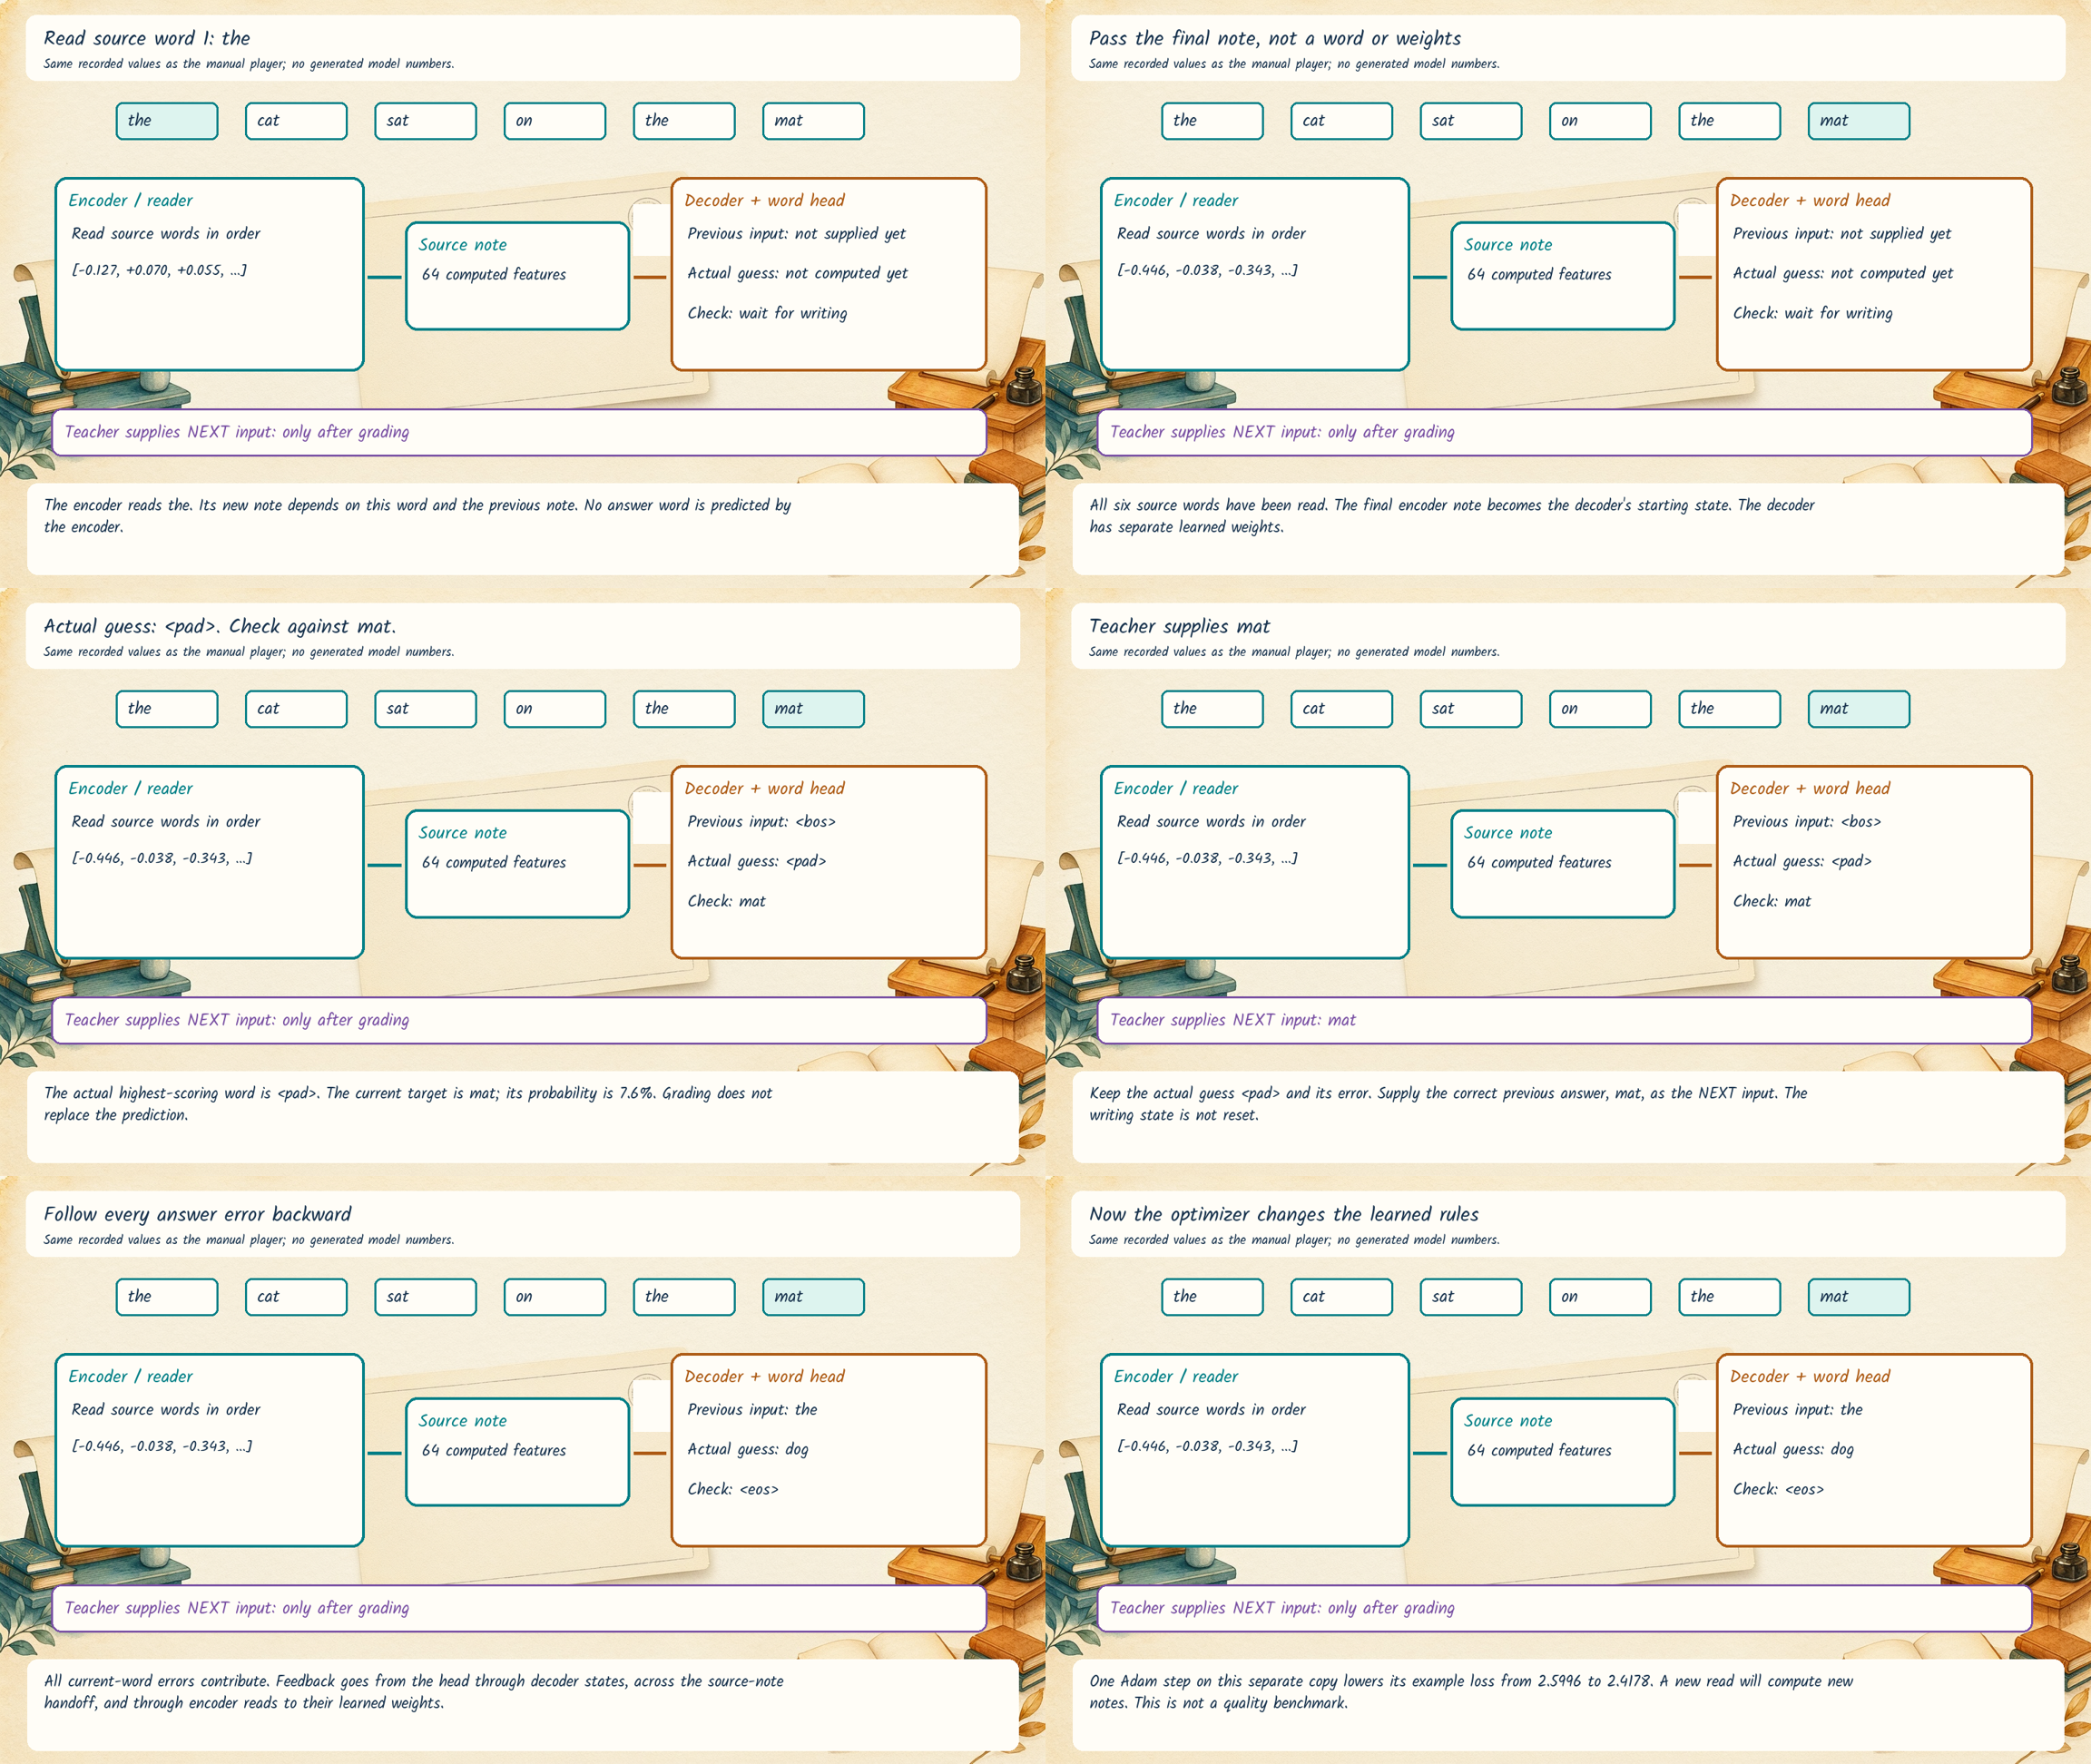

</details>

**What is generated?** Only the blank background was made with **MAI-Image-2.6**. Every word, route, state, probability, gradient and update was added from the actual small PyTorch model. Before-learning mistakes are retained, not replaced with the reference answer.


**Before the picture:** use the same source in both panels.
For this controlled illustration, suppose the first guess is `cat` rather than `mat`.
Only the previous-word input policy changes; this is not a measured model prediction.

![Practice uses the correct previous answer; generation feeds back its own guess. Neither policy repairs the earlier wrong scores.](images/03-evo-06-practice-vs-generation.png)

**Trace the second input with your finger:** practice supplies `mat`; generation supplies `cat`.
Both keep the already-computed writing state. Neither empties the source context.
The different input can change the next state and scores; it need not ruin every later word.


The compact setup below prints previous-answer inputs beside the current answers before training.
The [worked teacher-forcing example](03C1-encoder-decoder-worked-details.ipynb#teacher-forcing) also contrasts a hypothetical wrong
previous word; the [controlled next-input check](03C1-encoder-decoder-worked-details.ipynb#previous-input) measures its consequence
without changing weights.


**The catch: at generation time, there is no teacher to keep the inputs on track.**
Begin with `<bos>`, then feed each chosen word into the next step, even if it is wrong.
The model practised with correct history but must now use its own imperfect history.
That mismatch is **exposure bias**. Teacher forcing alone does not teach recovery from
every off-track history, so we test actual generation separately from practice loss.

## 3. Give both models the same controlled reading job

The cat-family vocabulary stays familiar, but generated source orders need not be grammatical.
This is an order/copy drill, not a corpus of English sentences.
Word IDs address trainable rows; they are not numerical word meanings.
Distinct `<pad>`, `<bos>` and `<eos>` IDs sit outside the ten word IDs.

Sources have two through eight words. We reserve forty unique sources at each length.
The remaining training budget is at most 1,200: length two has 100 possible orders, so only
60 can be used for training after reserving forty.
No source occurs in both splits. Both models receive the same batches in the same order.
This checks unseen orders at familiar lengths, not extrapolation to longer sources.

**Keep the result provenance clear:** “both models” refers to the original
`ReaderWriter` comparison in [worked details](03C1-encoder-decoder-worked-details.ipynb#attention), not two hidden models here.
The main demo loads the same predetermined source rows from
[`data/03c-cat-reversal-corpus.json`](data/03c-cat-reversal-corpus.json).
The [original seeded construction and equality check](03C1-encoder-decoder-worked-details.ipynb#corpus) and
[held-out evaluation](03C1-encoder-decoder-worked-details.ipynb#evaluation) remain runnable there.
The familiar sentence is one readable probe, not the whole training corpus or proof of generalization.


In [ ]:
import torch
from torch import nn
from language_data import CAT_WORDS
from encoder_decoder_example import (
    BOS, EOS, VOCABULARY, decode_ids, encode_words, load_cat_corpus,
    teacher_inputs, training_batches,
)

torch.set_num_threads(1)
V = len(VOCABULARY)
corpus = load_cat_corpus()
source = torch.tensor([encode_words(CAT_WORDS)])
target = torch.cat([source.flip(1), source.new_full((1, 1), EOS)], dim=1)
previous = teacher_inputs(target)
print("Source:", " ".join(CAT_WORDS))
print("Previous inputs:", decode_ids(previous[0]))
print("Current answers:", decode_ids(target[0]))
print("Frozen train / held-out counts:",
      {length: (len(rows), len(corpus["test"][length]))
       for length, rows in corpus["train"].items()})


**Your turn:** In the [worked data inspection](03C1-encoder-decoder-worked-details.ipynb#corpus), change only `example_length`
to inspect another length bucket before fitting.

## 4. Open the reader/writer before training it

**Predict:** when the writer produces its first word, which of these is its input:
the first source word, the last source word, or `<bos>` plus the reader's context?

The visible `EncoderDecoder` below is only the one-summary route: `encode` reads the source;
`decode` updates the writer from previous-answer IDs and a carried state. It has no mode flags,
answer construction, attention branch or validation machinery.

For the [full worked implementation](03C1-encoder-decoder-worked-details.ipynb#roles), use `ReaderWriter(False)` first.
In its `step`, read the **no-look-back branch**.
It embeds the previous answer input, updates the writer's own state, and sends that state to the head.
`read` produces all source notes, but this first writer gets only the final one as its initial context.

That worked-details class also contains an optional source-access branch.
Leave that branch aside until after the forward, teacher-input and backward checks below.
We will then have a concrete reason to ask what it adds.


In [ ]:
class EncoderDecoder(nn.Module):
    def __init__(self, vocabulary_size):
        super().__init__()
        self.embedding = nn.Embedding(vocabulary_size, 24)
        self.encoder = nn.GRU(24, 64, batch_first=True)
        self.decoder = nn.GRU(24, 64, batch_first=True)
        self.head = nn.Linear(64, vocabulary_size)

    def encode(self, source):
        _, state = self.encoder(self.embedding(source))
        return state

    def decode(self, previous, state):
        writing, state = self.decoder(self.embedding(previous), state)
        return self.head(writing), state

    def forward(self, source, previous):
        logits, _ = self.decode(previous, self.encode(source))
        return logits


### 4.1 Follow one source read and the first writing step

**Watch the boundary, not just the names.** Six source words select six 24-number word rows.
The reader produces a 64-number note after each word. Its final 64 numbers initialize the writer.
The writer receives the `<bos>` row, makes a new 64-number writing state, and the head turns it
into thirteen word scores. None of those feature vectors is itself a vocabulary score.

The [worked role probe](03C1-encoder-decoder-worked-details.ipynb#roles) samples only three coordinates to keep the values readable. Those coordinates have
no hand-assigned meanings such as 'cat' or 'last word'.
The parameter counts make the ownership visible: a shared word table, separate reader/writer
weights, and a separate head. Reusing a GRU *kind* is not reusing one GRU's weights.


The reader's final note became the writer's *initial* note.
The first writer input was `<bos>`, not a copied source word. Its first guess is an initialized
model result, not musical or language skill. Same-width notes can carry information between
separately learned modules. The writer's next note is its own updated state, not a reread source.

These initialized-state observations and parameter counts belong to the [worked role probe](03C1-encoder-decoder-worked-details.ipynb#roles); the main model below will be trained separately.


### 4.2 What if that first guess were wrong?

Keep the first computed writer state and all weights fixed. For an inspectable intervention,
pretend the first guess were `cat`, even if the actual initialized model guessed something else.
Compare the second step with correct previous input `mat` versus hypothetical own input `cat`.
This changes one input, not the source, the first scores or an optimizer setting.

**Run this one-variable intervention:** [previous-input check](03C1-encoder-decoder-worked-details.ipynb#previous-input).


The score difference belongs to the *next* computation.
The earlier answer is still graded against `mat`. Teacher forcing did not repair it.
**Your turn:** in [worked details](03C1-encoder-decoder-worked-details.ipynb#previous-input), change only `first_guess` to `mat`,
rerun its small setup and this check.
The gap becomes zero because the two next inputs now agree, not because the weights learned anything.


### 4.3 What tells these parts how to improve?

The training data gives a correct answer at each writing position.
Each prediction pays an error based on how little probability it assigned that answer.
A confident wrong choice pays more than a hesitant one. We combine these current-word errors;
we do not backpropagate through the spelling of an argmax guess.

Read the [worked error table](03C1-encoder-decoder-worked-details.ipynb#loss) as **previous input -> current answer -> its error**.
Correct inputs can make later practice well-posed while the writer still makes wrong current guesses.


### 4.4 How can an encoder learn if it never gets a word grade?

There is no teacher-provided target vector for the summary. The target is the answer.
The decoder is the link between that answer error and the encoder's note: it tells us
which small note changes would help its current prediction. The encoder then receives
feedback about the weights that made that note, rather than a command to memorize a vector.

Its summary helped create the writer states and scores. Follow the error backward through
the head and writer to the initial writer state, then across that same handoff to the reader.
Now every source read that helped form the summary can contribute feedback to the reader's weights.
That is how a reader learns what information a later writer will need.

**Predict:** if we keep identical summary numbers but cut only their backward connection,
do the predictions change? Do the encoder's weight gradients change?
`detach` does exactly this controlled test: same values forward, no feedback through that route.

The shared word table also feeds the writer's previous tokens. Its gradient therefore need not
vanish when the reader route is detached. In this reversal task, source words are also answer inputs.
Do not use 'cat's shared row still has a gradient' as proof the encoder weights were taught.

**Run the unchanged-predictions intervention:** [connected/detached gradient experiment](03C1-encoder-decoder-worked-details.ipynb#gradients).


**Read the result in order:** the copied models give identical word scores and loss.
The connected copy has encoder feedback; the detached copy has none.
Decoder and head weights still receive feedback. The shared table still receives the writer's
lookup feedback; the difference between its two gradients isolates the extra reader route.
Those signed contributions can cancel, so a larger total norm is not the definition of a better route.

The [worked code](03C1-encoder-decoder-worked-details.ipynb#gradients) measured gradients, not learned weights. Every parameter is still equal to the
initialized model. Cutting a backward connection does not magically change the stored forward values.


![The same initialized word predictions give encoder gradients only through a connected reader handoff; decoder/head gradients remain when it is detached.](images/03c-training-gradient-paths.png)

**Read the bars:** the encoder loses its teaching signal, not its forward summary values.
The shared word table still receives the writer's lookup feedback. This is a measured
single-example gradient comparison from [worked details](03C1-encoder-decoder-worked-details.ipynb#gradients), not a trained-model quality score.

### 4.5 When do the weights actually change?

Backward fills each parameter's gradient: advice for a local weight change.
It does not itself rewrite the weights or edit a saved reader state.
Let Adam take one step on the connected copy, then read and write the same source again.
The new pass computes new states with updated reader, writer, word-table and head weights.
This single-example payoff verifies the connection, not generalization.

**Run the copied-model update and inspect its measured loss:** [optimizer-step experiment](03C1-encoder-decoder-worked-details.ipynb#optimizer).


### Is the encoder learning a better note, or is only the decoder getting better?

The previous update changed both, so it could not separate those explanations.
Now freeze the word table, decoder and prediction head. Change **only the encoder weights**
on the mat/rug pair from section 1. Grade only the first required word for this small check.
Both decoder inputs are `<bos>`: teacher forcing has supplied no answer word yet.

First give both examples the same note deliberately; their first-word scores must match.
Then use their actual notes and take one encoder-only step. Check that the notes change
and the combined answer error falls while the decoder stays byte-for-byte unchanged.

**Run the complete freezing, equality and loss checks:** [encoder-only proof](03C1-encoder-decoder-worked-details.ipynb#encoder-only).


**Follow the [worked code](03C1-encoder-decoder-worked-details.ipynb#encoder-only):** the first part freezes everything except `reader`.
`first_word_outputs` recomputes the notes and lets the unchanged writer use them.
The identical-note check proves why the source distinction matters; the final checks
separate a changed note from changed decoder weights.

The improvement has a concrete meaning: these newly computed notes help this same decoder
assign more probability to the correct answers overall. No target encoding was supplied.
This checks one local learning step on two examples, not reliable reversal or generalization.
Full training changes both partners across many examples and checks held-out answers.


### 4.6 That teaches a summary. Can the writer reopen a source detail?

The first writer still receives only one fixed-size summary.
Better training or LSTM retention can improve that summary; neither gives the writer direct
addresses for earlier source states. A short cat sentence may fit perfectly, so we must measure
the restriction rather than declare the one-card model doomed.

Keep the reader's note after each source word instead. At every writing step, project the current
writer state into a **query**, compare it with those notes, and blend them by the resulting weights.
Only now name the additional mechanism: **source attention**.
It changes where the writer may look, not the rule about which previous answer input it receives.

**Implementation route:** [source-attention model and matched training benchmark](03C1-encoder-decoder-worked-details.ipynb#attention). The visible main class stays a simple fixed-summary encoder-decoder.


**Read this picture only after the basic handoff makes sense.**
Each source word has a saved contextual reader state. The writer's current state forms a
query; its match scores weight those saved states into a fresh context.
This is source access, not a claim that a literal spoken question exists inside a vector.

![The writer can query all six contextual reader states, then blend them for the current writing step.](images/03-evo-05-writer-looks-back.png)

The two occurrences of `the` have different addresses and different contextual notes.
The blend uses reader states, not raw IDs or one unchanging CBOW average.
Its weights sum to one over source positions; they are **not probabilities of the next answer word**.
The previous answer input and fresh context then update the writer, and the head scores the answer.


**Now practice many examples, without changing the comparison.**
The data builds each required reversal. `ReaderWriter.forward` in worked details receives those answer IDs explicitly for
teacher forcing; it does not infer the answer inside the model. The main `EncoderDecoder.forward`
instead receives already-shifted previous-answer inputs, prepared visibly in the loop below.
The loop grades raw word scores against the current targets, clears previous gradients,
runs backward, clips an oversized gradient, then lets Adam update weights.
Correct answer inputs do not remove any current-word errors from this loss.

In the worked-details benchmark, both models get 1,000 updates, batches of 64, the same
schedules, and the same 24/64 feature widths. The single main demo uses that same data and budget.
Each independent source begins fresh reader/writer state; learned weights persist across examples.
The look-back model also has more parameters. A better score cannot isolate access from capacity or training luck.

**Your turn:** in [worked details](03C1-encoder-decoder-worked-details.ipynb#attention), inspect the printed comparison models. The optional query and wider writer input change source
access; they do not turn recurrence into a Transformer or teacher forcing into an architecture.

The main loop spells out the shift: prepend `<bos>` and drop the final target from the inputs.
`training_batches` supplies the same seeded 64-row schedule; the loop, backward call and optimizer
remain visible. `<eos>` is still graded as a current answer.


In [ ]:
torch.manual_seed(31)
model = EncoderDecoder(V)
optimizer = torch.optim.Adam(model.parameters(), lr=0.004)
for update, (source, _, target) in enumerate(training_batches(corpus), 1):
    previous = torch.cat([target.new_full((len(target), 1), BOS), target[:, :-1]], dim=1)
    logits = model(source, previous)
    loss = nn.functional.cross_entropy(logits.flatten(0, 1), target.flatten())
    optimizer.zero_grad()
    loss.backward()
    nn.utils.clip_grad_norm_(model.parameters(), 1.0)
    optimizer.step()
    if update in (1, 1000):
        print(f"Update {update}: current-word loss {loss.item():.4f}")


## 5. Can it write without the teacher's history?

The training loss asked about every current word under correct previous-answer inputs.
Now also run generation: no answer tensor, only `<bos>` and the model's own earlier guesses.
Weights are fixed during checking; this is not another optimizer pass.

Check two units separately:
- **Whole-answer accuracy:** every word and `<eos>` must match. One wrong word fails the row.
- **Token accuracy:** count the individual correct words, so partly wrong answers still tell us something.

Equal whole-answer scores do not imply equal histories. Once the first mistake fails a row,
that unit cannot reveal how many additional mistakes the wrong history caused.
The token scores in [worked details](03C1-encoder-decoder-worked-details.ipynb#evaluation) can.
The known source length supplies a bounded generation budget including end, not the answer words.

The [full held-out checks](03C1-encoder-decoder-worked-details.ipynb#evaluation) compare those units for the original two models.
Here, the bounded function below takes only a source, reads it once, carries decoder state and
stops at `<eos>` or its source-length-plus-one budget. It receives no answer tensor.


The look-back model also has more weights, so this isn't attention alone.

**Read the two scores separately:** test each length group twice, without changing weights.
Whole-answer accuracy asks whether every token was right. Token accuracy shows what happened
inside answers that were partly wrong. Two runs can tie on whole answers yet make different
later mistakes. The plot shows only measured generation scores, without the answer key.

![Actual complete free-running accuracy for the cat-family word-order task, by source length.](images/03c-cat-accuracy-by-length.png)
*Saved measured plot from [the original worked-details experiment](03C1-encoder-decoder-worked-details.ipynb#evaluation), not
the compact main demo; the two comparison models also differ in capacity.*

**Your turn:** Change only the first word in `source_to_reverse` to another `CAT_FAMILY_WORDS`
word. The default source is `the cat sat on the mat`; the required answer is
`mat the on sat cat the <eos>`. Generate without seeing the answer.
This probe is not automatically independent of training data; its split membership is printed
in [the worked evaluation](03C1-encoder-decoder-worked-details.ipynb#evaluation). A single displayed reversal is not a generalization score.

In [ ]:
def generate(model, words=CAT_WORDS):
    source = torch.tensor([encode_words(words)])
    chosen = []
    model.eval()
    with torch.no_grad():
        state = model.encode(source)
        previous = source.new_full((1, 1), BOS)
        for _ in range(len(words) + 1):
            logits, state = model.decode(previous, state)
            previous = logits[:, -1].argmax(-1, keepdim=True)
            chosen.append(previous.item())
            if chosen[-1] == EOS:
                break
    return decode_ids(chosen)


source_to_reverse = CAT_WORDS
print("Source:", " ".join(source_to_reverse))
print("Generated:", " ".join(generate(model, source_to_reverse)))
print("Required by the separate task:", " ".join([*reversed(source_to_reverse), "<eos>"]))


**We know whether the answer was right. Where did the writer look?**

## 6. Inspect the route without declaring victory from a picture

**Predict:** For `the cat sat on the mat`, should reversal read source positions from last to first?
Two `the` tokens make content alone an ambiguous address: `the @ 0` differs from `the @ 4`.
The required source addresses are `5, 4, 3, 2, 1, 0`; `<eos>` has no single required source address. Recurrent reader states contain ordered
context. The learned map need not be a perfect anti-diagonal, a line running from upper right to
lower left. This heatmap comes from real free-running query weights, not hand-drawn target routing.

**Run the real query/weight calculation:** [worked routing diagnostic](03C1-encoder-decoder-worked-details.ipynb#routing).


![Actual free-running cat-probe attention weights with generated words and distinct source addresses.](images/03c-cat-attention-map.png)
*Saved measured diagnostic from the worked-details attention model, not the main demo or ideal target routing.
A correct answer need not have perfect anti-diagonal attention.*

**Your turn:** In [the worked routing inspection](03C1-encoder-decoder-worked-details.ipynb#routing), change only `writing_step`, from zero through the actual final decoder step.
Does its most-read word and source address match the required reversal address?
The last required answer is `<eos>`, which has no single source address.

## 7. What can you now explain and prove?

| Question | Evidence |
|---|---|
| How do encoder and decoder differ? | Same update family, separate learned jobs and weight sets |
| What crosses their handoff? | Final reader state initializes writer state; word scores come later |
| What does teacher forcing change? | Correct previous input; the controlled next-input check changes later scores |
| How does the reader learn? | Writer loss reaches reader weights only while the backward handoff is connected |
| Does backward update weights? | No; the copied-model optimizer step changes them and lowers this example's loss |
| What does attention change? | A new weighted read of all saved source states at each writing step |
| Does that guarantee the answer? | No; grade actual held-out generation and inspect maps beside it |

| Teaching mechanism | Larger-system counterpart | What changes | What stays |
|---|---|---|---|
| Final reader state starts writer | Recurrent fixed-summary model | State width and data | Learned context crosses a handoff |
| Writer queries source notes | Recurrent source attention | Score rule and source masks | Query-dependent source access |
| Shifted correct answer inputs | Teacher-forced autoregressive training | Batch/target lengths | Current answer is not its own input |
| Separate reader/writer jobs | Transformer encoder-decoder | Attention replaces recurrent updates | Source/answer roles and supervised alignment |

**Measured-result provenance:** the original [worked-details experiment](03C1-encoder-decoder-worked-details.ipynb#evaluation)
scores 76.43% versus 97.50% mean complete free-running accuracy; at length eight it scores
17.5% versus 90%. Its models have 35,717 versus 52,933 parameters.
Those are the preserved original comparison results, **not measurements of the compact main demo**.
The main demo's printed loss and answer come from its own single 24/64-width `EncoderDecoder` run.


### What we built, explained and left for later

- **Built and measured across the main and worked-details routes:** reader/writer state and parameter ownership; shifted answer inputs;
  current-word loss; connected versus detached reader gradients; one copied-model optimizer step;
  independent source splits; summary/source-attention training; generation and routing diagnostics.
- **Explained:** why correct practice history differs from own-guess history; how shared word rows
  receive both reader and writer feedback; why source access differs from retention; source and loss
  masks; why complete-source encoders may use both directions while generated history has no future answers.
- **Deferred:** gate internals already taught in memory, scheduled sampling, beam search, mixed-length
  masking, longer-length extrapolation, multi-seed rankings and production translation.

Do not confuse a state handoff with shared weights, correct previous inputs with corrected current
guesses, a detached forward value with a teachable reader, or a bright attention square with proof.

All separate diagnostics, plotting, assertions and the two-model benchmark live in the
[worked-details notebook](03C1-encoder-decoder-worked-details.ipynb); the explanations and saved evidence stay here.


## 8. Keep the reading/writing job inside the model, not the trainer

Our common trainer needs word scores and aligned answers.
`ReaderWriter` also returns attention maps, so a small registered wrapper leaves those maps out.
It now **passes the supplied answer IDs through** for teacher forcing.
The dataset creates the reversal labels; the model does not manufacture an answer from the source.

Targets already contain each required word followed by `<eos>`.
They do not contain an extra `<bos>` label to remove, so the inherited alignment method stays unchanged.
The reader/writer itself shifts those correct targets into previous-answer inputs.

```text
data: source + correct answer IDs
shared loop -> wrapper -> reader/writer scores
current-word loss -> backward -> word table + reader + writer + head
optimizer -> changed weights for the next forward pass
```

Test this on a deep copy. The original comparison models keep every parameter unchanged.
The example data and generation budget are still a reversal drill, not a production translation system.

**Run the registered wrapper and inherited trainer check:** [worked trainer adapter](03C1-encoder-decoder-worked-details.ipynb#adapter).
This preserves the original `ReaderWriter` interface; the compact main class deliberately takes
`previous` separately instead of owning answer shifting or trainer modes.


**Follow the call:** the common loop passes sources and answers to the wrapper.
The wrapper passes the answers to the same reader/writer whose input rule we now understand.
Only attention maps are left out of the loss. Feedback still reaches all registered learned parts.
The final equality check in [worked details](03C1-encoder-decoder-worked-details.ipynb#adapter) covers every original parameter,
not just the word table.

You can now trace both directions: source words into reader notes, context into the writer,
previous-answer inputs into word scores, and current-answer errors back into both components.
The optimizer changes reusable weights; reading a new independent source computes fresh states.

We added source access without removing sequential recurrent reading and writing.
[Stage 04](../../04-transformers/README.md) keeps the roles and alignment, but uses attention,
positions and masks inside the complete Transformer blocks.
